In [1]:
import numpy as np
import healpy as hp

import matplotlib
from matplotlib import pyplot as plt

from scipy import stats
import matplotlib.gridspec as gridspec
import astropy.cosmology.units as cu
import astropy.units as u
import site
site.addsitedir('/oak/stanford/orgs/kipac/users/mahlet/quaia_bias/scripts') 
import quaia
import seaborn as sns
from matplotlib.colors import LogNorm
import matplotlib.patches as mpatches
import pyccl as ccl
from matplotlib.lines import Line2D
from matplotlib import cm
from scipy.optimize import minimize
from astropy.cosmology import Planck18
from dynesty import NestedSampler
from dynesty import plotting as dyplot
from dynesty import utils as dyfunc
from astropy.coordinates import SkyCoord
from scipy import linalg
from scipy.special import gamma
from dynesty.results import Results
import io
from PIL import Image
from scipy.special import j0
import mcfit
from astropy import constants
import time
import copy
from scipy import special
from healpy.newvisufunc import projview
import matplotlib.colors as mcolors

/home/groups/tabel/mahlet/pyccl-env/lib/python3.12/site-packages/mcfit/kernels.py:10: SyntaxWarning: invalid escape sequence '\l'
  """Real deriv is wrt :math:`t`, complex deriv is wrt :math:`\ln t`"""


In [2]:
matplotlib.rcParams['ytick.labelsize'] = 18
matplotlib.rcParams['xtick.labelsize'] = 18
matplotlib.rcParams['axes.labelsize'] = 22
matplotlib.rcParams['legend.fontsize'] = 18
matplotlib.rcParams['axes.titlesize'] = 20

# Model using erfc HOD
## Define parameters

In [3]:
G_hi = 20.5 #20.5

In [4]:
nthreads = 18

In [5]:
z_bins = np.array([0.0, 1.0, 2.0, 3.0, 4.6])
z_array = range(len(z_bins)-1)
mask = 0.5

In [6]:
# cosmo_planck18 = ccl.Cosmology(Omega_c=0.265, Omega_b=Planck18.Ob0, h=Planck18.h, Neff = Planck18.Neff, T_CMB = Planck18.Tcmb0.value, m_nu = Planck18.m_nu, sigma8=0.8, n_s=0.95)
cosmo_planck18 = ccl.Cosmology(
    Omega_c=Planck18.Odm0,
    Omega_b=Planck18.Ob0,
    h=Planck18.h,
    Neff=Planck18.Neff,
    T_CMB=Planck18.Tcmb0.value,
    m_nu=Planck18.m_nu,
    sigma8=0.8102,   # or pull from wherever your actual source specifies Planck18's sigma8
    n_s=0.9665        # same
)

In [7]:
Delta = 200
delta_c = 1.686

In [8]:
hmf = ccl.halos.MassFuncTinker10()

In [9]:
NSIDE = 64

In [10]:
M_max = 16.8 #15

## Define functions

In [11]:
def a_median(tab_datahi_mask_zbin0, key_zbin0 = ''):
    return 1/(1+np.median(tab_datahi_mask_zbin0['redshift_quaia'+key_zbin0]))

In [12]:
def b_qso(xi_qq, xi_mm, f):
    
    return np.sqrt(xi_qq/xi_mm-4*f**2/45)-f/3

In [13]:
def nu(M, delta_c = delta_c, a = 1, cosmo = cosmo_planck18):
    
    sigma = cosmo.sigmaM(M, a = a)
   
    return delta_c/sigma

In [14]:
integral = np.trapz #integrate.simpson #np.trapz #integrate.simpson

In [15]:
def n_g_theory(bins, n_total, a = 1, cosmo = cosmo_planck18, hmf = hmf, recenter = True):

    if recenter == True:
        bins = quaia.recenter(bins)
    nm = hmf(cosmo, bins, a)/cosmo['h']**3
    n_g = nm/(bins*np.log(10))*n_total
    n_g[np.isnan(n_g)]=0
    
    return n_g, nm

def bias(bins, n_m, a = 1, cosmo = cosmo_planck18, mod = False, recenter = True, integral = integral):

    n_g, nm = n_g_theory(bins, n_m, a = a, cosmo = cosmo, recenter = recenter)
    if recenter == True:
        print('recentering')
        bins = quaia.recenter(bins)
    # n_g = np.trapz(n_g, bins)
    n_g = integral(n_g, bins)
    dn_dm = nm/(bins*np.log(10))

    b1_E_tinker = b1_E_func(nu(bins, a = a, cosmo = cosmo), mod = mod)

    n_m[~np.isfinite(n_m)]=0 
    integrand = dn_dm*n_m
    integrand[np.isnan(integrand)]=0
    
    return bias_function(n_g, integrand, b1_E_tinker, bins, recenter = recenter, integral = integral), n_g

In [16]:
def b1_E_func(nu, Delta = Delta, delta_c = delta_c, mod = False):

    delta_c = 1.686
    
    if mod == False:
        y = np.log10(Delta)
        A =  1.0+0.24*y*np.exp(-(4/y)**4)
        a = 0.44*y-0.88
        B = 0.183
        b =  1.5
        C = 0.019+0.107*y+0.19*np.exp(-(4/y)**4)
        c = 2.4
        
    else:
        A =  1.0
        a = 0.0906
        B = -4.5002
        b =  2.1419
        C = 4.9148
        c = 2.1419
        
    return 1-A*nu**a/(nu**a+delta_c**a)+B*nu**b+C*nu**c # Jose et al
    
def bias_function(n_g, integrand, b, bins, recenter = True, integral = integral):
    
    if recenter == True:
        print('recentering')
        bins = quaia.recenter(bins)
        
    # return 1/n_g*np.trapz(integrand*b, bins)
    return 1/n_g*integral(integrand*b, bins)

In [17]:
def cf_2h(bins, n_m, a, cosmo, cf_matter, recenter = True, integral = integral):
    
    b_q, n_g = bias(bins, n_m, a, cosmo, recenter = recenter, integral = integral)
    return b_q**2*cf_matter, b_q

In [18]:
def M(bins, n_m, a = 1, cosmo = cosmo_planck18, mod = False, recenter = True, hmf = hmf, integral = integral):

    n_g, nm = n_g_theory(bins, n_m, a = a, cosmo = cosmo, recenter = recenter, hmf = hmf)
    if recenter == True:
        # n_g = np.trapz(n_g, quaia.recenter(bins))
        n_g = integral(n_g, quaia.recenter(bins))
        dm = np.diff(bins) 
        dn_dm = nm/(quaia.recenter(bins)*np.log(10))
    else:
        # n_g = np.trapz(n_g, bins)
        n_g = integral(n_g, bins)
        dn_dm = nm/(bins*np.log(10))

    n_m[~np.isfinite(n_m)]=0 
    integrand = dn_dm*n_m
    integrand[np.isnan(integrand)]=0
    
    if recenter == True:
        return bias_function(n_g, integrand, quaia.recenter(bins), bins, recenter = recenter, integral = integral), n_g
    else:
        return bias_function(n_g, integrand, bins, bins, recenter = recenter, integral = integral), n_g

In [19]:
def HOD(bins, M_min, fduty):

    n_m=np.zeros(np.shape(quaia.recenter(bins)))
    n_m[quaia.recenter(bins)>=M_min]=fduty

    return n_m

In [20]:
def n_DM(cosmo, a, M_min, hmf = hmf, M_max = M_max, N = 79, integral = integral): #16.8
    
    bins = np.logspace(M_min, M_max, N)
    nm = hmf(cosmo, bins, a)/cosmo['h']**3 #/u.Mpc**3 # convert to h/Mpc**3
    dn_dm = nm/(bins*np.log(10))
    
    # return np.trapz(dn_dm, bins)
    return integral(dn_dm, bins)

# Visualize the luminosity threshold cuts and redshift bins

In [21]:
L_bins = np.array([-32.0, -27.0, -26.0, -25.0, -20.0])[:0:-1]
L_bins

array([-20., -25., -26., -27.])

In [22]:
cmap_red = plt.get_cmap('Reds')(np.linspace(0.333, 0.999, len(L_bins)))
cmap_orange = plt.get_cmap('Oranges')(np.linspace(0.333, 0.999, len(L_bins)))
cmap_green = plt.get_cmap('Greens')(np.linspace(0.333, 0.999, len(L_bins)))
cmap_blue = plt.get_cmap('Blues')(np.linspace(0.333, 0.999, len(z_array)))
colors = ['Red', 'Orange', 'Green', 'Blue']

In [23]:
b = 30

<>:27: SyntaxWarning: invalid escape sequence '\l'
<>:35: SyntaxWarning: invalid escape sequence '\m'
<>:41: SyntaxWarning: invalid escape sequence '\m'
<>:48: SyntaxWarning: invalid escape sequence '\l'
<>:27: SyntaxWarning: invalid escape sequence '\l'
<>:35: SyntaxWarning: invalid escape sequence '\m'
<>:41: SyntaxWarning: invalid escape sequence '\m'
<>:48: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_13410/50625153.py:27: SyntaxWarning: invalid escape sequence '\l'
  ax3.hist(tab_datahi_mask_zbin0['M_i'], color = 'white', edgecolor = colors[i], orientation = 'horizontal', bins = np.linspace(-32, -20, 30), alpha = 0.5, label = '$M_i\leq{}$'.format(L_bins[i]))
/tmp/ipykernel_13410/50625153.py:35: SyntaxWarning: invalid escape sequence '\m'
  ax2.set_ylabel('$N_\mathrm{QSO}$')
/tmp/ipykernel_13410/50625153.py:41: SyntaxWarning: invalid escape sequence '\m'
  ax3.set_xlabel('$N_\mathrm{QSO}$')
/tmp/ipykernel_13410/50625153.py:48: SyntaxWarning: invalid escape sequence '\

Pixels masked by MC but not already by selfunc: 2468
G20.5_zmin0.0zmax1.0_Lmax-20.0: 0.33              218365 vs 324336
Pixels masked by MC but not already by selfunc: 4785
G20.5_zmin1.0zmax2.0_Lmax-20.0: 0.30              453228 vs 648196
Pixels masked by MC but not already by selfunc: 2764
G20.5_zmin2.0zmax3.0_Lmax-20.0: 0.28              207602 vs 286508
Pixels masked by MC but not already by selfunc: 307
G20.5_zmin3.0zmax4.6_Lmax-20.0: 0.23              28043 vs 36458
Pixels masked by MC but not already by selfunc: 490
G20.5_zmin0.0zmax1.0_Lmax-25.0: 0.46              29985 vs 55261
Pixels masked by MC but not already by selfunc: 3840
G20.5_zmin1.0zmax2.0_Lmax-25.0: 0.33              336125 vs 502242
Pixels masked by MC but not already by selfunc: 2764
G20.5_zmin2.0zmax3.0_Lmax-25.0: 0.28              207602 vs 286508
Pixels masked by MC but not already by selfunc: 307
G20.5_zmin3.0zmax4.6_Lmax-25.0: 0.23              28043 vs 36458
Pixels masked by MC but not already by selfunc: 1

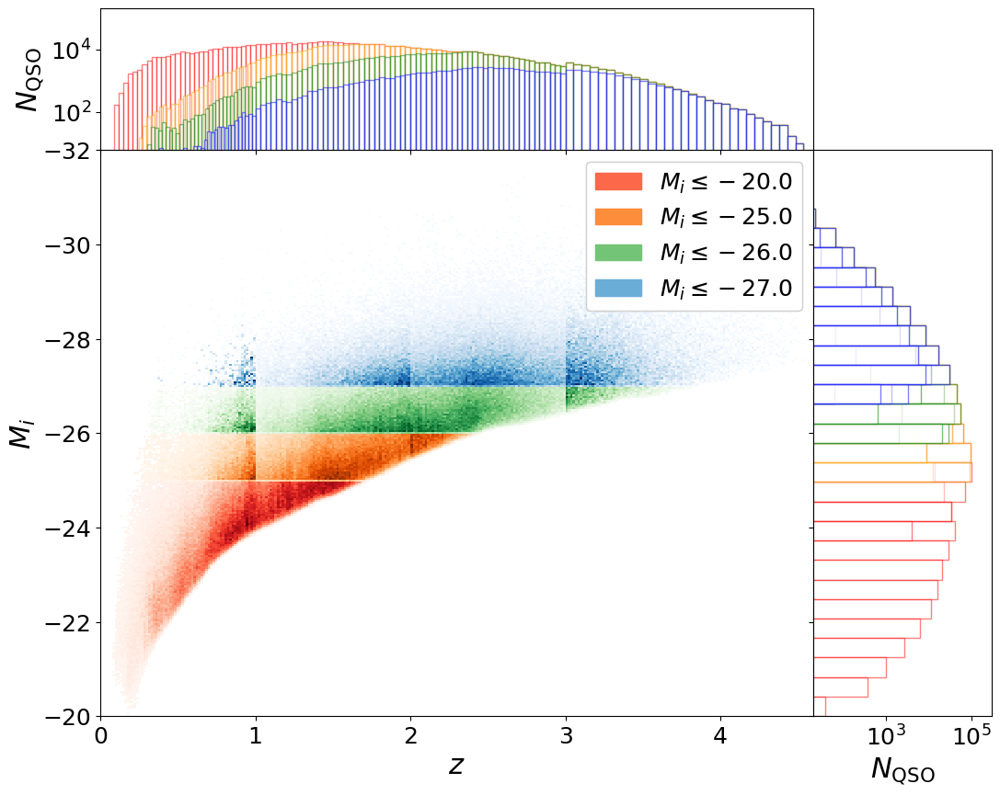

In [24]:
# plot!
fig = plt.figure(figsize = (12.5, 10))
gs = gridspec.GridSpec(2, 2, hspace = 0, height_ratios=[1,4], width_ratios=[4,1], wspace = 0)
fac_rand = 25

ax1 = fig.add_subplot(gs[2])
ax2 = fig.add_subplot(gs[0])
ax3 = fig.add_subplot(gs[3])

N = {L: [] for L in L_bins}

for i in range(len(L_bins)):
        
    for j in z_array:
        
        tab_datahi_mask_zbin0, tab_randhi_mask_zbin0, key_zbin0, _, _, _, _, _, _ = quaia.make_bins(G_hi, [j, i], True, ['z', 'L'], 
                                                                                             bins = [z_bins, L_bins], tab_gcat_type = 'data', 
                                                                                              method = ['minmax', 'max'], fac_rand = fac_rand, 
                                                                                              n_bins = [None, None], b = b, mask_type = 'b')
        quaia.absolute(tab_datahi_mask_zbin0, G_hi)
        h1, xedges, yedges, image = ax1.hist2d(tab_datahi_mask_zbin0['redshift_quaia'], tab_datahi_mask_zbin0['M_i'],
                                               cmap = plt.get_cmap('{}s'.format(colors[i])), bins = [np.linspace(0, 4.6, 300), np.linspace(-32, -20, 300)],
                                               cmin = 1)
        xlim = ax1.get_xlim()

        ax2.hist(tab_datahi_mask_zbin0['redshift_quaia'], color = 'white', edgecolor = colors[i], bins = 30, alpha = 0.5)
        ax3.hist(tab_datahi_mask_zbin0['M_i'], color = 'white', edgecolor = colors[i], orientation = 'horizontal', bins = np.linspace(-32, -20, 30), alpha = 0.5, label = '$M_i\leq{}$'.format(L_bins[i]))
        
        N[L_bins[i]].append(len(tab_datahi_mask_zbin0))
    
ax1.set_ylabel('$M_i$')
ax1.set_xlabel('$z$')
ax1.set_ylim(-20, -32)

ax2.set_ylabel('$N_\mathrm{QSO}$')
ax2.set_yscale('log')
ax2.set_xlim(xlim)
ax2.set_ylim(6,2e5)
ax2.set_xticklabels([])

ax3.set_xlabel('$N_\mathrm{QSO}$')
ax3.set_xscale('log')
ax3.set_yticklabels([])
ax3.set_ylim(-20, -32)
ax3.set_xlim(2e1,3e5)

custom_lines = [mpatches.Patch(color=plt.get_cmap('{}s'.format(colors[i]))(np.array(0.5))) for i in range(len(L_bins))]
second_legend = ax1.legend(custom_lines, ['$M_i\leq{}$'.format(L) for L in L_bins])
fig.add_artist(second_legend)

plt.show()

In [25]:
tab_datahi_mask, tab_randhi_mask, key_zbin0, _, _, _, _, _, _ = quaia.make_bins(G_hi, 0, True, 'z', 
                                                                                             bins = [0,4.6], tab_gcat_type = 'data', fac_rand = fac_rand, 
                                                                                              n_bins = None, b = b, mask_type = 'b')

Leaving tab_gcat_catalog unbinned
Pixels masked by MC but not already by selfunc: 10324
G20.5: 0.30              907242 vs 1295502


In [26]:
tab_datahi, tab_randhi, key_zbin0, _, _, _, selfunc_datahi, _, _ = quaia.make_bins(G_hi, 0, True, 'z', 
                                                                                             bins = [0,4.6], tab_gcat_type = 'data', fac_rand = fac_rand, 
                                                                                              n_bins = None, mask_type = 'b')

Leaving tab_gcat_catalog unbinned
Pixels masked by MC but not already by selfunc: 13364
G20.5: 0.01              1282138 vs 1295502


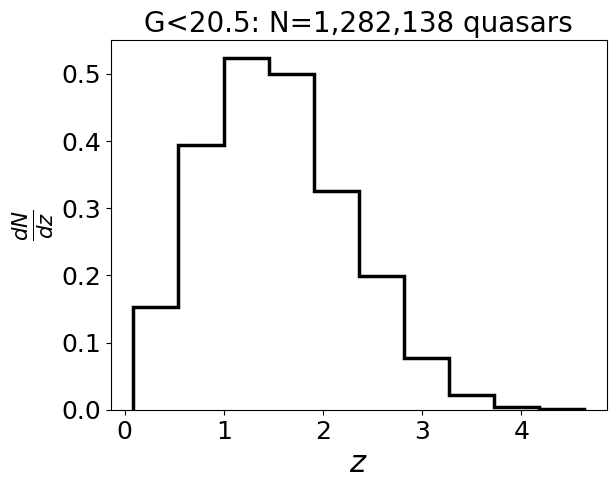

In [27]:
N_gcatlo = len(tab_datahi)
plt.hist(tab_datahi['redshift_quaia'], histtype = 'step', linewidth = 2.5, color = 'black', density = True)
plt.ylabel(r'$\frac{dN}{dz}$')
plt.xlabel('$z$')
plt.title('G<{}: N={:,} quasars'.format(G_hi, N_gcatlo))
plt.show()

In [28]:
NSIDE = 64
NPIX = hp.nside2npix(NSIDE)
name_catalog = '$Gaia$-$unWISE$ Quasar Catalog'
cmap_map = 'plasma'

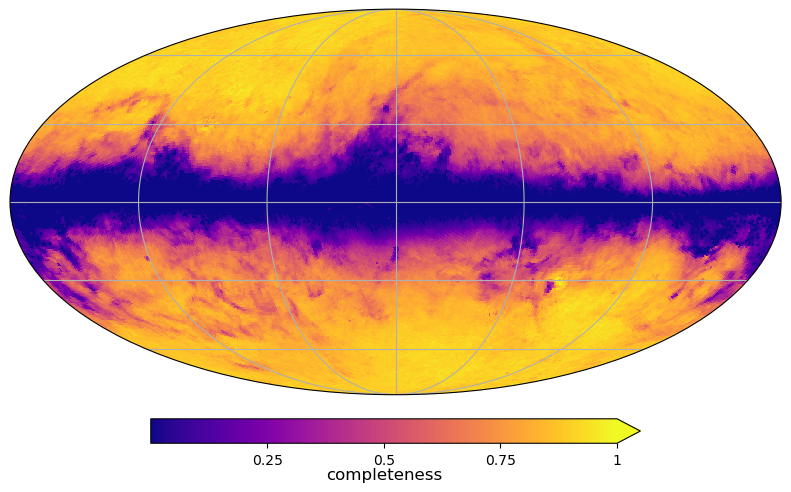

In [29]:
title_gcatlo = rf"{name_catalog}, $G<{G_hi}$ (N={N_gcatlo:,})"
projview(selfunc_datahi, #title='selection function',
            unit=r"completeness", cmap=cmap_map, coord=['C','G'],
            min=0, max = 1, 
            graticule=True, cbar_ticks=[0.25, 0.5, 0.75, 1.0], graticule_labels=False) #True

In [30]:
quaia.absolute(tab_datahi_mask, G_hi)

array([ 2351.99612994, 13397.25003193, 11312.87200823, ...,
       20331.42198124, 12512.68945875,  4349.94408756])

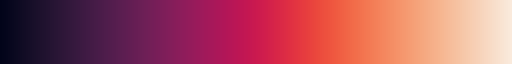

In [31]:
cmap = sns.color_palette("rocket", as_cmap=True)
cmap

In [32]:
L_array = np.array([-32, -27, -26, -25, -20])[::-1]

<>:29: SyntaxWarning: invalid escape sequence '\m'
<>:37: SyntaxWarning: invalid escape sequence '\m'
<>:29: SyntaxWarning: invalid escape sequence '\m'
<>:37: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_13410/2952415765.py:29: SyntaxWarning: invalid escape sequence '\m'
  ax2_hi.set_ylabel('N$_\mathrm{QSO}$')
/tmp/ipykernel_13410/2952415765.py:37: SyntaxWarning: invalid escape sequence '\m'
  ax3_hi.set_xlabel('N$_\mathrm{QSO}$')


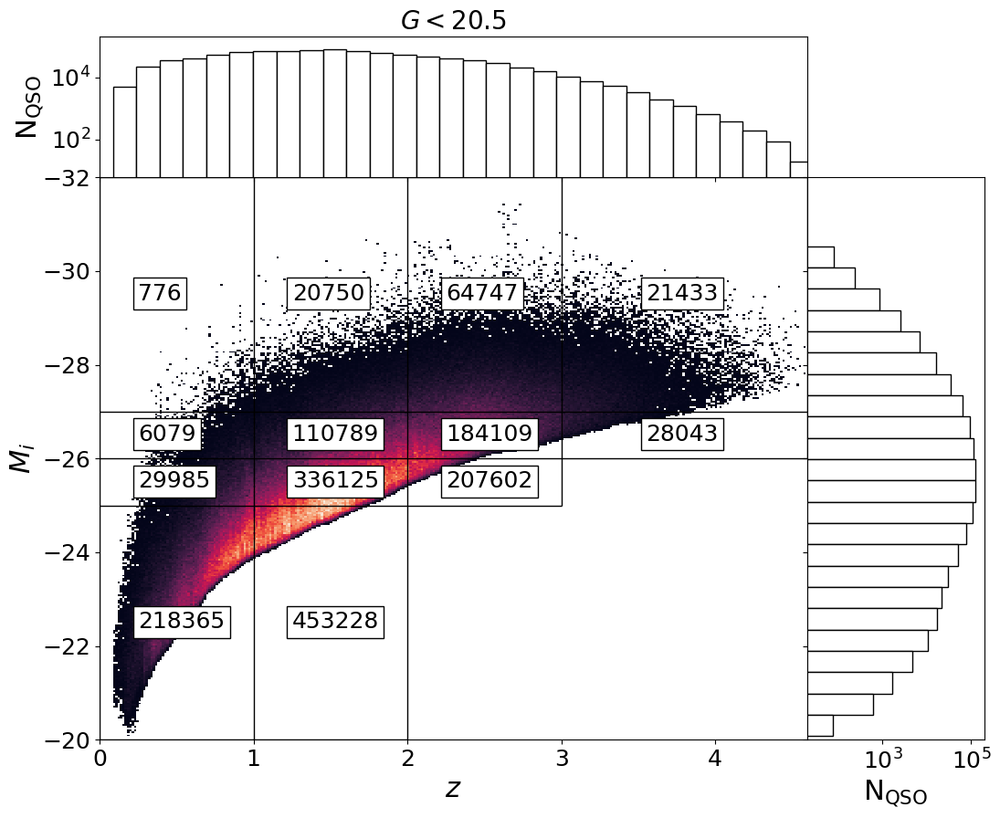

In [33]:
# plot!
fig = plt.figure(figsize = (12.5, 10))
gs = gridspec.GridSpec(2, 2, hspace = 0, height_ratios=[1,4], width_ratios=[4,1], wspace = 0)

ax1_hi = fig.add_subplot(gs[2])

h1, xedges, yedges, image = ax1_hi.hist2d(tab_datahi_mask['redshift_quaia'], tab_datahi_mask['M_i'], cmap = cmap, bins = 300, 
                                       cmin = 1)

for L_bin, xmax in zip(L_array, [z_bins[2], z_bins[3], z_bins[4], z_bins[4], z_bins[4]]):
    ax1_hi.hlines(L_bin, color = 'black', xmin = z_bins[0], xmax = xmax, linewidth = 1)
for z_bin, ymax in zip(z_bins, [L_bins[0], L_bins[0], L_bins[0], L_bins[1], L_bins[2]]):
    ax1_hi.vlines(z_bin, color = 'black', ymin = -32, ymax = ymax, linewidth = 1)
    
for i in z_array:
    for j in range(len(L_bins)):
        if ((j<3) and (N[L_bins[j]][i]>N[L_bins[j+1]][i])) or (j ==3):
            ax1_hi.text(quaia.recenter(z_bins)[i]-0.25, quaia.recenter(L_array)[j]+0.125, N[L_bins[j]][i], fontsize = 18, color = 'black', bbox=dict(facecolor='white'))
            
ax1_hi.set_ylabel('$M_i$')
xlim = ax1.get_xlim()
ax1_hi.set_xlabel('$z$')
ax1_hi.set_ylim(-20, -32)
ax1_hi.set_xlim(xlim[0], z_bins[-1])

ax2_hi = fig.add_subplot(gs[0])
ax2_hi.hist(tab_datahi_mask['redshift_quaia'], color = 'white', edgecolor = 'black', bins = 30)
ax2_hi.set_title('$G<{}$'.format(G_hi))
ax2_hi.set_ylabel('N$_\mathrm{QSO}$')
ax2_hi.set_yscale('log')
ax2_hi.set_xlim(xlim[0], z_bins[-1])
ax2_hi.set_ylim(6,2e5)
ax2_hi.set_xticklabels([])

ax3_hi = fig.add_subplot(gs[3])
ax3_hi.hist(tab_datahi_mask['M_i'], color = 'white', edgecolor = 'black', orientation = 'horizontal', bins = 25)
ax3_hi.set_xlabel('N$_\mathrm{QSO}$')
ax3_hi.set_xscale('log')
ax3_hi.set_yticklabels([])
ax3_hi.set_ylim(-20, -32)
ax3_hi.set_xlim(2e1,2e5)

plt.show()

# Implement halo model
## Plot HOD: $\langle N\left(M\right)\rangle=\frac{f_{\text {duty }}}{2} \operatorname{erfc}\left[\frac{\ln (M_\mathrm{min} / M)}{\sqrt{2} \log{10} \Sigma}\right]$
### At fixed $f_{duty}$ and $M_{min}$

In [34]:
n_bins = 201 #79 #159

In [35]:
bins = np.logspace(9, M_max, n_bins)

In [36]:
M_min_array_old = [12.86, 12.74, 12.79, 12.82]
M_min_array = [11.94, 11.98, 11.97, 12.07]

In [37]:
fduty_old = [0.018, 0.022, 0.056, 0.071]
fduty = [0.002, 0.002, 0.003, 0.002]

def HOD_scatter(fduty, M_min, M, sigma):
    
    return fduty/2*special.erfc(np.log(10**M_min/M)/(np.sqrt(2)*np.log(10)*sigma))

In [38]:
cmap_blue = plt.get_cmap('Blues')(np.linspace(0.333, 0.999, len(z_array)))

<>:16: SyntaxWarning: invalid escape sequence '\l'
<>:34: SyntaxWarning: invalid escape sequence '\o'
<>:41: SyntaxWarning: invalid escape sequence '\S'
<>:16: SyntaxWarning: invalid escape sequence '\l'
<>:34: SyntaxWarning: invalid escape sequence '\o'
<>:41: SyntaxWarning: invalid escape sequence '\S'
/tmp/ipykernel_13410/3606846308.py:16: SyntaxWarning: invalid escape sequence '\l'
  ax1.plot(bins_i, n_m, linewidth = 2.5, label = '${:.0f}<z \leq{:.0f}$'.format(i, i+1), color = cmap_blue[i])
/tmp/ipykernel_13410/3606846308.py:34: SyntaxWarning: invalid escape sequence '\o'
  ax1.set_xlabel('$M (M_\odot)$')
/tmp/ipykernel_13410/3606846308.py:41: SyntaxWarning: invalid escape sequence '\S'
  ax1.set_title('$\Sigma={}$ dex'.format(sigma_array[j]))
/tmp/ipykernel_13410/480457471.py:6: RuntimeWarning: divide by zero encountered in divide
  return fduty/2*special.erfc(np.log(10**M_min/M)/(np.sqrt(2)*np.log(10)*sigma))
/tmp/ipykernel_13410/480457471.py:6: RuntimeWarning: invalid value enco

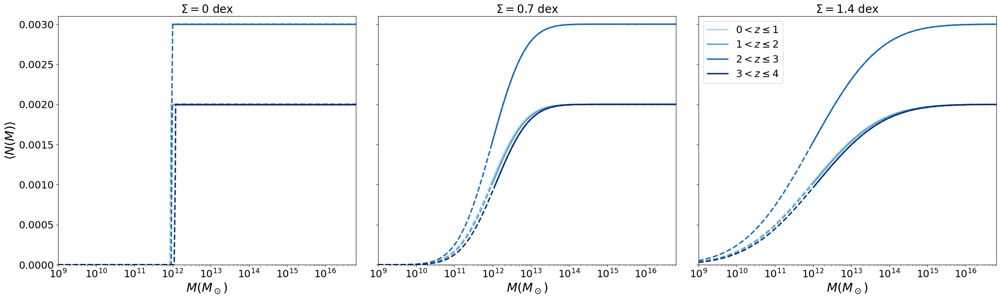

In [39]:
fig = plt.figure(figsize = (30, 8))
gs = gridspec.GridSpec(1, 3, wspace = 0.075)
sigma_array = [0, 0.7, 1.4]
n_m_array, bins_M_min = [], []

for j in range(len(sigma_array)):
    
    ax1 = fig.add_subplot(gs[j])
        
    for i in z_array:
        
        bins_i = np.logspace(M_min_array[i], M_max, n_bins)

        n_m = HOD_scatter(fduty[i], M_min_array[i], bins_i, sigma_array[j])

        ax1.plot(bins_i, n_m, linewidth = 2.5, label = '${:.0f}<z \leq{:.0f}$'.format(i, i+1), color = cmap_blue[i])
        # ax1.plot(bins, HOD_scatter(fduty[i], M_min_array[i], bins, sigma_array[j]), linewidth = 2.5, linestyle ='--', color = cmap_blue[i])

        bins_i = np.sort(np.append(bins, 10**M_min_array[i]))
        n_m = HOD_scatter(fduty[i], M_min_array[i], bins_i, sigma_array[j])
        n_m[bins_i==10**M_min_array[i]]=fduty[i]/2
        # if j == 0:
        #     print(bins_i)
        #     print(n_m)

        ax1.plot(bins_i, n_m, linewidth = 2.5, linestyle ='--', color = cmap_blue[i])

        if j == 0:
            
            n_m_array.append(n_m)
            bins_M_min.append(bins_i)
    
    ax1.set_xscale('log')
    ax1.set_xlabel('$M (M_\odot)$')
    
    if j== 0:
        ax1.set_ylabel(r'$\langle N(M) \rangle$')
    else:
        ax1.set_yticklabels([])
    
    ax1.set_title('$\Sigma={}$ dex'.format(sigma_array[j]))
    ax1.set_xlim(1e9,10**M_max)
    ax1.set_ylim(0, 0.0031)
    
    print()
    
ax1.legend()
plt.show()

## Step-function HOD: $\langle N(M) \rangle = \begin{cases}f_{duty} & M\geq M_{min} \\ 0 & M<M_{min}\end{cases}$

In [40]:
fduty = [0.002, 0.002, 0.003, 0.002]
n_m_array = []
for i in z_array:        
    n_m=np.zeros(np.shape(quaia.recenter(bins)))
    n_m[quaia.recenter(bins)>=10**M_min_array[i]]=fduty[i]
    n_m_array.append(n_m)

<>:3: SyntaxWarning: invalid escape sequence '\l'
<>:6: SyntaxWarning: invalid escape sequence '\o'
<>:3: SyntaxWarning: invalid escape sequence '\l'
<>:6: SyntaxWarning: invalid escape sequence '\o'
/tmp/ipykernel_13410/3618045427.py:3: SyntaxWarning: invalid escape sequence '\l'
  plt.plot(quaia.recenter(bins), n_m_array[i], linewidth = 2.5, label = '${:.0f}<z \leq{:.0f}$'.format(i, i+1))
/tmp/ipykernel_13410/3618045427.py:6: SyntaxWarning: invalid escape sequence '\o'
  plt.xlabel('$M (M_\odot)$')


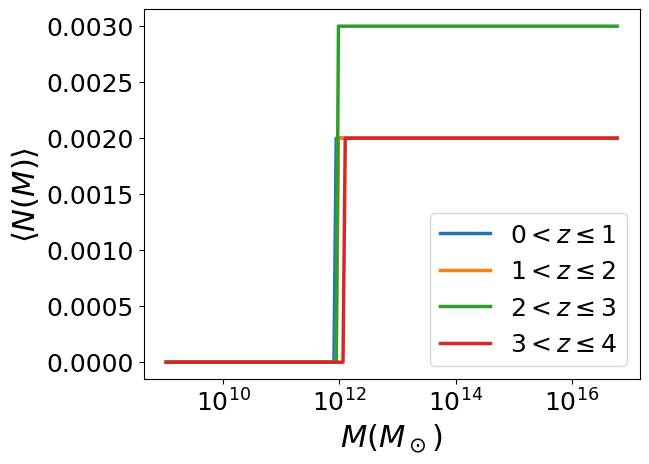

In [41]:
for i in z_array:
        
    plt.plot(quaia.recenter(bins), n_m_array[i], linewidth = 2.5, label = '${:.0f}<z \leq{:.0f}$'.format(i, i+1))

plt.xscale('log')
plt.xlabel('$M (M_\odot)$')
plt.ylabel(r'$\langle N(M) \rangle$')
plt.legend()
plt.show()

In [42]:
n_m_array, bins_M_min = [], []
for i in z_array:   
    bins_i = np.logspace(M_min_array[i], M_max, 79)
    n_m=np.ones(np.shape(bins_i))*fduty[i]
    n_m_array.append(n_m)
    bins_M_min.append(bins_i)

In [43]:
bins = np.logspace(9, M_max, 79)

In [44]:
M_min_array = [11.94, 11.98, 11.97, 12.07]

In [45]:
fduty = [0.002, 0.002, 0.003, 0.002]
n_m_array = []
for i in z_array:        
    n_m=np.zeros(np.shape(quaia.recenter(bins)))
    n_m[quaia.recenter(bins)>=10**M_min_array[i]]=fduty[i]
    n_m_array.append(n_m)

<>:3: SyntaxWarning: invalid escape sequence '\l'
<>:6: SyntaxWarning: invalid escape sequence '\o'
<>:3: SyntaxWarning: invalid escape sequence '\l'
<>:6: SyntaxWarning: invalid escape sequence '\o'
/tmp/ipykernel_13410/3618045427.py:3: SyntaxWarning: invalid escape sequence '\l'
  plt.plot(quaia.recenter(bins), n_m_array[i], linewidth = 2.5, label = '${:.0f}<z \leq{:.0f}$'.format(i, i+1))
/tmp/ipykernel_13410/3618045427.py:6: SyntaxWarning: invalid escape sequence '\o'
  plt.xlabel('$M (M_\odot)$')


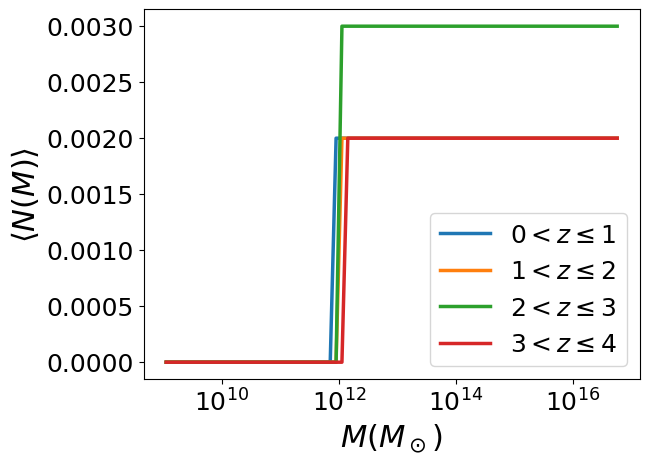

In [46]:
for i in z_array:
        
    plt.plot(quaia.recenter(bins), n_m_array[i], linewidth = 2.5, label = '${:.0f}<z \leq{:.0f}$'.format(i, i+1))

plt.xscale('log')
plt.xlabel('$M (M_\odot)$')
plt.ylabel(r'$\langle N(M) \rangle$')
plt.legend()
plt.show()

In [47]:
n_m_array, bins_M_min = [], []
for i in z_array:   
    bins_i = np.logspace(M_min_array[i], M_max, 79)
    n_m=np.ones(np.shape(bins_i))*fduty[i]
    n_m_array.append(n_m)
    bins_M_min.append(bins_i)

In [48]:
n_m_array_2D = []
for i in z_array:

    n_m_array_2D.append([])
    
    for j in range(len(bins)):
        
        n_m=np.ones(np.shape(bins))*fduty[i]
        n_m_array_2D[i].append(n_m)

## Calculate $b_{\mathrm{qq}}(s,z)=\sqrt{\frac{\xi^{(s)}_{\mathrm{qq}}(s)}{\xi^{(r)}_\mathrm{mm}(r)}-\frac{4 \Omega_{\mathrm{m}}^{1.2}(z)}{45}}-\frac{\Omega_{\mathrm{m}}^{0.6}(z)}{3}$
### Use a 50th percentile mask

In [49]:
bins_M_min_array = [np.logspace(np.log10(bins[j]), M_max, 79) for j in range(len(bins))]

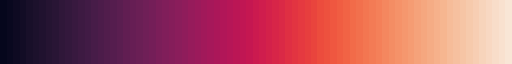

In [50]:
cmap = sns.color_palette("rocket", n_colors = len(bins))
palette = matplotlib.colors.ListedColormap(cmap)
palette

# Calculate derived parameters
## Plot b(z)

In [51]:
def b_eboss(z):
    
    return 0.278*((1+z)**2-6.565) + 2.393

def b_quaia(b_0, a, cosmo = cosmo_planck18): #quaia):
    
    return b_0/ccl.growth_factor(cosmo, a)

In [52]:
b_cf20 = np.load('../results/b_cf20_planck18.npy')
b_wp20 = np.load('../results/b_wp20_planck18.npy')

## Calculate number density as $n_q \approx \int_0^{\infty} d M \frac{d n}{d M}\langle N(M)\rangle$

In [53]:
tab_datahi_mask_zbins, selfunc_hi_bins = {L: [] for L in L_bins}, {L: [] for L in L_bins}

for i in range(len(L_bins)):
            
    for j in z_array:
        
        tab_datahi_mask_zbin0, tab_randhi_mask_zbin0, key_zbin0, _, _, _, selfunc_hi_bin0, _, _ = quaia.make_bins(G_hi, [j, i], True, ['z', 'L'], 
                                                                                         bins = [z_bins, L_bins], tab_gcat_type = 'data', 
                                                                                          method = ['minmax', 'max'], fac_rand = fac_rand, 
                                                                                          n_bins = [None, None], b = b, mask_type = 'b')
        tab_datahi_mask_zbins[L_bins[i]].append(tab_datahi_mask_zbin0['redshift_quaia'])
        selfunc_hi_bins[L_bins[i]].append(selfunc_hi_bin0)

Pixels masked by MC but not already by selfunc: 2468
G20.5_zmin0.0zmax1.0_Lmax-20.0: 0.33              218365 vs 324336
Pixels masked by MC but not already by selfunc: 4785
G20.5_zmin1.0zmax2.0_Lmax-20.0: 0.30              453228 vs 648196
Pixels masked by MC but not already by selfunc: 2764
G20.5_zmin2.0zmax3.0_Lmax-20.0: 0.28              207602 vs 286508
Pixels masked by MC but not already by selfunc: 307
G20.5_zmin3.0zmax4.6_Lmax-20.0: 0.23              28043 vs 36458
Pixels masked by MC but not already by selfunc: 490
G20.5_zmin0.0zmax1.0_Lmax-25.0: 0.46              29985 vs 55261
Pixels masked by MC but not already by selfunc: 3840
G20.5_zmin1.0zmax2.0_Lmax-25.0: 0.33              336125 vs 502242
Pixels masked by MC but not already by selfunc: 2764
G20.5_zmin2.0zmax3.0_Lmax-25.0: 0.28              207602 vs 286508
Pixels masked by MC but not already by selfunc: 307
G20.5_zmin3.0zmax4.6_Lmax-25.0: 0.23              28043 vs 36458
Pixels masked by MC but not already by selfunc: 1

In [54]:
LMC = SkyCoord(['05 23 34.6 -69 45 22'], unit=(u.hourangle, u.deg)) #https://simbad.u-strasbg.fr/simbad/sim-id?Ident=Large+Magellanic+Cloud

In [55]:
LMC_radius = 9*u.deg

In [56]:
SMC = SkyCoord(['00 52 38.0 -72 48 01'], unit=(u.hourangle, u.deg)) # https://simbad.u-strasbg.fr/simbad/sim-id?Ident=small+Magellanic+Cloud

In [57]:
SMC_radius = 5*u.deg

In [58]:
NPIX = hp.nside2npix(NSIDE)

In [59]:
theta, phi = hp.pix2ang(NSIDE, range(NPIX), lonlat=True)
c = SkyCoord(ra=theta*u.degree, dec=phi*u.degree)
LMC_idx, _, _, _ = SkyCoord.search_around_sky(LMC, c, LMC_radius)
SMC_idx, _, _, _ = SkyCoord.search_around_sky(SMC, c, SMC_radius)
MC_idx = np.append(LMC_idx,SMC_idx)
MC_mask = np.full_like(range(NPIX), True, dtype = bool)
MC_mask[MC_idx] = False

In [60]:
selfunc_mask = np.abs(c.galactic.b.value)>=b

In [61]:
n_q, n_q_err, V_eff, N_q = {L: [] for L in L_bins}, {L: [] for L in L_bins}, {L: [] for L in L_bins}, {L: [] for L in L_bins}

for i in range(len(L_bins)):
            
    for j in z_array:   

        N = len(tab_datahi_mask_zbins[L_bins[i]][j])
        f_sky = 1/(4*np.pi)*np.sum(selfunc_hi_bins[L_bins[i]][j][selfunc_mask & MC_mask]*hp.nside2pixarea(NSIDE))
        V = f_sky*(Planck18.comoving_volume(z_bins[j+1])-Planck18.comoving_volume(z_bins[j]))*Planck18.h**3/u.h**3
        N_q[L_bins[i]].append(N)
        n_q[L_bins[i]].append(N/V.value)
        n_q_err[L_bins[i]].append(np.sqrt(N)/V.value) # Poisson error
        V_eff[L_bins[i]].append(V)
        print(np.sqrt(N)/N*100)
        
n_q_err, N/V

0.21399739416959668
0.14853938923101784
0.2194745834562775
0.5971559501134015
0.5774946609060736
0.17248430868424924
0.2194745834562775
0.5971559501134015
1.2825784196427568
0.3004357977625259
0.23305718175637785
0.5971559501134015
3.58979079308869
0.6942101345006233
0.3929978502486891
0.6830594718982789


({-20.0: [2.306551403404182e-08,
   1.208077202021923e-08,
   6.8836698683460285e-09,
   1.6257950737213308e-09],
  -25.0: [1.2163780573680231e-08,
   1.0235703557927114e-08,
   6.8836698683460285e-09,
   1.6257950737213308e-09],
  -26.0: [5.315303569404201e-09,
   8.222287402598444e-09,
   6.159309194526849e-09,
   1.6257950737213308e-09],
  -27.0: [1.9549622374672744e-09,
   4.239757610474862e-09,
   3.949929691972451e-09,
   1.272591786871808e-09]},
 <Quantity 1.86307611e-07 h3 / Mpc3>)

In [62]:
fduty_err_hi = 0.002, 0.001, 0.008, 0.077
fduty_err_lo = 0.002, 0.001, 0.007, 0.034

In [63]:
def n_q_theory_err(n_dm, fduty_err, M_min, a, M_min_err, hmf = hmf, cosmo = cosmo_planck18): #quaia):
    
    nm = hmf(cosmo, bins, a)/cosmo['h']**3 # convert to h/Mpc**3
    dn_dm = nm/(bins*np.log(10))
    
    return np.sqrt(n_dm**2*fduty_err**2+(fduty_err*hmf(cosmo, 10**M_min, a))**2*M_min_err**2)

## Calculate extent of Limber approximation

In [64]:
def theta_break(slope, sigma, rm):

    return 2*np.sqrt(3)/np.sqrt(np.pi)*gamma(slope/2)/gamma(slope/2-1/2)*sigma/rm*u.rad

In [65]:
slope = [1.89, 1.89, 1.89, 2.13]

In [66]:
for i in range(len(L_bins)):

    print('M_i<={}'.format(L_bins[i]))

    for j in z_array:

        print('{:.1f}<z<={:.1f}\n'.format(z_bins[j], z_bins[j+1]))
        
        tab_datahi_mask_zbin0, tab_randhi_mask_zbin0, key_zbin0, _, _, _, selfunc_hi_bin0, _, _ = quaia.make_bins(
            G_hi, [j, i], True, ['z', 'L'], bins = [z_bins, L_bins], tab_gcat_type = 'data', method = ['minmax', 'max'], fac_rand = fac_rand, 
            n_bins = [None, None], b = b, mask_type = 'b', verbose = False)

        z = np.mean(tab_datahi_mask_zbin0['redshift_quaia'])
        rm = quaia.comoving_dist(z)
        sigma = quaia.comoving_dist(z+np.mean(tab_datahi_mask_zbin0['redshift_quaia_err']))-rm
        theta = theta_break(slope[j], sigma, rm)
        
        print('sigma/rm      : {:.2f}'.format(sigma/rm))
        print('10% error     : {:.2f}'.format(260*sigma/rm*u.arcmin))
        print('10% error     : {:.2f}'.format((260*sigma/rm*u.arcmin).to(u.deg)))
        print('theta_break   : {:.2f}'.format(theta))
        print('theta_break/10: {:.2f}\n'.format(theta.to(u.deg)))

M_i<=-20.0
0.0<z<=1.0

sigma/rm      : 0.14
10% error     : 35.15 arcmin
10% error     : 0.59 deg
theta_break   : 0.14 rad
theta_break/10: 7.87 deg

1.0<z<=2.0

sigma/rm      : 0.07
10% error     : 18.83 arcmin
10% error     : 0.31 deg
theta_break   : 0.07 rad
theta_break/10: 4.22 deg

2.0<z<=3.0

sigma/rm      : 0.04
10% error     : 10.30 arcmin
10% error     : 0.17 deg
theta_break   : 0.04 rad
theta_break/10: 2.31 deg

3.0<z<=4.6

sigma/rm      : 0.02
10% error     : 5.79 arcmin
10% error     : 0.10 deg
theta_break   : 0.03 rad
theta_break/10: 1.53 deg

M_i<=-25.0
0.0<z<=1.0

sigma/rm      : 0.10
10% error     : 25.89 arcmin
10% error     : 0.43 deg
theta_break   : 0.10 rad
theta_break/10: 5.80 deg

1.0<z<=2.0

sigma/rm      : 0.06
10% error     : 16.08 arcmin
10% error     : 0.27 deg
theta_break   : 0.06 rad
theta_break/10: 3.60 deg

2.0<z<=3.0

sigma/rm      : 0.04
10% error     : 10.30 arcmin
10% error     : 0.17 deg
theta_break   : 0.04 rad
theta_break/10: 2.31 deg

3.0<z<=4.6

s

## Calculate min scale to avoid 1-halo term
[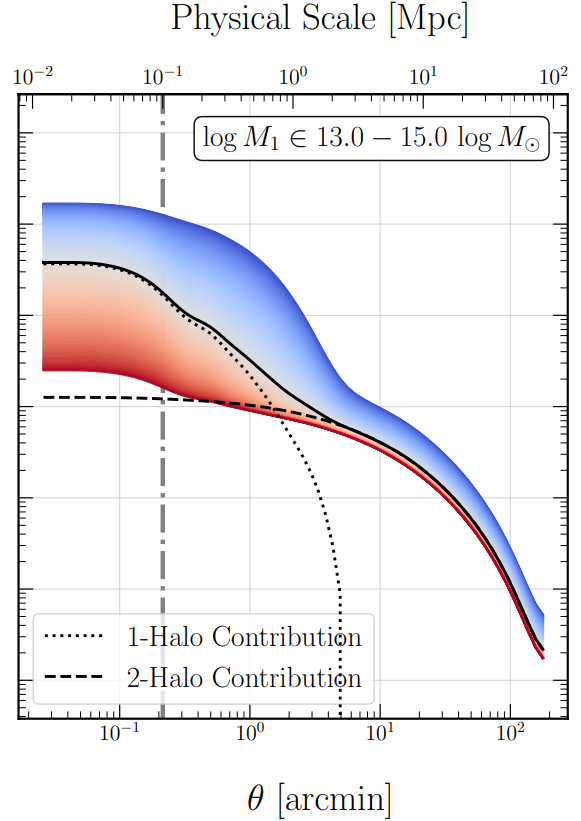](https://arxiv.org/abs/2510.11780)

In [67]:
np.log10((5*u.arcmin).to(u.deg).value), np.log10(0.01)

(-1.0791812460476249, -2.0)

## Limit angular scales to $0.001^\circ\geq \theta \geq 10^\circ$

In [68]:
# Create the bins array
rmin = 0.001
rmax = 10.0
nbins = 30 #20 #30 #20
thetabins = np.logspace(np.log10(rmin), np.log10(rmax), nbins+1)
np.log10(thetabins), quaia.recenter(np.log10(thetabins)), np.diff(np.log10(thetabins))

(array([-3.        , -2.86666667, -2.73333333, -2.6       , -2.46666667,
        -2.33333333, -2.2       , -2.06666667, -1.93333333, -1.8       ,
        -1.66666667, -1.53333333, -1.4       , -1.26666667, -1.13333333,
        -1.        , -0.86666667, -0.73333333, -0.6       , -0.46666667,
        -0.33333333, -0.2       , -0.06666667,  0.06666667,  0.2       ,
         0.33333333,  0.46666667,  0.6       ,  0.73333333,  0.86666667,
         1.        ]),
 array([-2.93333333e+00, -2.80000000e+00, -2.66666667e+00, -2.53333333e+00,
        -2.40000000e+00, -2.26666667e+00, -2.13333333e+00, -2.00000000e+00,
        -1.86666667e+00, -1.73333333e+00, -1.60000000e+00, -1.46666667e+00,
        -1.33333333e+00, -1.20000000e+00, -1.06666667e+00, -9.33333333e-01,
        -8.00000000e-01, -6.66666667e-01, -5.33333333e-01, -4.00000000e-01,
        -2.66666667e-01, -1.33333333e-01, -2.35922393e-16,  1.33333333e-01,
         2.66666667e-01,  4.00000000e-01,  5.33333333e-01,  6.66666667e-01,
       

In [69]:
pimax = 80 # 40 # 5000.0 # 40.0\

In [70]:
dpi = 0.01
pibins = np.arange(0, pimax+1, dpi)

## Pick cosmology

In [71]:
cosmo = 'Planck'

In [72]:
N = 50 #20 #65 #50 #30 #15 #80

In [73]:
wp_chi2, wp_matter_chi2, rpavg_chi2 = {L: [] for L in L_bins}, {L: [] for L in L_bins}, {L: [] for L in L_bins}
a_zbin, b_wp_q = {L: [] for L in L_bins}, {L: [] for L in L_bins}
H0 = Planck18.H0 # cosmo_planck18['H0'] * u.km/u.s/u.Mpc
for i in range(len(L_bins)):
            
    for j in z_array:                                                               

        wp_zbin_i = np.load('../results/wtheta_G{}_rmin{}_rmax{}_nbins{}_zmin{}zmax{}_Lmax{}_{}_MC_b{}.npy'.format(G_hi, rmin, rmax, nbins, z_bins[j], z_bins[j+1], L_bins[i], cosmo, b))
        a = float(np.load('../results/a_G{}_zmin{}zmax{}_Lmax{}_{}_MC_b{}.npy'.format(G_hi, z_bins[j], z_bins[j+1], L_bins[i], cosmo, b)))
      
        wp_chi2[L_bins[i]].append(wp_zbin_i)

        # scale factor
        a_zbin[L_bins[i]].append(a)

In [74]:
log_thetamin = -1
theta_mask=(quaia.recenter(np.log10(thetabins))>=log_thetamin) & (quaia.recenter(np.log10(thetabins))<=0)
np.log10(quaia.recenter(thetabins)[theta_mask])

array([-0.92823645, -0.79490311, -0.66156978, -0.52823645, -0.39490311,
       -0.26156978, -0.12823645,  0.00509689])

In [75]:
offset = 0.3

In [76]:
delta_xlim = np.diff(np.log10(thetabins))[0]/2
delta_xlim/2, thetabins, 10**(np.log10(thetabins) - 2*delta_xlim)

(0.033333333333333326,
 array([1.00000000e-03, 1.35935639e-03, 1.84784980e-03, 2.51188643e-03,
        3.41454887e-03, 4.64158883e-03, 6.30957344e-03, 8.57695899e-03,
        1.16591440e-02, 1.58489319e-02, 2.15443469e-02, 2.92864456e-02,
        3.98107171e-02, 5.41169527e-02, 7.35642254e-02, 1.00000000e-01,
        1.35935639e-01, 1.84784980e-01, 2.51188643e-01, 3.41454887e-01,
        4.64158883e-01, 6.30957344e-01, 8.57695899e-01, 1.16591440e+00,
        1.58489319e+00, 2.15443469e+00, 2.92864456e+00, 3.98107171e+00,
        5.41169527e+00, 7.35642254e+00, 1.00000000e+01]),
 array([7.35642254e-04, 1.00000000e-03, 1.35935639e-03, 1.84784980e-03,
        2.51188643e-03, 3.41454887e-03, 4.64158883e-03, 6.30957344e-03,
        8.57695899e-03, 1.16591440e-02, 1.58489319e-02, 2.15443469e-02,
        2.92864456e-02, 3.98107171e-02, 5.41169527e-02, 7.35642254e-02,
        1.00000000e-01, 1.35935639e-01, 1.84784980e-01, 2.51188643e-01,
        3.41454887e-01, 4.64158883e-01, 6.30957344e-01,

In [77]:
# cmap_theta = sns.color_palette("cubehelix", n_colors = len(L_bins))
cmap_theta = sns.color_palette("flare_r", n_colors = len(L_bins))
cmap_theta

[(0.47936222, 0.18006056, 0.43733022),
 (0.66635279, 0.22717328, 0.43008427),
 (0.83765537, 0.30784814, 0.3723105),
 (0.90732341, 0.4939774, 0.38990532)]

<>:22: SyntaxWarning: invalid escape sequence '\l'
<>:24: SyntaxWarning: invalid escape sequence '\l'
<>:22: SyntaxWarning: invalid escape sequence '\l'
<>:24: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_13410/2220482154.py:22: SyntaxWarning: invalid escape sequence '\l'
  yerr = sigma, markeredgewidth = 2.5, linestyle = 'none', label = '$M_i\leq{}$'.format(L_bins[i])) #capsize = 2.5
/tmp/ipykernel_13410/2220482154.py:24: SyntaxWarning: invalid escape sequence '\l'
  ax1.set_title('${:.1f}<z \leq{:.1f}$'.format(z_bins[j], z_bins[j+1]))


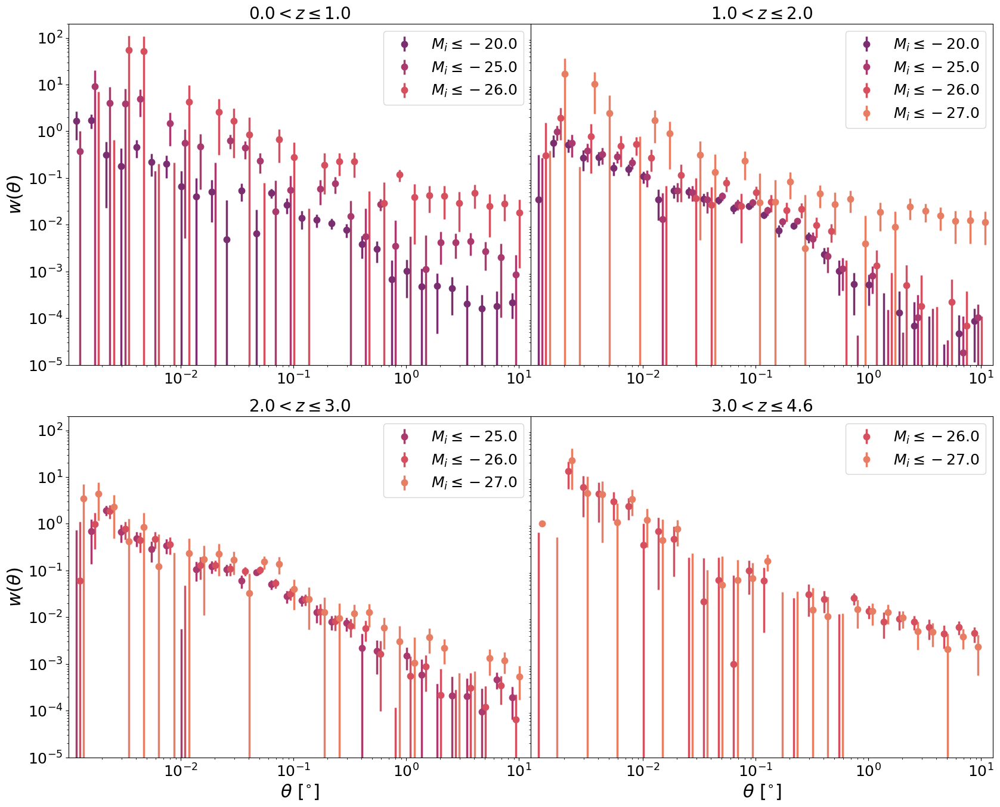

In [78]:
fig = plt.figure(figsize = (20, 16))
gs = gridspec.GridSpec(2, 2, wspace = 0, hspace = 0.15)

# remove bottom panel and just print bq somewhere
# plot!
for j in range(len(z_array)):

    ax1 = fig.add_subplot(gs[j])

    k=0
    for i in range(len(L_bins)):

        if (((i<3) and (N_q[L_bins[i]][j]>N_q[L_bins[i+1]][j])) or (i==3)) and (np.round(N_q[L_bins[i]][j]/1000)>1):
            
            sigma = np.sqrt(np.diag(np.load('../results/cov_wtheta_G{}_rmin{}_rmax{}_nbins{}_zmin{}zmax{}_Lmax{}_N{}_{}_MC_b{}.npy'.format(
                G_hi, rmin, rmax, nbins, z_bins[j], z_bins[j+1], L_bins[i], N, cosmo, b))))
            wp_zbin_i = np.load('../results/wtheta_G{}_rmin{}_rmax{}_nbins{}_zmin{}zmax{}_Lmax{}_{}_MC_b{}.npy'.format(
                G_hi, rmin, rmax, nbins, z_bins[j], z_bins[j+1], L_bins[i], cosmo, b))
            a = float(np.load('../results/a_G{}_zmin{}zmax{}_Lmax{}_{}_MC_b{}.npy'.format(G_hi, z_bins[j], z_bins[j+1], L_bins[i], cosmo, b)))            
            
            ax1.errorbar(10**(np.log10(quaia.recenter(thetabins)) + k*delta_xlim/2), wp_zbin_i, linewidth = 2.5, marker = 'o', color = cmap_theta[i],
                        yerr = sigma, markeredgewidth = 2.5, linestyle = 'none', label = '$M_i\leq{}$'.format(L_bins[i])) #capsize = 2.5

            ax1.set_title('${:.1f}<z \leq{:.1f}$'.format(z_bins[j], z_bins[j+1]))
            ax1.set_xlim(10**(np.log10(quaia.recenter(thetabins))[0] - delta_xlim), 10**(np.log10(quaia.recenter(thetabins))[-1] + 5/2*delta_xlim))
            ax1.set_yscale('log')
            ax1.set_xscale('log')
            ax1.set_ylim(1e-5, 2e2)
            
            if j%2==0:
                ax1.set_ylabel(r"$w(\theta)$")
            else:
                ax1.set_yticks([])
            if j > 1:
                ax1.set_xlabel(r'$\theta$ $[^{\circ}]$') 
            ax1.legend(loc = 'upper right')

            k+=1

plt.show()

<>:21: SyntaxWarning: invalid escape sequence '\l'
<>:23: SyntaxWarning: invalid escape sequence '\l'
<>:21: SyntaxWarning: invalid escape sequence '\l'
<>:23: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_13410/1720828843.py:21: SyntaxWarning: invalid escape sequence '\l'
  yerr = sigma, markeredgewidth = 2.5, linestyle = 'none', label = '${:.1f}<z \leq{:.1f}$'.format(z_bins[j], z_bins[j+1])) #capsize = 2.5
/tmp/ipykernel_13410/1720828843.py:23: SyntaxWarning: invalid escape sequence '\l'
  ax1.set_title('$M_i\leq{}$'.format(L_bins[i]))


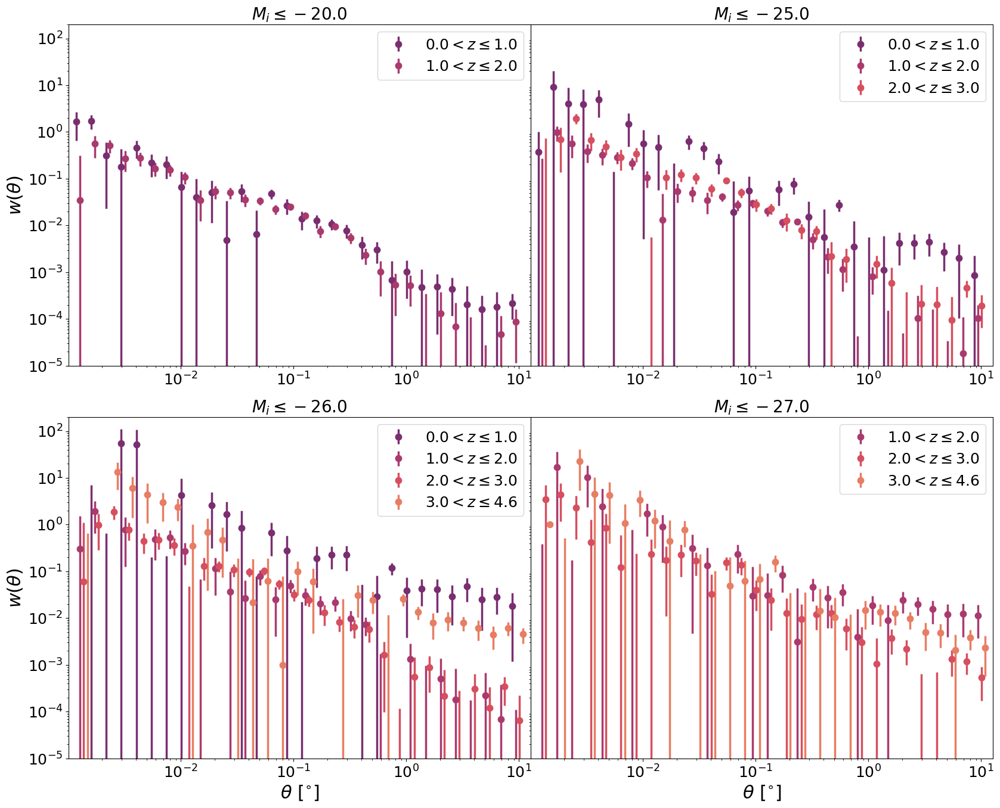

In [79]:
fig = plt.figure(figsize = (20, 16))
gs = gridspec.GridSpec(2, 2, wspace = 0, hspace = 0.15)

# remove bottom panel and just print bq somewhere
# plot!
for i in range(len(L_bins)):

    ax1 = fig.add_subplot(gs[i])

    for j in range(len(z_array)):

        if (((i<3) and (N_q[L_bins[i]][j]>N_q[L_bins[i+1]][j])) or (i==3)) and (np.round(N_q[L_bins[i]][j]/1000)>1):

            sigma = np.sqrt(np.diag(np.load('../results/cov_wtheta_G{}_rmin{}_rmax{}_nbins{}_zmin{}zmax{}_Lmax{}_N{}_{}_MC_b{}.npy'.format(
                G_hi, rmin, rmax, nbins, z_bins[j], z_bins[j+1], L_bins[i], N, cosmo, b))))
            wp_zbin_i = np.load('../results/wtheta_G{}_rmin{}_rmax{}_nbins{}_zmin{}zmax{}_Lmax{}_{}_MC_b{}.npy'.format(
                G_hi, rmin, rmax, nbins, z_bins[j], z_bins[j+1], L_bins[i], cosmo, b))
            a = float(np.load('../results/a_G{}_zmin{}zmax{}_Lmax{}_{}_MC_b{}.npy'.format(G_hi, z_bins[j], z_bins[j+1], L_bins[i], cosmo, b)))            
            
            ax1.errorbar(10**(np.log10(quaia.recenter(thetabins)) + j*delta_xlim/2), wp_zbin_i, linewidth = 2.5, marker = 'o', color = cmap_theta[j],
                        yerr = sigma, markeredgewidth = 2.5, linestyle = 'none', label = '${:.1f}<z \leq{:.1f}$'.format(z_bins[j], z_bins[j+1])) #capsize = 2.5

            ax1.set_title('$M_i\leq{}$'.format(L_bins[i]))
            ax1.set_xlim(10**(np.log10(quaia.recenter(thetabins))[0] - delta_xlim), 10**(np.log10(quaia.recenter(thetabins))[-1] + 5/2*delta_xlim))
            ax1.set_yscale('log')
            ax1.set_xscale('log')
            ax1.set_ylim(1e-5, 2e2)
            
            if i%2==0:
                ax1.set_ylabel(r"$w(\theta)$")
            else:
                ax1.set_yticks([])
            if i > 1:
                ax1.set_xlabel(r'$\theta$ $[^{\circ}]$') 
            ax1.legend(loc = 'upper right')

plt.show()

<>:14: SyntaxWarning: invalid escape sequence '\l'
<>:31: SyntaxWarning: invalid escape sequence '\m'
<>:14: SyntaxWarning: invalid escape sequence '\l'
<>:31: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_13410/2542660200.py:14: SyntaxWarning: invalid escape sequence '\l'
  ax1.set_title('$M_i\leq{}$'.format(L_bins[i]))
/tmp/ipykernel_13410/2542660200.py:31: SyntaxWarning: invalid escape sequence '\m'
  ax1.errorbar(quaia.recenter(thetabins), wp_zbin_i, marker = 'o', label = '${:.0f}^\mathrm{{th}}$ percentile'.format(mask*100), markeredgewidth = 2.5,# capsize = 2.5,


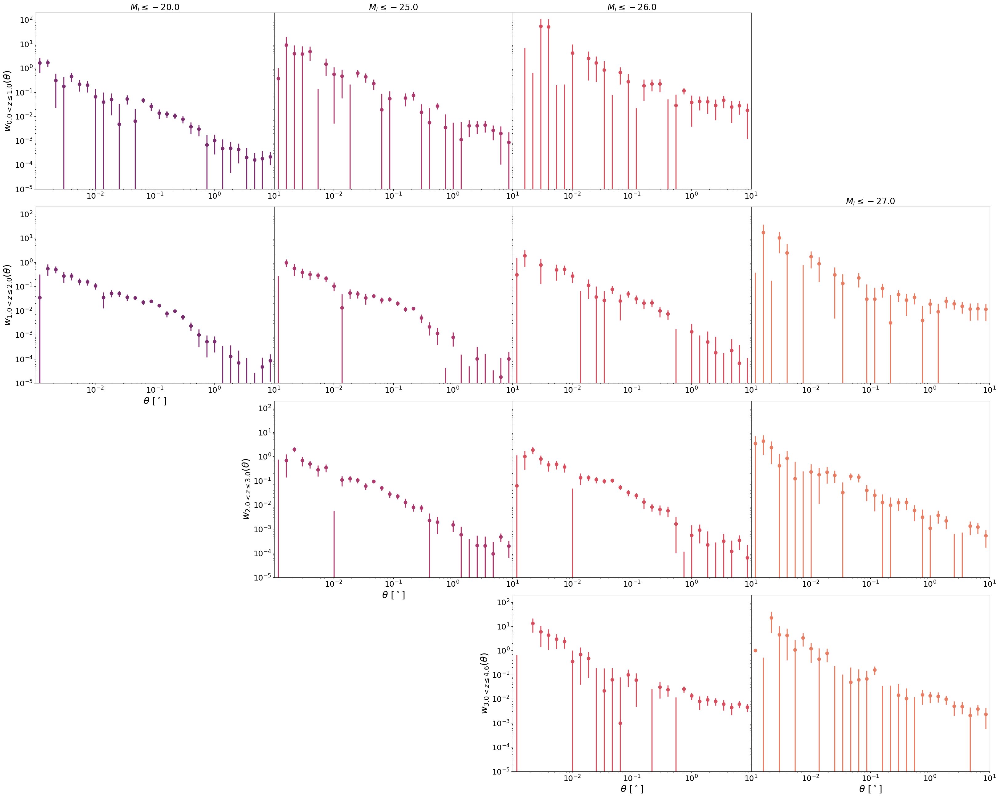

In [80]:
fig = plt.figure(figsize = (40, 32))
gs = gridspec.GridSpec(4, 4, wspace = 0, hspace = 0.1)
k = 3
b=30
for j in z_array:
    
    for i in range(len(L_bins)):

        if (((i<3) and (N_q[L_bins[i]][j]>N_q[L_bins[i+1]][j])) or (i==3)) and (np.round(N_q[L_bins[i]][j]/1000)>1):
                
            ax1 = fig.add_subplot(gs[j*4+i])

            if (j ==0) or ((j == 1) and (i == 3)):
                ax1.set_title('$M_i\leq{}$'.format(L_bins[i]))
            ax1.set_xscale('log')
            ax1.set_yscale('log')
            ax1.set_ylim(1e-5, 2e2)
            
            if j > 2 or ((j>0) and (i <2) and (i!=j)):
                ax1.set_xlabel(r'$\theta$ $[^\circ]$') # projected
            if i==0 or ((j>1) and (i <3) and (i!=j)):
                ax1.set_ylabel(r"$w_{{{:.1f}<z \leq{:.1f}}}(\theta)$".format(z_bins[j], z_bins[j+1]))
            else:
                ax1.set_yticks([])
            ax1.set_xlim(10**(np.log10(quaia.recenter(thetabins))[0] - delta_xlim), 10**(np.log10(quaia.recenter(thetabins))[-1] + delta_xlim))
                          
            wp_zbin_i = np.load('../results/wtheta_G{}_rmin{}_rmax{}_nbins{}_zmin{}zmax{}_Lmax{}_{}_MC_b{}.npy'.format(G_hi, rmin, rmax, nbins, z_bins[j], z_bins[j+1], L_bins[i], cosmo, b))
            a = float(np.load('../results/a_G{}_zmin{}zmax{}_Lmax{}_{}_MC_b{}.npy'.format(G_hi, z_bins[j], z_bins[j+1], L_bins[i], cosmo, b)))            
            sigma = np.sqrt(np.diag(np.load('../results/cov_wtheta_G{}_rmin{}_rmax{}_nbins{}_zmin{}zmax{}_Lmax{}_N{}_{}_MC_b{}.npy'.format(G_hi, rmin, rmax, nbins, z_bins[j], z_bins[j+1], L_bins[i], N, cosmo, b))))
                        
            ax1.errorbar(quaia.recenter(thetabins), wp_zbin_i, marker = 'o', label = '${:.0f}^\mathrm{{th}}$ percentile'.format(mask*100), markeredgewidth = 2.5,# capsize = 2.5,
                     linewidth = 2.5, color = cmap_theta[i], yerr = sigma, linestyle = 'none')

plt.show()

<>:14: SyntaxWarning: invalid escape sequence '\l'
<>:31: SyntaxWarning: invalid escape sequence '\m'
<>:14: SyntaxWarning: invalid escape sequence '\l'
<>:31: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_13410/322399313.py:14: SyntaxWarning: invalid escape sequence '\l'
  ax1.set_title('${:.1f}<z \leq{:.1f}$'.format(z_bins[j], z_bins[j+1]))
/tmp/ipykernel_13410/322399313.py:31: SyntaxWarning: invalid escape sequence '\m'
  ax1.errorbar(quaia.recenter(thetabins), wp_zbin_i, marker = 'o', label = '${:.0f}^\mathrm{{th}}$ percentile'.format(mask*100), markeredgewidth = 2.5,# capsize = 2.5,


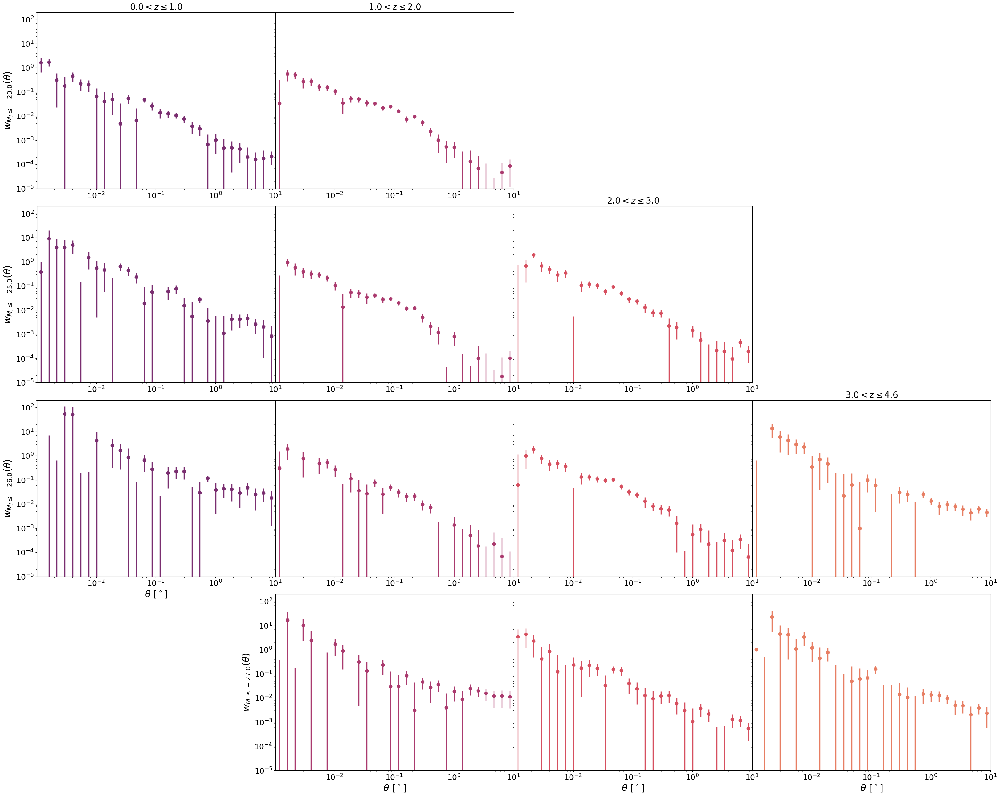

In [81]:
fig = plt.figure(figsize = (40, 32))
gs = gridspec.GridSpec(4, 4, wspace = 0, hspace = 0.1)
k = 3
b=30
for i in range(len(L_bins)):

    for j in z_array:
    
        if (((i<3) and (N_q[L_bins[i]][j]>N_q[L_bins[i+1]][j])) or (i==3)) and (np.round(N_q[L_bins[i]][j]/1000)>1):
                
            ax1 = fig.add_subplot(gs[i*4+j])

            if i ==0 or ((i<3) and (j>1) and (i!=j)):
                ax1.set_title('${:.1f}<z \leq{:.1f}$'.format(z_bins[j], z_bins[j+1]))
            ax1.set_xscale('log')
            ax1.set_yscale('log')
            ax1.set_ylim(1e-5, 2e2)
            
            if i > 2 or ((i ==2) and (j == 0)):
                ax1.set_xlabel(r'$\theta$ $[^\circ]$') # projected
            if j==0 or ((j == 1) and (i == 3)):
                ax1.set_ylabel(r"$w_{{M_i\leq{}}}(\theta)$".format(L_bins[i]))
            else:
                ax1.set_yticks([])
            ax1.set_xlim(10**(np.log10(quaia.recenter(thetabins))[0] - delta_xlim), 10**(np.log10(quaia.recenter(thetabins))[-1] + delta_xlim))
                            
            wp_zbin_i = np.load('../results/wtheta_G{}_rmin{}_rmax{}_nbins{}_zmin{}zmax{}_Lmax{}_{}_MC_b{}.npy'.format(G_hi, rmin, rmax, nbins, z_bins[j], z_bins[j+1], L_bins[i], cosmo, b))
            a = float(np.load('../results/a_G{}_zmin{}zmax{}_Lmax{}_{}_MC_b{}.npy'.format(G_hi, z_bins[j], z_bins[j+1], L_bins[i], cosmo, b)))            
            sigma = np.sqrt(np.diag(np.load('../results/cov_wtheta_G{}_rmin{}_rmax{}_nbins{}_zmin{}zmax{}_Lmax{}_N{}_{}_MC_b{}.npy'.format(G_hi, rmin, rmax, nbins, z_bins[j], z_bins[j+1], L_bins[i], N, cosmo, b))))
                        
            ax1.errorbar(quaia.recenter(thetabins), wp_zbin_i, marker = 'o', label = '${:.0f}^\mathrm{{th}}$ percentile'.format(mask*100), markeredgewidth = 2.5,# capsize = 2.5,
                     linewidth = 2.5, color = cmap_theta[j], yerr = sigma, linestyle = 'none')

plt.show()

# Perform nested sampling with dynesty

In [233]:
# Define the dimensionality of our problem.
ndim = 2

### Implement Limber approximation: $w(\theta)=\int d z \frac{H(z)}{c}\left(\frac{d N}{d z}\right)^2 \int \frac{d k k}{2 \pi} P_{q q} J_0[k \theta \chi(z)]=\int d z \frac{H(z)}{c}\left(\frac{d N}{d z}\right)^2 w_p(\theta \chi(z))$

In [234]:
theta_min = (rmin*u.deg).to(u.rad)
theta_max = (rmax*u.deg).to(u.rad)

zmin, zmax = 0.1, 4.6

lambda_min = theta_min*quaia.comoving_dist(zmin, units = 'Mpc')#/(1+zmin) # angular diameter distance
lambda_max = theta_max*quaia.comoving_dist(zmax, units = 'Mpc')#/(1+zmax)
print(lambda_min, lambda_max)

k_max = 2*np.pi/lambda_min
k_min = 2*np.pi/lambda_max
print(k_min, k_max)

np.log10(k_min.value), np.log10(k_max.value) 

0.007549695656720839 Mpc rad 1347.40810509432 Mpc rad
0.004663164250997107 1 / (Mpc rad) 832.243522503614 1 / (Mpc rad)


(-2.33131928708778, 2.920250423652214)

In [235]:
k_log = np.logspace(-2.5, 3) #-4, 2)

In [236]:
(rmax*u.deg).to(u.rad)*quaia.comoving_dist(4.6)/(1+4.6)

<Quantity 162.79577213 Mpc rad / littleh>

In [237]:
def wp_2h(bins, n_m, a, cosmo, wp_matter_zbin_i, rpbins, pibins = pibins, recenter = True, rpmask = True, integral = integral):

    if not isinstance(wp_matter_zbin_i, np.ndarray):
        
        # matter correlation function    
        if isinstance(rpmask, bool):
            rpmask = [rpmask]*len(quaia.recenter(rpbins))
            
        s = np.sqrt(np.sum(np.meshgrid(quaia.recenter(rpbins)[rpmask]**2, quaia.recenter(pibins)**2), axis = 0))
        s_Mpc = (s*u.Mpc/cu.littleh).to(u.Mpc, cu.with_H0(cosmo['h']* 100 * u.km/u.s/u.Mpc))

        xirppi_zbin_i = ccl.correlations.correlation_3d(cosmo, r=np.ravel(s_Mpc), a=a)
        # wp_matter_zbin_i = 2*np.trapz(np.reshape(xirppi_zbin_i, np.shape(s_Mpc)), quaia.recenter(pibins), axis = 0)
        wp_matter_zbin_i = 2*integral(np.reshape(xirppi_zbin_i, np.shape(s_Mpc)), quaia.recenter(pibins), axis = 0)

    return cf_2h(bins, n_m, a, cosmo, wp_matter_zbin_i, recenter = recenter, integral = integral)

In [238]:
dz = np.linspace(0, 4.6)

In [239]:
rpbins = [(thetabins*u.deg).to(u.rad)*quaia.comoving_dist(z, units = 'Mpc') for z in dz]
np.max(rpbins)

1347.40810509432

In [240]:
i = 0
j = 1
tab_datahi_mask_zbin0, tab_randhi_mask_zbin0, key_zbin0, _, _, _, selfunc_hi_bin0, _, _ = quaia.make_bins(
            G_hi, [j, i], True, ['z', 'L'], bins = [z_bins, L_bins], tab_gcat_type = 'data', method = ['minmax', 'max'], fac_rand = fac_rand, 
            n_bins = [None, None], b = b, mask_type = 'b', verbose = False)

In [241]:
dN_dz = np.sum(stats.norm.pdf(dz[None, :], loc=tab_datahi_mask_zbin0['redshift_quaia'][:, None], scale=tab_datahi_mask_zbin0['redshift_quaia_err'][:, None]), axis = 0)
norm = np.sum(stats.norm.cdf(dz[-1], loc=tab_datahi_mask_zbin0['redshift_quaia'], scale=tab_datahi_mask_zbin0['redshift_quaia_err']))

In [242]:
bins_m = np.logspace(12, M_max, 79)
n_m=np.ones(len(bins_m))*1e-2

In [243]:
n_m=HOD_scatter(10**1e-2, 12, bins, 0.4)

In [244]:
def wtheta_2h(bins, n_m, dN_dz, wp = False, thetabins = thetabins, dz = dz, k = k_log, recenter = False,
              theta_mask = np.full_like(quaia.recenter(thetabins), True, dtype = bool), rpbins = rpbins, integral = integral):

    hankel = mcfit.Hankel(k, lowring = True)

    # compute for each z... for statement?
    b_q, k_integral, a, n_g = [], [], [], []
    for i, z in enumerate(dz):
        a.append(1/(1+z))
        b_z, n_z = bias(bins, n_m, a[i], cosmo_planck18, recenter = recenter, integral = integral)
        if wp:
            wp_z, _ = wp_2h(bins, n_m, a[i], cosmo_planck18, False, rpbins[i], recenter = recenter, integral = integral)
        else:
            P_qq = b_z**2*ccl.power.linear_matter_power(cosmo_planck18, k, a[i])
            rpbins_k, wp_k = hankel(P_qq/(2*np.pi))
            wp_z = np.interp(quaia.recenter(rpbins[i]).value[theta_mask], rpbins_k, wp_k)
            
        k_integral.append(wp_z) # as a function of rp
        b_q.append(b_z)
        n_g.append(n_z)
        
    z_integrand = [ccl.background.h_over_h0(cosmo_planck18, a[i])*Planck18.H0.to(1/u.s)/constants.c.to(u.Mpc/u.s)*dN_dz[i]**2*k_integral[i] 
                   for i in range(len(dz))]
    
    # return np.trapz(z_integrand, dz, axis = 0), np.trapz(b_q*dN_dz, dz) #np.trapz(b_q*np.array(n_g)*dN_dz, z_array)/np.trapz(n_g*dN_dz, z_array)
    return integral(z_integrand, dz, axis = 0), integral(b_q*dN_dz, dz) #np.trapz(b_q*np.array(n_g)*dN_dz, z_array)/np.trapz(n_g*dN_dz, z_array)

In [245]:
P_mm = [ccl.power.linear_matter_power(cosmo_planck18, k_log, 1/(1+z)) for z in dz]

In [246]:
H0_c_dN_dz = [ccl.background.h_over_h0(cosmo_planck18, 1/(1+dz[i]))*Planck18.H0.to(1/u.s)/constants.c.to(u.Mpc/u.s)*(dN_dz[i]/norm)**2 for i in range(len(dz))]

In [247]:
def wtheta_2h_optimized(bins, n_m, H0_c_dN_dz, P_mm = P_mm, wp = False, thetabins = thetabins, dz = dz, k = k_log, recenter = False, 
                        theta_mask = np.full_like(quaia.recenter(thetabins), True, dtype = bool), rpbins = rpbins, 
                        hankel = mcfit.Hankel(k_log, lowring = True), recenter_bins = False, calc_bias = False, wtheta_mm = False, integral = integral):

    # compute for each z... for statement?
    b_q, k_integral = [], []
    for i, z in enumerate(dz):
        a = 1/(1+z)
        if wtheta_mm == True:
            b_z = 1
        else:
            b_z, n_z = bias(bins, n_m, a, cosmo_planck18, recenter = recenter, integral = integral)
        if wp:
            wp_z, _ = wp_2h(bins, n_m, a, cosmo_planck18, False, rpbins[i], recenter = recenter, integral = integral)
        else:
            P_qq = b_z**2*P_mm[i]
            rpbins_k, wp_k = hankel(P_qq/(2*np.pi))
            if recenter_bins == True:
                rp = quaia.recenter(rpbins[i].value)[theta_mask]
            else:
                rp = rpbins[i].value
            wp_z = np.interp(rp, rpbins_k, wp_k)
            
        k_integral.append(wp_z) # as a function of rp
        b_q.append(b_z)
        
    z_integrand = [H0_c_dN_dz[i]*k_integral[i] for i in range(len(dz))]

    if calc_bias == False:
    
        # return np.trapz(z_integrand, dz, axis = 0)#, np.trapz(b_q*dN_dz, z_array) #np.trapz(b_q*np.array(n_g)*dN_dz, z_array)/np.trapz(n_g*dN_dz, z_array)
        return integral(z_integrand, dz, axis = 0)#, np.trapz(b_q*dN_dz, z_array) #np.trapz(b_q*np.array(n_g)*dN_dz, z_array)/np.trapz(n_g*dN_dz, z_array)

    else:
        # return np.trapz(z_integrand, dz, axis = 0), np.trapz(b_q*dN_dz, dz)
        return integral(z_integrand, dz, axis = 0), integral(b_q*dN_dz, dz)

In [248]:
# wtheta_2h_wp, b_q_wp = wtheta_2h(bins_m, n_m, dN_dz/norm, wp = True)
wtheta_2h_wp = wtheta_2h_optimized(bins, n_m, H0_c_dN_dz, wp = True)

In [249]:
# wtheta_2h_P, b_q_P = wtheta_2h(bins_m, n_m, dN_dz/norm)
wtheta_2h_P_recenter = wtheta_2h_optimized(bins, n_m, H0_c_dN_dz, recenter_bins = True)
wtheta_2h_P = wtheta_2h_optimized(bins, n_m, H0_c_dN_dz)

<>:13: SyntaxWarning: invalid escape sequence '\l'
<>:19: SyntaxWarning: invalid escape sequence '\g'
<>:13: SyntaxWarning: invalid escape sequence '\l'
<>:19: SyntaxWarning: invalid escape sequence '\g'
/tmp/ipykernel_13410/200663531.py:13: SyntaxWarning: invalid escape sequence '\l'
  yerr = sigma, markeredgewidth = 2.5, linestyle = 'none', label = '$M_i\leq{}$'.format(L_bins[i])) #capsize = 2.5
/tmp/ipykernel_13410/200663531.py:19: SyntaxWarning: invalid escape sequence '\g'
  ax1.set_title('$M_i\geq{}, {:.1f}<z \leq{:.1f}$'.format(L_bins[i], z_bins[j], z_bins[j+1]))


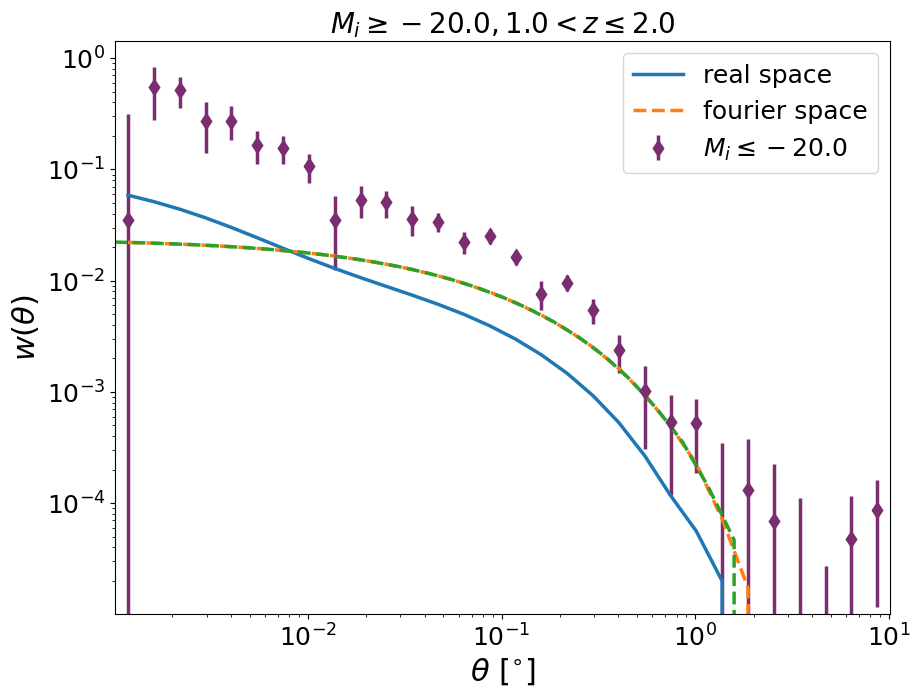

In [250]:
fig = plt.figure(figsize = (20, 16))
gs = gridspec.GridSpec(2, 2, wspace = 0, hspace = 0.15)

ax1 = fig.add_subplot(gs[0])

sigma = np.sqrt(np.diag(np.load('../results/cov_wtheta_G{}_rmin{}_rmax{}_nbins{}_zmin{}zmax{}_Lmax{}_N{}_{}_MC_b{}.npy'.format(
    G_hi, rmin, rmax, nbins, z_bins[j], z_bins[j+1], L_bins[i], N, cosmo, b))))
wp_zbin_i = np.load('../results/wtheta_G{}_rmin{}_rmax{}_nbins{}_zmin{}zmax{}_Lmax{}_{}_MC_b{}.npy'.format(
    G_hi, rmin, rmax, nbins, z_bins[j], z_bins[j+1], L_bins[i], cosmo, b))
a = float(np.load('../results/a_G{}_zmin{}zmax{}_Lmax{}_{}_MC_b{}.npy'.format(G_hi, z_bins[j], z_bins[j+1], L_bins[i], cosmo, b)))            

ax1.errorbar(quaia.recenter(thetabins), wp_zbin_i, linewidth = 2.5, marker = 'd', color = cmap_theta[i],
            yerr = sigma, markeredgewidth = 2.5, linestyle = 'none', label = '$M_i\leq{}$'.format(L_bins[i])) #capsize = 2.5

plt.plot(quaia.recenter(thetabins), wtheta_2h_wp, linewidth = 2.5, label = 'real space')
plt.plot(quaia.recenter(thetabins), wtheta_2h_P_recenter, linewidth = 2.5, label = 'fourier space', linestyle = '--')
plt.plot(thetabins, wtheta_2h_P, linewidth = 2.5, linestyle = '--')

ax1.set_title('$M_i\geq{}, {:.1f}<z \leq{:.1f}$'.format(L_bins[i], z_bins[j], z_bins[j+1]))
ax1.set_xlim(10**(np.log10(quaia.recenter(thetabins))[0] - delta_xlim), 10**(np.log10(quaia.recenter(thetabins))[-1] + delta_xlim))
ax1.set_yscale('log')
ax1.set_xscale('log')

ax1.set_ylabel(r"$w(\theta)$")
ax1.set_xlabel(r'$\theta$ $[^{\circ}]$') 
ax1.legend(loc = 'upper right')

plt.show()

<>:2: SyntaxWarning: invalid escape sequence '\l'
<>:8: SyntaxWarning: invalid escape sequence '\l'
<>:2: SyntaxWarning: invalid escape sequence '\l'
<>:8: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_13410/830572828.py:2: SyntaxWarning: invalid escape sequence '\l'
  plt.hist(tab_datahi_mask_zbin0['redshift_quaia'], label = '$M_i\leq{}, {:.1f}<z \leq{:.1f}$'.format(L_bins[i], z_bins[j], z_bins[j+1]), histtype = 'step', linewidth = 2.5, density = True, bins = 15)
/tmp/ipykernel_13410/830572828.py:8: SyntaxWarning: invalid escape sequence '\l'
  plt.hist(tab_datahi_mask_zbin0['redshift_quaia'], label = '$M_i\leq{}, {:.1f}<z \leq{:.1f}$'.format(L_bins[i], z_bins[j], z_bins[j+1]), histtype = 'step', linewidth = 2.5, bins = 15)


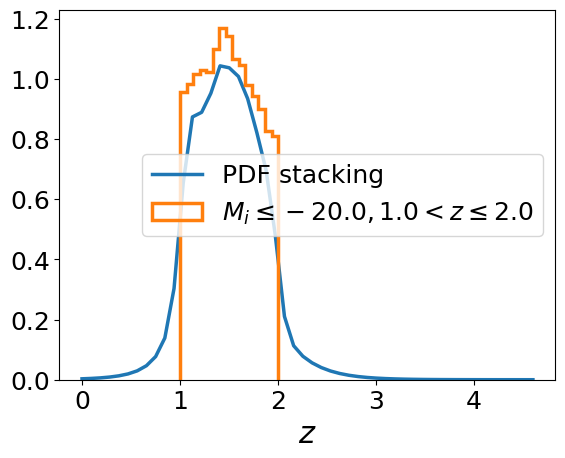

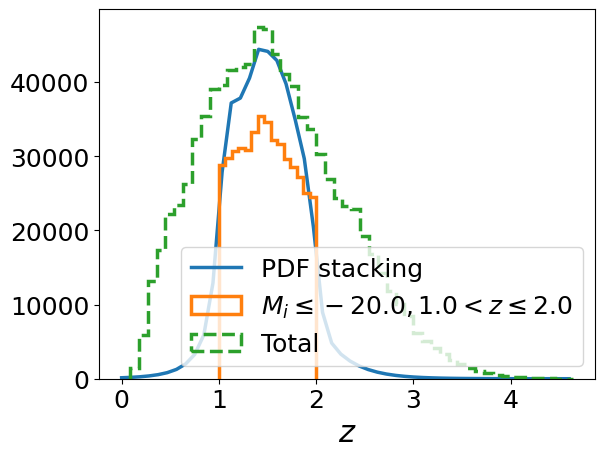

In [251]:
plt.plot(dz, dN_dz/norm, label = 'PDF stacking', linewidth = 2.5)
plt.hist(tab_datahi_mask_zbin0['redshift_quaia'], label = '$M_i\leq{}, {:.1f}<z \leq{:.1f}$'.format(L_bins[i], z_bins[j], z_bins[j+1]), histtype = 'step', linewidth = 2.5, density = True, bins = 15)
plt.legend()
plt.xlabel('$z$')
plt.show()

plt.plot(dz, dN_dz*np.diff(dz)[0], label = 'PDF stacking', linewidth = 2.5)
plt.hist(tab_datahi_mask_zbin0['redshift_quaia'], label = '$M_i\leq{}, {:.1f}<z \leq{:.1f}$'.format(L_bins[i], z_bins[j], z_bins[j+1]), histtype = 'step', linewidth = 2.5, bins = 15)
plt.hist(tab_datahi_mask['redshift_quaia'], label = 'Total', histtype = 'step', linewidth = 2.5, bins = 50, linestyle = '--')
plt.legend()
plt.xlabel('$z$')
plt.show()

<>:2: SyntaxWarning: invalid escape sequence '\m'
<>:2: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_13410/2347691315.py:2: SyntaxWarning: invalid escape sequence '\m'
  plt.hist(tab_datahi_mask_zbin0['redshift_quaia'], label = '$z_\mathrm{Quaia}$', histtype = 'step', linewidth = 2.5, density = True, bins = 15, color = 'black')


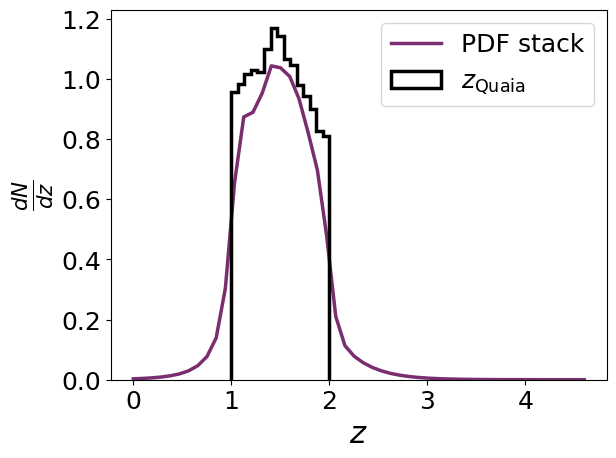

In [252]:
plt.plot(dz, dN_dz/norm, label = 'PDF stack', linewidth = 2.5, color = cmap_theta[i])
plt.hist(tab_datahi_mask_zbin0['redshift_quaia'], label = '$z_\mathrm{Quaia}$', histtype = 'step', linewidth = 2.5, density = True, bins = 15, color = 'black')
plt.legend()
plt.xlabel('$z$')
plt.ylabel(r'$\frac{dN}{dz}$')
plt.show()

### See impact of varying the redshift distribution

In [253]:
sigma_z = np.linspace(0, 4.6, 701) #-4

In [254]:
z=np.round(np.mean(tab_datahi_mask['redshift_quaia']), 1)
z

1.6

In [255]:
delta = 0.75
delta

0.75

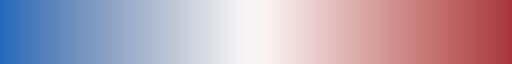

In [256]:
cmap_z = sns.color_palette("vlag", n_colors = len(sigma_z))
palette_z = matplotlib.colors.ListedColormap(cmap_z)
palette_z

In [257]:
sigma_dz_array = np.linspace(0,0.2, 151) #-4
delta_dz = 0.1

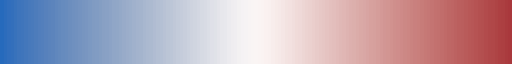

In [258]:
cmap_dz = sns.color_palette("vlag", n_colors = len(sigma_dz_array))
palette_dz = matplotlib.colors.ListedColormap(cmap_dz)
palette_dz

In [259]:
z_err = np.round(np.mean(tab_datahi_mask['redshift_quaia_err']), 1)
z_err

0.2

<>:15: SyntaxWarning: invalid escape sequence '\D'
<>:29: SyntaxWarning: invalid escape sequence '\D'
<>:15: SyntaxWarning: invalid escape sequence '\D'
<>:29: SyntaxWarning: invalid escape sequence '\D'
/tmp/ipykernel_13410/2508095812.py:15: SyntaxWarning: invalid escape sequence '\D'
  cax = fig.add_subplot(gs[0,-1]), label = '$\Delta \overline{z}$')
/tmp/ipykernel_13410/2508095812.py:29: SyntaxWarning: invalid escape sequence '\D'
  cax = fig.add_subplot(gs[1,-1]), label = '$\Delta (\delta z)$')


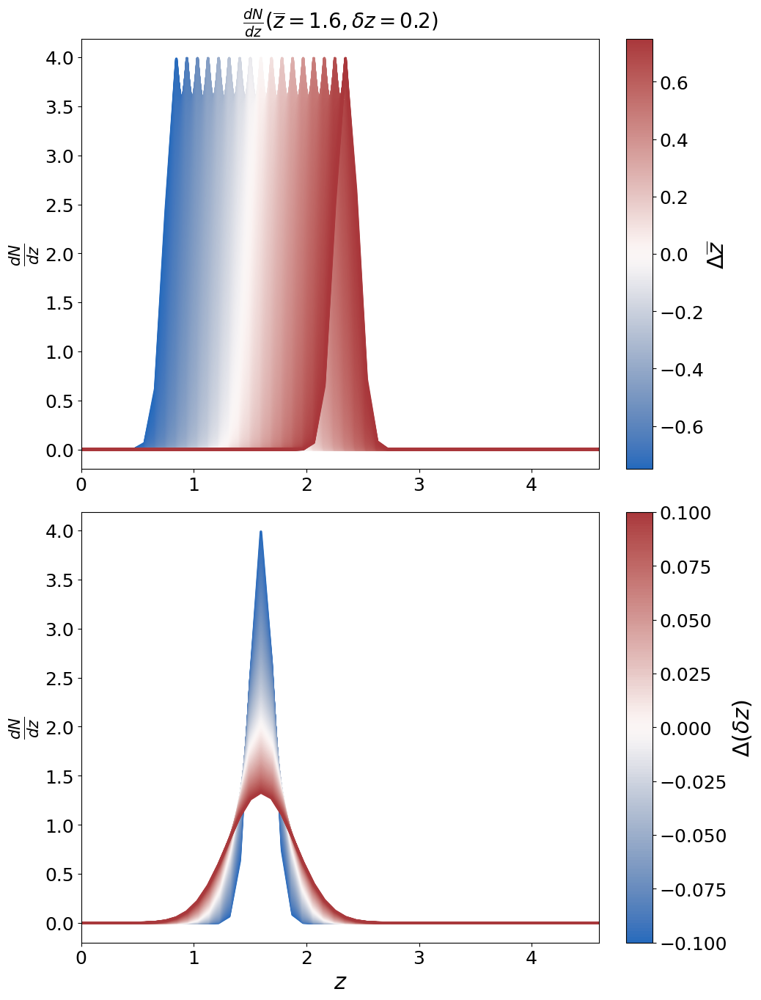

In [260]:
fig = plt.figure(figsize = (10.05, 16))
gs = gridspec.GridSpec(2, 2, wspace = 0.1, hspace = 0.1, width_ratios = [1,0.05])
ax1 = fig.add_subplot(gs[0])

for k in range(len(sigma_z)):
    loc = z+delta*(-1+k/int(len(sigma_z)/2))
    dN_dz_norm = stats.norm.pdf(dz, loc=loc, scale=0.1)
    ax1.plot(dz, dN_dz_norm, linewidth = 2.5, color = cmap_z[k])
    
ax1.set_title(r'$\frac{{dN}}{{dz}}(\overline{{z}}={:.1f}, \delta z = {:.1f})$'.format(z, z_err))
ax1.set_ylabel(r'$\frac{dN}{dz}$')
ax1.set_xlim(0, 4.6)

cbar = fig.colorbar(cm.ScalarMappable(cmap=palette_z, norm = matplotlib.colors.Normalize(vmin=-delta, vmax = delta)), 
                    cax = fig.add_subplot(gs[0,-1]), label = '$\Delta \overline{z}$')

ax1 = fig.add_subplot(gs[2])

for k in range(len(sigma_dz_array)):
    scale = z_err+delta_dz*(-1+k/int(len(sigma_dz_array)/2))
    dN_dz_norm = stats.norm.pdf(dz, loc=z, scale=scale)
    ax1.plot(dz, dN_dz_norm, linewidth = 2.5, color = cmap_dz[k])

ax1.set_xlabel('$z$')
ax1.set_ylabel(r'$\frac{dN}{dz}$')
ax1.set_xlim(0, 4.6)

cbar = fig.colorbar(cm.ScalarMappable(cmap=palette_dz, norm = matplotlib.colors.Normalize(vmin=-delta_dz, vmax = delta_dz)), 
                    cax = fig.add_subplot(gs[1,-1]), label = '$\Delta (\delta z)$')
plt.show()


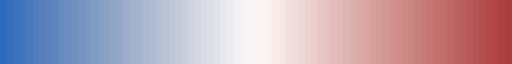

In [261]:
cmap_M_min = sns.color_palette("vlag", n_colors = len(bins))
palette_M_min = matplotlib.colors.ListedColormap(cmap_M_min)
palette_M_min

In [262]:
Mmin = 12
delta_Mmin = 0.5

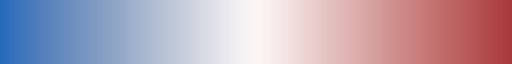

In [263]:
bins_scatter = np.logspace(9, M_max, 251)
cmap_M_min_scatter = sns.color_palette("vlag", n_colors = len(bins_scatter))
palette_M_min_scatter = matplotlib.colors.ListedColormap(cmap_M_min_scatter)
palette_M_min_scatter

In [264]:
Sigma = 0.4

In [265]:
sigma_k_array = np.linspace(0,1.4, 51) #-4

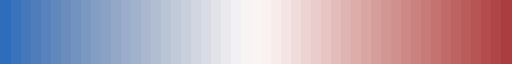

In [266]:
cmap_sigma = sns.color_palette("vlag", n_colors = len(sigma_k_array))
palette_sigma = matplotlib.colors.ListedColormap(cmap_sigma)
palette_sigma

<>:37: SyntaxWarning: invalid escape sequence '\D'
<>:59: SyntaxWarning: invalid escape sequence '\D'
<>:94: SyntaxWarning: invalid escape sequence '\D'
<>:118: SyntaxWarning: invalid escape sequence '\D'
<>:37: SyntaxWarning: invalid escape sequence '\D'
<>:59: SyntaxWarning: invalid escape sequence '\D'
<>:94: SyntaxWarning: invalid escape sequence '\D'
<>:118: SyntaxWarning: invalid escape sequence '\D'
/tmp/ipykernel_13410/495928065.py:37: SyntaxWarning: invalid escape sequence '\D'
  cax = fig.add_subplot(gs[0,2]), label = '$\Delta \overline{z}$')
/tmp/ipykernel_13410/495928065.py:59: SyntaxWarning: invalid escape sequence '\D'
  cax = fig.add_subplot(gs[1,2]), label = '$\Delta (\delta{z})$')
/tmp/ipykernel_13410/495928065.py:94: SyntaxWarning: invalid escape sequence '\D'
  cax = fig.add_subplot(gs[0,-1]), label = '$\Delta \log_{10}(M_{min}/M_\odot)$')
/tmp/ipykernel_13410/495928065.py:118: SyntaxWarning: invalid escape sequence '\D'
  cax = fig.add_subplot(gs[1,-1]), label =  '$

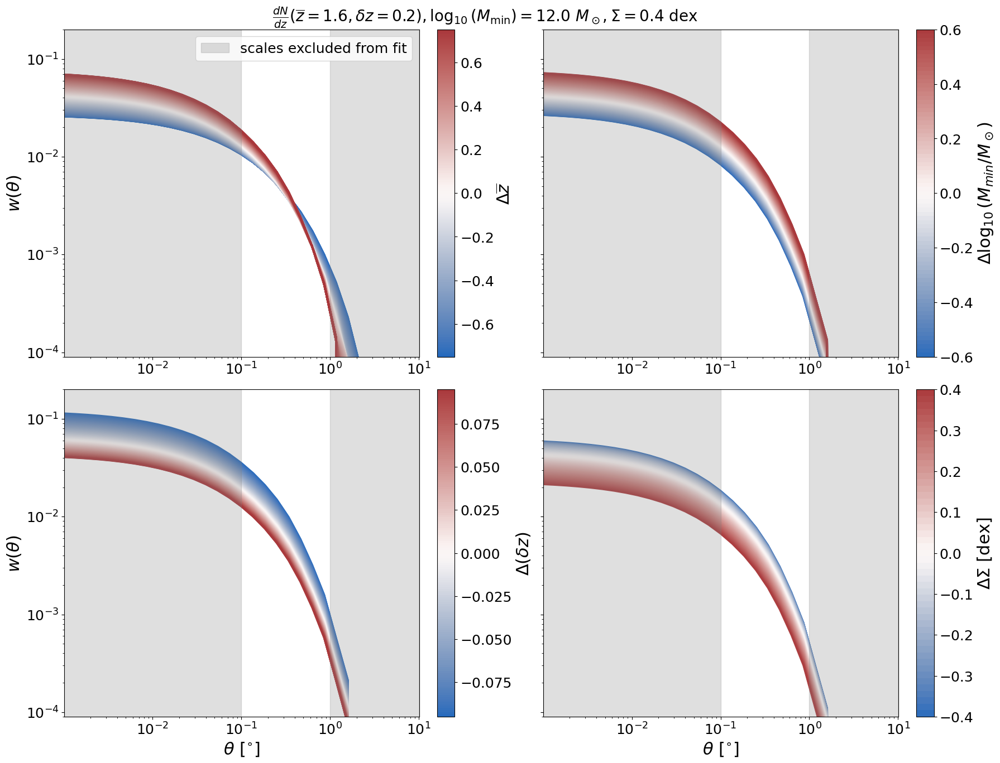

In [267]:
fig = plt.figure(figsize = (20.1, 16))
gs = gridspec.GridSpec(2, 7, wspace = 0, hspace = 0.1, width_ratios = [1,0.05, 0.05, 0.25, 1, 0.05, 0.05])
# remove bottom panel and just print bq somewhere
# plot!
ylim = 9e-5, 2e-1 #2e-5, 9e-1
y = np.linspace(ylim[0], ylim[-1])
ax1 = fig.add_subplot(gs[0])
alpha = 0.25
delta_Mmin = 0.6
delta_dz = 0.095

n_m = HOD_scatter(1e-2, Mmin, bins_scatter, Sigma)

for k in range(len(sigma_z)):
    loc = z+delta*(-1+k/int(len(sigma_z)/2))
    dN_dz_norm = stats.norm.pdf(dz, loc=loc, scale=z_err)
    H0_c_dN_dz_norm = [ccl.background.h_over_h0(cosmo_planck18, 1/(1+loc))*Planck18.H0.to(1/u.s)/constants.c.to(u.Mpc/u.s)*(dN_dz_norm[k])**2 
                       for k in range(len(dz))]
    wtheta_2h_P = wtheta_2h_optimized(bins_scatter, n_m, H0_c_dN_dz_norm)
    plt.plot(thetabins, wtheta_2h_P, linewidth = 2.5, color = cmap_z[k], zorder = 0)

ax1.set_xlim(10**(np.log10(quaia.recenter(thetabins))[0] - delta_xlim), 10**(np.log10(quaia.recenter(thetabins))[-1] + delta_xlim))
ax1.set_yscale('log')
ax1.set_xscale('log')
ax1.set_ylim(ylim)

if quaia.recenter(thetabins)[-1] > 1:
    ax1.fill_betweenx(y, x1 = thetabins[0], x2 = 10**log_thetamin, color = 'grey', 
                      alpha = alpha, label = 'scales excluded from fit')
    ax1.fill_betweenx(y, x1 = 1, x2 = thetabins[-1], color = 'grey', 
                      alpha = alpha)
    
ax1.set_ylabel(r"$w(\theta)$")
ax1.legend()

cbar = fig.colorbar(cm.ScalarMappable(cmap=palette_z, norm = matplotlib.colors.Normalize(vmin=-delta, vmax = delta)), 
                    cax = fig.add_subplot(gs[0,2]), label = '$\Delta \overline{z}$')

ax1 = fig.add_subplot(gs[7])

for k in range(len(sigma_dz_array)):
    scale = z_err + delta_dz*(-1+k/int(len(sigma_dz_array)/2))
    dN_dz_norm = stats.norm.pdf(dz, loc=z, scale=scale)
    H0_c_dN_dz_norm = [ccl.background.h_over_h0(cosmo_planck18, 1/(1+loc))*Planck18.H0.to(1/u.s)/constants.c.to(u.Mpc/u.s)*(dN_dz_norm[k])**2 
                       for k in range(len(dz))]
    wtheta_2h_P = wtheta_2h_optimized(bins_scatter, n_m, H0_c_dN_dz_norm)
    
    plt.plot(thetabins, wtheta_2h_P, linewidth = 2.5, color = cmap_dz[k], zorder=0)

ax1.set_xlim(10**(np.log10(quaia.recenter(thetabins))[0] - delta_xlim), 10**(np.log10(quaia.recenter(thetabins))[-1] + delta_xlim))
ax1.set_yscale('log')
ax1.set_xscale('log')
ax1.set_ylim(ylim)

ax1.set_ylabel(r"$w(\theta)$")
ax1.set_xlabel(r'$\theta$ $[^{\circ}]$') 

cbar = fig.colorbar(cm.ScalarMappable(cmap=palette_dz, norm = matplotlib.colors.Normalize(vmin=-delta_dz, vmax = delta_dz)), 
                    cax = fig.add_subplot(gs[1,2]), label = '$\Delta (\delta{z})$')

if quaia.recenter(thetabins)[-1] > 1:
    ax1.fill_betweenx(y, x1 = thetabins[0], x2 = 10**log_thetamin, color = 'grey', 
                      alpha = alpha, label = 'scales excluded from fit')
    ax1.fill_betweenx(y, x1 = 1, x2 = thetabins[-1], color = 'grey', 
                      alpha = alpha)

ax1 = fig.add_subplot(gs[4])
alpha = 0.25

for k in range(len(bins_scatter)):
    dN_dz_norm = stats.norm.pdf(dz, loc=z, scale=z_err)
    H0_c_dN_dz_norm = [ccl.background.h_over_h0(cosmo_planck18, 1/(1+z))*Planck18.H0.to(1/u.s)/constants.c.to(u.Mpc/u.s)*(dN_dz_norm[l])**2 
                       for l in range(len(dz))]

    n_m = HOD_scatter(1e-2, Mmin+delta_Mmin*(-1+k/int(len(bins_scatter)/2)), bins_scatter, Sigma)
    wtheta_2h_P = wtheta_2h_optimized(bins_scatter, n_m, H0_c_dN_dz_norm)

    plt.plot(thetabins, wtheta_2h_P, linewidth = 2.5, color = cmap_M_min_scatter[k], zorder = 0)

ax1.set_xlim(10**(np.log10(quaia.recenter(thetabins))[0] - delta_xlim), 10**(np.log10(quaia.recenter(thetabins))[-1] + delta_xlim))
ax1.set_yscale('log')
ax1.set_xscale('log')
ax1.set_ylim(ylim)

if quaia.recenter(thetabins)[-1] > 1:
    ax1.fill_betweenx(y, x1 = thetabins[0], x2 = 10**log_thetamin, color = 'grey', 
                      alpha = alpha, label = 'scales excluded from fit')
    ax1.fill_betweenx(y, x1 = 1, x2 = thetabins[-1], color = 'grey', 
                      alpha = alpha)
    
ax1.set_yticklabels([])

cbar = fig.colorbar(cm.ScalarMappable(cmap=palette_M_min, norm = matplotlib.colors.Normalize(vmin=-delta_Mmin, vmax = delta_Mmin)), 
                    cax = fig.add_subplot(gs[0,-1]), label = '$\Delta \log_{10}(M_{min}/M_\odot)$')

ax1 = fig.add_subplot(gs[11])

for k in range(len(sigma_k_array)):

    dN_dz_norm = stats.norm.pdf(dz, loc=z, scale=z_err)
    H0_c_dN_dz_norm = [ccl.background.h_over_h0(cosmo_planck18, 1/(1+z))*Planck18.H0.to(1/u.s)/constants.c.to(u.Mpc/u.s)*(dN_dz_norm[l])**2 
                       for l in range(len(dz))]

    n_m = HOD_scatter(1e-2, Mmin, bins_scatter, Sigma+Sigma*(-1+k/int(len(sigma_k_array)/2)))
    wtheta_2h_P = wtheta_2h_optimized(bins_scatter, n_m, H0_c_dN_dz_norm)
    
    plt.plot(thetabins, wtheta_2h_P, linewidth = 2.5, color = cmap_sigma[k], zorder = 0)

ax1.set_xlim(10**(np.log10(quaia.recenter(thetabins))[0] - delta_xlim), 10**(np.log10(quaia.recenter(thetabins))[-1] + delta_xlim))
ax1.set_yscale('log')
ax1.set_xscale('log')
ax1.set_ylim(ylim)

ax1.set_yticklabels([])
ax1.set_xlabel(r'$\theta$ $[^{\circ}]$') 

cbar = fig.colorbar(cm.ScalarMappable(cmap=palette_sigma, norm = matplotlib.colors.Normalize(vmin=-Sigma, vmax = Sigma)), 
                    cax = fig.add_subplot(gs[1,-1]), label =  '$\Delta \Sigma$ [dex]')

if quaia.recenter(thetabins)[-1] > 1:
    ax1.fill_betweenx(y, x1 = thetabins[0], x2 = 10**log_thetamin, color = 'grey', 
                      alpha = alpha, label = 'scales excluded from fit')
    ax1.fill_betweenx(y, x1 = 1, x2 = thetabins[-1], color = 'grey', 
                      alpha = alpha)

plt.suptitle(r'$\frac{{dN}}{{dz}}(\overline{{z}}={:.1f}, \delta z = {:.1f}),\log_{{10}}(M_\mathrm{{min}})={:.1f}$ $M_\odot, \Sigma={}$ dex'.format(z, z_err, Mmin, Sigma), fontsize = 20, y = 0.907175)

plt.show()

### Define log-likelihood

In [268]:
diag = False #True # False

In [269]:
# insert = False

In [270]:
# Define our 3-D correlated multivariate normal log-likelihood.
C = np.load('../results/cov_wtheta_G{}_rmin{}_rmax{}_nbins{}_zmin{}zmax{}_Lmax{}_N{}_{}_MC_b{}.npy'.format(G_hi, rmin, rmax, nbins, z_bins[j], z_bins[j+1], L_bins[i], N, cosmo, b))
if diag == True:
    C*=np.identity(len(C))
ix_grid = np.ix_(theta_mask, theta_mask)
hartlap = (N-nbins-2)/(N-1)
print(hartlap)

def log_det(C, ix_grid):  
    
    # check if cov is hermitian and positive definite
    if linalg.ishermitian(C[ix_grid]) and np.all(np.linalg.eigvals(C[ix_grid]) > 0):
        C_factor = linalg.cho_factor(C[ix_grid])
        log_det_C = 2 * np.sum(np.log(np.diag(C_factor[0])))
        solve = lambda rhs: linalg.cho_solve(C_factor, rhs)
    else:
        print('using LU decomposition')
        C_factor = linalg.lu_factor(C[ix_grid])
        log_det_C = np.sum(np.log(np.abs(np.diag(C_factor[0])))) # does abs value make sense
        solve = lambda rhs: linalg.lu_solve(C_factor, rhs)

    return log_det_C, solve
        
log_det_C, solve = log_det(C, ix_grid)

def loglike(x, log_det_C, wp, nbins, solve, dN_dz, theta_mask = theta_mask, M_max = M_max, N = N, fduty = 0, optimize = False, recenter_bins = True, #insert = insert,
            bins_m = bins, integral = integral):
    
    M_min, sigma = x
    
    # bins_m = np.logspace(M_min, M_max, 79)
    # if insert == True:
    #     bins_m = np.sort(np.append(bins_m, 10**M_min))
        
    # n_m=np.ones(np.shape(bins_m))*10**fduty
    n_m=HOD_scatter(10**fduty, M_min, bins_m, sigma)
    
    # if insert == True:
    if np.any(bins_m==10**M_min) and (sigma==0):
        n_m[bins_m==10**M_min]=10**fduty/2

    if optimize == True:
        wp_2h_zbin = wtheta_2h_optimized(bins_m, n_m, dN_dz, theta_mask = theta_mask, recenter_bins = recenter_bins, integral = integral)
    else:
        wp_2h_zbin, _ = wtheta_2h(bins_m, n_m, dN_dz, theta_mask = theta_mask, integral = integral)
    delta = wp-wp_2h_zbin
    
    c_p = gamma(N/2)/((np.pi*(N-1))**(nbins/2)*gamma((N-nbins)/2))
    lnorm = np.log(c_p)-0.5*log_det_C  

    return -N*0.5 * np.log(1+(delta.T @ solve(delta))/(N-1)) + lnorm #- penalty

0.3673469387755102


In [271]:
def ptform(u):
    """Transforms the uniform random variables `u ~ Unif[0., 1.)`
    to the parameters of interest."""

    x = np.array(u)  # copy u 

    # Uniform from 9 to 15
    x[0] = 7 * u[0] + 9  # scale and shift to [9., 16.)

    # Uniform from 0 to 0.15
    x[1] = 1.4 * u[1]  # scale to [0., 0.15) #1.4

    return x

In [272]:
nlive = 1000 #1000 #500 #3000 #500
dlogz = 0.001 # 0.01

In [273]:
nbins_mask = np.sum(theta_mask)
nbins, np.sum(theta_mask), len(wp_chi2[L_bins[i]][j][theta_mask]), len(wp_chi2[L_bins[i]][j])

(30, 8, 8, 30)

In [274]:
x_test = np.array([12.0, 0.4])  # test M_min
start = time.time()
# result = loglike(x_test, log_det_C, wp_chi2[L_bins[i]][j][theta_mask], np.sum(theta_mask), solve, dN_dz/norm, theta_mask=theta_mask)
result = loglike(x_test, log_det_C, wp_chi2[L_bins[i]][j][theta_mask], nbins_mask, solve, H0_c_dN_dz, theta_mask=theta_mask, optimize = True)
print(f"Time: {time.time()-start:.2f}s")

print(result)

Time: 0.01s
35.4059928989972


In [275]:
rstate=np.random.default_rng(0)

In [276]:
# initialize our nested sampler
# sampler = NestedSampler(loglike, ptform, ndim, logl_args=[log_det_C, wp_chi2[L_bins[i]][j][theta_mask], np.sum(theta_mask), solve, dN_dz/norm], 
#                         nlive = nlive, logl_kwargs = {'theta_mask': theta_mask})
sampler = NestedSampler(loglike, ptform, ndim, logl_args=[log_det_C, wp_chi2[L_bins[i]][j][theta_mask], nbins_mask, solve, H0_c_dN_dz], 
                        nlive = nlive, logl_kwargs = {'theta_mask': theta_mask, 'optimize': True}, rstate = rstate)

In [277]:
# run the sampler with checkpointing
sampler.run_nested(dlogz = dlogz)
results = sampler.results

9956it [07:49, 21.20it/s, +1000 | bound: 14 | nc: 1 | ncall: 49805 | eff(%): 22.449 | loglstar:   -inf < 41.361 <    inf | logz: 38.308 +/-  0.049 | dlogz:  0.000 >  0.001]


In [278]:
# Print out a summary of the results.
results.summary()

Summary
nlive: 1000
niter: 9956
ncall: 48805
eff(%): 22.449
logz: 38.308 +/-  0.049


<>:3: SyntaxWarning: invalid escape sequence '\g'
<>:3: SyntaxWarning: invalid escape sequence '\g'
/tmp/ipykernel_13410/488143463.py:3: SyntaxWarning: invalid escape sequence '\g'
  fig.suptitle('$M_i\geq{}, {:.1f}<z \leq{:.1f}$'.format(L_bins[i], z_bins[j], z_bins[j+1]), fontsize = 20, y = 0.9)


Text(0.5, 0.9, '$M_i\\geq-20.0, 1.0<z \\leq2.0$')

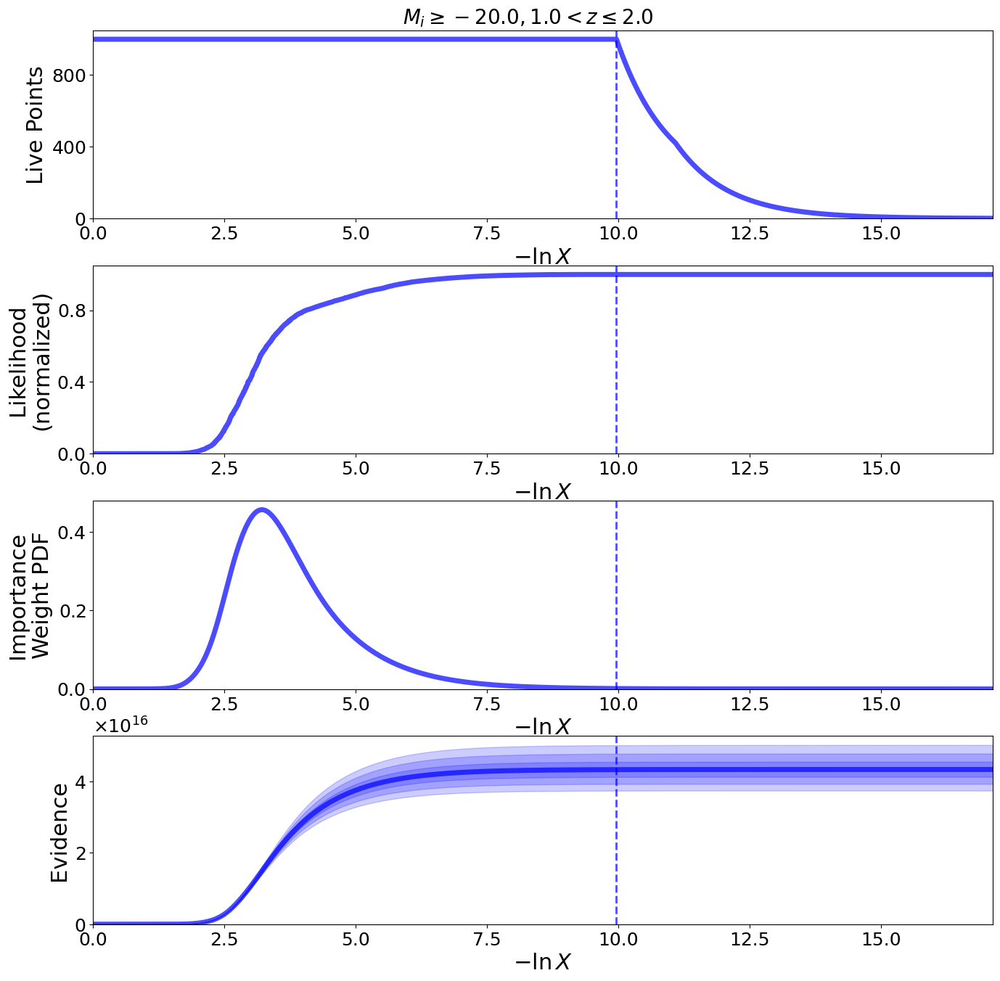

In [279]:
fig, axes = dyplot.runplot(results)  # summary (run) plot
fig.subplots_adjust(hspace=0.25)
fig.suptitle('$M_i\geq{}, {:.1f}<z \leq{:.1f}$'.format(L_bins[i], z_bins[j], z_bins[j+1]), fontsize = 20, y = 0.9)

In [280]:
quantile = [0.16, 0.5, 0.84]
# quantiles = stats.norm.cdf(-1), stats.norm.cdf(0), 1 - stats.norm.cdf(-1)

<>:7: SyntaxWarning: invalid escape sequence '\g'
<>:7: SyntaxWarning: invalid escape sequence '\g'
/tmp/ipykernel_13410/3351987430.py:7: SyntaxWarning: invalid escape sequence '\g'
  fig.suptitle('$M_i\geq{}, {:.1f}<z \leq{:.1f}$'.format(L_bins[i], z_bins[j], z_bins[j+1]), fontsize = 20, y = 1)


Text(0.5, 1, '$M_i\\geq-20.0, 1.0<z \\leq2.0$')

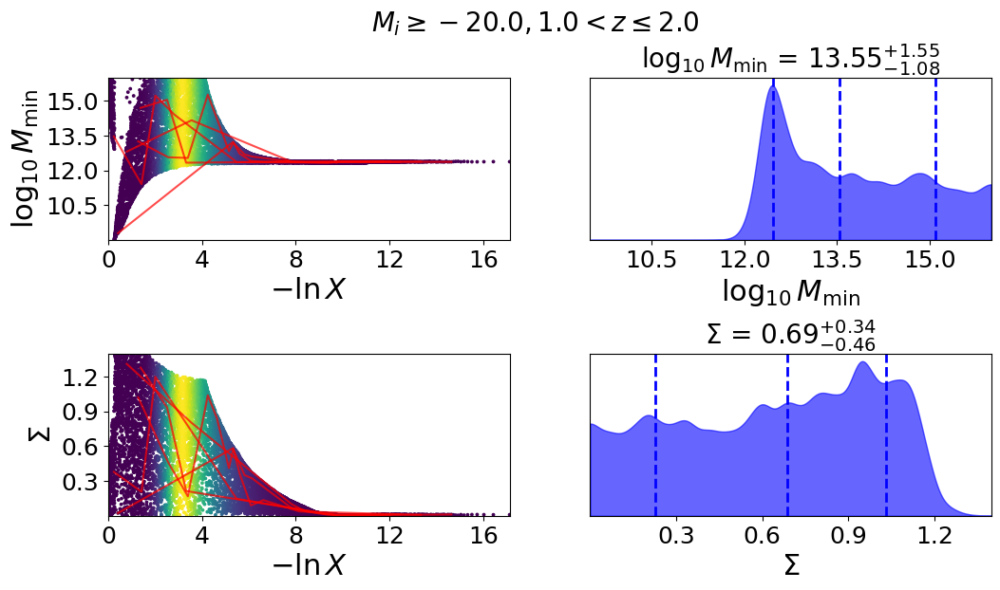

In [281]:
labels=[r'$\log_{10} M_\mathrm{min}$', r'$\Sigma$']
fig, axes = dyplot.traceplot(results, 
                             show_titles=True,
                             trace_cmap='viridis', connect=True,
                             connect_highlight=range(5), labels=labels, quantiles = quantile, title_quantiles = quantile)
fig.subplots_adjust(hspace=0.7)
fig.suptitle('$M_i\geq{}, {:.1f}<z \leq{:.1f}$'.format(L_bins[i], z_bins[j], z_bins[j+1]), fontsize = 20, y = 1)

<>:7: SyntaxWarning: invalid escape sequence '\g'
<>:7: SyntaxWarning: invalid escape sequence '\g'
/tmp/ipykernel_13410/2913095966.py:7: SyntaxWarning: invalid escape sequence '\g'
  fig.suptitle('$M_i\geq{}, {:.1f}<z \leq{:.1f}$'.format(L_bins[i], z_bins[j], z_bins[j+1]), fontsize = 20, y = 0.975, x = 0.575)


Text(0.575, 0.975, '$M_i\\geq-20.0, 1.0<z \\leq2.0$')

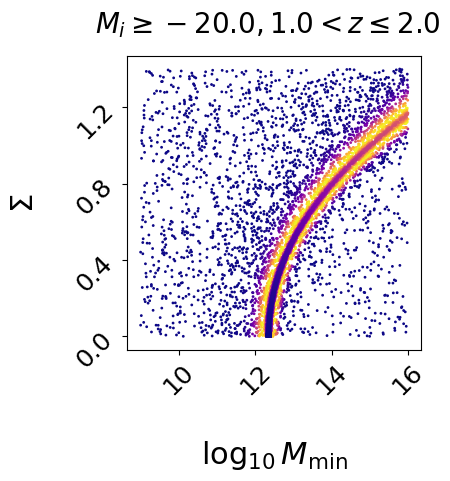

In [282]:
# initialize figure
fig, axes = plt.subplots(1, 1, figsize=(5, 5))

# plot initial run (res1; left)
fg, ax = dyplot.cornerpoints(results, cmap='plasma',
                             kde=False, labels=labels, fig=(fig, axes))
fig.suptitle('$M_i\geq{}, {:.1f}<z \leq{:.1f}$'.format(L_bins[i], z_bins[j], z_bins[j+1]), fontsize = 20, y = 0.975, x = 0.575)

In [283]:
# sigmas = [1, 2, 3]
quantile_2d = 1.0 - np.exp(-0.5 * np.array([1, 2])**2)#, 3])**2)
quantile_2d

array([0.39346934, 0.86466472])

In [284]:
r = np.array([1,2])
s=1
np.exp(-(r[0]/s)**2/2-(r[1]/s)**2/2) / (2*np.pi*s**2)

0.013064233284684921

In [285]:
r = np.sqrt(r[0]**2+r[1]**2)
pdf = np.exp(-(r/s)**2/2) / (2*np.pi*s**2)
# pdf[0]+pdf[1]
pdf

0.013064233284684914

In [286]:
def make_contour_cmap(color, n_levels, alpha_min=0, alpha_max=1.0):
    # rgba = np.array(mcolors.to_rgba(color))
    cmap = []
    alphas = np.linspace(0,1,n_levels+1)
    for alpha in alphas:
        rgba = np.array(mcolors.to_rgba(color))
        # if i == 0:
        #     [-1] = 0.0  # region outside the loosest contour stays transparent
        # else:
        rgba[-1] = alpha
        cmap.append(rgba)
    # cmap.append(rgba)  # innermost band, fully opaque
    return cmap

In [287]:
# contourf_colors = plt.get_cmap('Reds')(np.linspace(0.333, 0.999, len(quantiles_2d)))
# contourf_color = np.mean(contourf_colors, axis = 0)
# contourf_colors = np.append([np.zeros(np.shape(contourf_colors[0]))],contourf_colors, axis = 0)
contourf_kwargs = {'colors': make_contour_cmap('blue', len(quantile))}

<>:8: SyntaxWarning: invalid escape sequence '\g'
<>:8: SyntaxWarning: invalid escape sequence '\g'
/tmp/ipykernel_13410/83788948.py:8: SyntaxWarning: invalid escape sequence '\g'
  fig.suptitle('$M_i\geq{}, {:.1f}<z \leq{:.1f}$'.format(L_bins[i], z_bins[j], z_bins[j+1]), fontsize = 20, y = 1, x = 0.375)


Text(0.375, 1, '$M_i\\geq-20.0, 1.0<z \\leq2.0$')

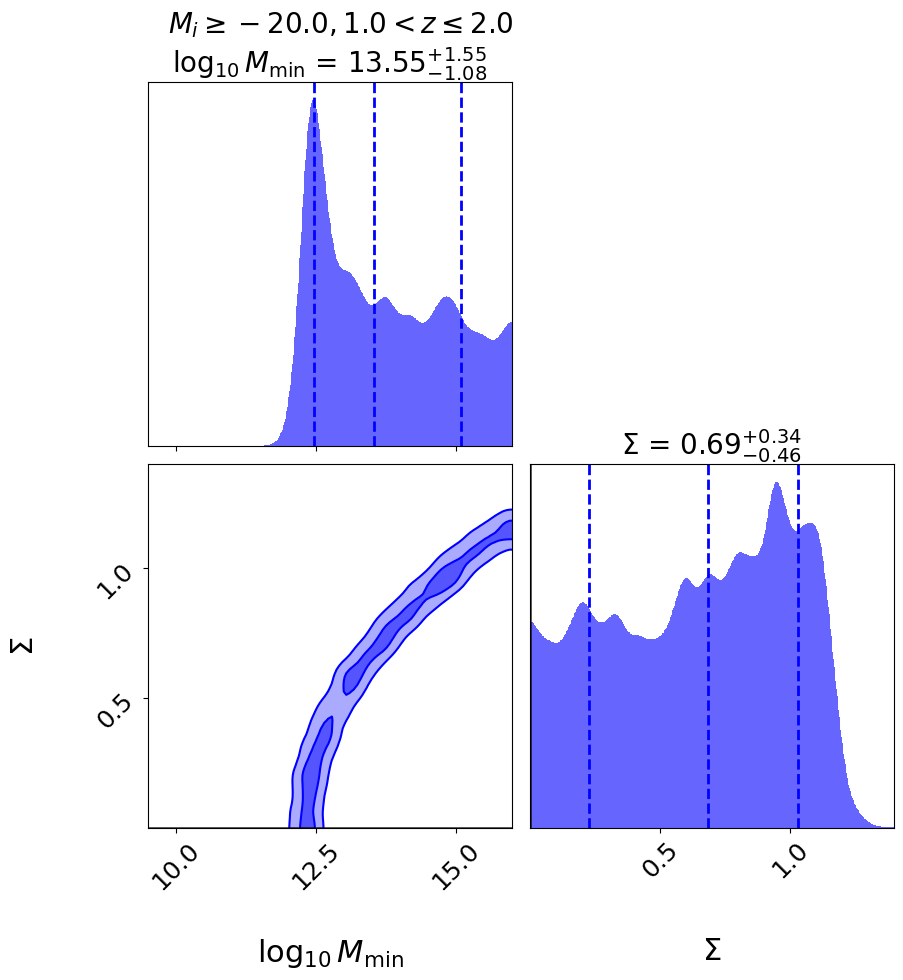

In [288]:
# # initialize figure
fig, axes = plt.subplots(2, 2, figsize=(10, 10))

# plot initial run (res1; left)
fg, ax = dyplot.cornerplot(results, color='blue', truths=np.zeros(ndim), hist2d_kwargs = {'contourf_kwargs': contourf_kwargs}, #hist2d_kwargs,
                           truth_color='black', show_titles=True,
                           max_n_ticks=3, quantiles=quantile, quantiles_2d = quantile_2d, title_quantiles = quantile, labels=labels, fig=(fig, axes[:, :2]))
fig.suptitle('$M_i\geq{}, {:.1f}<z \leq{:.1f}$'.format(L_bins[i], z_bins[j], z_bins[j+1]), fontsize = 20, y = 1, x = 0.375)

In [289]:
samples, weights = results.samples, results.importance_weights()
mean, cov = dyfunc.mean_and_cov(samples, weights)
print(mean, cov)

[13.72046018  0.64835415] [[1.32293011 0.37624069]
 [0.37624069 0.11719215]]


In [290]:
# Compute weighted quantiles
# Get median and 1-sigma (16th, 50th, 84th percentiles) for each parameter
quantiles = [dyfunc.quantile(samples[:, i], quantile, weights=weights) 
             for i in range(samples.shape[1])]

for k, (lo, mid, hi) in enumerate(quantiles):
    print(f"{labels[k]}: {mid:.2f} + {hi-mid:.2f}/-{mid-lo:.2f}")

$\log_{10} M_\mathrm{min}$: 13.55 + 1.55/-1.08
$\Sigma$: 0.69 + 0.34/-0.46


In [291]:
equal_weight_samples_Mmin = dyfunc.resample_equal(samples, weights)

## Try fitting $f_{duty}$

In [292]:
labels_fduty = [r'$\log_{10} f_\mathrm{duty}$']

In [293]:
equal_weight_samples_Mmin

array([[1.25357427e+01, 1.07434155e-02],
       [1.25983760e+01, 4.89375307e-01],
       [1.39348416e+01, 7.87760975e-01],
       ...,
       [1.41133102e+01, 8.74413899e-01],
       [1.48010477e+01, 9.21513496e-01],
       [1.24807096e+01, 3.25214745e-01]])

In [294]:
n_q_theory = []
for k in range(len(equal_weight_samples_Mmin)):
    n_m=HOD_scatter(1, equal_weight_samples_Mmin[:,0][k], bins, equal_weight_samples_Mmin[:,1][k])
    n_q_theory.append(M(bins, n_m, a = a_zbin[L_bins[i]][j], cosmo = cosmo_planck18, recenter = False)[1])
equal_weight_samples_fduty = np.log10(n_q[L_bins[i]][j]/n_q_theory)

In [295]:
# Get median and 1-sigma (16th, 50th, 84th percentiles) for each parameter
lo, mid, hi = dyfunc.quantile(equal_weight_samples_fduty, quantile) 
print(f"{labels_fduty[0]}: {mid:.2f} + {hi-mid:.2f}/-{mid-lo:.2f}")

$\log_{10} f_\mathrm{duty}$: -1.70 + 1.02/-0.66


In [296]:
results_fduty = Results({
    'samples': equal_weight_samples_fduty,
    'logwt': results['logwt'],          # equal weights -> uniform log weights
    'logz': np.array([0.0]),
    'logzerr': np.array([0.0]),
    'logl': results['logl'],
    'nlive': nlive,
    'samples_u': results['samples_u'],
    'samples_id': results['samples_id']
})

<>:7: SyntaxWarning: invalid escape sequence '\g'
<>:7: SyntaxWarning: invalid escape sequence '\g'
/tmp/ipykernel_13410/4037935091.py:7: SyntaxWarning: invalid escape sequence '\g'
  fig.suptitle('$M_i\geq{}, {:.1f}<z \leq{:.1f}$'.format(L_bins[i], z_bins[j], z_bins[j+1]), fontsize = 20, y = 1.05, x = 0.6)


Text(0.6, 1.05, '$M_i\\geq-20.0, 1.0<z \\leq2.0$')

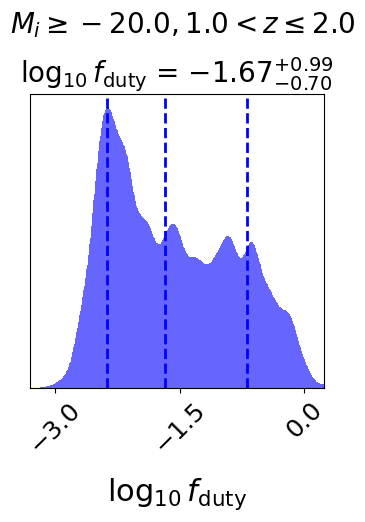

In [297]:
# # initialize figure
fig, axes = plt.subplots(1, 1, figsize=(5, 5))

# plot initial run (res1; left)
fg, ax = dyplot.cornerplot(results_fduty, color='blue', show_titles=True, title_quantiles = quantile,
                           max_n_ticks=3, quantiles=quantile, labels=labels_fduty, fig=(fig, axes))
fig.suptitle('$M_i\geq{}, {:.1f}<z \leq{:.1f}$'.format(L_bins[i], z_bins[j], z_bins[j+1]), fontsize = 20, y = 1.05, x = 0.6)

## Across all $z$

In [146]:
dN_dz_norm, H0_c_dN_dz_norm = {L: [] for L in L_bins}, {L: [] for L in L_bins}
for i in range(len(L_bins)):
    for j in z_array:
        
        tab_datahi_mask_zbin0, tab_randhi_mask_zbin0, key_zbin0, _, _, _, selfunc_hi_bin0, _, _ = quaia.make_bins(
            G_hi, [j, i], True, ['z', 'L'], bins = [z_bins, L_bins], tab_gcat_type = 'data', method = ['minmax', 'max'], fac_rand = fac_rand, 
            n_bins = [None, None], b = b, mask_type = 'b', verbose = False)
        
        dN_dz = np.sum(stats.norm.pdf(dz[None, :], loc=tab_datahi_mask_zbin0['redshift_quaia'][:, None], scale=tab_datahi_mask_zbin0['redshift_quaia_err'][:, None]), axis = 0)
        dN_dz /= np.sum(stats.norm.cdf(dz[-1], loc=tab_datahi_mask_zbin0['redshift_quaia'], scale=tab_datahi_mask_zbin0['redshift_quaia_err']))
        
        dN_dz_norm[L_bins[i]].append(dN_dz)
        H0_c_dN_dz_norm[L_bins[i]].append([ccl.background.h_over_h0(cosmo_planck18, 1/(1+dz[k]))*Planck18.H0.to(1/u.s)/constants.c.to(u.Mpc/u.s)*
                                      dN_dz[k]**2 for k in range(len(dz))])

<>:39: SyntaxWarning: invalid escape sequence '\g'
<>:46: SyntaxWarning: invalid escape sequence '\g'
<>:54: SyntaxWarning: invalid escape sequence '\g'
<>:63: SyntaxWarning: invalid escape sequence '\g'
<>:39: SyntaxWarning: invalid escape sequence '\g'
<>:46: SyntaxWarning: invalid escape sequence '\g'
<>:54: SyntaxWarning: invalid escape sequence '\g'
<>:63: SyntaxWarning: invalid escape sequence '\g'
/tmp/ipykernel_13410/1093353036.py:39: SyntaxWarning: invalid escape sequence '\g'
  fig.suptitle('$M_i\geq{}, {:.1f}<z \leq{:.1f}$'.format(L_bins[i], z_bins[j], z_bins[j+1]), fontsize = 20, y = 0.9)
/tmp/ipykernel_13410/1093353036.py:46: SyntaxWarning: invalid escape sequence '\g'
  fig.suptitle('$M_i\geq{}, {:.1f}<z \leq{:.1f}$'.format(L_bins[i], z_bins[j], z_bins[j+1]), fontsize = 20, y = 1)
/tmp/ipykernel_13410/1093353036.py:54: SyntaxWarning: invalid escape sequence '\g'
  fig.suptitle('$M_i\geq{}, {:.1f}<z \leq{:.1f}$'.format(L_bins[i], z_bins[j], z_bins[j+1]), fontsize = 20, y =

M_i<=-20.0


9937it [07:56, 20.84it/s, +1000 | bound: 13 | nc: 1 | ncall: 50575 | eff(%): 22.062 | loglstar:   -inf < 38.955 <    inf | logz: 35.931 +/-  0.048 | dlogz:  0.000 >  0.001]


Summary
nlive: 1000
niter: 9937
ncall: 49575
eff(%): 22.062
logz: 35.931 +/-  0.049
0.0<z<=1.0
log10(M_min): 13.42 + 1.65/-0.90
Sigma: 0.72 + 0.40/-0.49

10937


9943it [07:45, 21.37it/s, +1000 | bound: 13 | nc: 1 | ncall: 49453 | eff(%): 22.585 | loglstar:   -inf < 41.361 <    inf | logz: 38.328 +/-  0.049 | dlogz:  0.000 >  0.001]


Summary
nlive: 1000
niter: 9943
ncall: 48453
eff(%): 22.585
logz: 38.328 +/-  0.049
1.0<z<=2.0
log10(M_min): 13.51 + 1.67/-1.04
Sigma: 0.69 + 0.35/-0.45

10943


... (22 outputs left out)

8867it [07:35, 19.49it/s, +1000 | bound: 12 | nc: 1 | ncall: 48349 | eff(%): 20.839 | loglstar:   -inf < 31.322 <    inf | logz: 29.369 +/-  0.031 | dlogz:  0.000 >  0.001]


Summary
nlive: 1000
niter: 8867
ncall: 47349
eff(%): 20.839
logz: 29.369 +/-  0.032
2.0<z<=3.0
log10(M_min): 13.57 + 1.66/-1.28
Sigma: 0.65 + 0.29/-0.41

9867


7923it [07:17, 18.11it/s, +1000 | bound: 10 | nc: 1 | ncall: 46649 | eff(%): 19.547 | loglstar:   -inf < 16.854 <    inf | logz: 15.844 +/-  0.016 | dlogz:  0.000 >  0.001]


Summary
nlive: 1000
niter: 7923
ncall: 45649
eff(%): 19.547
logz: 15.844 +/-  0.016
3.0<z<=4.6
log10(M_min): 12.78 + 2.12/-2.30
Sigma: 0.72 + 0.41/-0.43

8923


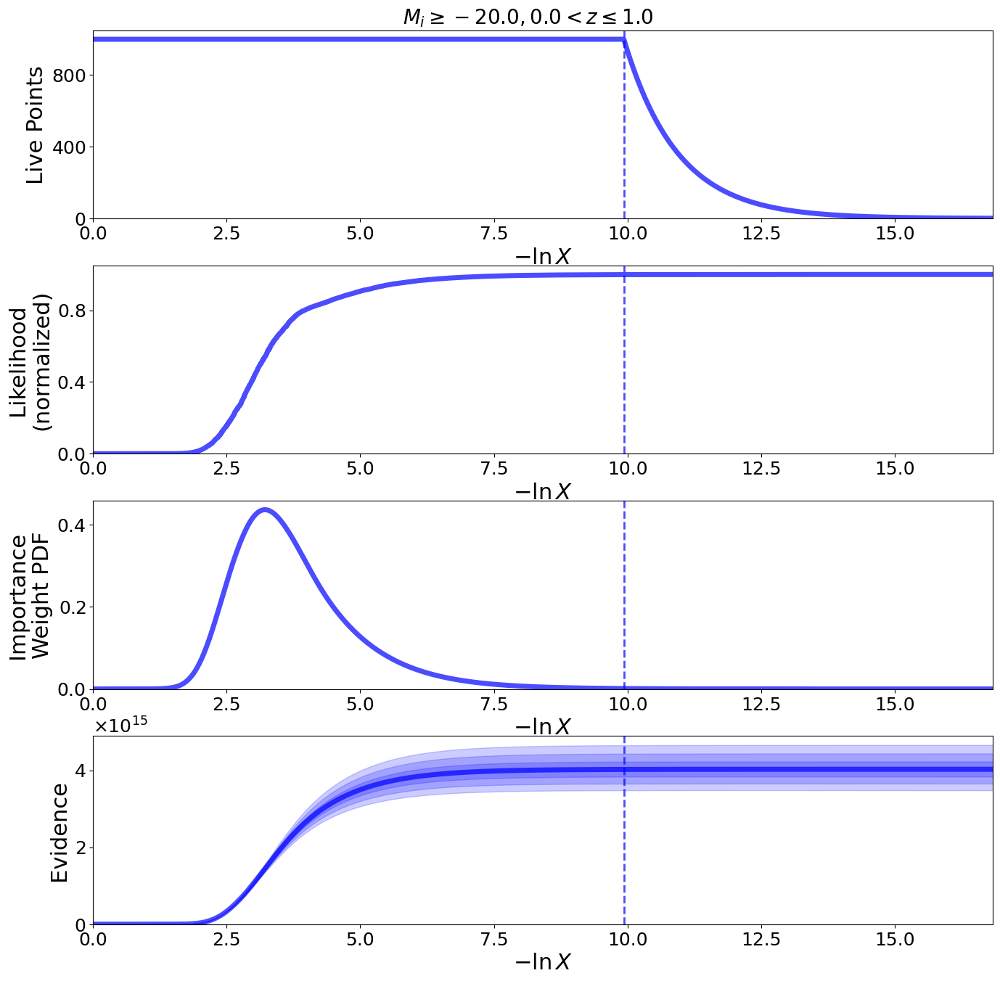

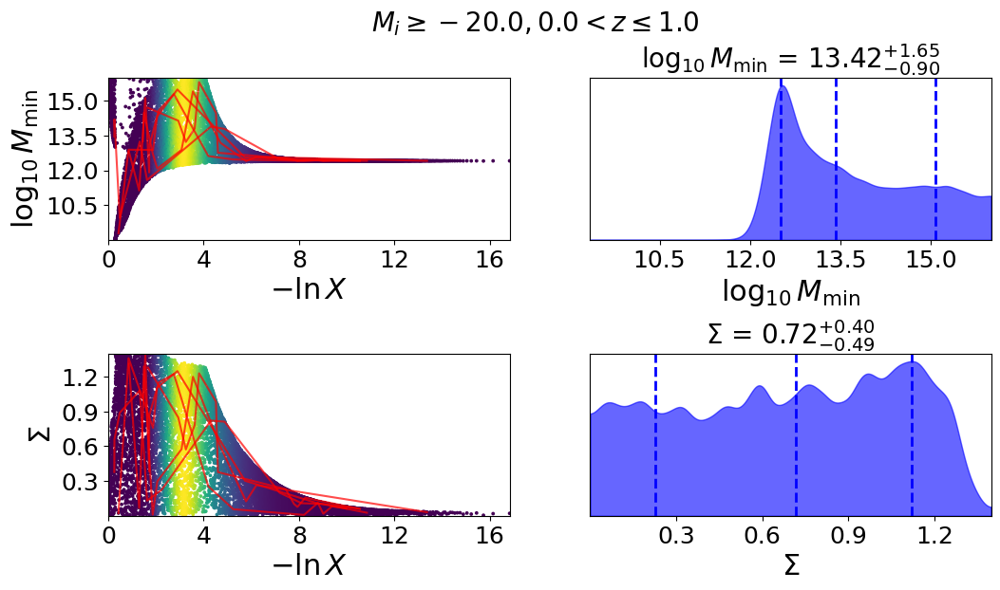

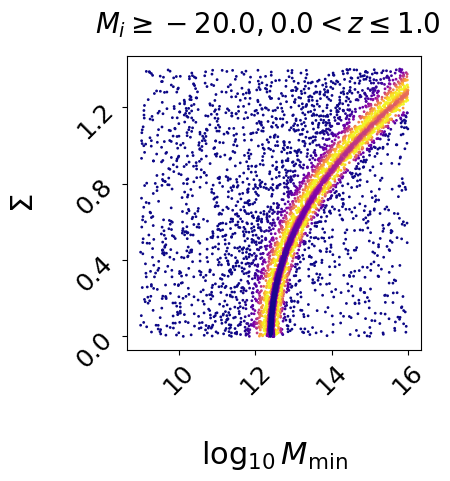

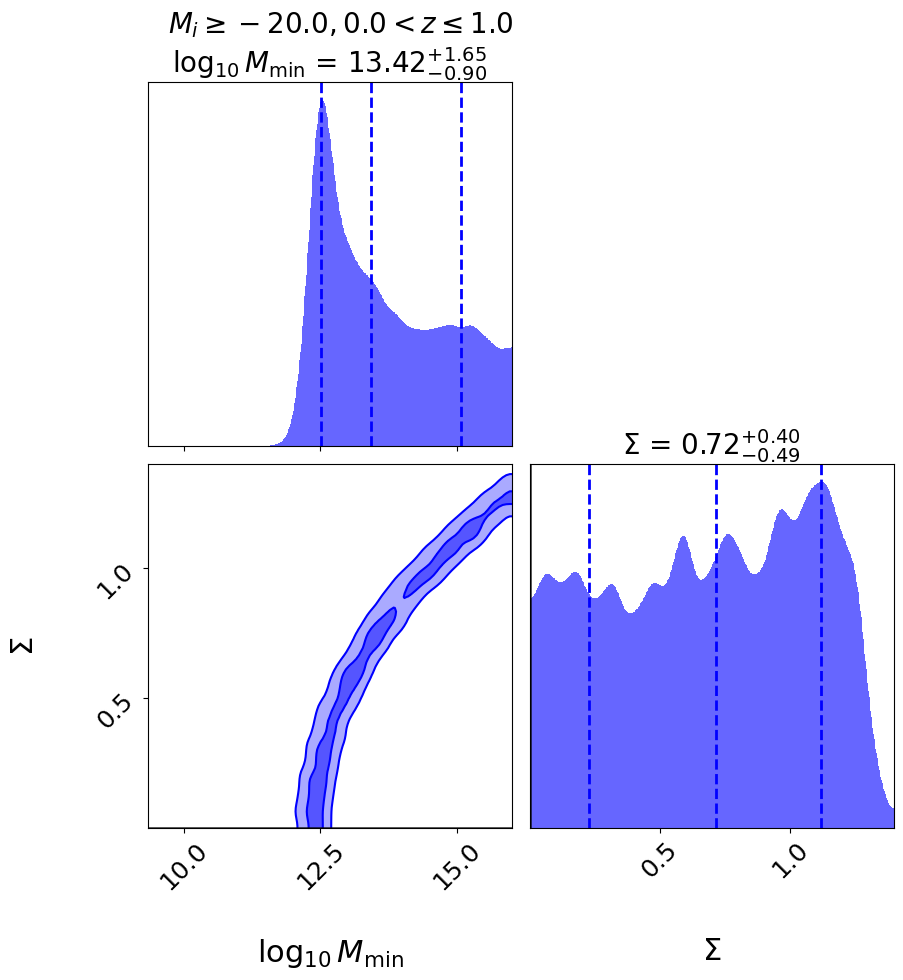

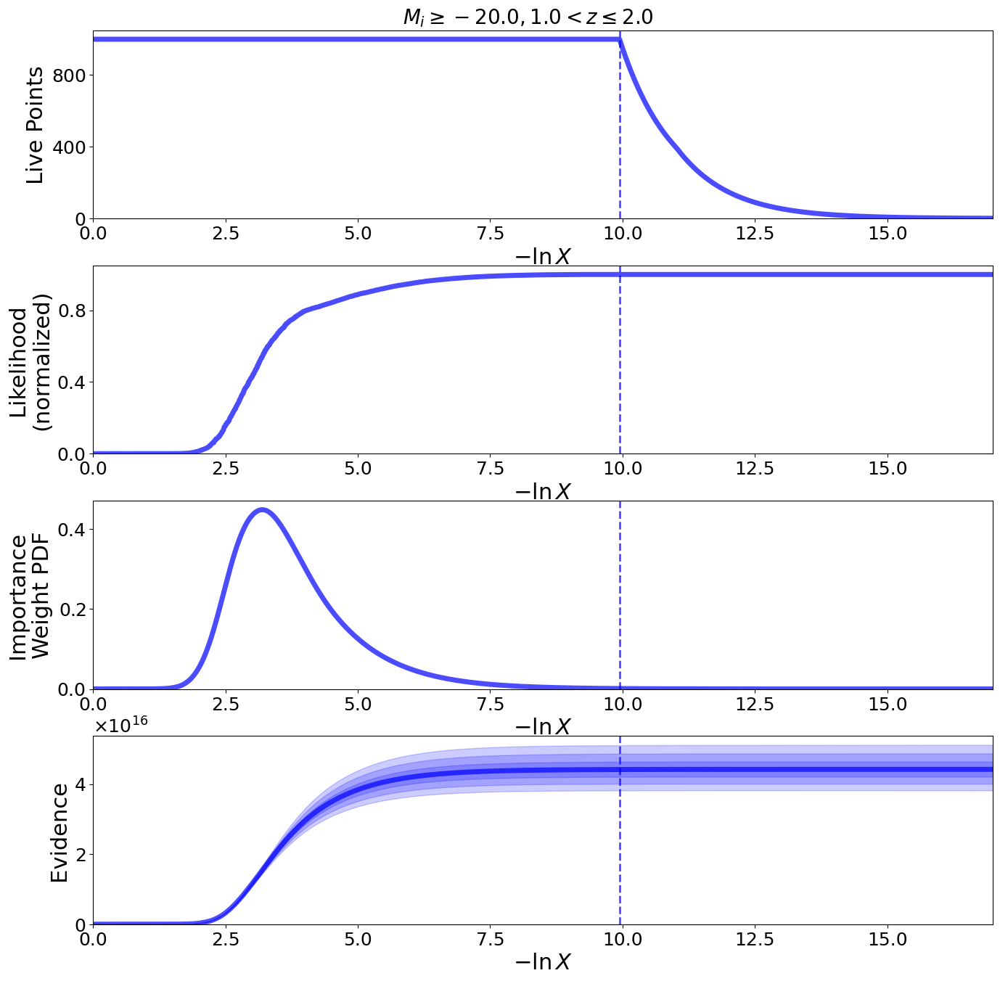

...

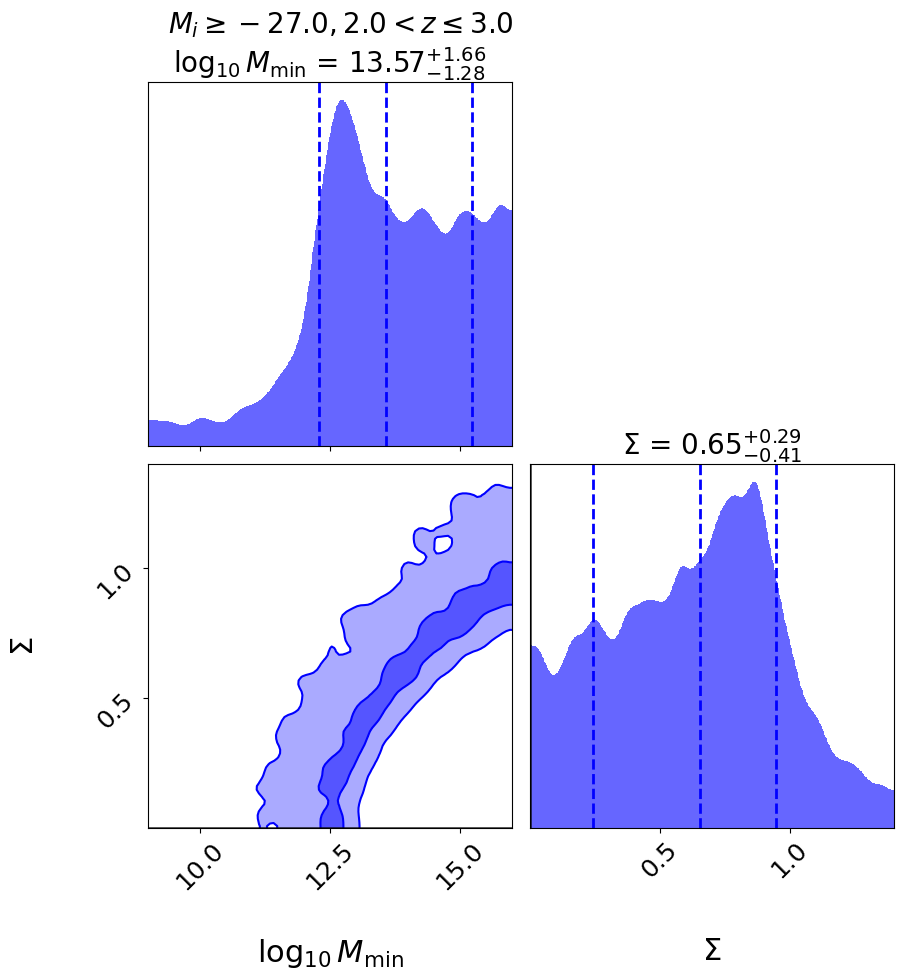

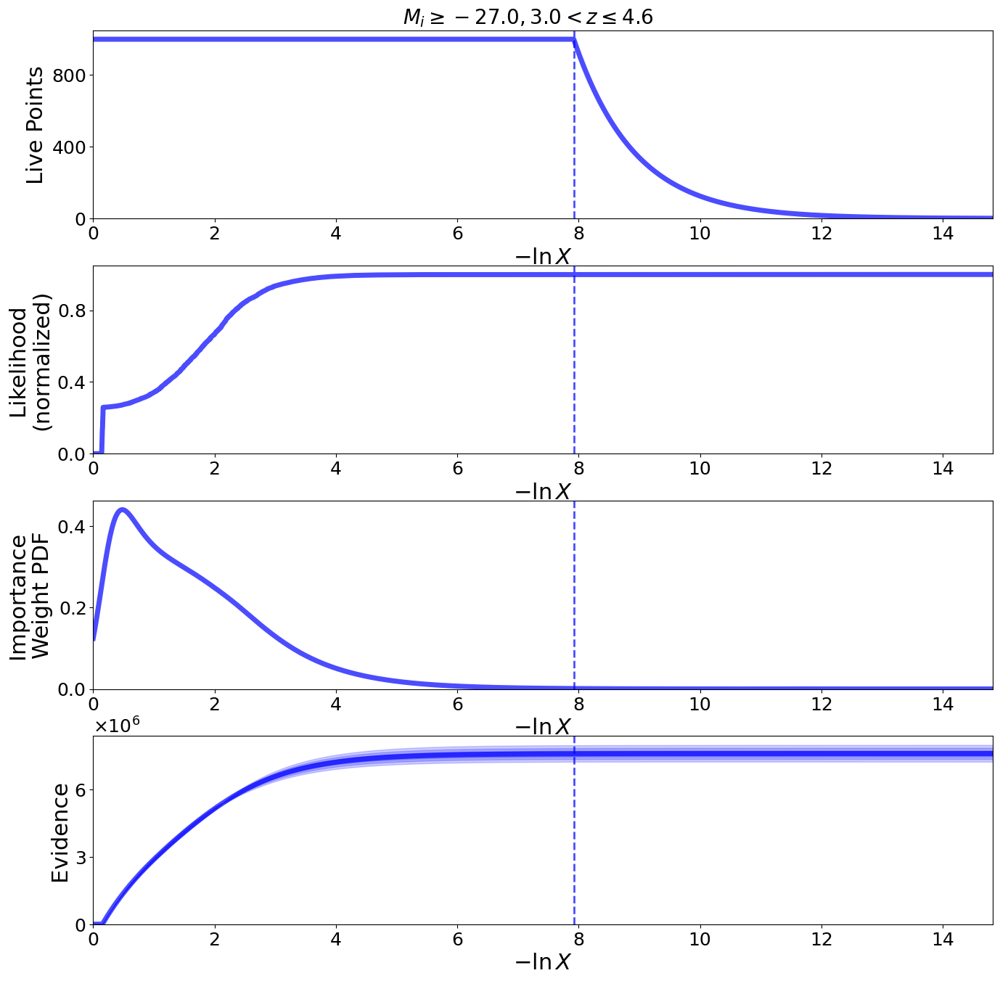

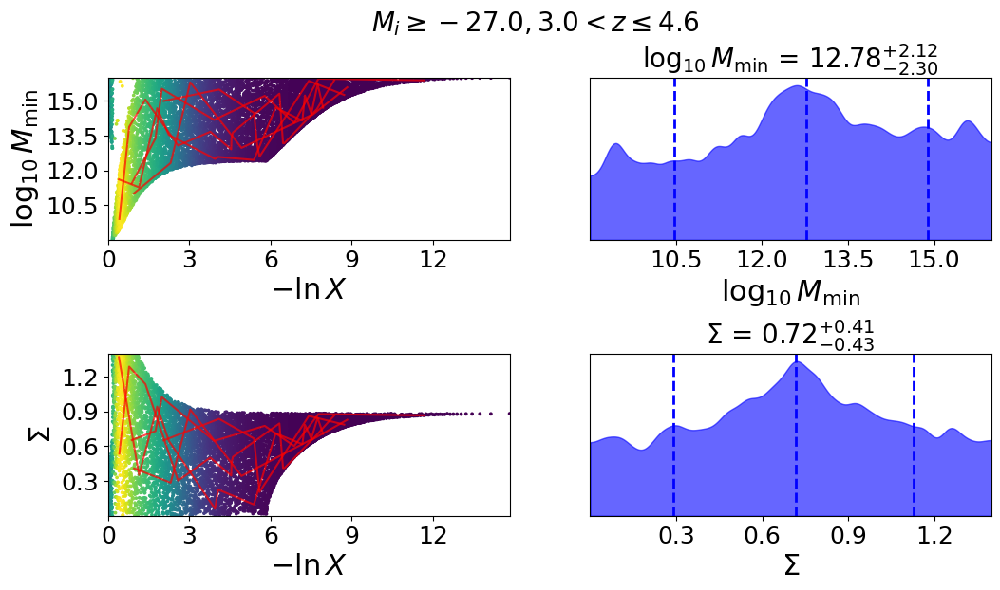

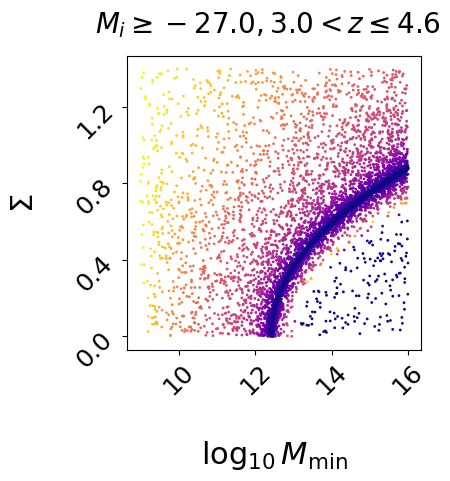

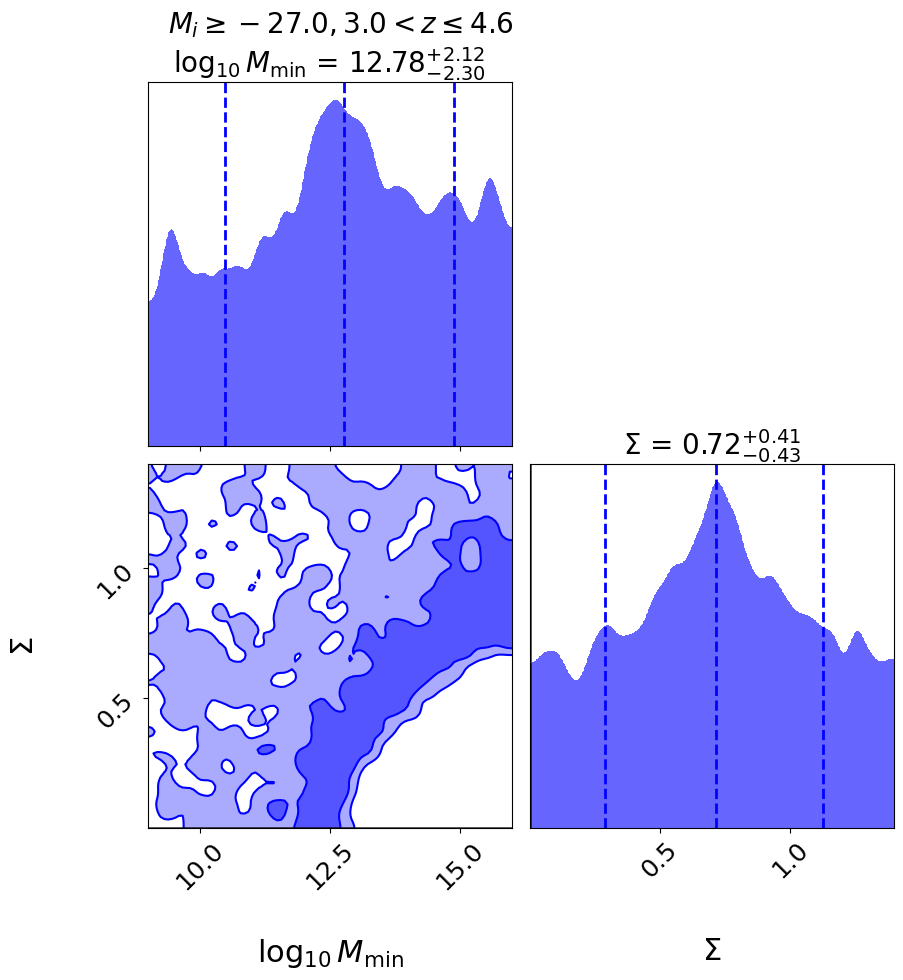

In [147]:
f_duty, M_min, Sigma = {L: [] for L in L_bins}, {L: [] for L in L_bins},  {L: [] for L in L_bins}
err_labels = ['log10(f_duty)', 'log10(M_min)', 'Sigma']
err = {i: {L: [] for L in L_bins} for i in err_labels}
f_duty_samples, M_min_samples, Sigma_samples = {L: [] for L in L_bins}, {L: [] for L in L_bins}, {L: [] for L in L_bins}
best_fit_params = {L: [] for L in L_bins}
equal_weight_samples = {L: [] for L in L_bins}
results_Mmin = {L: [] for L in L_bins}
# rstate=np.random.default_rng(0)

for i in range(len(L_bins)):

    print('M_i<={}'.format(L_bins[i]))

    for j in z_array:

        if (np.round(N_q[L_bins[i]][j]/1000)>1):

            C = np.load('../results/cov_wtheta_G{}_rmin{}_rmax{}_nbins{}_zmin{}zmax{}_Lmax{}_N{}_{}_MC_b{}.npy'.format(
                G_hi, rmin, rmax, nbins, z_bins[j], z_bins[j+1], L_bins[i], N, cosmo, b))
            if diag == True:
                C*=np.identity(len(C))
                
            log_det_C, solve = log_det(C, ix_grid)
            
            # initialize our nested sampler
            sampler = NestedSampler(loglike, ptform, ndim, logl_args=[log_det_C, wp_chi2[L_bins[i]][j][theta_mask], nbins_mask, solve, 
                                                                      H0_c_dN_dz_norm[L_bins[i]][j]], nlive = nlive, 
                                    logl_kwargs = {'theta_mask': theta_mask, 'optimize': True}, rstate=rstate)
            
            # run the sampler with checkpointing
            sampler.run_nested(dlogz = dlogz)
            results = sampler.results
            
            # Print out a summary of the results.
            results.summary()
            
            fig, axes = dyplot.runplot(results)  # summary (run) plot
            fig.subplots_adjust(hspace=0.25)
            fig.suptitle('$M_i\geq{}, {:.1f}<z \leq{:.1f}$'.format(L_bins[i], z_bins[j], z_bins[j+1]), fontsize = 20, y = 0.9)

            fig, axes = dyplot.traceplot(results, 
                                         show_titles=True,
                                         trace_cmap='viridis', connect=True,
                                         connect_highlight=range(5), labels=labels, quantiles = quantile, title_quantiles = quantile)
            fig.subplots_adjust(hspace=0.7)
            fig.suptitle('$M_i\geq{}, {:.1f}<z \leq{:.1f}$'.format(L_bins[i], z_bins[j], z_bins[j+1]), fontsize = 20, y = 1)
        
            # initialize figure
            fig, axes = plt.subplots(1, 1, figsize=(5, 5))
            
            # plot initial run (res1; left)
            fg, ax = dyplot.cornerpoints(results, cmap='plasma',
                                         kde=False, labels=labels, fig=(fig, axes))
            fig.suptitle('$M_i\geq{}, {:.1f}<z \leq{:.1f}$'.format(L_bins[i], z_bins[j], z_bins[j+1]), fontsize = 20, y = 0.975, x = 0.575)

            # # initialize figure
            fig, axes = plt.subplots(2, 2, figsize=(10, 10))
            
            # plot initial run (res1; left)
            fg, ax = dyplot.cornerplot(results, color='blue', truths=np.zeros(ndim), hist2d_kwargs = {'contourf_kwargs': contourf_kwargs}, quantiles_2d = quantile_2d, title_quantiles = quantile,
                                       truth_color='black', show_titles=True,
                                       max_n_ticks=3, quantiles=quantile, labels=labels, fig=(fig, axes[:, :2]))
            fig.suptitle('$M_i\geq{}, {:.1f}<z \leq{:.1f}$'.format(L_bins[i], z_bins[j], z_bins[j+1]), fontsize = 20, y = 1, x = 0.375)

            samples, weights = results.samples, results.importance_weights()
        
            # Get median and 1-sigma (16th, 50th, 84th percentiles) for each parameter
            quantiles = [dyfunc.quantile(samples[:, i], quantile, weights=weights) 
                         for i in range(samples.shape[1])]
        
            print('{:.1f}<z<={:.1f}'.format(z_bins[j], z_bins[j+1]))
            for k, (lo, mid, hi) in enumerate(quantiles):
                # k = -1
                print(f"{err_labels[k+1]}: {mid:.2f} + {hi-mid:.2f}/-{mid-lo:.2f}")
                err[err_labels[k+1]][L_bins[i]].append((lo, hi))
            print()
            
            equal_weight_samples[L_bins[i]].append(dyfunc.resample_equal(samples, weights))
            # ind = rstate.choice(range(len(equal_weight_samples[L_bins[i]][j])), size = 1000, replace = False)

            M_min_sample = equal_weight_samples[L_bins[i]][j][:,0] #[ind]
            Sigma_sample = equal_weight_samples[L_bins[i]][j][:,1] #[ind]
            
            M_min_median = quantiles[0][1]
            Sigma_median = quantiles[1][1]
            
            # Get the maximum likelihood sample from dynesty results
            idx_max = np.argmax(results.logl)
            best_fit_param = samples[idx_max]

            print(len(equal_weight_samples[L_bins[i]][j]))
            
        else:

            equal_weight_samples[L_bins[i]].append(np.nan)
            
            M_min_sample = [np.nan] #[np.nan]*1000
            Sigma_sample = [np.nan] #[np.nan]*1000
            
            M_min_median = np.nan
            Sigma_median = np.nan

            err[err_labels[1]][L_bins[i]].append((np.nan, np.nan))
            err[err_labels[2]][L_bins[i]].append((np.nan, np.nan))

            best_fit_param = [np.nan]*ndim

            results = np.nan
            
        M_min_samples[L_bins[i]].append(M_min_sample)
        Sigma_samples[L_bins[i]].append(Sigma_sample)
        
        M_min[L_bins[i]].append(M_min_median) 
        Sigma[L_bins[i]].append(Sigma_median) 

        # Get the maximum likelihood sample from dynesty results
        best_fit_params[L_bins[i]].append(best_fit_param)

        results_Mmin[L_bins[i]].append(results)

<>:8: SyntaxWarning: invalid escape sequence '\g'
<>:8: SyntaxWarning: invalid escape sequence '\g'
/tmp/ipykernel_13410/3023432939.py:8: SyntaxWarning: invalid escape sequence '\g'
  plt.title('$M_i\geq{}, {:.1f}<z \leq{:.1f}$'.format(L_bins[i], z_bins[j], z_bins[j+1]))


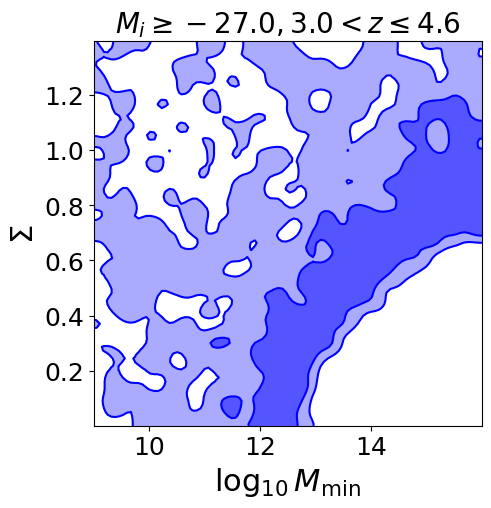

In [148]:
# # initialize figure
fig, axes = plt.subplots(1, 1, figsize=(5, 5))

# plot initial run (res1; left)
dyplot._hist2d(M_min_samples[L_bins[i]][j], Sigma_samples[L_bins[i]][j], color='blue', levels = quantile_2d, contourf_kwargs = contourf_kwargs) #, truths=np.zeros(ndim),
                           # truth_color='black', show_titles=True,
                           # max_n_ticks=3, quantiles=None, labels=labels, fig=(fig, axes[:, :3]))
plt.title('$M_i\geq{}, {:.1f}<z \leq{:.1f}$'.format(L_bins[i], z_bins[j], z_bins[j+1]))
plt.xlabel(labels[0])
plt.ylabel(labels[1])
plt.show()

In [149]:
cmap_purple = plt.get_cmap('Purples')(np.linspace(0.333, 0.999, len(z_array)))

<>:40: SyntaxWarning: invalid escape sequence '\l'
<>:40: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_13410/4243690091.py:40: SyntaxWarning: invalid escape sequence '\l'
  ax1.set_title('$M_i\leq{}$'.format(L_bins[i]))


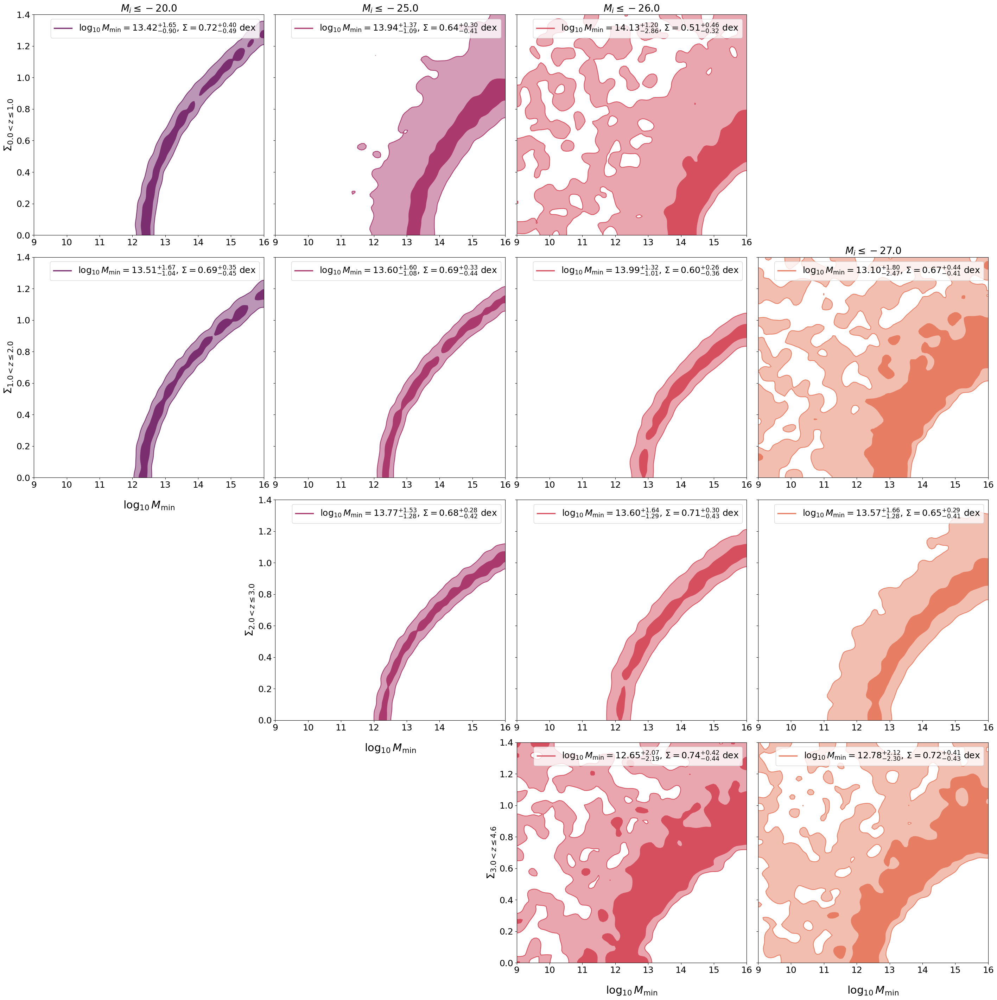

In [150]:
# remove bottom panel and just print bq somewhere
# plot!
fig = plt.figure(figsize = (35, 35))
gs = gridspec.GridSpec(4, 4, wspace = 0.05, hspace = 0.1)

for j in range(len(z_array)):
    
    for i in range(len(L_bins)):

        if (((i<3) and (N_q[L_bins[i]][j]>N_q[L_bins[i+1]][j])) or (i==3)) and (np.round(N_q[L_bins[i]][j]/1000)>1):

            ax1 = fig.add_subplot(gs[j*4+i])

            # --- corner plot -> buffer -> master cell ---
            # fg, ax = dyplot.cornerplot(results_Mmin[L_bins[i]][j], color=cmap_theta[i], show_titles=False, quantiles=[0.16,0.5,0.84],
            #                            fig=(fig, ax1), labels = ['$\log_{10}(M_\mathrm{min}/M_\odot)$'])#, cmap_purple[::-1][i]

            samples, weights = results_Mmin[L_bins[i]][j].samples, results_Mmin[L_bins[i]][j].importance_weights()
            # equal_weight_sample = dyfunc.resample_equal(samples, weights)
            # M_min_sample = equal_weight_sample[:,0]
            # Sigma_sample = equal_weight_sample[:,1]
            
            contourf_kwargs = {'colors': make_contour_cmap(cmap_theta[i], len(quantile_2d))}
            contour_kwargs = {'colors': [cmap_theta[i]]}
            # dyplot._hist2d(M_min_sample, Sigma_sample, color=cmap_theta[i], levels = quantile_2d, contourf_kwargs = contourf_kwargs) #color=cmap_theta[i]
            dyplot._hist2d(M_min_samples[L_bins[i]][j], Sigma_samples[L_bins[i]][j], contour_kwargs = contour_kwargs, levels = quantile_2d, contourf_kwargs = contourf_kwargs) #color=cmap_theta[i]
            
            # lines=ax1.get_lines()
            # for line in lines:
            #     line.set_linewidth(2.5)
            # lines[0].set_linestyle('--')
            # lines[1].set_linestyle('-')
            # lines[2].set_linestyle('--')
            # ylim=ax1.get_ylim()

            ax1.set_xlim(9, 16)
            ax1.set_ylim(0,1.4)
            # titles & labels
            if j==0 or ((j == 1) and (i == 3)):
                ax1.set_title('$M_i\leq{}$'.format(L_bins[i]))
            if i==0 or ((j>1) and (i<3) and (i!=j)):
                    ax1.set_ylabel(r"{}$_{{{:.1f}<z\leq{:.1f}}}$".format(labels[1],
                        z_bins[j], z_bins[j+1]))
            else:
                    ax1.set_yticklabels([])
            ax1.set_xlabel(labels[0])
            plt.setp(ax1.get_xticklabels(), rotation=0, ha='center')
            # ... rest of your existing sample/quantile code ...
            
            # Get median and 1-sigma (16th, 50th, 84th percentiles) for each parameter
            quantiles = [dyfunc.quantile(samples[:, k], quantile, weights=weights) 
                         for k in range(samples.shape[1])]
            
            legend=[]
            for k, (lo, mid, hi) in enumerate(quantiles):
                legend.append(f"{labels[k]}$={mid:.2f}^{{+{hi-mid:.2f}}}_{{-{mid-lo:.2f}}}$")

            custom_lines = [Line2D([0], [0], color = cmap_theta[i], linestyle = '-', linewidth=2.5)]
            ax1.legend(handles=custom_lines, labels=['{}, {} dex'.format(legend[0],legend[1])])
            ax1.xaxis.set_label_coords(0.5, -0.1)
            
# fig.savefig('../figures/cornerplot_Mmin_b{}_wtheta.pdf'.format(b), bbox_inches='tight')
plt.show()

<>:29: SyntaxWarning: invalid escape sequence '\l'
<>:29: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_13410/2528600508.py:29: SyntaxWarning: invalid escape sequence '\l'
  ax1.set_title('$M_i\leq{}$'.format(L_bins[i]))


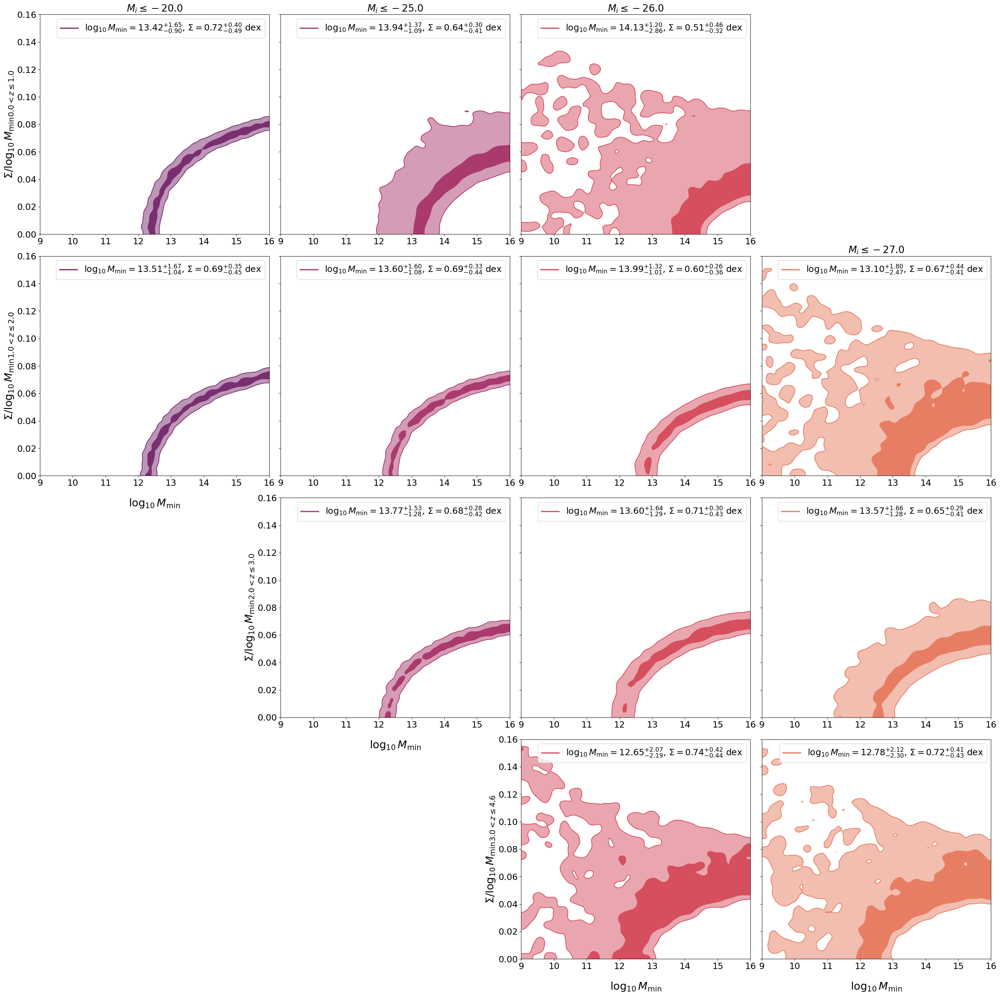

In [151]:
# remove bottom panel and just print bq somewhere
# plot!
fig = plt.figure(figsize = (35, 35))
gs = gridspec.GridSpec(4, 4, wspace = 0.05, hspace = 0.1)

for j in range(len(z_array)):
    
    for i in range(len(L_bins)):

        if (((i<3) and (N_q[L_bins[i]][j]>N_q[L_bins[i+1]][j])) or (i==3)) and (np.round(N_q[L_bins[i]][j]/1000)>1):

            ax1 = fig.add_subplot(gs[j*4+i])

            samples, weights = results_Mmin[L_bins[i]][j].samples, results_Mmin[L_bins[i]][j].importance_weights()
            # equal_weight_sample = dyfunc.resample_equal(samples, weights)
            # M_min_sample = equal_weight_sample[:,0]
            # Sigma_sample = equal_weight_sample[:,1]
            
            # --- corner plot -> buffer -> master cell 
            contourf_kwargs = {'colors': make_contour_cmap(cmap_theta[i], len(quantile_2d))}
            contour_kwargs = {'colors': [cmap_theta[i]]}
            # dyplot._hist2d(M_min_sample, Sigma_sample/M_min_sample, color=cmap_theta[i], levels = quantile_2d, contourf_kwargs = contourf_kwargs)
            dyplot._hist2d(M_min_samples[L_bins[i]][j], Sigma_samples[L_bins[i]][j]/M_min_samples[L_bins[i]][j], contour_kwargs = contour_kwargs, levels = quantile_2d, contourf_kwargs = contourf_kwargs)

            ax1.set_xlim(9, 16)
            ax1.set_ylim(0,0.16)
            # titles & labels
            if j==0 or ((j == 1) and (i == 3)):
                ax1.set_title('$M_i\leq{}$'.format(L_bins[i]))
            if i==0 or ((j>1) and (i<3) and (i!=j)):
                    ax1.set_ylabel(r"{}/{}$_{{{:.1f}<z\leq{:.1f}}}$".format(labels[1],labels[0],
                        z_bins[j], z_bins[j+1]))
            else:
                    ax1.set_yticklabels([])
            ax1.set_xlabel(labels[0])
            plt.setp(ax1.get_xticklabels(), rotation=0, ha='center')
            # ... rest of your existing sample/quantile code ...
            
            # Get median and 1-sigma (16th, 50th, 84th percentiles) for each parameter
            quantiles = [dyfunc.quantile(samples[:, k], quantile, weights=weights) 
                         for k in range(samples.shape[1])]
            
            legend=[]
            for k, (lo, mid, hi) in enumerate(quantiles):
                legend.append(f"{labels[k]}$={mid:.2f}^{{+{hi-mid:.2f}}}_{{-{mid-lo:.2f}}}$")

            custom_lines = [Line2D([0], [0], color = cmap_theta[i], linestyle = '-', linewidth=2.5)]
            ax1.legend(handles=custom_lines, labels=['{}, {} dex'.format(legend[0],legend[1])])
            ax1.xaxis.set_label_coords(0.5, -0.1)
            
# fig.savefig('../figures/cornerplot_Mmin_b{}_wtheta.pdf'.format(b), bbox_inches='tight')
plt.show()

<>:29: SyntaxWarning: invalid escape sequence '\l'
<>:29: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_13410/653977050.py:29: SyntaxWarning: invalid escape sequence '\l'
  ax1.set_title('$M_i\leq{}$'.format(L_bins[i]))


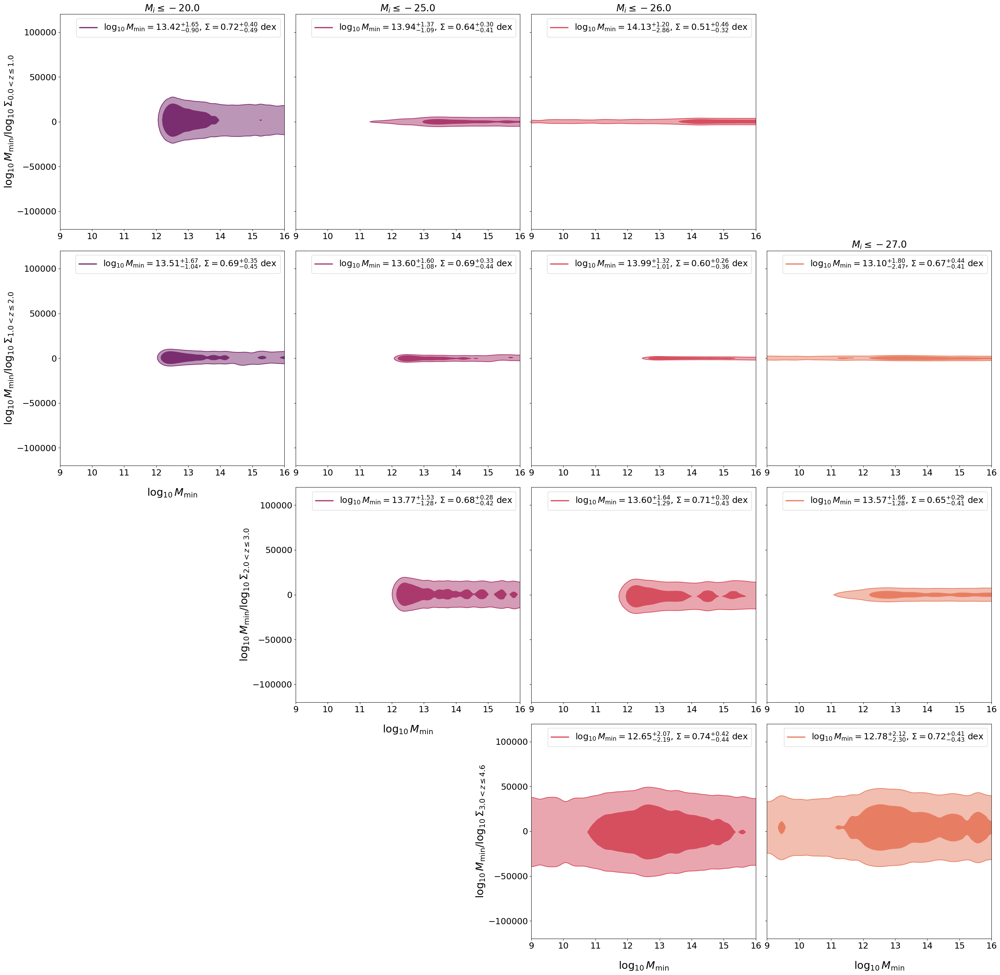

In [152]:
# remove bottom panel and just print bq somewhere
# plot!
fig = plt.figure(figsize = (35, 35))
gs = gridspec.GridSpec(4, 4, wspace = 0.05, hspace = 0.1)

for j in range(len(z_array)):
    
    for i in range(len(L_bins)):

        if (((i<3) and (N_q[L_bins[i]][j]>N_q[L_bins[i+1]][j])) or (i==3)) and (np.round(N_q[L_bins[i]][j]/1000)>1):

            ax1 = fig.add_subplot(gs[j*4+i])

            samples, weights = results_Mmin[L_bins[i]][j].samples, results_Mmin[L_bins[i]][j].importance_weights()
            # equal_weight_sample = dyfunc.resample_equal(samples, weights)
            # M_min_sample = equal_weight_sample[:,0]
            # Sigma_sample = equal_weight_sample[:,1]
            
            # --- corner plot -> buffer -> master cell ---
            contourf_kwargs = {'colors': make_contour_cmap(cmap_theta[i], len(quantile_2d))}
            contour_kwargs = {'colors': [cmap_theta[i]]}
            # dyplot._hist2d(M_min_sample, M_min_sample/np.log10(Sigma_sample), color=cmap_theta[i], levels = quantile_2d, contourf_kwargs = contourf_kwargs)
            dyplot._hist2d(M_min_samples[L_bins[i]][j], M_min_samples[L_bins[i]][j]/np.log10(Sigma_samples[L_bins[i]][j]), contour_kwargs = contour_kwargs, levels = quantile_2d, contourf_kwargs = contourf_kwargs)

            ax1.set_xlim(9, 16)
            ax1.set_ylim(-120000, 120000)
            # titles & labels
            if j==0 or ((j == 1) and (i == 3)):
                ax1.set_title('$M_i\leq{}$'.format(L_bins[i]))
            if i==0 or ((j>1) and (i<3) and (i!=j)):
                    ax1.set_ylabel(r"{}$/\log_{{10}}${}$_{{{:.1f}<z\leq{:.1f}}}$".format(labels[0],labels[1],
                        z_bins[j], z_bins[j+1]))
            else:
                    ax1.set_yticklabels([])
            ax1.set_xlabel(labels[0])
            plt.setp(ax1.get_xticklabels(), rotation=0, ha='center')
            # ... rest of your existing sample/quantile code ...

            # samples, weights = results_Mmin[L_bins[i]][j].samples, results_Mmin[L_bins[i]][j].importance_weights()

            # Get median and 1-sigma (16th, 50th, 84th percentiles) for each parameter
            quantiles = [dyfunc.quantile(samples[:, k], quantile, weights=weights) 
                         for k in range(samples.shape[1])]
            
            legend=[]
            for k, (lo, mid, hi) in enumerate(quantiles):
                legend.append(f"{labels[k]}$={mid:.2f}^{{+{hi-mid:.2f}}}_{{-{mid-lo:.2f}}}$")

            custom_lines = [Line2D([0], [0], color = cmap_theta[i], linestyle = '-', linewidth=2.5)]
            ax1.legend(handles=custom_lines, labels=['{}, {} dex'.format(legend[0],legend[1])])
            ax1.xaxis.set_label_coords(0.5, -0.1)
            
# fig.savefig('../figures/cornerplot_Mmin_b{}_wtheta.pdf'.format(b), bbox_inches='tight')
plt.show()

<>:29: SyntaxWarning: invalid escape sequence '\l'
<>:29: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_13410/1352632097.py:29: SyntaxWarning: invalid escape sequence '\l'
  ax1.set_title('$M_i\leq{}$'.format(L_bins[i]))


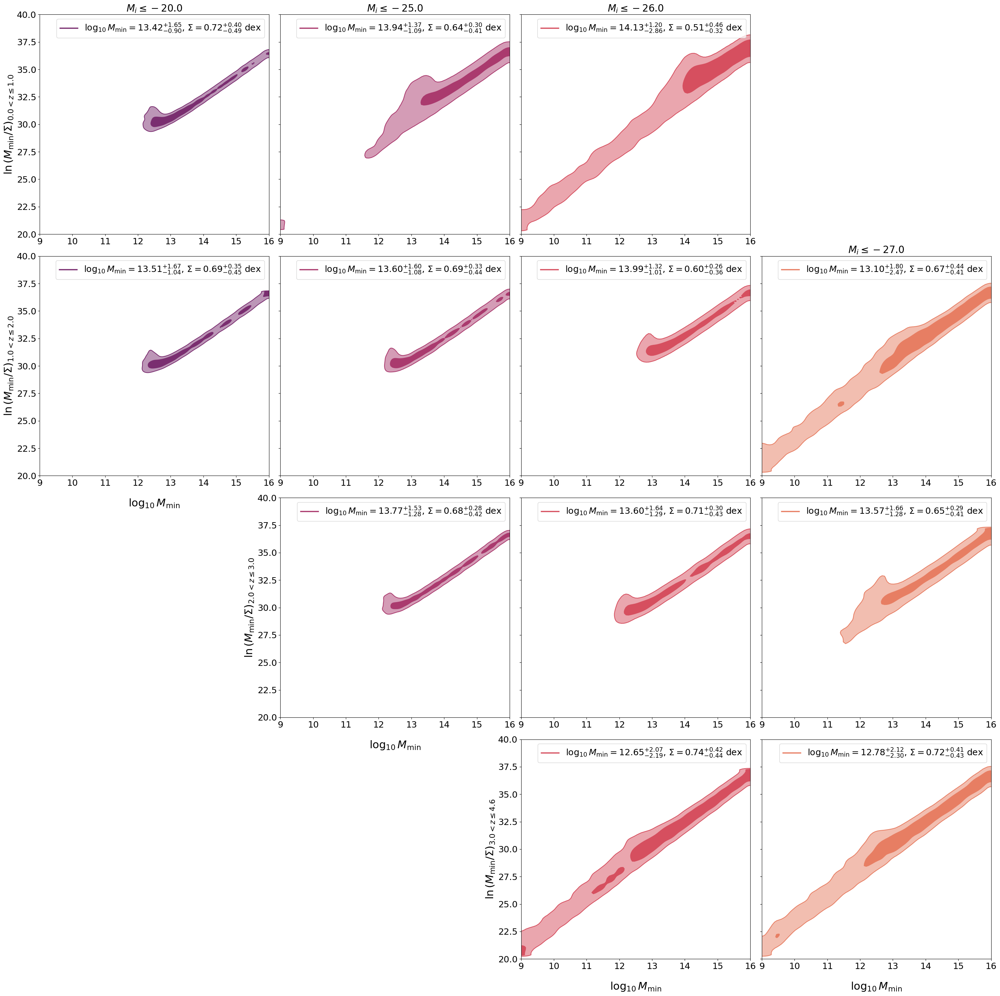

In [153]:
# remove bottom panel and just print bq somewhere
# plot!
fig = plt.figure(figsize = (35, 35))
gs = gridspec.GridSpec(4, 4, wspace = 0.05, hspace = 0.1)

for j in range(len(z_array)):
    
    for i in range(len(L_bins)):

        if (((i<3) and (N_q[L_bins[i]][j]>N_q[L_bins[i+1]][j])) or (i==3)) and (np.round(N_q[L_bins[i]][j]/1000)>1):

            ax1 = fig.add_subplot(gs[j*4+i])

            samples, weights = results_Mmin[L_bins[i]][j].samples, results_Mmin[L_bins[i]][j].importance_weights()
            # equal_weight_sample = dyfunc.resample_equal(samples, weights)
            # M_min_sample = equal_weight_sample[:,0]
            # Sigma_sample = equal_weight_sample[:,1]
            
            # --- corner plot -> buffer -> master cell ---
            contourf_kwargs = {'colors': make_contour_cmap(cmap_theta[i], len(quantile_2d))}
            contour_kwargs = {'colors': [cmap_theta[i]]}
            dyplot._hist2d(M_min_samples[L_bins[i]][j], np.log(10**M_min_samples[L_bins[i]][j]/Sigma_samples[L_bins[i]][j]), contour_kwargs = contour_kwargs, levels = quantile_2d, contourf_kwargs = contourf_kwargs)
            # dyplot._hist2d(M_min_sample, np.log(10**M_min_sample/Sigma_sample), color=cmap_theta[i], levels = quantile_2d, contourf_kwargs = contourf_kwargs)

            ax1.set_xlim(9, 16)
            ax1.set_ylim(20,40) #28, 40
            # titles & labels
            if j==0 or ((j == 1) and (i == 3)):
                ax1.set_title('$M_i\leq{}$'.format(L_bins[i]))
            if i==0 or ((j>1) and (i<3) and (i!=j)):
                    ax1.set_ylabel(r"$\ln \left(M_\mathrm{{min}}/\Sigma\right)_{{{:.1f}<z\leq{:.1f}}}$".format(z_bins[j], z_bins[j+1]))
            else:
                    ax1.set_yticklabels([])
            ax1.set_xlabel(labels[0])
            plt.setp(ax1.get_xticklabels(), rotation=0, ha='center')
            # ... rest of your existing sample/quantile code ...

            # samples, weights = results_Mmin[L_bins[i]][j].samples, results_Mmin[L_bins[i]][j].importance_weights()

            # Get median and 1-sigma (16th, 50th, 84th percentiles) for each parameter
            quantiles = [dyfunc.quantile(samples[:, k], quantile, weights=weights) 
                         for k in range(samples.shape[1])]
            
            legend=[]
            for k, (lo, mid, hi) in enumerate(quantiles):
                legend.append(f"{labels[k]}$={mid:.2f}^{{+{hi-mid:.2f}}}_{{-{mid-lo:.2f}}}$")

            custom_lines = [Line2D([0], [0], color = cmap_theta[i], linestyle = '-', linewidth=2.5)]
            ax1.legend(handles=custom_lines, labels=['{}, {} dex'.format(legend[0],legend[1])])
            ax1.xaxis.set_label_coords(0.5, -0.1)
            
# fig.savefig('../figures/cornerplot_Mmin_b{}_wtheta.pdf'.format(b), bbox_inches='tight')
plt.show()

<>:29: SyntaxWarning: invalid escape sequence '\l'
<>:29: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_13410/3320786280.py:29: SyntaxWarning: invalid escape sequence '\l'
  ax1.set_title('$M_i\leq{}$'.format(L_bins[i]))


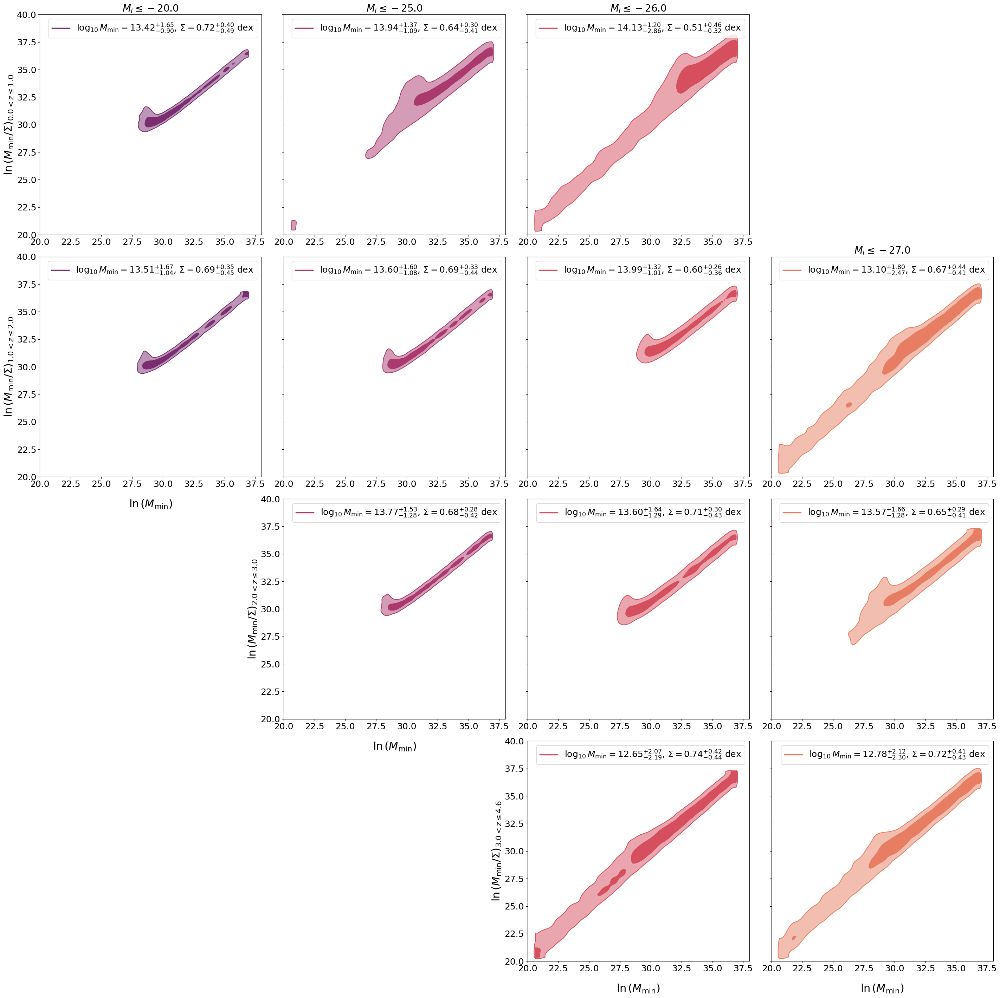

In [154]:
# remove bottom panel and just print bq somewhere
# plot!
fig = plt.figure(figsize = (35, 35))
gs = gridspec.GridSpec(4, 4, wspace = 0.1, hspace = 0.1)

for j in range(len(z_array)):
    
    for i in range(len(L_bins)):

        if (((i<3) and (N_q[L_bins[i]][j]>N_q[L_bins[i+1]][j])) or (i==3)) and (np.round(N_q[L_bins[i]][j]/1000)>1):

            ax1 = fig.add_subplot(gs[j*4+i])

            samples, weights = results_Mmin[L_bins[i]][j].samples, results_Mmin[L_bins[i]][j].importance_weights()
            # equal_weight_sample = dyfunc.resample_equal(samples, weights)
            # M_min_sample = equal_weight_sample[:,0]
            # Sigma_sample = equal_weight_sample[:,1]
            
            # --- corner plot -> buffer -> master cell ---
            contourf_kwargs = {'colors': make_contour_cmap(cmap_theta[i], len(quantile_2d))}
            contour_kwargs = {'colors': [cmap_theta[i]]}
            # dyplot._hist2d(np.log(10**M_min_sample), np.log(10**M_min_sample/Sigma_sample), color=cmap_theta[i], levels = quantile_2d, contourf_kwargs = contourf_kwargs)
            dyplot._hist2d(np.log(10**M_min_samples[L_bins[i]][j]), np.log(10**M_min_samples[L_bins[i]][j]/Sigma_samples[L_bins[i]][j]), contour_kwargs = contour_kwargs, levels = quantile_2d, contourf_kwargs = contourf_kwargs)

            ax1.set_xlim(20, 38)
            ax1.set_ylim(20,40) #28, 40
            # titles & labels
            if j==0 or ((j == 1) and (i == 3)):
                ax1.set_title('$M_i\leq{}$'.format(L_bins[i]))
            if i==0 or ((j>1) and (i<3) and (i!=j)):
                    ax1.set_ylabel(r"$\ln \left(M_\mathrm{{min}}/\Sigma\right)_{{{:.1f}<z\leq{:.1f}}}$".format(z_bins[j], z_bins[j+1]))
            else:
                    ax1.set_yticklabels([])
            ax1.set_xlabel(r"$\ln \left(M_\mathrm{{min}}\right)$")
            plt.setp(ax1.get_xticklabels(), rotation=0, ha='center')
            # ... rest of your existing sample/quantile code ...

            samples, weights = results_Mmin[L_bins[i]][j].samples, results_Mmin[L_bins[i]][j].importance_weights()

            # Get median and 1-sigma (16th, 50th, 84th percentiles) for each parameter
            quantiles = [dyfunc.quantile(samples[:, k], quantile, weights=weights) 
                         for k in range(samples.shape[1])]
            
            legend=[]
            for k, (lo, mid, hi) in enumerate(quantiles):
                legend.append(f"{labels[k]}$={mid:.2f}^{{+{hi-mid:.2f}}}_{{-{mid-lo:.2f}}}$")

            custom_lines = [Line2D([0], [0], color = cmap_theta[i], linestyle = '-', linewidth=2.5)]
            ax1.legend(handles=custom_lines, labels=['{}, {} dex'.format(legend[0],legend[1])])
            ax1.xaxis.set_label_coords(0.5, -0.1)
            
# fig.savefig('../figures/cornerplot_Mmin_b{}_wtheta.pdf'.format(b), bbox_inches='tight')
plt.show()

<>:48: SyntaxWarning: invalid escape sequence '\l'
<>:48: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_13410/1337442092.py:48: SyntaxWarning: invalid escape sequence '\l'
  ax1.set_title('$M_i\leq{}$'.format(L_bins[i]))


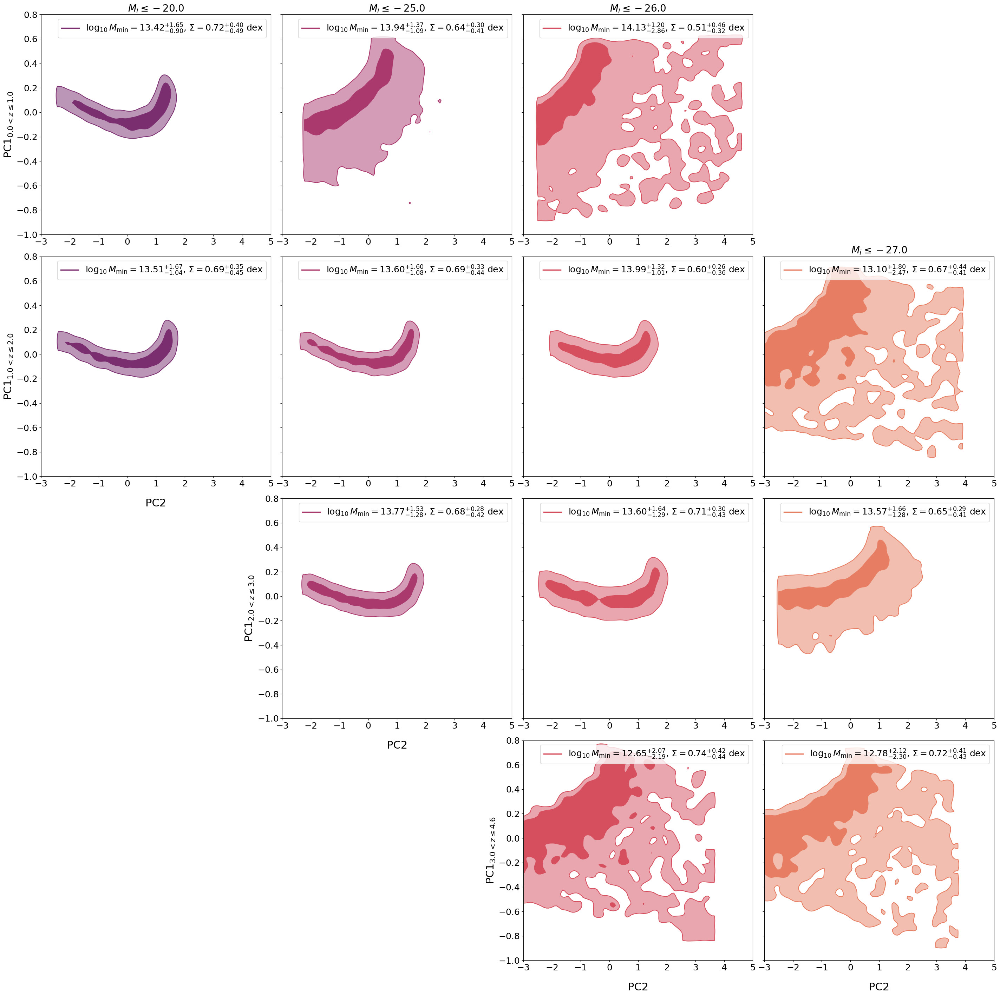

In [155]:
# remove bottom panel and just print bq somewhere
# plot!
fig = plt.figure(figsize = (35, 35))
gs = gridspec.GridSpec(4, 4, wspace = 0.05, hspace = 0.1)

for j in range(len(z_array)):
    
    for i in range(len(L_bins)):

        if (((i<3) and (N_q[L_bins[i]][j]>N_q[L_bins[i+1]][j])) or (i==3)) and (np.round(N_q[L_bins[i]][j]/1000)>1):

            ax1 = fig.add_subplot(gs[j*4+i])

            # --- corner plot -> buffer -> master cell ---
            # --- weighted PCA on (log10 M_min, Sigma) ---
            samples, weights = results_Mmin[L_bins[i]][j].samples, results_Mmin[L_bins[i]][j].importance_weights()

            w_norm = weights / np.sum(weights)

            x = samples[:, 0]   # confirm column order matches M_min
            y = samples[:, 1]
            pts = np.column_stack([x, y])
            
            mean = np.average(pts, axis=0, weights=w_norm)
            pts_centered = pts - mean
            
            # weighted covariance matrix
            cov = (pts_centered * w_norm[:, None]).T @ pts_centered
            
            eigvals, eigvecs = np.linalg.eigh(cov)   # ascending order: eigvals[0] smallest, eigvals[-1] largest
            # eigvecs[:,-1] is the direction of MAXIMUM variance (the degenerate direction)
            # eigvecs[:,0] is the direction of MINIMUM variance (the well-constrained direction)
            
            pc_well_constrained = pts_centered @ eigvecs[:, 0]
            pc_degenerate = pts_centered @ eigvecs[:, 1]
            
            # quantiles on the well-constrained combination
            pc_quantiles = dyfunc.quantile(pc_well_constrained, quantile, weights=w_norm)

            contourf_kwargs = {'colors': make_contour_cmap(cmap_theta[i], len(quantile_2d))}
            contour_kwargs = {'colors': [cmap_theta[i]]}
            dyplot._hist2d(pc_degenerate, pc_well_constrained, weights=w_norm, color=cmap_theta[i], levels = quantile_2d, contourf_kwargs = contourf_kwargs, contour_kwargs = contour_kwargs)

            ax1.set_xlim(-3, 5)
            ax1.set_ylim(-1,0.8)
            # titles & labels
            if j==0 or ((j == 1) and (i == 3)):
                ax1.set_title('$M_i\leq{}$'.format(L_bins[i]))
            if i==0 or ((j>1) and (i<3) and (i!=j)):
                ax1.set_ylabel(r"PC1$_{{{:.1f}<z\leq{:.1f}}}$".format(z_bins[j], z_bins[j+1]))
            else:
                ax1.set_yticklabels([])
            ax1.set_xlabel(r'PC2')
            plt.setp(ax1.get_xticklabels(), rotation=0, ha='center')
            # ... rest of your existing sample/quantile code ...

            # Get median and 1-sigma (16th, 50th, 84th percentiles) for each parameter
            quantiles = [dyfunc.quantile(samples[:, k], quantile, weights=weights) 
                         for k in range(samples.shape[1])]
            
            legend=[]
            for k, (lo, mid, hi) in enumerate(quantiles):
                legend.append(f"{labels[k]}$={mid:.2f}^{{+{hi-mid:.2f}}}_{{-{mid-lo:.2f}}}$")

            custom_lines = [Line2D([0], [0], color = cmap_theta[i], linestyle = '-', linewidth=2.5)]
            ax1.legend(handles=custom_lines, labels=['{}, {} dex'.format(legend[0],legend[1])])
            ax1.xaxis.set_label_coords(0.5, -0.1)
            
# fig.savefig('../figures/cornerplot_Mmin_b{}_wtheta.pdf'.format(b), bbox_inches='tight')
plt.show()

In [156]:
f_duty = {L: [] for L in L_bins}
f_duty_samples = {L: [] for L in L_bins}

for i in range(len(L_bins)):

    print('M_i<={}'.format(L_bins[i]))
    
    for j in z_array:

        if (np.round(N_q[L_bins[i]][j]/1000)>1):
        
            print('{:.1f}<z<={:.1f}'.format(z_bins[j], z_bins[j+1]))            
            # bins_m = np.logspace(equal_weight_samples[L_bins[i]][j][:,0], M_max, 79) #M_min_samples
            # n_m=np.ones(len(bins_m))
            
            n_q_theory = []
            for k in range(len(equal_weight_samples[L_bins[i]][j])):
                n_m=HOD_scatter(1, equal_weight_samples[L_bins[i]][j][:,0][k], bins, equal_weight_samples[L_bins[i]][j][:,1][k])
                n_q_theory.append(M(bins, n_m, a = a_zbin[L_bins[i]][j], cosmo = cosmo_planck18, recenter = False)[1])
            equal_weight_samples_fduty = np.log10(n_q[L_bins[i]][j]/n_q_theory)
            
            # n_dm = [M(bins_m[:,k], n_m, a = a_zbin[L_bins[i]][j], cosmo = cosmo_planck18, recenter = False)[1] for k in range(len(equal_weight_samples[L_bins[i]][j]))]
            # equal_weight_samples_fduty = np.log10(n_q[L_bins[i]][j]/n_dm)
            print('n_q: {:.1e} (h/Mpc)^3'.format(n_q[L_bins[i]][j]))
            print('n_dm: {:.1e} (h/Mpc)^3'.format(np.median(n_q_theory)))
            
            # Get median and 1-sigma (16th, 50th, 84th percentiles) for each parameter
            lo, mid, hi = dyfunc.quantile(equal_weight_samples_fduty, quantile) 
            
            print(f"{labels_fduty[0]}: {mid:.2f} + {hi-mid:.2f}/-{mid-lo:.2f}\n")
            err[err_labels[0]][L_bins[i]].append((lo, hi))

            f_duty_median = mid

            # ind = rstate.choice(range(len(equal_weight_samples_fduty)), size = np.min([len(equal_weight_samples_fduty),1000]), replace = False)
            # ind = rstate.choice(range(len(equal_weight_samples_fduty)), size = 1000, replace = False)
            f_duty_sample = equal_weight_samples_fduty #[ind]

            # # Get the maximum likelihood sample from dynesty results
            # n_q_theory = []
            # for k in range(len(best_fit_params)):
            n_m=HOD_scatter(1, best_fit_params[L_bins[i]][j][0], bins, best_fit_params[L_bins[i]][j][1])
            n_q_theory=M(bins, n_m, a = a_zbin[L_bins[i]][j], cosmo = cosmo_planck18, recenter = False)[1]
            best_fit_param = np.log10(n_q[L_bins[i]][j]/n_q_theory)
            
            # bins_m = np.logspace(best_fit_params[L_bins[i]][j][0], M_max, 79)
            # n_dm = M(bins_m, n_m, a = a_zbin[L_bins[i]][j], cosmo = cosmo_planck18, recenter = False)[1]
            # best_fit_param = np.log10(n_q[L_bins[i]][j]/n_dm)
            
        else:

            f_duty_sample = [np.nan] #[np.nan]*1000
            
            f_duty_median = np.nan

            err[err_labels[0]][L_bins[i]].append((np.nan, np.nan))

            # best_fit_param = [np.nan]*ndim
            best_fit_param = [np.nan]
            
        f_duty_samples[L_bins[i]].append(f_duty_sample)
        
        f_duty[L_bins[i]].append(f_duty_median)

        # Get the maximum likelihood sample from dynesty results
        best_fit_params[L_bins[i]][j]=np.append(best_fit_param, best_fit_params[L_bins[i]][j])

M_i<=-20.0
0.0<z<=1.0
n_q: 1.1e-05 (h/Mpc)^3
n_dm: 9.1e-04 (h/Mpc)^3
$\log_{10} f_\mathrm{duty}$: -1.93 + 0.84/-0.44

1.0<z<=2.0
n_q: 8.1e-06 (h/Mpc)^3
n_dm: 4.3e-04 (h/Mpc)^3
$\log_{10} f_\mathrm{duty}$: -1.72 + 1.04/-0.63

2.0<z<=3.0
n_q: 3.1e-06 (h/Mpc)^3
n_dm: 1.0e-04 (h/Mpc)^3
$\log_{10} f_\mathrm{duty}$: -1.52 + 1.25/-0.93

3.0<z<=4.6
n_q: 2.7e-07 (h/Mpc)^3
n_dm: 1.2e-03 (h/Mpc)^3
$\log_{10} f_\mathrm{duty}$: -3.65 + 2.31/-2.64

M_i<=-25.0
0.0<z<=1.0
n_q: 2.1e-06 (h/Mpc)^3
n_dm: 1.1e-04 (h/Mpc)^3
$\log_{10} f_\mathrm{duty}$: -1.70 + 0.99/-1.26

1.0<z<=2.0
n_q: 5.9e-06 (h/Mpc)^3
n_dm: 3.1e-04 (h/Mpc)^3
$\log_{10} f_\mathrm{duty}$: -1.72 + 1.04/-0.68

2.0<z<=3.0
n_q: 3.1e-06 (h/Mpc)^3
n_dm: 8.8e-05 (h/Mpc)^3
$\log_{10} f_\mathrm{duty}$: -1.45 + 1.20/-0.97

3.0<z<=4.6
n_q: 2.7e-07 (h/Mpc)^3
n_dm: 9.1e-04 (h/Mpc)^3
$\log_{10} f_\mathrm{duty}$: -3.52 + 2.20/-2.70

M_i<=-26.0
0.0<z<=1.0
n_q: 4.1e-07 (h/Mpc)^3
n_dm: 4.9e-05 (h/Mpc)^3
$\log_{10} f_\mathrm{duty}$: -2.07 + 1.96/-3.42

1.0<

### Solve for $\chi_c^2=\Delta^T x$ where $Cx=\Delta$

In [157]:
def f0_GLS_solve(x, a, C, wp, H0_c_dN_dz_norm, cosmo = cosmo_planck18, rpmask = True, hartlap = hartlap, fduty = 0, M_max = M_max):
    
    # M_min = x[0]
    
    # bins_m = np.logspace(M_min, M_max, 79)
    # n_m=np.ones(np.shape(bins_m))*10**fduty

    fduty, M_min, sigma = x
    n_m=HOD_scatter(10**fduty, M_min, bins_m, sigma)
    
    wp_2h_zbin = wtheta_2h_optimized(bins_m, n_m, H0_c_dN_dz_norm, recenter_bins = True)
    
    if isinstance(rpmask, bool):
        rpmask = [rpmask]*len(quaia.recenter(rpbins))
    delta = (wp-wp_2h_zbin)[rpmask]
    ix_grid = np.ix_(rpmask, rpmask)
    
    return delta.T @ (hartlap*np.linalg.solve(C[ix_grid], delta))

### Add a number density constraint

In [158]:
def constraint(x, a, n_q, cosmo = cosmo_planck18, error = 0.05, M_max = M_max, fduty = 0):
    
    # M_min = x[0]
    
    # bins_m = np.logspace(M_min, M_max, 79)
    # n_m=np.ones(np.shape(bins_m))*10**fduty

    fduty, M_min, sigma = x
    n_m=HOD_scatter(10**fduty, M_min, bins_m, sigma)
    
    n_q_theory = M(bins_m, n_m, a = a, cosmo = cosmo, recenter = False)[1]

    return error-np.abs(n_q_theory-n_q)/n_q

In [159]:
chi2_L_z = []
for i in range(len(L_bins)):

    print('M_i<={}'.format(L_bins[i]))

    chi2_z=[]
    
    for j in z_array:

        if (((i<3) and (N_q[L_bins[i]][j]>N_q[L_bins[i+1]][j])) or (i==3)) and (np.round(N_q[L_bins[i]][j]/1000)>1):
        
            print('{:.1f}<z<={:.1f}'.format(z_bins[j], z_bins[j+1]))
            x = [f_duty[L_bins[i]][j], M_min[L_bins[i]][j], Sigma[L_bins[i]][j]]
            
            C = np.load('../results/cov_wtheta_G{}_rmin{}_rmax{}_nbins{}_zmin{}zmax{}_Lmax{}_N{}_{}_MC_b{}.npy'.format(
                    G_hi, rmin, rmax, nbins, z_bins[j], z_bins[j+1], L_bins[i], N, cosmo, b))
            if diag == True:
                C*=np.identity(len(C))
            chi2 = f0_GLS_solve(x, a_zbin[L_bins[i]][j], C, wp_chi2[L_bins[i]][j], H0_c_dN_dz_norm[L_bins[i]][j], rpmask = theta_mask)
            df = nbins_mask-(len(x)-1)
        
            print('           chi^2: {:.2f}'.format(chi2))
            print('   reduced chi^2: {:.2f}'.format(chi2/df))
            print('         delta n: {:.2e}'.format(constraint(x, a_zbin[L_bins[i]][j], n_q[L_bins[i]][j], fduty = f_duty[L_bins[i]][j])))
            try:
                print('condition number: {:.2f}'.format(np.linalg.cond(C[ix_grid])))
            except Exception as e:
                print(e)
            print('             PTE: {:.2f}\n'.format(stats.chi2.sf(chi2, df)))

        else:
            chi2=np.nan

        chi2_z.append(chi2)
        
    chi2_L_z.append(chi2_z)

M_i<=-20.0
0.0<z<=1.0
           chi^2: 3.18
   reduced chi^2: 0.53
         delta n: -1.43e-01
condition number: 96.90
             PTE: 0.79

1.0<z<=2.0
           chi^2: 6.22
   reduced chi^2: 1.04
         delta n: -1.45e-01
condition number: 87.54
             PTE: 0.40

M_i<=-25.0
0.0<z<=1.0
           chi^2: 6.78
   reduced chi^2: 1.13
         delta n: -3.85e-01
condition number: 107.70
             PTE: 0.34

1.0<z<=2.0
           chi^2: 8.31
   reduced chi^2: 1.39
         delta n: -1.28e-01
condition number: 108.82
             PTE: 0.22

2.0<z<=3.0
           chi^2: 4.91
   reduced chi^2: 0.82
         delta n: -1.96e-01
condition number: 91.04
             PTE: 0.56

M_i<=-26.0
0.0<z<=1.0
           chi^2: 6.89
   reduced chi^2: 1.15
         delta n: -7.86e-03
condition number: 42.16
             PTE: 0.33

1.0<z<=2.0
           chi^2: 3.58
   reduced chi^2: 0.60
         delta n: -2.88e-02
condition number: 77.90
             PTE: 0.73

2.0<z<=3.0
           chi^2: 2.17


## Null test

In [160]:
f_duty_null = {L: [] for L in L_bins}
f_duty_samples_null = {L: [] for L in L_bins}
err_null = copy.deepcopy(err)
best_fit_params_null = copy.deepcopy(best_fit_params)

for i in range(len(L_bins)):

    print('M_i<={}'.format(L_bins[i]))
    
    for j in z_array:

        if (np.round(N_q[L_bins[i]][j]/1000)>1):
        
            print('{:.1f}<z<={:.1f}'.format(z_bins[j], z_bins[j+1]))            
            # bins_m = np.logspace(equal_weight_samples[L_bins[0]][j][:,0], M_max, 79) #M_min_samples
            # n_m=np.ones(len(bins_m))

            n_q_theory = []
            for k in range(len(equal_weight_samples[L_bins[0]][j])):
                n_m=HOD_scatter(1, equal_weight_samples[L_bins[0]][j][:,0][k], bins, equal_weight_samples[L_bins[0]][j][:,1][k])
                n_q_theory.append(M(bins, n_m, a = a_zbin[L_bins[i]][j], cosmo = cosmo_planck18, recenter = False)[1])
            equal_weight_samples_fduty = np.log10(n_q[L_bins[i]][j]/n_q_theory)
            
            # n_dm = [M(bins_m[:,k], n_m, a = a_zbin[L_bins[i]][j], cosmo = cosmo_planck18, recenter = False)[1] for k in range(len(equal_weight_samples[L_bins[0]][j]))]
            # equal_weight_samples_fduty = np.log10(n_q[L_bins[i]][j]/n_dm)
            print('n_q: {:.1e} (h/Mpc)^3'.format(n_q[L_bins[i]][j]))
            print('n_dm: {:.1e} (h/Mpc)^3'.format(np.median(n_q_theory)))
            
            # Get median and 1-sigma (16th, 50th, 84th percentiles) for each parameter
            lo, mid, hi = dyfunc.quantile(equal_weight_samples_fduty, quantile) 
            
            print(f"{labels_fduty[0]}: {mid:.2f} + {hi-mid:.2f}/-{mid-lo:.2f}\n")
            err_null[err_labels[0]][L_bins[i]].append((lo, hi))

            f_duty_median = mid

            # ind = rstate.choice(range(len(equal_weight_samples_fduty)), size = np.min([len(equal_weight_samples_fduty),1000]), replace = False)
            # ind = rstate.choice(range(len(equal_weight_samples_fduty)), size = 1000, replace = False)
            f_duty_sample = equal_weight_samples_fduty #[ind]

            # # Get the maximum likelihood sample from dynesty results
            # bins_m = np.logspace(best_fit_params_null[L_bins[0]][j][1], M_max, 79)
            # n_dm = M(bins_m, n_m, a = a_zbin[L_bins[i]][j], cosmo = cosmo_planck18, recenter = False)[1]
            # best_fit_param = np.log10(n_q[L_bins[i]][j]/n_dm)
            n_m=HOD_scatter(1, best_fit_params_null[L_bins[0]][j][0], bins, best_fit_params_null[L_bins[0]][j][1])
            n_q_theory=M(bins, n_m, a = a_zbin[L_bins[i]][j], cosmo = cosmo_planck18, recenter = False)[1]
            best_fit_param = np.log10(n_q[L_bins[i]][j]/n_q_theory)
            
        else:

            f_duty_sample = [np.nan] #[np.nan]*1000
            
            f_duty_median = np.nan

            err_null[err_labels[0]][L_bins[i]].append((np.nan, np.nan))

            best_fit_param = np.nan
            
        f_duty_samples_null[L_bins[i]].append(f_duty_sample)
        
        f_duty_null[L_bins[i]].append(f_duty_median)

        # Get the maximum likelihood sample from dynesty results
        best_fit_params_null[L_bins[i]][j][0]=best_fit_param

M_i<=-20.0
0.0<z<=1.0
n_q: 1.1e-05 (h/Mpc)^3
n_dm: 9.1e-04 (h/Mpc)^3
$\log_{10} f_\mathrm{duty}$: -1.93 + 0.84/-0.44

1.0<z<=2.0
n_q: 8.1e-06 (h/Mpc)^3
n_dm: 4.3e-04 (h/Mpc)^3
$\log_{10} f_\mathrm{duty}$: -1.72 + 1.04/-0.63

2.0<z<=3.0
n_q: 3.1e-06 (h/Mpc)^3
n_dm: 1.0e-04 (h/Mpc)^3
$\log_{10} f_\mathrm{duty}$: -1.52 + 1.25/-0.93

3.0<z<=4.6
n_q: 2.7e-07 (h/Mpc)^3
n_dm: 1.2e-03 (h/Mpc)^3
$\log_{10} f_\mathrm{duty}$: -3.65 + 2.31/-2.64

M_i<=-25.0
0.0<z<=1.0
n_q: 2.1e-06 (h/Mpc)^3
n_dm: 8.7e-04 (h/Mpc)^3
$\log_{10} f_\mathrm{duty}$: -2.62 + 0.84/-0.44

1.0<z<=2.0
n_q: 5.9e-06 (h/Mpc)^3
n_dm: 3.9e-04 (h/Mpc)^3
$\log_{10} f_\mathrm{duty}$: -1.82 + 1.04/-0.63

2.0<z<=3.0
n_q: 3.1e-06 (h/Mpc)^3
n_dm: 1.0e-04 (h/Mpc)^3
$\log_{10} f_\mathrm{duty}$: -1.52 + 1.25/-0.93

3.0<z<=4.6
n_q: 2.7e-07 (h/Mpc)^3
n_dm: 1.2e-03 (h/Mpc)^3
$\log_{10} f_\mathrm{duty}$: -3.65 + 2.31/-2.64

M_i<=-26.0
0.0<z<=1.0
n_q: 4.1e-07 (h/Mpc)^3
n_dm: 8.7e-04 (h/Mpc)^3
$\log_{10} f_\mathrm{duty}$: -3.32 + 0.84/-0.44

1.0<

In [161]:
chi2_null = []

for i in range(len(L_bins)):

    chi2_z=[]
    
    print('M_i<={}'.format(L_bins[i]))

    for j in z_array:

        if (((i<3) and (N_q[L_bins[i]][j]>N_q[L_bins[i+1]][j])) or (i==3)) and (np.round(N_q[L_bins[i]][j]/1000)>1):
        
            print('{:.1f}<z<={:.1f}'.format(z_bins[j], z_bins[j+1]))
            x = [f_duty_null[L_bins[i]][j], M_min[L_bins[0]][j], Sigma[L_bins[0]][j]]
            
            C = np.load('../results/cov_wtheta_G{}_rmin{}_rmax{}_nbins{}_zmin{}zmax{}_Lmax{}_N{}_{}_MC_b{}.npy'.format(
                    G_hi, rmin, rmax, nbins, z_bins[j], z_bins[j+1], L_bins[i], N, cosmo, b))
            if diag == True:
                C*=np.identity(len(C))
            chi2 = f0_GLS_solve(x, a_zbin[L_bins[i]][j], C, wp_chi2[L_bins[i]][j], H0_c_dN_dz_norm[L_bins[i]][j], rpmask = theta_mask) #, 
                                # fduty = f_duty_null[L_bins[i]][j])
            df = nbins_mask #-len(x)-1
        
            print('           chi^2: {:.2f}'.format(chi2))
            print('   reduced chi^2: {:.2f}'.format(chi2/df))
            print('         delta n: {:.2e}'.format(constraint(x, a_zbin[L_bins[i]][j], n_q[L_bins[i]][j]))) #, fduty = f_duty_null[L_bins[i]][j])))
            try:
                print('condition number: {:.2f}'.format(np.linalg.cond(C[ix_grid])))
            except Exception as e:
                print(e)
            print('             PTE: {:.2f}\n'.format(stats.chi2.sf(chi2, df)))

        else:
            chi2=np.nan

        chi2_z.append(chi2)
        
    chi2_null.append(chi2_z)

M_i<=-20.0
0.0<z<=1.0
           chi^2: 3.18
   reduced chi^2: 0.40
         delta n: -1.43e-01
condition number: 96.90
             PTE: 0.92

1.0<z<=2.0
           chi^2: 6.22
   reduced chi^2: 0.78
         delta n: -1.45e-01
condition number: 87.54
             PTE: 0.62

M_i<=-25.0
0.0<z<=1.0
           chi^2: 7.80
   reduced chi^2: 0.98
         delta n: -1.59e-01
condition number: 107.70
             PTE: 0.45

1.0<z<=2.0
           chi^2: 7.96
   reduced chi^2: 0.99
         delta n: -1.49e-01
condition number: 108.82
             PTE: 0.44

2.0<z<=3.0
           chi^2: 4.81
   reduced chi^2: 0.60
         delta n: -1.67e-01
condition number: 91.04
             PTE: 0.78

M_i<=-26.0
0.0<z<=1.0
           chi^2: 7.64
   reduced chi^2: 0.95
         delta n: -1.59e-01
condition number: 42.16
             PTE: 0.47

1.0<z<=2.0
           chi^2: 5.34
   reduced chi^2: 0.67
         delta n: -1.59e-01
condition number: 77.90
             PTE: 0.72

2.0<z<=3.0
           chi^2: 2.90


In [162]:
cmap_chi2 = sns.color_palette("vlag", as_cmap=True)

<>:8: SyntaxWarning: invalid escape sequence '\D'
<>:12: SyntaxWarning: invalid escape sequence '\m'
<>:8: SyntaxWarning: invalid escape sequence '\D'
<>:12: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_13410/9016772.py:8: SyntaxWarning: invalid escape sequence '\D'
  fig.colorbar(image, label = '$\Delta\chi^2$')
/tmp/ipykernel_13410/9016772.py:12: SyntaxWarning: invalid escape sequence '\m'
  ax1.set_ylabel('$M_{i,\mathrm{max}}$')


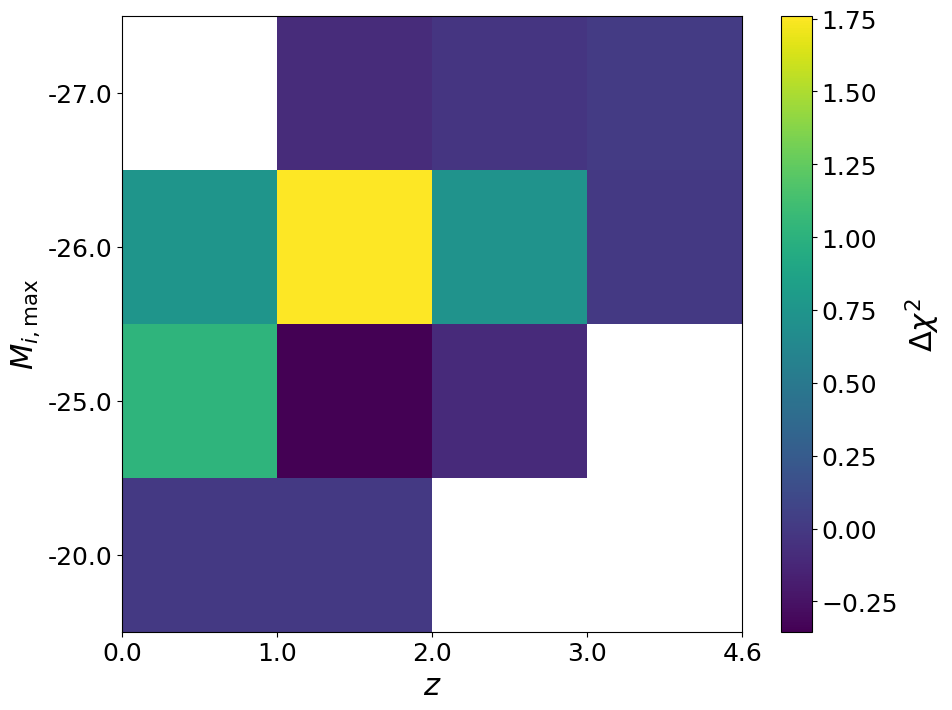

In [163]:
fig = plt.figure(figsize = (10, 8))
gs = gridspec.GridSpec(1, 1)
ax1 = fig.add_subplot(gs[0])

chi2_delta = chi2_null-np.array(chi2_L_z)
image = plt.pcolormesh(chi2_delta)

fig.colorbar(image, label = '$\Delta\chi^2$')
ax1.set_xticks(range(len(z_bins)), labels = z_bins)
ax1.set_yticks(quaia.recenter(np.array(range(len(L_array)))), labels = L_bins)
ax1.set_xlabel('$z$')
ax1.set_ylabel('$M_{i,\mathrm{max}}$')
plt.show()

<>:14: SyntaxWarning: invalid escape sequence '\D'
<>:18: SyntaxWarning: invalid escape sequence '\m'
<>:14: SyntaxWarning: invalid escape sequence '\D'
<>:18: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_13410/4002956149.py:14: SyntaxWarning: invalid escape sequence '\D'
  fig.colorbar(image, label = '$\Delta N\sigma$')
/tmp/ipykernel_13410/4002956149.py:18: SyntaxWarning: invalid escape sequence '\m'
  ax1.set_ylabel('$M_{i,\mathrm{max}}$')


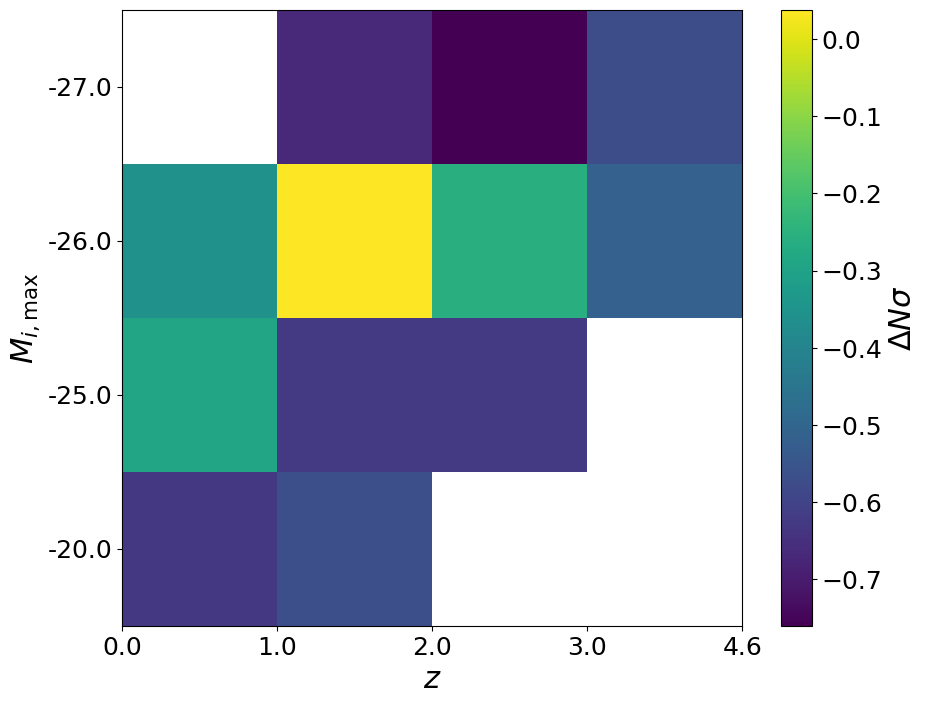

In [164]:
fig = plt.figure(figsize = (10, 8))
gs = gridspec.GridSpec(1, 1)
ax1 = fig.add_subplot(gs[0])
df_L_z = nbins_mask-ndim #-1
df_null = nbins_mask#-ndim #-1

p_value = stats.chi2.sf(chi2_null, df_null)
n_sigma_null = stats.norm.ppf(1 - p_value)

p_value = stats.chi2.sf(chi2_L_z, df_L_z)
n_sigma_L_z = stats.norm.ppf(1 - p_value)
image = plt.pcolormesh(n_sigma_null-n_sigma_L_z)

fig.colorbar(image, label = '$\Delta N\sigma$')
ax1.set_xticks(range(len(z_bins)), labels = z_bins)
ax1.set_yticks(quaia.recenter(np.array(range(len(L_array)))), labels = L_bins)
ax1.set_xlabel('$z$')
ax1.set_ylabel('$M_{i,\mathrm{max}}$')
plt.show()

In [165]:
cmap_chi2.set_bad('lightgray')

<>:14: SyntaxWarning: invalid escape sequence '\s'
<>:18: SyntaxWarning: invalid escape sequence '\m'
<>:14: SyntaxWarning: invalid escape sequence '\s'
<>:18: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_13410/1959576628.py:14: SyntaxWarning: invalid escape sequence '\s'
  fig.colorbar(image, label = '$N\sigma$')
/tmp/ipykernel_13410/1959576628.py:18: SyntaxWarning: invalid escape sequence '\m'
  ax1.set_ylabel('$M_{i,\mathrm{max}}$')


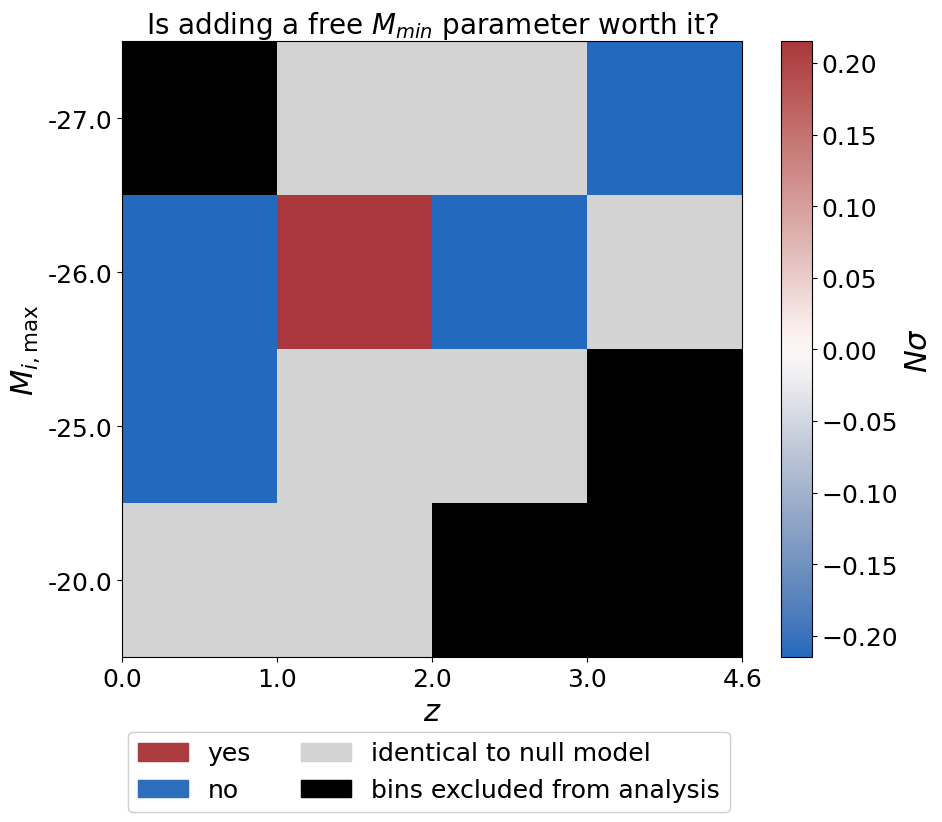

In [166]:
fig = plt.figure(figsize = (10, 8))
gs = gridspec.GridSpec(1, 1)
ax1 = fig.add_subplot(gs[0])

p_value = stats.chi2.sf(chi2_delta, df_null-df_L_z)
n_sigma_delta = stats.norm.isf(p_value)

vlim = max(np.max(n_sigma_delta[np.isfinite(n_sigma_delta)]), np.min(np.abs(n_sigma_delta[np.isfinite(n_sigma_delta)])))
image = ax1.pcolormesh(n_sigma_delta, vmin = -vlim, vmax = vlim, cmap = cmap_chi2)

nan_overlay = np.where(np.isnan(n_sigma_delta), 1.0, np.nan)
ax1.pcolormesh(nan_overlay, cmap=plt.cm.colors.ListedColormap(['black']), vmin=0, vmax=1)

fig.colorbar(image, label = '$N\sigma$')
ax1.set_xticks(range(len(z_bins)), labels = z_bins)
ax1.set_yticks(quaia.recenter(np.array(range(len(L_array)))), labels = L_bins)
ax1.set_xlabel('$z$')
ax1.set_ylabel('$M_{i,\mathrm{max}}$')
ax1.set_title('Is adding a free $M_{min}$ parameter worth it?')
custom_lines = [mpatches.Patch(color=cmap_M_min[-1]), mpatches.Patch(color=cmap_M_min[0]), mpatches.Patch(color='lightgray'), 
                mpatches.Patch(color='black')]
first_legend = plt.legend(custom_lines, [r'yes', 'no', 'identical to null model', 
                                         'bins excluded from analysis'], bbox_to_anchor=(0.5, -0.6, 0.5, 0.5), ncol =2)
fig.add_artist(first_legend)

# plt.savefig('../figures/null_test.pdf', bbox_inches = 'tight')
plt.show()

<>:12: SyntaxWarning: invalid escape sequence '\s'
<>:16: SyntaxWarning: invalid escape sequence '\m'
<>:12: SyntaxWarning: invalid escape sequence '\s'
<>:16: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_13410/3515852643.py:12: SyntaxWarning: invalid escape sequence '\s'
  fig.colorbar(image, label = '$N\sigma_\mathrm{null}/N\sigma_\mathrm{free}$')
/tmp/ipykernel_13410/3515852643.py:16: SyntaxWarning: invalid escape sequence '\m'
  ax1.set_ylabel('$M_{i,\mathrm{max}}$')


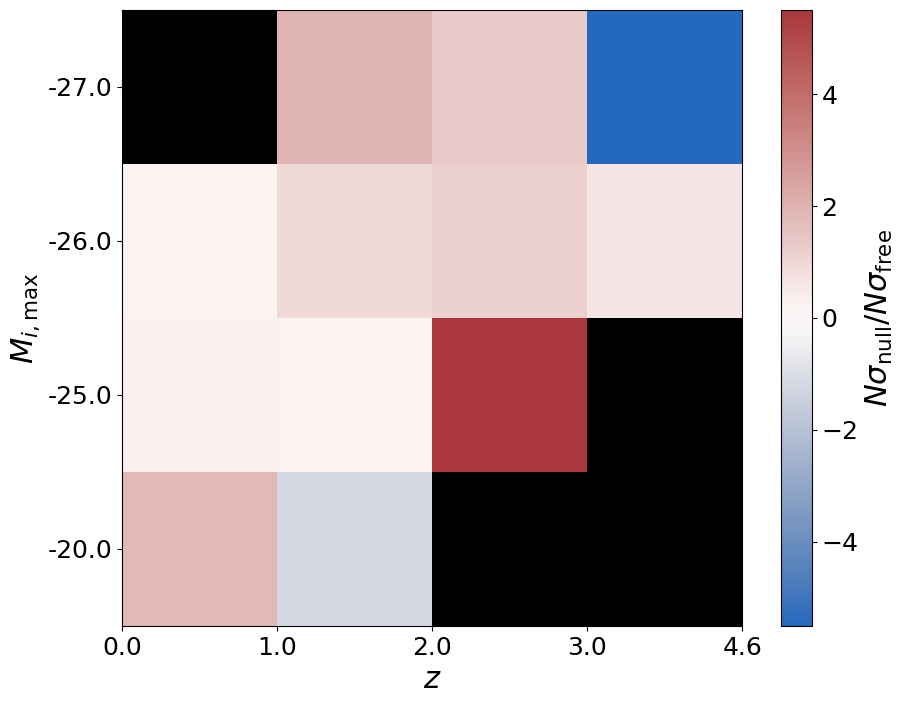

In [167]:
fig = plt.figure(figsize = (10, 8))
gs = gridspec.GridSpec(1, 1)
ax1 = fig.add_subplot(gs[0])

n_sigma_ratio = n_sigma_null/n_sigma_L_z
vlim = max(np.max(n_sigma_ratio[np.isfinite(n_sigma_ratio)]), np.min(np.abs(n_sigma_ratio[np.isfinite(n_sigma_ratio)])))
image = ax1.pcolormesh(n_sigma_ratio, vmin = -vlim, vmax = vlim, cmap = cmap_chi2)

nan_overlay = np.where(np.isnan(n_sigma_delta), 1.0, np.nan)
ax1.pcolormesh(nan_overlay, cmap=plt.cm.colors.ListedColormap(['black']), vmin=0, vmax=1)

fig.colorbar(image, label = '$N\sigma_\mathrm{null}/N\sigma_\mathrm{free}$')
ax1.set_xticks(range(len(z_bins)), labels = z_bins)
ax1.set_yticks(quaia.recenter(np.array(range(len(L_array)))), labels = L_bins)
ax1.set_xlabel('$z$')
ax1.set_ylabel('$M_{i,\mathrm{max}}$')

plt.show()

<>:14: SyntaxWarning: invalid escape sequence '\m'
<>:15: SyntaxWarning: invalid escape sequence '\m'
<>:22: SyntaxWarning: invalid escape sequence '\m'
<>:25: SyntaxWarning: invalid escape sequence '\s'
<>:14: SyntaxWarning: invalid escape sequence '\m'
<>:15: SyntaxWarning: invalid escape sequence '\m'
<>:22: SyntaxWarning: invalid escape sequence '\m'
<>:25: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_13410/2261154485.py:14: SyntaxWarning: invalid escape sequence '\m'
  ax1.set_ylabel('$M_{i,\mathrm{max}}$')
/tmp/ipykernel_13410/2261154485.py:15: SyntaxWarning: invalid escape sequence '\m'
  ax1.set_title('$M_{min}(M_{i,\mathrm{max}}=-20.0)$')
/tmp/ipykernel_13410/2261154485.py:22: SyntaxWarning: invalid escape sequence '\m'
  ax1.set_title('$M_{min}(M_{i,\mathrm{max}})$')
/tmp/ipykernel_13410/2261154485.py:25: SyntaxWarning: invalid escape sequence '\s'
  fig.colorbar(image, label = '$N\sigma$', cax = ax1)


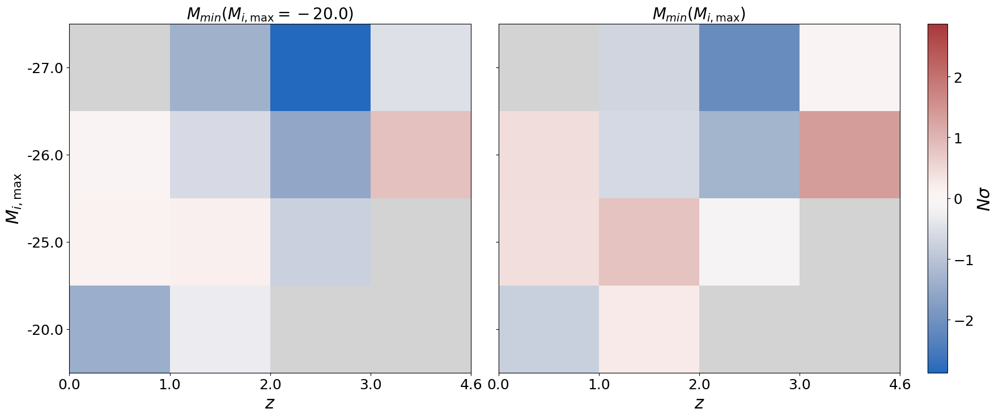

In [168]:
fig = plt.figure(figsize = (20, 8))
gs = gridspec.GridSpec(1, 3, wspace = 0.1, width_ratios = [1,1,0.05])
ax1 = fig.add_subplot(gs[0])

cmin = min(np.nanmin(n_sigma_null), np.nanmin(n_sigma_L_z))
cmax = max(np.nanmax(n_sigma_null), np.nanmax(n_sigma_L_z))
vmin = -max(np.abs(cmin), cmax)
vmax = max(np.abs(cmin), cmax)

image = ax1.pcolormesh(n_sigma_null, vmin = vmin, vmax = vmax, cmap = cmap_chi2)
ax1.set_xticks(range(len(z_bins)), labels = z_bins)
ax1.set_yticks(quaia.recenter(np.array(range(len(L_array)))), labels = L_bins)
ax1.set_xlabel('$z$')
ax1.set_ylabel('$M_{i,\mathrm{max}}$')
ax1.set_title('$M_{min}(M_{i,\mathrm{max}}=-20.0)$')

ax1 = fig.add_subplot(gs[1])
image = ax1.pcolormesh(n_sigma_L_z, vmin = vmin, vmax = vmax, cmap = cmap_chi2)
ax1.set_xticks(range(len(z_bins)), labels = z_bins)
ax1.set_yticks(quaia.recenter(np.array(range(len(L_array)))), labels = [])
ax1.set_xlabel('$z$')
ax1.set_title('$M_{min}(M_{i,\mathrm{max}})$')

ax1 = fig.add_subplot(gs[2])
fig.colorbar(image, label = '$N\sigma$', cax = ax1)

plt.show()

## Plot results

In [169]:
z_eff = [0.5, 1.5, 2.5, 3.5]

In [170]:
M_min_err_hi = [0.04, 0.02, 0.03, 0.1]
M_min_err_lo = [0.05, 0.02, 0.03, 0.12]

In [171]:
cmap_grey = plt.get_cmap('Greys')(np.linspace(0.333, 0.999, len(L_bins)))

In [172]:
M_min_array_old = [12.86, 12.74, 12.79, 12.82]

In [173]:
zmin, zmax = [], []
for i in range(len(L_bins)):
    
    zmin.append(np.min(1/np.array(a_zbin[L_bins[i]])-1))
    zmax.append(np.max(1/np.array(a_zbin[L_bins[i]])-1))

zmin = np.max(zmin)
zmax = np.min(zmax)
zmin, zmax

(0.8937010765075684, 3.241238832473755)

In [174]:
cmap_green = plt.get_cmap('Greens')(np.linspace(0.333, 0.999, len(z_array)))

In [175]:
blue = np.mean(cmap_blue, axis = 0)
green = np.mean(cmap_green, axis = 0)
purple = np.mean(cmap_purple, axis = 0)
orange = np.mean(cmap_orange, axis = 0)

<>:29: SyntaxWarning: invalid escape sequence '\l'
<>:29: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_13410/58704492.py:29: SyntaxWarning: invalid escape sequence '\l'
  plt.ylabel('$\log_{10}(M_{min}/M_\odot)$')


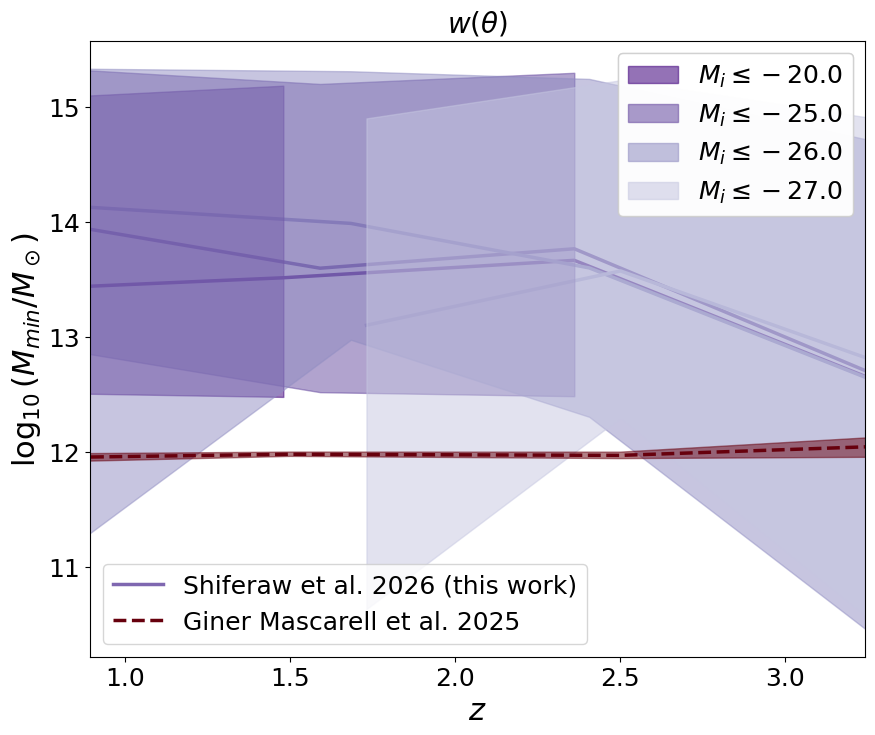

In [176]:
fig = plt.figure(figsize = (10, 8))
err_L_z = copy.deepcopy(err)
f_duty_L_z=copy.deepcopy(f_duty)
for i in range(len(L_bins)):

    err_L_z['log10(M_min)'][L_bins[i]] = np.array(err_L_z['log10(M_min)'][L_bins[i]])
    err_L_z['log10(f_duty)'][L_bins[i]] = np.array(err_L_z['log10(f_duty)'][L_bins[i]])
    
    for j in z_array:

        if not ((((i<3) and (N_q[L_bins[i]][j]>N_q[L_bins[i+1]][j])) or (i==3)) and (np.round(N_q[L_bins[i]][j]/1000)>1)):

            err_L_z['log10(M_min)'][L_bins[i]][j,:] = np.nan
            err_L_z['log10(f_duty)'][L_bins[i]][j,:] = np.nan

            f_duty[L_bins[i]][j] = np.nan
    
for i in range(len(L_bins)):
    
    M_min_lo, M_min_hi = err_L_z['log10(M_min)'][L_bins[i]][:,0], err_L_z['log10(M_min)'][L_bins[i]][:,1]
    zbin = 1/np.array(a_zbin[L_bins[i]])-1
    plt.plot(zbin, M_min[L_bins[i]], color = cmap_purple[::-1][i], linewidth = 2.5, label = 'Shiferaw et al. 2026 (this work)', zorder = 0)
    plt.fill_between(zbin, M_min_lo, M_min_hi, alpha = 0.5, color = cmap_purple[::-1][i])
    
plt.title(r'$w(\theta)$')#, N_{{jk}}={}$, step-function, sellentin'.format(N))
plt.plot(z_eff, M_min_array, label = 'Giner Mascarell et al. 2025', color = cmap_red[-1], linewidth = 2.5, linestyle = '--', zorder = 3)
plt.fill_between(z_eff, M_min_array+np.array(M_min_array)/M_min_array_old*M_min_err_hi, 
                 M_min_array-np.array(M_min_array)/M_min_array_old*M_min_err_lo, alpha = 0.5, color = cmap_red[-1])
plt.ylabel('$\log_{10}(M_{min}/M_\odot)$')
plt.xlabel('$z$')
plt.xlim(zmin, zmax)

custom_lines = [Line2D([0], [0], color = purple, linestyle = '-', linewidth = 2.5),
                Line2D([0], [0], color = cmap_red[-1], linestyle = '--', linewidth = 2.5)]
second_legend = plt.legend(custom_lines, [r'Shiferaw et al. 2026 (this work)', 
                                          'Giner Mascarell et al. 2025'],
                           loc = 'lower left')
fig.add_artist(second_legend)

custom_lines = [mpatches.Patch(color=cmap_purple[::-1][i], alpha = 0.5) for i in range(len(L_bins))]
first_legend = plt.legend(custom_lines, [r'$M_i\leq{}$'.format(L_bins[i]) for i in range(len(L_bins))])
fig.add_artist(first_legend)

plt.show()

<>:12: SyntaxWarning: invalid escape sequence '\l'
<>:12: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_13410/1618482535.py:12: SyntaxWarning: invalid escape sequence '\l'
  plt.ylabel('$\log_{10}(M_{min}/M_\odot)$')


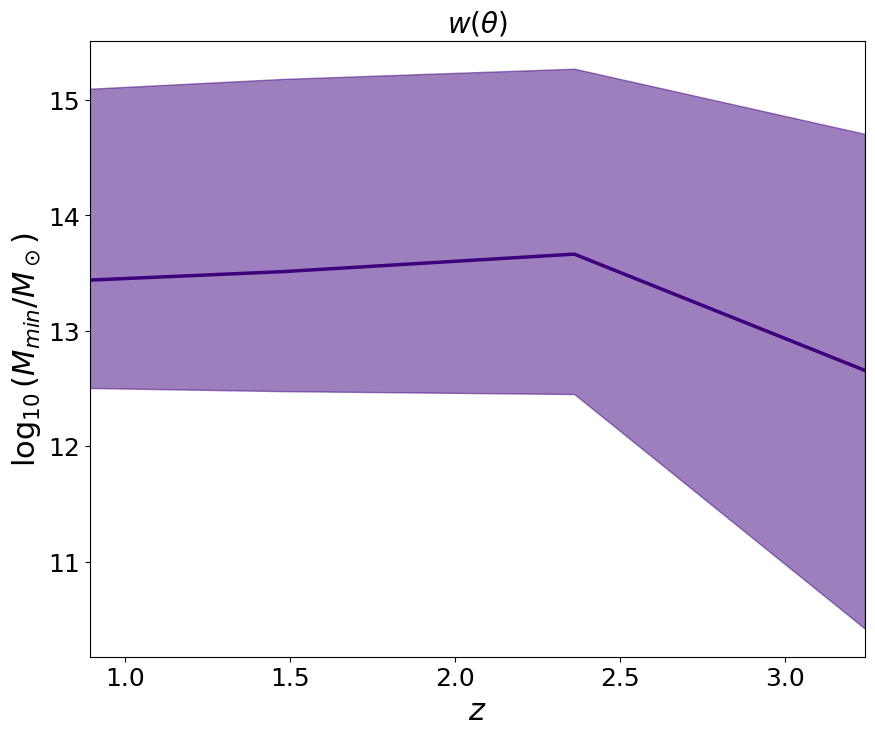

In [177]:
fig = plt.figure(figsize = (10, 8))

# for i in range(len(L_bins)):
i = 0
    
M_min_lo, M_min_hi = np.array(err['log10(M_min)'][L_bins[i]])[:,0], np.array(err['log10(M_min)'][L_bins[i]])[:,1]
zbin = 1/np.array(a_zbin[L_bins[i]])-1
plt.plot(zbin, M_min[L_bins[i]], color = cmap_purple[::-1][i], linewidth = 2.5, label = 'Shiferaw et al. 2026 (this work)', zorder = 0)
plt.fill_between(zbin, M_min_lo, M_min_hi, alpha = 0.5, color = cmap_purple[::-1][i])
    
plt.title(r'$w(\theta)$')#, N_{{jk}}={}$, step-function, sellentin'.format(N))
plt.ylabel('$\log_{10}(M_{min}/M_\odot)$')
plt.xlabel('$z$')
plt.xlim(zmin, zmax)

plt.show()

In [178]:
z_sigma = {L: [] for L in L_bins}

for i in range(len(L_bins)):

    for j in z_array:
        
        tab_datahi_mask_zbin0, tab_randhi_mask_zbin0, key_zbin0, _, _, _, selfunc_hi_bin0, _, _ = quaia.make_bins(
            G_hi, [j, i], True, ['z', 'L'], bins = [z_bins, L_bins], tab_gcat_type = 'data', method = ['minmax', 'max'], fac_rand = fac_rand, 
            n_bins = [None, None], b = b, mask_type = 'b', verbose = False)

        z_sigma[L_bins[i]].append(np.percentile(tab_datahi_mask_zbin0['redshift_quaia'], [16, 84]))

In [179]:
red = np.mean(cmap_red, axis = 0)

<>:13: SyntaxWarning: invalid escape sequence '\l'
<>:26: SyntaxWarning: invalid escape sequence '\l'
<>:13: SyntaxWarning: invalid escape sequence '\l'
<>:26: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_13410/1389801862.py:13: SyntaxWarning: invalid escape sequence '\l'
  plt.ylabel('$\log_{10}(M_{min}/M_\odot)$')
/tmp/ipykernel_13410/1389801862.py:26: SyntaxWarning: invalid escape sequence '\l'
  first_legend = plt.legend(custom_lines, ['${:.1f}<z \leq{:.1f}$'.format(z_bins[i], z_bins[i+1]) for i in z_array])


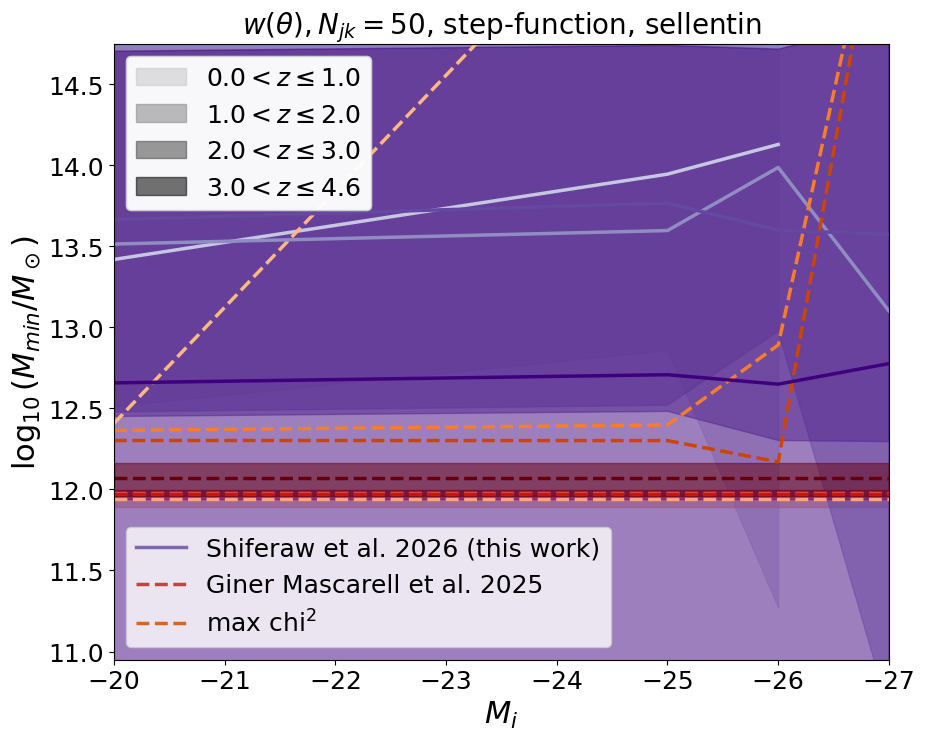

In [180]:
fig = plt.figure(figsize = (10, 8))

for i in z_array:
    
    M_min_lo, M_min_hi = [np.array(err['log10(M_min)'][L])[:,0][i] for L in L_bins], [np.array(err['log10(M_min)'][L])[:,1][i] for L in L_bins]
    plt.plot(L_bins, [M_min[L][i] for L in L_bins], color = cmap_purple[i], linewidth = 2.5, label = 'Shiferaw et al. 2026 (this work)')
    plt.fill_between(L_bins, M_min_lo, M_min_hi, alpha = 0.5, color = cmap_purple[i])
    plt.axhline(M_min_array[i], label = 'Giner Mascarell et al. 2025', color = cmap_red[i], linewidth = 2.5, linestyle = '--')
    plt.fill_between(L_bins, [M_min_array[i]+(np.array(M_min_array)/M_min_array_old*M_min_err_hi)[i]]*len(L_bins), [M_min_array[i]-(np.array(M_min_array)/M_min_array_old*M_min_err_lo)[i]]*len(L_bins), alpha = 0.5, color = cmap_red[i])
    plt.plot(L_bins, [best_fit_params[L][i][1] for L in L_bins], color = cmap_orange[i], linewidth = 2.5, label = 'max chi$^2$', linestyle = '--')
    
plt.title(r'$w(\theta), N_{{jk}}={}$, step-function, sellentin'.format(N))
plt.ylabel('$\log_{10}(M_{min}/M_\odot)$')
plt.xlabel('$M_i$')
plt.xlim(L_bins[0], L_bins[-1])
plt.ylim(10.95,14.75)

custom_lines = [Line2D([0], [0], color = purple, linestyle = '-', linewidth = 2.5),
                Line2D([0], [0], color = red, linestyle = '--', linewidth = 2.5),
                Line2D([0], [0], color = orange, linestyle = '--', linewidth = 2.5)]
second_legend = plt.legend(custom_lines, [r'Shiferaw et al. 2026 (this work)', 
                                          'Giner Mascarell et al. 2025', 'max chi$^2$'], loc = 'lower left')
fig.add_artist(second_legend)

custom_lines = [mpatches.Patch(color=cmap_grey[i], alpha = 0.5) for i in range(len(z_array))]
first_legend = plt.legend(custom_lines, ['${:.1f}<z \leq{:.1f}$'.format(z_bins[i], z_bins[i+1]) for i in z_array])
fig.add_artist(first_legend)

plt.show()

In [181]:
fduty_old = [0.018, 0.022, 0.056, 0.071]

<>:15: SyntaxWarning: invalid escape sequence '\l'
<>:15: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_13410/840620771.py:15: SyntaxWarning: invalid escape sequence '\l'
  plt.ylabel('$\log_{10}(f_{duty})$')


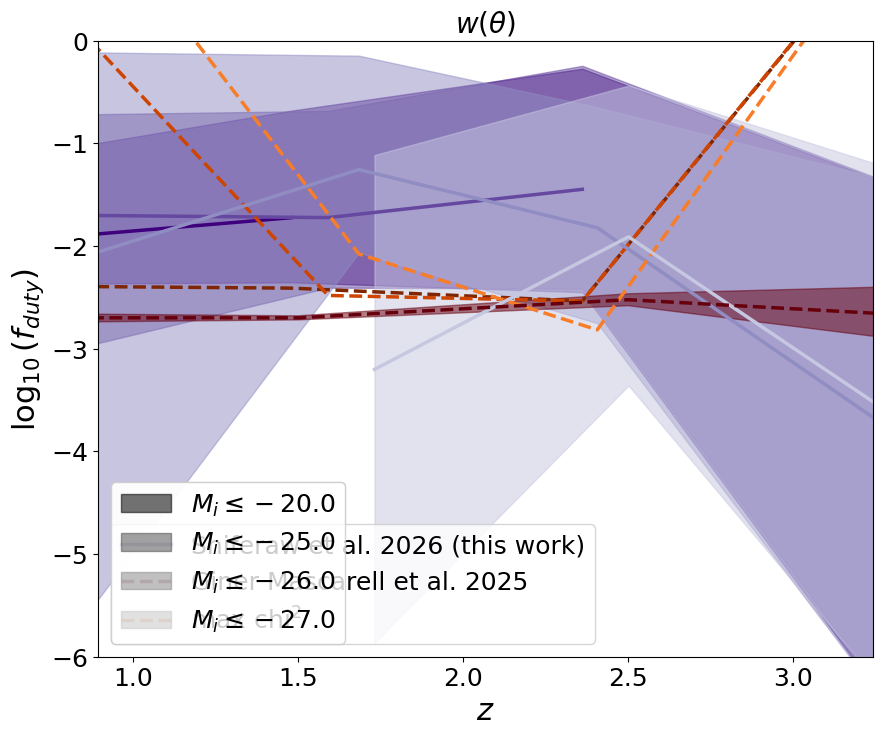

In [182]:
fig = plt.figure(figsize = (10, 8))

for i in range(len(L_bins)):
    
    f_duty_lo, f_duty_hi = np.array(err['log10(f_duty)'][L_bins[i]])[:,0], np.array(err['log10(f_duty)'][L_bins[i]])[:,1]
    zbin = 1/np.array(a_zbin[L_bins[i]])-1
    plt.plot(zbin, f_duty[L_bins[i]], color = cmap_purple[::-1][i], linewidth = 2.5, label = 'Shiferaw et al. 2026 (this work)')
    plt.fill_between(zbin, f_duty_lo, f_duty_hi, alpha = 0.5, color = cmap_purple[::-1][i])
    plt.plot(zbin, np.array(best_fit_params[L_bins[i]]).T[0], color = cmap_orange[::-1][i], linewidth = 2.5, label = 'max chi$^2$', linestyle = '--')
   
plt.title(r'$w(\theta)$')#, N_{{jk}}={}$, step-function, sellentin'.format(N))
plt.plot(z_eff, np.log10(fduty), label = 'Giner Mascarell et al. 2025', color = cmap_red[-1], linewidth = 2.5, linestyle = '--')
plt.fill_between(z_eff, np.log10(np.array(fduty)+np.array(fduty)/fduty_old*fduty_err_hi), 
                 np.log10(np.array(fduty)-np.array(fduty)/fduty_old*fduty_err_lo), alpha = 0.5, color = cmap_red[-1])
plt.ylabel('$\log_{10}(f_{duty})$')
plt.xlabel('$z$')
plt.xlim(zmin, zmax)
plt.ylim(-6,0)

custom_lines = [Line2D([0], [0], color = purple, linestyle = '-', linewidth = 2.5),
                Line2D([0], [0], color = cmap_red[-1], linestyle = '--', linewidth = 2.5),
                Line2D([0], [0], color = orange, linestyle = '--', linewidth = 2.5)]
second_legend = plt.legend(custom_lines, [r'Shiferaw et al. 2026 (this work)', 
                                          'Giner Mascarell et al. 2025', 'max chi$^2$'], loc = 'lower left')
fig.add_artist(second_legend)

custom_lines = [mpatches.Patch(color=cmap_grey[::-1][i], alpha = 0.5) for i in range(len(L_bins))]
first_legend = plt.legend(custom_lines, [r'$M_i\leq{}$'.format(L_bins[i]) for i in range(len(L_bins))])
fig.add_artist(first_legend)

plt.show()

<>:16: SyntaxWarning: invalid escape sequence '\l'
<>:16: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_13410/2891204172.py:16: SyntaxWarning: invalid escape sequence '\l'
  plt.ylabel('$\log_{10}(f_{duty})$')


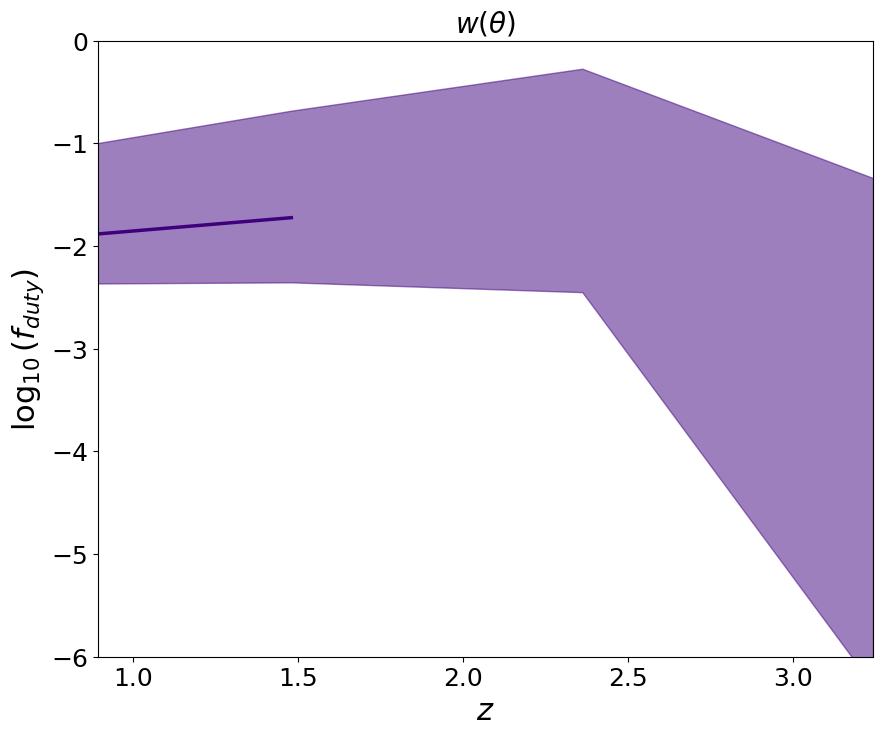

In [183]:
fig = plt.figure(figsize = (10, 8))

i = 0
# for i in range(len(L_bins)):
    
f_duty_lo, f_duty_hi = np.array(err['log10(f_duty)'][L_bins[i]])[:,0], np.array(err['log10(f_duty)'][L_bins[i]])[:,1]
zbin = 1/np.array(a_zbin[L_bins[i]])-1
plt.plot(zbin, f_duty[L_bins[i]], color = cmap_purple[::-1][i], linewidth = 2.5, label = 'Shiferaw et al. 2026 (this work)')
plt.fill_between(zbin, f_duty_lo, f_duty_hi, alpha = 0.5, color = cmap_purple[::-1][i])
    # plt.plot(zbin, np.array(best_fit_params[L_bins[i]]).T[0], color = cmap_orange[::-1][i], linewidth = 2.5, label = 'max chi$^2$', linestyle = '--')
   
plt.title(r'$w(\theta)$')#, N_{{jk}}={}$, step-function, sellentin'.format(N))
# plt.plot(z_eff, np.log10(fduty), label = 'Giner Mascarell et al. 2025', color = cmap_red[-1], linewidth = 2.5, linestyle = '--')
# plt.fill_between(z_eff, np.log10(np.array(fduty)+np.array(fduty)/fduty_old*fduty_err_hi), 
#                  np.log10(np.array(fduty)-np.array(fduty)/fduty_old*fduty_err_lo), alpha = 0.5, color = cmap_red[-1])
plt.ylabel('$\log_{10}(f_{duty})$')
plt.xlabel('$z$')
plt.xlim(zmin, zmax)
plt.ylim(-6,0)

# custom_lines = [Line2D([0], [0], color = purple, linestyle = '-', linewidth = 2.5),
#                 Line2D([0], [0], color = cmap_red[-1], linestyle = '--', linewidth = 2.5),
#                 Line2D([0], [0], color = orange, linestyle = '--', linewidth = 2.5)]
# second_legend = plt.legend(custom_lines, [r'Shiferaw et al. 2026 (this work)', 
#                                           'Giner Mascarell et al. 2025', 'max chi$^2$'], loc = 'lower left')
# fig.add_artist(second_legend)

# custom_lines = [mpatches.Patch(color=cmap_grey[::-1][i], alpha = 0.5) for i in range(len(L_bins))]
# first_legend = plt.legend(custom_lines, [r'$M_i\leq{}$'.format(L_bins[i]) for i in range(len(L_bins))])
# fig.add_artist(first_legend)

plt.show()

In [184]:
z_centers_eft    = [2.50, 2.29, 2.51, 3.02, 2.50, 2.50, 2.50][:4]
z_err_lo_eft     = [0.30, 0.09, 0.13, 0.38, 0.30, 0.30, 0.30][:4]
z_err_hi_eft     = [0.30, 0.09, 0.13, 0.38, 0.30, 0.30, 0.30][:4]

fduty_eft        = np.log10([0.00734, 0.0162, 0.0061, 0.00145, 0.0019, 0.0023, 0.0044])[:4]
fduty_err_hi_eft = np.log10(10**fduty_eft+[0.0014,  0.0031, 0.0016, 0.0003,  0.0004, 0.0006, 0.0015][:4])-fduty_eft
fduty_err_lo_eft = fduty_eft-np.log10(10**fduty_eft-[0.0011,  0.0025, 0.0014, 0.0002,  0.0003, 0.0004, 0.0008][:4]) #table 7 https://arxiv.org/pdf/1507.08380

In [185]:
Mmin_eft        = np.log10(np.array([0.93, 1.39, 0.82, 0.35, 1.03, 0.92, 1.26])*1e12/Planck18.h)[:4]
Mmin_err_hi_eft = np.log10(np.add([0.11, 0.16, 0.15, 0.04, 0.12, 0.12, 0.26],[0.93, 1.39, 0.82, 0.35, 1.03, 0.92, 1.26])[:4]*1e12/Planck18.h)-Mmin_eft
Mmin_err_lo_eft = Mmin_eft-np.log10(np.subtract([0.93, 1.39, 0.82, 0.35, 1.03, 0.92, 1.26], [0.09, 0.15, 0.14, 0.07, 0.10, 0.16, 0.15])[:4]*1e12/Planck18.h) #table 7 https://arxiv.org/pdf/1507.08380

In [186]:
z_centers_2    = [1.05, 1.35, 1.65, 2.00, 1.55][:-1]
z_err_lo_2     = [0.15, 0.15, 0.15, 0.20, 0.65][:-1]
z_err_hi_2     = [0.15, 0.15, 0.15, 0.20, 0.65][:-1]

fduty_2        = np.log10([0.0091, 0.0183, 0.0355, 0.0422, 0.0292])[:-1]
fduty_err_hi_2 = np.log10(10**fduty_2+[0.0027, 0.0028, 0.0133, 0.0077, 0.0048][:-1])-fduty_2
fduty_err_lo_2 = fduty_2-np.log10(10**fduty_2-[0.0027, 0.0028, 0.0133, 0.0077, 0.0048][:-1])

Mmin_2         = np.log10(np.array([1.99, 2.24, 2.51, 1.99, 2.51])*1e12/Planck18.h)[:-1]
Mmin_err_hi_2  = np.log10(np.add([0.52, 0.27, 0.65, 0.24, 0.31], [1.99, 2.24, 2.51, 1.99, 2.51])[:-1]*1e12/Planck18.h)-Mmin_2
Mmin_err_lo_2  = Mmin_2-np.log10(np.subtract([1.99, 2.24, 2.51, 1.99, 2.51],[0.41, 0.24, 0.27, 0.41, 0.27])[:-1]*1e12/Planck18.h) # table 4 https://arxiv.org/pdf/1705.04718

In [187]:
z_shen = [3.2, 4.6]
z_err_shen = [0.3, 0.8]

fduty_shen = (np.log10(0.05)+np.log10(0.004))/2, (np.log10(0.6)+np.log10(0.03))/2
fduty_err_lo_shen = fduty_shen - np.log10([0.004, 0.03])
fduty_err_hi_shen = np.log10([0.05, 0.6]) - fduty_shen

Mmin_shen = np.log10([(2.26e12+3.11e12)/2, (3.83e12+5.76e12)/2]/Planck18.h) # https://arxiv.org/abs/astro-ph/0702214 table 6
Mmin_err_lo_shen = Mmin_shen-np.log10([2.26e12, 3.83e12]/Planck18.h)
Mmin_err_hi_shen = np.log10([3.11e12, 5.76e12]/Planck18.h)-Mmin_shen

In [188]:
z_charles = [2.143, 2.479, 3.264]
z_err_charles = np.array([[2,2.3], [2.3,2.7], [3.1,3.5]])
z_err_lo_charles = z_charles - z_err_charles[:,0]
z_err_hi_charles = z_err_charles[:,1] - z_charles

fduty_charles = np.log10([0.0243, 0.0207, 0.0142])
fduty_err_charles = np.array([0.0008, 0.0008, 0.0016])
fduty_err_lo_charles = fduty_charles-np.log10(10**fduty_charles-fduty_err_charles)
fduty_err_hi_charles = np.log10(10**fduty_charles+fduty_err_charles)-fduty_charles

In [189]:
z_pizzati = 2.5, 4
z_err_pizzati = 0.3, 0.5

fduty_pizzati = np.log10(np.array([1.01, 51])/100)
fduty_err_pizzati = np.array([[0.04, 31], [1.59, 32]])/100
fduty_err_lo_pizzati = fduty_pizzati-np.log10(10**fduty_pizzati-fduty_err_pizzati[0]/100)
fduty_err_hi_pizzati = np.log10(10**fduty_pizzati+fduty_err_pizzati[1]/100)-fduty_pizzati

<>:55: SyntaxWarning: invalid escape sequence '\l'
<>:58: SyntaxWarning: invalid escape sequence '\l'
<>:55: SyntaxWarning: invalid escape sequence '\l'
<>:58: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_13410/610875555.py:55: SyntaxWarning: invalid escape sequence '\l'
  ax1.set_ylabel('$\log_{10}(M_{min}/M_\odot)$')
/tmp/ipykernel_13410/610875555.py:58: SyntaxWarning: invalid escape sequence '\l'
  ax2.set_ylabel('$\log_{10}(f_{duty})$')


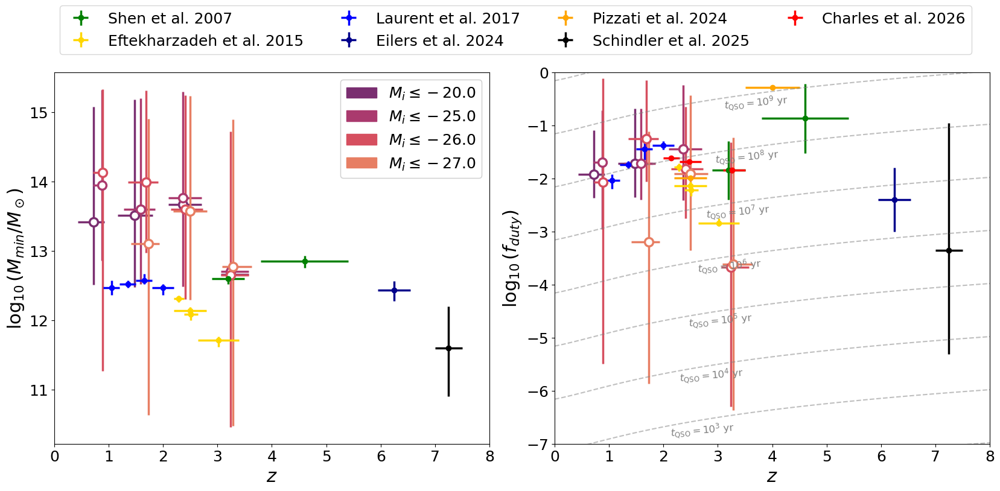

In [190]:
fig = plt.figure(figsize = (20, 8))
gs = gridspec.GridSpec(1, 2, wspace = 0.15, hspace = 0.15)

ax1 = fig.add_subplot(gs[0])
ax2 = fig.add_subplot(gs[1])

for i in range(len(L_bins)):

    M_min_lo, M_min_hi = err_L_z['log10(M_min)'][L_bins[i]][:,0], err_L_z['log10(M_min)'][L_bins[i]][:,1]

    zbin = 1/np.array(a_zbin[L_bins[i]])-1
    xerr = [zbin-np.array(z_sigma[L_bins[i]])[:,0], np.array(z_sigma[L_bins[i]])[:,1]-zbin]

    ax1.errorbar(zbin, M_min[L_bins[i]], yerr = [M_min[L_bins[i]]-M_min_lo, M_min_hi-M_min[L_bins[i]]], 
                 xerr = xerr, linestyle = 'none', marker = 'o', 
                 color = cmap_theta[i], linewidth = 2.5, markeredgewidth = 2.5, markerfacecolor = 'white', markersize = 10)#, 
    
    f_duty_lo, f_duty_hi = err_L_z['log10(f_duty)'][L_bins[i]][:,0], err_L_z['log10(f_duty)'][L_bins[i]][:,1]
    ax2.errorbar(zbin, f_duty[L_bins[i]], yerr = [f_duty[L_bins[i]]-f_duty_lo, f_duty_hi-f_duty[L_bins[i]]], linestyle = 'none', xerr = xerr, 
                 marker = 'o', color = cmap_theta[i], linewidth = 2.5, markeredgewidth = 2.5, markerfacecolor = 'white', markersize = 10)

ax1.errorbar(z_shen, Mmin_shen, yerr = [Mmin_err_lo_shen, Mmin_err_hi_shen], linestyle = 'none', xerr = z_err_shen, 
             marker = 'o', color = 'green', linewidth = 2.5, label = 'Shen et al. 2007') #https://arxiv.org/abs/2403.07986 p13
ax2.errorbar(z_shen, fduty_shen, yerr = [fduty_err_lo_shen, fduty_err_hi_shen], linestyle = 'none', xerr = z_err_shen, 
             marker = 'o', color = 'green', linewidth = 2.5, label = 'Shen et al. 2007')

ax1.errorbar(z_centers_eft, Mmin_eft, yerr = [Mmin_err_lo_eft, Mmin_err_hi_eft], linestyle = 'none', xerr = [z_err_lo_eft, z_err_hi_eft], 
             marker = 'o', color = 'gold', linewidth = 2.5, label = 'Eftekharzadeh et al. 2015')
ax2.errorbar(z_centers_eft, fduty_eft, yerr = [fduty_err_lo_eft, fduty_err_hi_eft], linestyle = 'none', xerr = [z_err_lo_eft, z_err_hi_eft], 
             marker = 'o', color = 'gold', linewidth = 2.5, label = 'Eftekharzadeh et al. 2015')

ax1.errorbar(z_centers_2, Mmin_2, yerr = [Mmin_err_lo_2, Mmin_err_hi_2], linestyle = 'none', xerr = [z_err_lo_2, z_err_hi_2], 
             marker = 'o', color = 'blue', linewidth = 2.5, label = 'Laurent et al. 2017')
ax2.errorbar(z_centers_2, fduty_2, yerr = [fduty_err_lo_2, fduty_err_hi_2], linestyle = 'none', xerr = [z_err_lo_2, z_err_hi_2], 
             marker = 'o', color = 'blue', linewidth = 2.5, label = 'Laurent et al. 2017')

ax1.errorbar(6.25, 12.43, yerr = [[0.15], [0.13]], linestyle = 'none', xerr = 0.3, 
             marker = 'o', color = 'darkblue', linewidth = 2.5, label = 'Eilers et al. 2024') #https://arxiv.org/abs/2403.07986 p13
ax2.errorbar(6.25, np.log10(0.4/100), yerr = [[np.log10(0.4/100)-np.log10((0.4-0.3)/100)], [np.log10((1.2+0.4)/100)-np.log10(0.4/100)]], linestyle = 'none', xerr = 0.3, 
             marker = 'o', color = 'darkblue', linewidth = 2.5, label = 'Eilers et al. 2024')

ax2.errorbar(z_pizzati, fduty_pizzati, yerr = [fduty_err_lo_pizzati, fduty_err_hi_pizzati], linestyle = 'none', xerr = z_err_pizzati, 
             marker = 'o', color = 'orange', linewidth = 2.5, label = 'Pizzati et al. 2024') #https://arxiv.org/abs/2311.17181 table 3

ax1.errorbar(7.25, 11.6, yerr = [[0.7], [0.6]], linestyle = 'none', xerr = 0.25, 
             marker = 'o', color = 'black', linewidth = 2.5, label = 'Schindler et al. 2025') #https://arxiv.org/abs/2510.08455 abstract
ax2.errorbar(7.25, -3.36, yerr = [[1.95], [2.4]], linestyle = 'none', xerr = 0.25, 
             marker = 'o', color = 'black', linewidth = 2.5, label = 'Schindler et al. 2025') #https://arxiv.org/abs/2510.08455 sec. 4.4

ax2.errorbar(z_charles, fduty_charles, yerr = [fduty_err_lo_charles, fduty_err_hi_charles], linestyle = 'none', xerr = [z_err_lo_charles, z_err_hi_charles], 
             marker = 'o', color = 'red', linewidth = 2.5, label = 'Charles et al. 2026') #https://arxiv.org/abs/2606.27115 table 2
# ax2.legend(ncol=3, bbox_to_anchor = (0.25, 0.7, 0.5, 0.5)) #1.4
ax2.legend(ncol=4, bbox_to_anchor = (0.025, 0.7, 0.95, 0.5))

ax1.set_ylabel('$\log_{10}(M_{min}/M_\odot)$')
ax1.set_xlabel('$z$')

ax2.set_ylabel('$\log_{10}(f_{duty})$')
ax2.set_xlabel('$z$')

custom_lines = [mpatches.Patch(color=cmap_theta[i]) for i in range(len(L_bins))]
first_legend = ax1.legend(custom_lines, [r'$M_i\leq{}$'.format(L_bins[i]) for i in range(len(L_bins))])#, title = 'Shiferaw et al. 2026 (this work)',
fig.add_artist(first_legend)

d = 1
start = 12
z_linspace = np.linspace(0,8)
for i, t in enumerate([1e2,1e3,1e4,1e5, 1e6, 1e7, 1e8, 1e9, 1e10]):
    fduty_linspace = t*u.yr/(1/Planck18.H(z_linspace)).to('yr')
    ax2.plot(z_linspace, np.log10(fduty_linspace), color = 'grey', alpha = 0.5, linestyle = '--')

    if (t>1e2) and (t<1e10):
        ax2.text(z_linspace[start:][::d][i], np.log10(fduty_linspace)[start:][::d][i]-0.2, 
                    r'$t_{\rm QSO} = 10^{%d}$ yr' % int(np.log10(t)), color='grey', fontsize = 12, rotation = 5,)

ax1.set_xlim(0, 8)
ax2.set_xlim(0, 8)
ax2.set_ylim(-7,0)

# plt.savefig('../figures/Mmin_fduty_wtheta.pdf', bbox_inches = 'tight')
plt.show()

<>:22: SyntaxWarning: invalid escape sequence '\l'
<>:25: SyntaxWarning: invalid escape sequence '\l'
<>:22: SyntaxWarning: invalid escape sequence '\l'
<>:25: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_13410/3310296806.py:22: SyntaxWarning: invalid escape sequence '\l'
  ax1.set_ylabel('$\log_{10}(M_{min}/M_\odot)$')
/tmp/ipykernel_13410/3310296806.py:25: SyntaxWarning: invalid escape sequence '\l'
  ax2.set_ylabel('$\log_{10}(f_{duty})$')


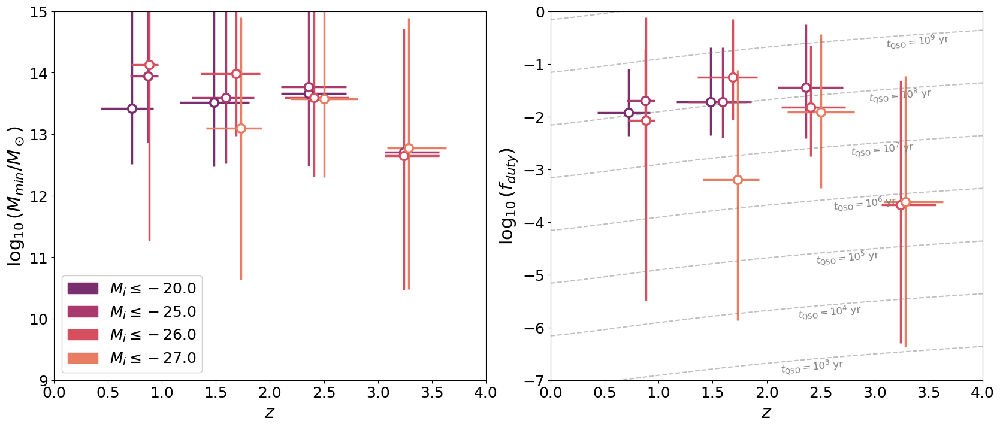

In [191]:
fig = plt.figure(figsize = (20, 8))
gs = gridspec.GridSpec(1, 2, wspace = 0.15, hspace = 0.15)

ax1 = fig.add_subplot(gs[0])
ax2 = fig.add_subplot(gs[1])

for i in range(len(L_bins)):

    M_min_lo, M_min_hi = err_L_z['log10(M_min)'][L_bins[i]][:,0], err_L_z['log10(M_min)'][L_bins[i]][:,1]

    zbin = 1/np.array(a_zbin[L_bins[i]])-1
    xerr = [zbin-np.array(z_sigma[L_bins[i]])[:,0], np.array(z_sigma[L_bins[i]])[:,1]-zbin]

    ax1.errorbar(zbin, M_min[L_bins[i]], yerr = [M_min[L_bins[i]]-M_min_lo, M_min_hi-M_min[L_bins[i]]], 
                 xerr = xerr, linestyle = 'none', marker = 'o', 
                 color = cmap_theta[i], linewidth = 2.5, markeredgewidth = 2.5, markerfacecolor = 'white', markersize = 10)#, 
    
    f_duty_lo, f_duty_hi = err_L_z['log10(f_duty)'][L_bins[i]][:,0], err_L_z['log10(f_duty)'][L_bins[i]][:,1]
    ax2.errorbar(zbin, f_duty[L_bins[i]], yerr = [f_duty[L_bins[i]]-f_duty_lo, f_duty_hi-f_duty[L_bins[i]]], linestyle = 'none', xerr = xerr, 
                 marker = 'o', color = cmap_theta[i], linewidth = 2.5, markeredgewidth = 2.5, markerfacecolor = 'white', markersize = 10)

ax1.set_ylabel('$\log_{10}(M_{min}/M_\odot)$')
ax1.set_xlabel('$z$')

ax2.set_ylabel('$\log_{10}(f_{duty})$')
ax2.set_xlabel('$z$')

custom_lines = [mpatches.Patch(color=cmap_theta[i]) for i in range(len(L_bins))]
first_legend = ax1.legend(custom_lines, [r'$M_i\leq{}$'.format(L_bins[i]) for i in range(len(L_bins))])#, title = 'Shiferaw et al. 2026 (this work)',
                          # title_fontsize = 20)
fig.add_artist(first_legend)

d = 1
start = 12
for i, t in enumerate([1e2,1e3,1e4,1e5, 1e6, 1e7, 1e8, 1e9, 1e10]):
    fduty_linspace = t*u.yr/(1/Planck18.H(z_linspace)).to('yr')
    ax2.plot(z_linspace, np.log10(fduty_linspace), color = 'grey', alpha = 0.5, linestyle = '--')

    if (t>1e2) and (t<1e10):
        ax2.text(z_linspace[start:][::d][i], np.log10(fduty_linspace)[start:][::d][i]-0.2, 
                    r'$t_{\rm QSO} = 10^{%d}$ yr' % int(np.log10(t)), color='grey', fontsize = 12, rotation = 5,)

ax1.set_xlim(0, 4)
ax2.set_xlim(0, 4)
ax2.set_ylim(-7,0)
ax1.set_ylim(9,15)

# plt.savefig('../figures/Mmin_fduty_wtheta.pdf', bbox_inches = 'tight')
plt.show()

In [192]:
i = 3
np.isfinite(err_L_z['log10(M_min)'][L_bins[i]][:,0]).all()

False

<>:26: SyntaxWarning: invalid escape sequence '\l'
<>:29: SyntaxWarning: invalid escape sequence '\l'
<>:26: SyntaxWarning: invalid escape sequence '\l'
<>:29: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_13410/636253152.py:26: SyntaxWarning: invalid escape sequence '\l'
  ax1.set_ylabel('$\log_{10}(M_{min}/M_\odot)$')
/tmp/ipykernel_13410/636253152.py:29: SyntaxWarning: invalid escape sequence '\l'
  ax2.set_ylabel('$\log_{10}(f_{duty})$')


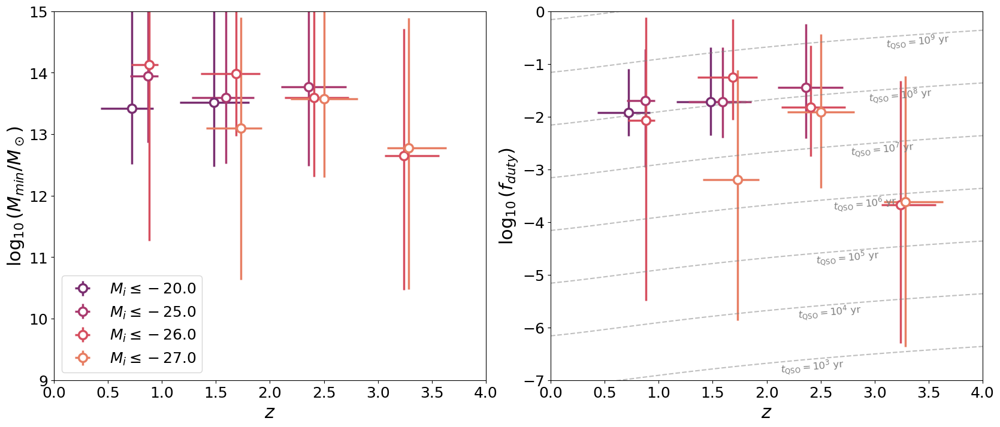

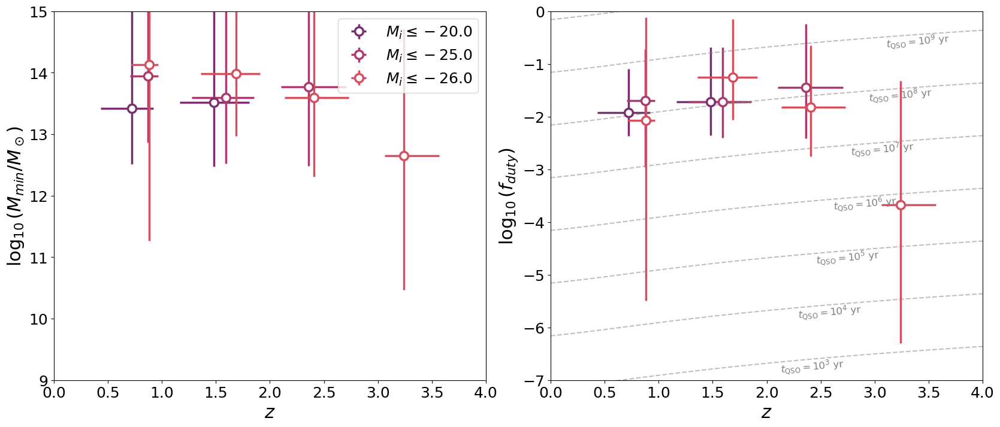

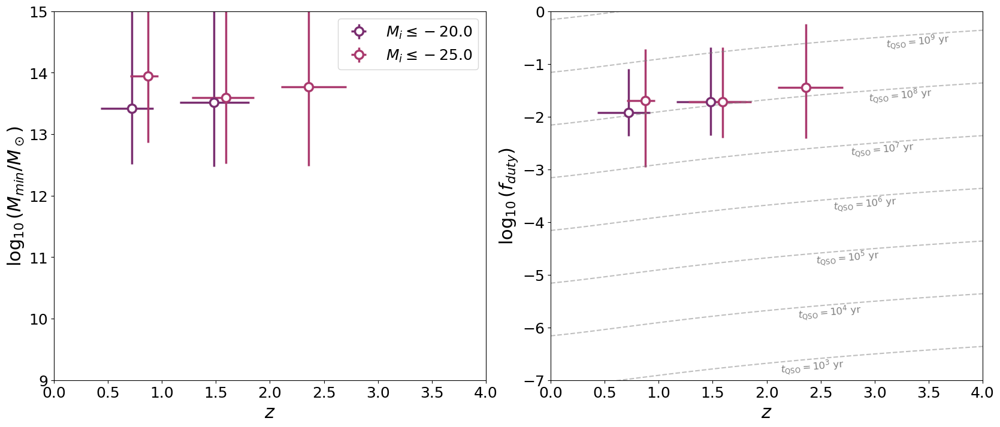

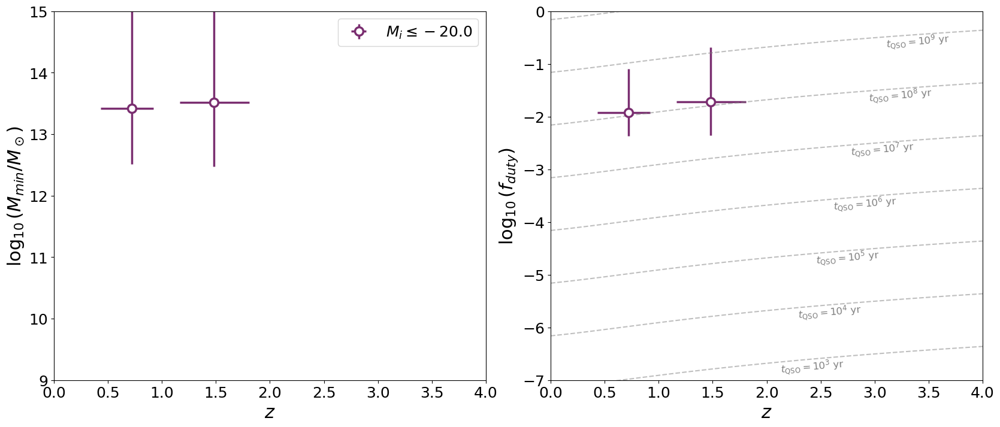

In [193]:
for k in range(len(L_bins)):
    
    fig = plt.figure(figsize = (20, 8))
    gs = gridspec.GridSpec(1, 2, wspace = 0.15, hspace = 0.15)
    
    ax1 = fig.add_subplot(gs[0])
    ax2 = fig.add_subplot(gs[1])
    
    for i in range(len(L_bins)-k):

        M_min_lo, M_min_hi = err_L_z['log10(M_min)'][L_bins[i]][:,0], err_L_z['log10(M_min)'][L_bins[i]][:,1]

        zbin = 1/np.array(a_zbin[L_bins[i]])-1
        xerr = [zbin-np.array(z_sigma[L_bins[i]])[:,0], np.array(z_sigma[L_bins[i]])[:,1]-zbin]

        M_min_finite = [M_min[L_bins[i]][j] if np.isfinite(M_min_lo[j]) else np.nan for j in range(len(zbin))]
        ax1.errorbar(zbin, M_min_finite, yerr = [M_min[L_bins[i]]-M_min_lo, M_min_hi-M_min[L_bins[i]]], 
                     xerr = xerr, linestyle = 'none', marker = 'o', 
                     color = cmap_theta[i], linewidth = 2.5, markeredgewidth = 2.5, markerfacecolor = 'white', markersize = 10, label = r'$M_i\leq{}$'.format(L_bins[i]))#, 
    
        f_duty_lo, f_duty_hi = err_L_z['log10(f_duty)'][L_bins[i]][:,0], err_L_z['log10(f_duty)'][L_bins[i]][:,1]
        f_duty_finite = [f_duty[L_bins[i]][j] if np.isfinite(f_duty_lo[j]) else np.nan for j in range(len(zbin))]
        ax2.errorbar(zbin, f_duty_finite, yerr = [f_duty[L_bins[i]]-f_duty_lo, f_duty_hi-f_duty[L_bins[i]]], linestyle = 'none', xerr = xerr, 
                     marker = 'o', color = cmap_theta[i], linewidth = 2.5, markeredgewidth = 2.5, markerfacecolor = 'white', markersize = 10)
    
    ax1.set_ylabel('$\log_{10}(M_{min}/M_\odot)$')
    ax1.set_xlabel('$z$')
    
    ax2.set_ylabel('$\log_{10}(f_{duty})$')
    ax2.set_xlabel('$z$')
    
    d = 1
    start = 12
    for i, t in enumerate([1e2,1e3,1e4,1e5, 1e6, 1e7, 1e8, 1e9, 1e10]):
        fduty_linspace = t*u.yr/(1/Planck18.H(z_linspace)).to('yr')
        ax2.plot(z_linspace, np.log10(fduty_linspace), color = 'grey', alpha = 0.5, linestyle = '--')
    
        if (t>1e2) and (t<1e10):
            ax2.text(z_linspace[start:][::d][i], np.log10(fduty_linspace)[start:][::d][i]-0.2, 
                        r'$t_{\rm QSO} = 10^{%d}$ yr' % int(np.log10(t)), color='grey', fontsize = 12, rotation = 5,)
    
    ax1.set_xlim(0, 4)
    ax2.set_xlim(0, 4)
    ax2.set_ylim(-7,0)
    ax1.set_ylim(9,15)
    ax1.legend()
    
    plt.show()

In [194]:
t*u.yr/(1/Planck18.H(z_linspace)).to('yr')

<Quantity [ 0.69196705,  0.75124113,  0.82318625,  0.90693424,  1.00146913,
            1.10578625,  1.21897264,  1.34023522,  1.46890066,  1.60440285,
            1.74626667,  1.89409212,  2.04754036,  2.20632222,  2.37018882,
            2.53892407,  2.71233878,  2.8902659 ,  3.07255683,  3.25907837,
            3.44971033,  3.64434357,  3.84287842,  4.04522337,  4.25129402,
            4.46101213,  4.67430493,  4.89110446,  5.11134706,  5.33497286,
            5.56192546,  5.79215156,  6.02560064,  6.26222477,  6.50197832,
            6.74481783,  6.99070178,  7.23959046,  7.49144585,  7.74623145,
            8.00391225,  8.26445453,  8.52782586,  8.79399497,  9.06293169,
            9.33460689,  9.60899239,  9.88606096, 10.1657862 , 10.44814256]>

<>:16: SyntaxWarning: invalid escape sequence '\l'
<>:38: SyntaxWarning: invalid escape sequence '\l'
<>:16: SyntaxWarning: invalid escape sequence '\l'
<>:38: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_13410/14845082.py:16: SyntaxWarning: invalid escape sequence '\l'
  ax1.set_ylabel('$\log_{10}(M_{min}/M_\odot)$')
/tmp/ipykernel_13410/14845082.py:38: SyntaxWarning: invalid escape sequence '\l'
  ax1.set_ylabel('$\log_{10}(f_{duty})$')


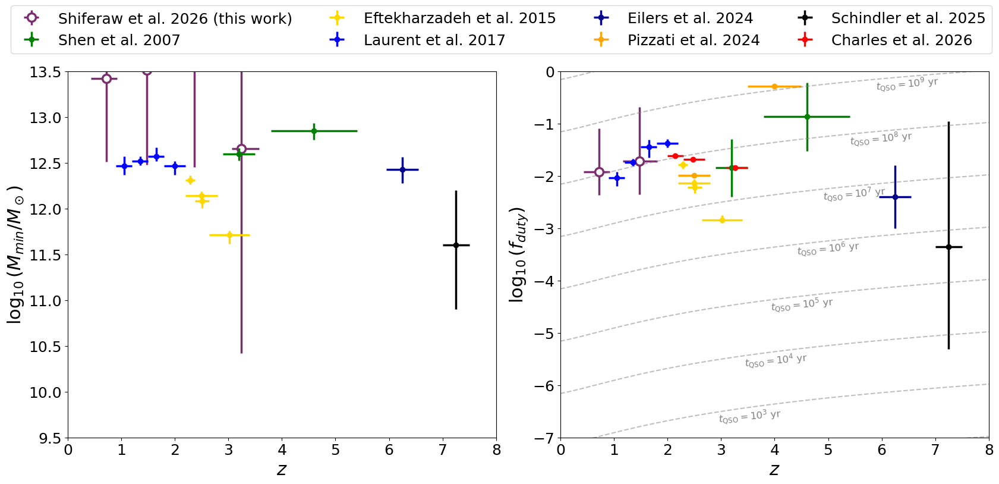

In [195]:
fig = plt.figure(figsize = (20, 8))
gs = gridspec.GridSpec(1, 2, wspace = 0.15, hspace = 0.15)

i = 0
ax1 = fig.add_subplot(gs[0])

M_min_lo, M_min_hi = np.array(err['log10(M_min)'][L_bins[i]])[:,0], np.array(err['log10(M_min)'][L_bins[i]])[:,1]
zbin = 1/np.array(a_zbin[L_bins[i]])-1
xerr = [zbin-np.array(z_sigma[L_bins[i]])[:,0], np.array(z_sigma[L_bins[i]])[:,1]-zbin]

ax1.errorbar(zbin, M_min[L_bins[i]], yerr = [M_min[L_bins[i]]-M_min_lo, M_min_hi-M_min[L_bins[i]]], 
             xerr = xerr, linestyle = 'none', marker = 'o', 
             color = cmap_theta[i], linewidth = 2.5, 
             label = 'Shiferaw et al. 2026 (this work)', zorder = 0, markeredgewidth = 2.5, markerfacecolor = 'white', markersize = 10)

ax1.set_ylabel('$\log_{10}(M_{min}/M_\odot)$')
ax1.set_xlabel('$z$')
ax1.set_ylim(9.5, 13.5)
ax1.set_xlim(0, 8)

ax1.errorbar(z_shen, Mmin_shen, yerr = [Mmin_err_lo_shen, Mmin_err_hi_shen], linestyle = 'none', xerr = z_err_shen, 
             marker = 'o', color = 'green', linewidth = 2.5, label = 'Shen et al. 2007') #https://arxiv.org/abs/2403.07986 p13
ax1.errorbar(z_centers_eft, Mmin_eft, yerr = [Mmin_err_lo_eft, Mmin_err_hi_eft], linestyle = 'none', xerr = [z_err_lo_eft, z_err_hi_eft], 
             marker = 'o', color = 'gold', linewidth = 2.5, label = 'Eftekharzadeh et al. 2015')
ax1.errorbar(z_centers_2, Mmin_2, yerr = [Mmin_err_lo_2, Mmin_err_hi_2], linestyle = 'none', xerr = [z_err_lo_2, z_err_hi_2], 
             marker = 'o', color = 'blue', linewidth = 2.5, label = 'Laurent et al. 2017')
ax1.errorbar(6.25, 12.43, yerr = [[0.15], [0.13]], linestyle = 'none', xerr = 0.3, 
             marker = 'o', color = 'darkblue', linewidth = 2.5, label = 'Eilers et al. 2024')
ax1.errorbar(7.25, 11.6, yerr = [[0.7], [0.6]], linestyle = 'none', xerr = 0.25, 
             marker = 'o', color = 'black', linewidth = 2.5, label = 'Schindler et al. 2025') #https://arxiv.org/abs/2510.08455 abstract

ax1 = fig.add_subplot(gs[1])

f_duty_lo, f_duty_hi = np.array(err['log10(f_duty)'][L_bins[i]])[:,0], np.array(err['log10(f_duty)'][L_bins[i]])[:,1]
ax1.errorbar(zbin, f_duty[L_bins[i]], yerr = [f_duty[L_bins[i]]-f_duty_lo, f_duty_hi-f_duty[L_bins[i]]], linestyle = 'none', xerr = xerr, 
             marker = 'o', color = cmap_theta[i], linewidth = 2.5, label = 'Shiferaw et al. 2026 (this work)', markeredgewidth = 2.5, markerfacecolor = 'white', markersize = 10)

ax1.set_ylabel('$\log_{10}(f_{duty})$')
ax1.set_xlabel('$z$')
ax1.set_ylim(-7,0)

ax1.errorbar(z_shen, fduty_shen, yerr = [fduty_err_lo_shen, fduty_err_hi_shen], linestyle = 'none', xerr = z_err_shen, 
             marker = 'o', color = 'green', linewidth = 2.5, label = 'Shen et al. 2007')
ax1.errorbar(z_centers_eft, fduty_eft, yerr = [fduty_err_lo_eft, fduty_err_hi_eft], linestyle = 'none', xerr = [z_err_lo_eft, z_err_hi_eft], 
             marker = 'o', color = 'gold', linewidth = 2.5, label = 'Eftekharzadeh et al. 2015')
ax1.errorbar(z_centers_2, fduty_2, yerr = [fduty_err_lo_2, fduty_err_hi_2], linestyle = 'none', xerr = [z_err_lo_2, z_err_hi_2], 
             marker = 'o', color = 'blue', linewidth = 2.5, label = 'Laurent et al. 2017')
ax1.errorbar(6.25, np.log10(0.4/100), yerr = [[np.log10(0.4/100)-np.log10((0.4-0.3)/100)], [np.log10((1.2+0.4)/100)-np.log10(0.4/100)]], linestyle = 'none', xerr = 0.3, 
             marker = 'o', color = 'darkblue', linewidth = 2.5, label = 'Eilers et al. 2024') #https://arxiv.org/abs/2403.07986 p13
ax1.errorbar(z_pizzati, fduty_pizzati, yerr = [fduty_err_lo_pizzati, fduty_err_hi_pizzati], linestyle = 'none', xerr = z_err_pizzati, 
             marker = 'o', color = 'orange', linewidth = 2.5, label = 'Pizzati et al. 2024') #https://arxiv.org/abs/2311.17181 table 3
ax1.errorbar(7.25, -3.36, yerr = [[1.95], [2.4]], linestyle = 'none', xerr = 0.25, 
             marker = 'o', color = 'black', linewidth = 2.5, label = 'Schindler et al. 2025') #https://arxiv.org/abs/2510.08455 sec. 4.4
ax1.errorbar(z_charles, fduty_charles, yerr = [fduty_err_lo_charles, fduty_err_hi_charles], linestyle = 'none', xerr = [z_err_lo_charles, z_err_hi_charles], 
             marker = 'o', color = 'red', linewidth = 2.5, label = 'Charles et al. 2026') #https://arxiv.org/abs/2606.27115 table 2

d = 3
start = 15
z_linspace = np.linspace(0,8)
for i, t in enumerate([1e2,1e3,1e4,1e5, 1e6, 1e7, 1e8, 1e9, 1e10]):
    fduty_linspace = t*u.yr/(1/Planck18.H(z_linspace)).to('yr')
    ax1.plot(z_linspace, np.log10(fduty_linspace), color = 'grey', alpha = 0.5, linestyle = '--')

    if (t>1e2) and (t<1e10):
        ax1.text(z_linspace[start:][::d][i], np.log10(fduty_linspace)[start:][::d][i]-0.2, 
                    r'$t_{\rm QSO} = 10^{%d}$ yr' % int(np.log10(t)), color='grey', fontsize = 12, rotation = 5,)

ax1.legend(ncol=4, bbox_to_anchor = (0.025, 0.7, 1, 0.5))
ax1.set_xlim(0, 8)

plt.show()

<>:16: SyntaxWarning: invalid escape sequence '\l'
<>:27: SyntaxWarning: invalid escape sequence '\l'
<>:16: SyntaxWarning: invalid escape sequence '\l'
<>:27: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_13410/1667617022.py:16: SyntaxWarning: invalid escape sequence '\l'
  ax1.set_ylabel('$\log_{10}(M_{min}/M_\odot)$')
/tmp/ipykernel_13410/1667617022.py:27: SyntaxWarning: invalid escape sequence '\l'
  ax1.set_ylabel('$\log_{10}(f_{duty})$')


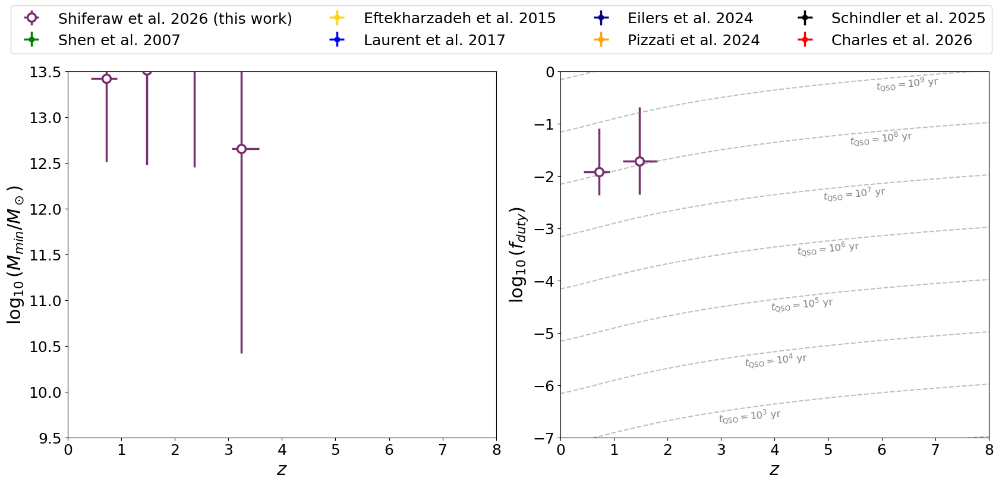

In [196]:
fig = plt.figure(figsize = (20, 8))
gs = gridspec.GridSpec(1, 2, wspace = 0.15, hspace = 0.15)

i = 0
ax1 = fig.add_subplot(gs[0])

M_min_lo, M_min_hi = np.array(err['log10(M_min)'][L_bins[i]])[:,0], np.array(err['log10(M_min)'][L_bins[i]])[:,1]
zbin = 1/np.array(a_zbin[L_bins[i]])-1
xerr = [zbin-np.array(z_sigma[L_bins[i]])[:,0], np.array(z_sigma[L_bins[i]])[:,1]-zbin]

ax1.errorbar(zbin, M_min[L_bins[i]], yerr = [M_min[L_bins[i]]-M_min_lo, M_min_hi-M_min[L_bins[i]]], 
             xerr = xerr, linestyle = 'none', marker = 'o', 
             color = cmap_theta[i], linewidth = 2.5, 
             label = 'Shiferaw et al. 2026 (this work)', zorder = 0, markeredgewidth = 2.5, markerfacecolor = 'white', markersize = 10)
    
ax1.set_ylabel('$\log_{10}(M_{min}/M_\odot)$')
ax1.set_xlabel('$z$')
ax1.set_ylim(9.5, 13.5)
ax1.set_xlim(0, 8)

ax1 = fig.add_subplot(gs[1])

f_duty_lo, f_duty_hi = np.array(err['log10(f_duty)'][L_bins[i]])[:,0], np.array(err['log10(f_duty)'][L_bins[i]])[:,1]
ax1.errorbar(zbin, f_duty[L_bins[i]], yerr = [f_duty[L_bins[i]]-f_duty_lo, f_duty_hi-f_duty[L_bins[i]]], linestyle = 'none', xerr = xerr, 
             marker = 'o', color = cmap_theta[i], linewidth = 2.5, label = 'Shiferaw et al. 2026 (this work)', markeredgewidth = 2.5, markerfacecolor = 'white', markersize = 10)
   
ax1.set_ylabel('$\log_{10}(f_{duty})$')
ax1.set_xlabel('$z$')
ax1.set_ylim(-7,0)
ax1.set_xlim(0, 8)
ax1.errorbar(np.array(z_shen)*10, np.array(fduty_shen)*10, yerr = [fduty_err_lo_shen, fduty_err_hi_shen], linestyle = 'none', xerr = z_err_shen, 
             marker = 'o', color = 'green', linewidth = 2.5, label = 'Shen et al. 2007')
ax1.errorbar(np.array(z_centers_eft)*10, np.array(fduty_eft)*10, yerr = [fduty_err_lo_eft, fduty_err_hi_eft], linestyle = 'none', xerr = [z_err_lo_eft, z_err_hi_eft], 
             marker = 'o', color = 'gold', linewidth = 2.5, label = 'Eftekharzadeh et al. 2015')
ax1.errorbar(np.array(z_centers_2)*10, np.array(fduty_2)*10, yerr = [fduty_err_lo_2, fduty_err_hi_2], linestyle = 'none', xerr = [z_err_lo_2, z_err_hi_2], 
             marker = 'o', color = 'blue', linewidth = 2.5, label = 'Laurent et al. 2017')
ax1.errorbar(6.25*10, np.log10(0.4/100)*10, yerr = [[np.log10(0.4/100)-np.log10((0.4-0.3)/100)], [np.log10((1.2+0.4)/100)-np.log10(0.4/100)]], linestyle = 'none', xerr = 0.3, 
             marker = 'o', color = 'darkblue', linewidth = 2.5, label = 'Eilers et al. 2024') #https://arxiv.org/abs/2403.07986 p13
ax1.errorbar(np.array(z_pizzati)*10, fduty_pizzati, yerr = [fduty_err_lo_pizzati, fduty_err_hi_pizzati], linestyle = 'none', xerr = z_err_pizzati, 
             marker = 'o', color = 'orange', linewidth = 2.5, label = 'Pizzati et al. 2024') #https://arxiv.org/abs/2311.17181 table 3
ax1.errorbar(7.25*10, -3.36*10, yerr = [[1.95], [2.4]], linestyle = 'none', xerr = 0.25, 
             marker = 'o', color = 'black', linewidth = 2.5, label = 'Schindler et al. 2025') #https://arxiv.org/abs/2510.08455 sec. 4.4
ax1.errorbar(np.array(z_charles)*10, fduty_charles, yerr = [fduty_err_lo_charles, fduty_err_hi_charles], linestyle = 'none', xerr = [z_err_lo_charles, z_err_hi_charles], 
             marker = 'o', color = 'red', linewidth = 2.5, label = 'Charles et al. 2026') #https://arxiv.org/abs/2606.27115 table 2

for i, t in enumerate([1e2,1e3,1e4,1e5, 1e6, 1e7, 1e8, 1e9, 1e10]):
    fduty_linspace = t*u.yr/(1/Planck18.H(z_linspace)).to('yr')
    ax1.plot(z_linspace, np.log10(fduty_linspace), color = 'grey', alpha = 0.5, linestyle = '--')

    if (t>1e2) and (t<1e10):
        ax1.text(z_linspace[start:][::d][i], np.log10(fduty_linspace)[start:][::d][i]-0.2, 
                    r'$t_{\rm QSO} = 10^{%d}$ yr' % int(np.log10(t)), color='grey', fontsize = 12, rotation = 5,)
        
ax1.legend(ncol=4, bbox_to_anchor = (0.025, 0.7, 1, 0.5))

plt.show()

<>:14: SyntaxWarning: invalid escape sequence '\l'
<>:27: SyntaxWarning: invalid escape sequence '\l'
<>:14: SyntaxWarning: invalid escape sequence '\l'
<>:27: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_13410/1473133220.py:14: SyntaxWarning: invalid escape sequence '\l'
  plt.ylabel('$\log_{10}(f_{duty})$')
/tmp/ipykernel_13410/1473133220.py:27: SyntaxWarning: invalid escape sequence '\l'
  first_legend = plt.legend(custom_lines, ['${:.1f}<z \leq{:.1f}$'.format(z_bins[i], z_bins[i+1]) for i in z_array], loc = 'lower left')


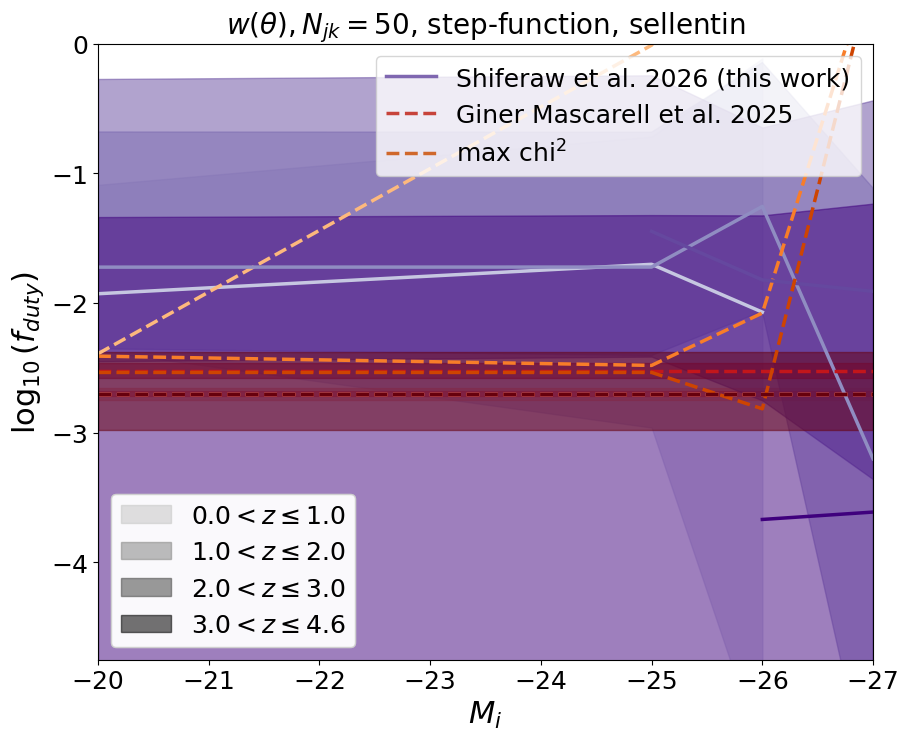

In [197]:
fig = plt.figure(figsize = (10, 8))

for i in z_array:
    
    f_duty_lo, f_duty_hi = [np.array(err['log10(f_duty)'][L])[:,0][i] for L in L_bins], [np.array(err['log10(f_duty)'][L])[:,1][i] for L in L_bins]
    plt.plot(L_bins, [f_duty[L][i] for L in L_bins], color = cmap_purple[i], linewidth = 2.5, label = 'Shiferaw et al. 2026 (this work)')
    plt.fill_between(L_bins, f_duty_lo, f_duty_hi, alpha = 0.5, color = cmap_purple[i])
    plt.axhline(np.log10(fduty)[i], label = 'Giner Mascarell et al. 2025', color = cmap_red[i], linewidth = 2.5, linestyle = '--')
    plt.fill_between(L_bins, [np.log10(np.array(fduty)+np.array(fduty)/fduty_old*fduty_err_hi)[i]]*len(L_bins), 
                     [np.log10(np.array(fduty)-np.array(fduty)/fduty_old*fduty_err_lo)[i]]*len(L_bins), alpha = 0.5, color = cmap_red[i])
    plt.plot(L_bins, [best_fit_params[L][i][0] for L in L_bins], color = cmap_orange[i], linewidth = 2.5, label = 'max chi$^2$', linestyle = '--')
    
plt.title(r'$w(\theta), N_{{jk}}={}$, step-function, sellentin'.format(N))
plt.ylabel('$\log_{10}(f_{duty})$')
plt.xlabel('$M_i$')
plt.xlim(L_bins[0], L_bins[-1])
plt.ylim(-4.75,0)

custom_lines = [Line2D([0], [0], color = purple, linestyle = '-', linewidth = 2.5),
                Line2D([0], [0], color = red, linestyle = '--', linewidth = 2.5),
                Line2D([0], [0], color = orange, linestyle = '--', linewidth = 2.5)]
second_legend = plt.legend(custom_lines, [r'Shiferaw et al. 2026 (this work)', 
                                          'Giner Mascarell et al. 2025', 'max chi$^2$'], loc = 'upper right')
fig.add_artist(second_legend)

custom_lines = [mpatches.Patch(color=cmap_grey[i], alpha = 0.5) for i in range(len(L_bins))]
first_legend = plt.legend(custom_lines, ['${:.1f}<z \leq{:.1f}$'.format(z_bins[i], z_bins[i+1]) for i in z_array], loc = 'lower left')
fig.add_artist(first_legend)

plt.show()

<>:27: SyntaxWarning: invalid escape sequence '\l'
<>:30: SyntaxWarning: invalid escape sequence '\l'
<>:27: SyntaxWarning: invalid escape sequence '\l'
<>:30: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_13410/3210256070.py:27: SyntaxWarning: invalid escape sequence '\l'
  ax1.set_ylabel('$\log_{10}(M_{min}/M_\odot)$')
/tmp/ipykernel_13410/3210256070.py:30: SyntaxWarning: invalid escape sequence '\l'
  ax2.set_ylabel('$\log_{10}(f_{duty})$')


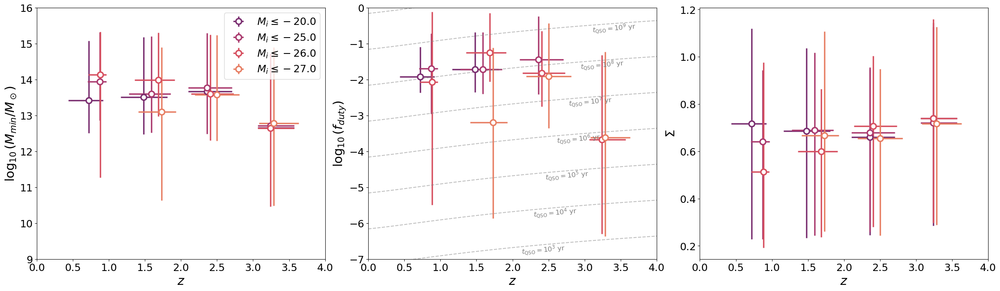

In [198]:
fig = plt.figure(figsize = (30, 8))
gs = gridspec.GridSpec(1, 3, wspace = 0.15, hspace = 0.15)

ax1 = fig.add_subplot(gs[0])
ax2 = fig.add_subplot(gs[1])
ax3 = fig.add_subplot(gs[2])

for i in range(len(L_bins)):
    
    M_min_lo, M_min_hi = err_L_z['log10(M_min)'][L_bins[i]][:,0], err_L_z['log10(M_min)'][L_bins[i]][:,1]

    zbin = 1/np.array(a_zbin[L_bins[i]])-1
    xerr = [zbin-np.array(z_sigma[L_bins[i]])[:,0], np.array(z_sigma[L_bins[i]])[:,1]-zbin]

    ax1.errorbar(zbin, M_min[L_bins[i]], yerr = [M_min[L_bins[i]]-M_min_lo, M_min_hi-M_min[L_bins[i]]], 
                 xerr = xerr, linestyle = 'none', marker = 'o', label = r'$M_i\leq{}$'.format(L_bins[i]),
                 color = cmap_theta[i], linewidth = 2.5, markeredgewidth = 2.5, markerfacecolor = 'white', markersize = 10)#, 
    
    f_duty_lo, f_duty_hi = err_L_z['log10(f_duty)'][L_bins[i]][:,0], err_L_z['log10(f_duty)'][L_bins[i]][:,1]
    ax2.errorbar(zbin, f_duty[L_bins[i]], yerr = [f_duty[L_bins[i]]-f_duty_lo, f_duty_hi-f_duty[L_bins[i]]], linestyle = 'none', xerr = xerr, 
                 marker = 'o', color = cmap_theta[i], linewidth = 2.5, markeredgewidth = 2.5, markerfacecolor = 'white', markersize = 10)

    Sigma_lo, Sigma_hi = np.array(err_L_z['Sigma'][L_bins[i]])[:,0], np.array(err_L_z['Sigma'][L_bins[i]])[:,1]
    ax3.errorbar(zbin, Sigma[L_bins[i]], yerr = [Sigma[L_bins[i]]-Sigma_lo, Sigma_hi-Sigma[L_bins[i]]], linestyle = 'none', xerr = xerr, 
                 marker = 'o', color = cmap_theta[i], linewidth = 2.5, markeredgewidth = 2.5, markerfacecolor = 'white', markersize = 10)

ax1.set_ylabel('$\log_{10}(M_{min}/M_\odot)$')
ax1.set_xlabel('$z$')

ax2.set_ylabel('$\log_{10}(f_{duty})$')
ax2.set_xlabel('$z$')

ax3.set_ylabel(labels[-1])
ax3.set_xlabel('$z$')

# custom_lines = [mpatches.Patch(color=cmap_theta[i]) for i in range(len(L_bins))]
# first_legend = ax1.legend(custom_lines, [r'$M_i\leq{}$'.format(L_bins[i]) for i in range(len(L_bins))])#, title = 'Shiferaw et al. 2026 (this work)',
# fig.add_artist(first_legend)
ax1.legend()

d = 1
start = 12
for i, t in enumerate([1e2,1e3,1e4,1e5, 1e6, 1e7, 1e8, 1e9, 1e10]):
    fduty_linspace = t*u.yr/(1/Planck18.H(z_linspace)).to('yr')
    ax2.plot(z_linspace, np.log10(fduty_linspace), color = 'grey', alpha = 0.5, linestyle = '--')

    if (t>1e2) and (t<1e10):
        ax2.text(z_linspace[start:][::d][i], np.log10(fduty_linspace)[start:][::d][i]-0.2, 
                    r'$t_{\rm QSO} = 10^{%d}$ yr' % int(np.log10(t)), color='grey', fontsize = 12, rotation = 5,)

ax1.set_xlim(0, 4)
ax2.set_xlim(0, 4)
ax3.set_xlim(0, 4)
ax2.set_ylim(-7,0)
ax1.set_ylim(9,16)

# plt.savefig('../figures/Mmin_fduty_wtheta.pdf', bbox_inches = 'tight')
plt.show()

In [199]:
sigma_pizzati = np.array([0.52, 0.20])
sigma_err_pizzati = [0.22, 0.07], [0.18, 0.06]

gamma_pizzati = np.array([1.15, 2])
gamma_err_pizzati = [0.07, 0.23], [0.06, 0.22]

Sigma_pizzati = sigma_pizzati/gamma_pizzati
Sigma_err_pizzati = Sigma_pizzati*np.sqrt((sigma_err_pizzati/sigma_pizzati)**2+(gamma_err_pizzati/gamma_pizzati)**2)

<>:16: SyntaxWarning: invalid escape sequence '\l'
<>:38: SyntaxWarning: invalid escape sequence '\l'
<>:16: SyntaxWarning: invalid escape sequence '\l'
<>:38: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_13410/821108759.py:16: SyntaxWarning: invalid escape sequence '\l'
  ax1.set_ylabel('$\log_{10}(M_{min}/M_\odot)$')
/tmp/ipykernel_13410/821108759.py:38: SyntaxWarning: invalid escape sequence '\l'
  ax1.set_ylabel('$\log_{10}(f_{duty})$')


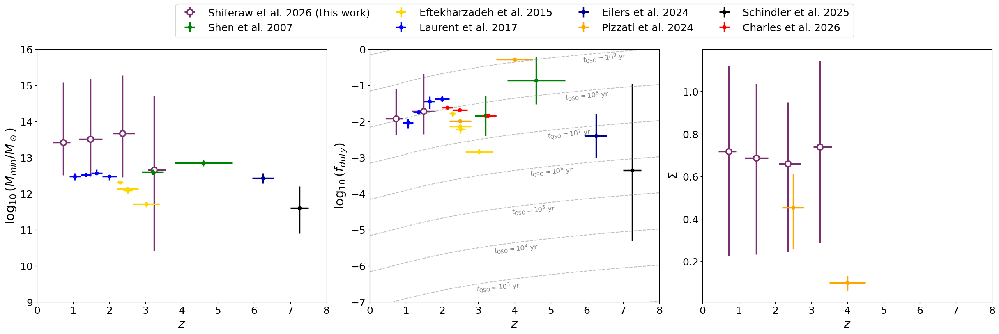

In [200]:
fig = plt.figure(figsize = (30, 8))
gs = gridspec.GridSpec(1, 3, wspace = 0.15, hspace = 0.15)

i = 0
ax1 = fig.add_subplot(gs[0])

M_min_lo, M_min_hi = np.array(err['log10(M_min)'][L_bins[i]])[:,0], np.array(err['log10(M_min)'][L_bins[i]])[:,1]
zbin = 1/np.array(a_zbin[L_bins[i]])-1
xerr = [zbin-np.array(z_sigma[L_bins[i]])[:,0], np.array(z_sigma[L_bins[i]])[:,1]-zbin]

ax1.errorbar(zbin, M_min[L_bins[i]], yerr = [M_min[L_bins[i]]-M_min_lo, M_min_hi-M_min[L_bins[i]]], 
             xerr = xerr, linestyle = 'none', marker = 'o', 
             color = cmap_theta[i], linewidth = 2.5, 
             label = 'Shiferaw et al. 2026 (this work)', zorder = 0, markeredgewidth = 2.5, markerfacecolor = 'white', markersize = 10)
    
ax1.set_ylabel('$\log_{10}(M_{min}/M_\odot)$')
ax1.set_xlabel('$z$')
ax1.set_ylim(9, 16)
ax1.set_xlim(0, 8)

ax1.errorbar(z_shen, Mmin_shen, yerr = [Mmin_err_lo_shen, Mmin_err_hi_shen], linestyle = 'none', xerr = z_err_shen, 
             marker = 'o', color = 'green', linewidth = 2.5, label = 'Shen et al. 2007') #https://arxiv.org/abs/2403.07986 p13
ax1.errorbar(z_centers_eft, Mmin_eft, yerr = [Mmin_err_lo_eft, Mmin_err_hi_eft], linestyle = 'none', xerr = [z_err_lo_eft, z_err_hi_eft], 
             marker = 'o', color = 'gold', linewidth = 2.5, label = 'Eftekharzadeh et al. 2015')
ax1.errorbar(z_centers_2, Mmin_2, yerr = [Mmin_err_lo_2, Mmin_err_hi_2], linestyle = 'none', xerr = [z_err_lo_2, z_err_hi_2], 
             marker = 'o', color = 'blue', linewidth = 2.5, label = 'Laurent et al. 2017')
ax1.errorbar(6.25, 12.43, yerr = [[0.15], [0.13]], linestyle = 'none', xerr = 0.3, 
             marker = 'o', color = 'darkblue', linewidth = 2.5, label = 'Eilers et al. 2024')
ax1.errorbar(7.25, 11.6, yerr = [[0.7], [0.6]], linestyle = 'none', xerr = 0.25, 
             marker = 'o', color = 'black', linewidth = 2.5, label = 'Schindler et al. 2025') #https://arxiv.org/abs/2510.08455 abstract

ax1 = fig.add_subplot(gs[1])

f_duty_lo, f_duty_hi = np.array(err['log10(f_duty)'][L_bins[i]])[:,0], np.array(err['log10(f_duty)'][L_bins[i]])[:,1]
ax1.errorbar(zbin, f_duty[L_bins[i]], yerr = [f_duty[L_bins[i]]-f_duty_lo, f_duty_hi-f_duty[L_bins[i]]], linestyle = 'none', xerr = xerr, 
             marker = 'o', color = cmap_theta[i], linewidth = 2.5, label = 'Shiferaw et al. 2026 (this work)', markeredgewidth = 2.5, markerfacecolor = 'white', markersize = 10)
   
ax1.set_ylabel('$\log_{10}(f_{duty})$')
ax1.set_xlabel('$z$')
ax1.set_ylim(-7,0)

ax1.errorbar(z_shen, fduty_shen, yerr = [fduty_err_lo_shen, fduty_err_hi_shen], linestyle = 'none', xerr = z_err_shen, 
             marker = 'o', color = 'green', linewidth = 2.5, label = 'Shen et al. 2007')
ax1.errorbar(z_centers_eft, fduty_eft, yerr = [fduty_err_lo_eft, fduty_err_hi_eft], linestyle = 'none', xerr = [z_err_lo_eft, z_err_hi_eft], 
             marker = 'o', color = 'gold', linewidth = 2.5, label = 'Eftekharzadeh et al. 2015')
ax1.errorbar(z_centers_2, fduty_2, yerr = [fduty_err_lo_2, fduty_err_hi_2], linestyle = 'none', xerr = [z_err_lo_2, z_err_hi_2], 
             marker = 'o', color = 'blue', linewidth = 2.5, label = 'Laurent et al. 2017')
ax1.errorbar(6.25, np.log10(0.4/100), yerr = [[np.log10(0.4/100)-np.log10((0.4-0.3)/100)], [np.log10((1.2+0.4)/100)-np.log10(0.4/100)]], linestyle = 'none', xerr = 0.3, 
             marker = 'o', color = 'darkblue', linewidth = 2.5, label = 'Eilers et al. 2024') #https://arxiv.org/abs/2403.07986 p13
ax1.errorbar(z_pizzati, fduty_pizzati, yerr = [fduty_err_lo_pizzati, fduty_err_hi_pizzati], linestyle = 'none', xerr = z_err_pizzati, 
             marker = 'o', color = 'orange', linewidth = 2.5, label = 'Pizzati et al. 2024') #https://arxiv.org/abs/2311.17181 table 3
ax1.errorbar(7.25, -3.36, yerr = [[1.95], [2.4]], linestyle = 'none', xerr = 0.25, 
             marker = 'o', color = 'black', linewidth = 2.5, label = 'Schindler et al. 2025') #https://arxiv.org/abs/2510.08455 sec. 4.4
ax1.errorbar(z_charles, fduty_charles, yerr = [fduty_err_lo_charles, fduty_err_hi_charles], linestyle = 'none', xerr = [z_err_lo_charles, z_err_hi_charles], 
             marker = 'o', color = 'red', linewidth = 2.5, label = 'Charles et al. 2026') #https://arxiv.org/abs/2606.27115 table 2

d = 3
start = 15
z_linspace = np.linspace(0,8)
for i, t in enumerate([1e2,1e3,1e4,1e5, 1e6, 1e7, 1e8, 1e9, 1e10]):
    fduty_linspace = t*u.yr/(1/Planck18.H(z_linspace)).to('yr')
    ax1.plot(z_linspace, np.log10(fduty_linspace), color = 'grey', alpha = 0.5, linestyle = '--')

    if (t>1e2) and (t<1e10):
        ax1.text(z_linspace[start:][::d][i], np.log10(fduty_linspace)[start:][::d][i]-0.2, 
                    r'$t_{\rm QSO} = 10^{%d}$ yr' % int(np.log10(t)), color='grey', fontsize = 12, rotation = 5,)

ax1.legend(ncol=4, loc='upper center', bbox_to_anchor=(0.5, 1.2))
ax1.set_xlim(0, 8)

ax1 = fig.add_subplot(gs[2])
i = 0
Sigma_lo, Sigma_hi = np.array(err['Sigma'][L_bins[i]])[:,0], np.array(err['Sigma'][L_bins[i]])[:,1]
ax1.errorbar(zbin, Sigma[L_bins[i]], yerr = [Sigma[L_bins[i]]-Sigma_lo, Sigma_hi-Sigma[L_bins[i]]], linestyle = 'none', xerr = xerr, 
             marker = 'o', color = cmap_theta[i], linewidth = 2.5, label = 'Shiferaw et al. 2026 (this work)', markeredgewidth = 2.5, markerfacecolor = 'white', markersize = 10)
ax1.errorbar(z_pizzati, Sigma_pizzati, yerr = Sigma_err_pizzati, linestyle = 'none', xerr = z_err_pizzati, 
             marker = 'o', color = 'orange', linewidth = 2.5, label = 'Pizzati et al. 2024') #https://arxiv.org/abs/2606.27115 table 2
ax1.set_ylabel(labels[-1])
ax1.set_xlabel('$z$')
ax1.set_xlim(0, 8)

plt.show()

## Calculate 16th and 84th percentile of derived parameters

In [201]:
cmap_purple = plt.get_cmap('Purples')(np.linspace(0.333, 0.999, len(L_bins)))

In [202]:
cmap_rocket = sns.color_palette("flare_r", n_colors = len(L_bins))
cmap_rocket

[(0.47936222, 0.18006056, 0.43733022),
 (0.66635279, 0.22717328, 0.43008427),
 (0.83765537, 0.30784814, 0.3723105),
 (0.90732341, 0.4939774, 0.38990532)]

<>:40: SyntaxWarning: invalid escape sequence '\l'
<>:40: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_13410/103225897.py:40: SyntaxWarning: invalid escape sequence '\l'
  ax1.set_title('${:.1f}<z \leq{:.1f}$'.format(z_bins[j], z_bins[j+1]))


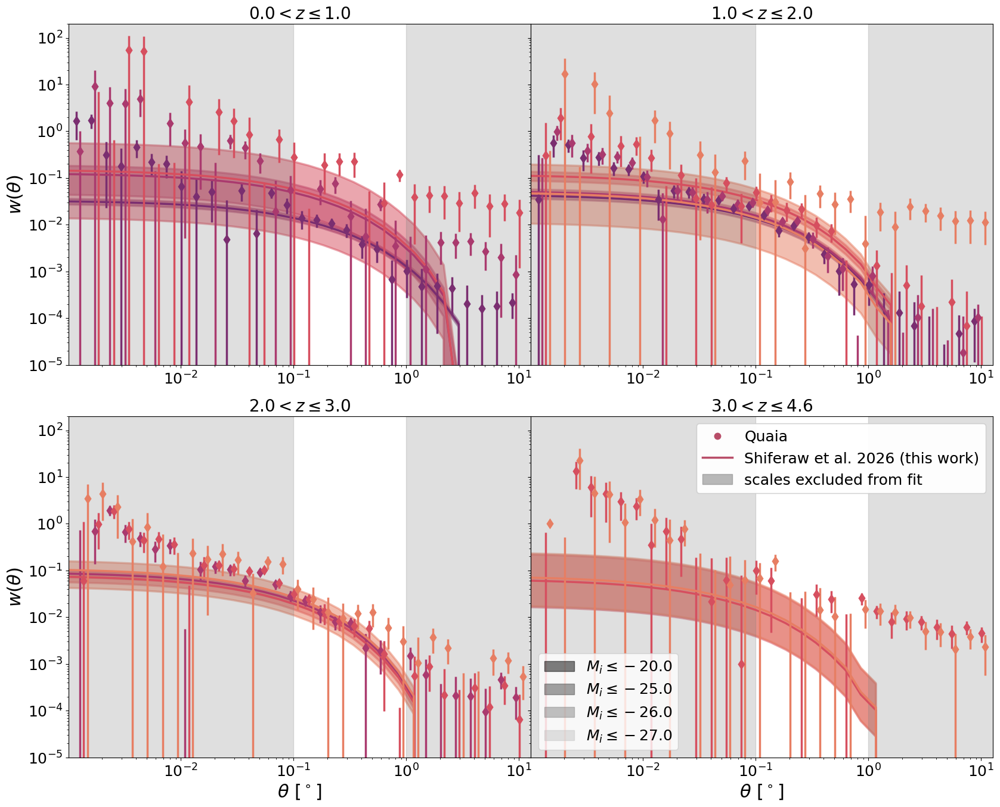

In [203]:
fig = plt.figure(figsize = (20, 16))
gs = gridspec.GridSpec(2, 2, wspace = 0, hspace = 0.15)
xlim = 10**(np.log10(quaia.recenter(thetabins))[0] - delta_xlim), 10**(np.log10(quaia.recenter(thetabins))[-1] + 5/2*delta_xlim) 
ylim = 1e-5, 2e2
y = np.linspace(ylim[0], ylim[-1])

for j in z_array:
    
    ax1 = fig.add_subplot(gs[j])

    for i in range(len(L_bins)):

        if (((i<3) and (N_q[L_bins[i]][j]>N_q[L_bins[i+1]][j])) or (i==3)) and (np.round(N_q[L_bins[i]][j]/1000)>1):

            C = np.load('../results/cov_wtheta_G{}_rmin{}_rmax{}_nbins{}_zmin{}zmax{}_Lmax{}_N{}_{}_MC_b{}.npy'.format(
                G_hi, rmin, rmax, nbins, z_bins[j], z_bins[j+1], L_bins[i], N, cosmo, b))
            
            ax1.errorbar(10**(np.log10(quaia.recenter(thetabins)) + i*delta_xlim/2), wp_chi2[L_bins[i]][j], linewidth = 2.5, marker = 'd', 
                         label = r'Quaia', color = cmap_theta[i], yerr = np.sqrt(np.diag(C)), markeredgewidth = 2.5, linestyle = 'none')
            
            wp_2h_samples=[]
            for l in range(len(f_duty_samples[L_bins[i]][j])):
                n_m=HOD_scatter(10**f_duty_samples[L_bins[i]][j][l], M_min_samples[L_bins[i]][j][l], bins, Sigma_samples[L_bins[i]][j][l])
                wp_2h_sample = wtheta_2h_optimized(bins, n_m, H0_c_dN_dz_norm[L_bins[i]][j])
                wp_2h_samples.append(wp_2h_sample)
            wp_2h_16, wp_2h_50, wp_2h_84 = np.percentile(wp_2h_samples, [16, 50, 84], axis=0)

            ax1.plot(thetabins, wp_2h_50, linewidth = 2.5,
                     label = r'$w_{{q,2h}}(f_{{duty}}=10^{{{:.2f}}}, M_{{min}}=10^{{{:.2f}}}M_\odot)$'.format(f_duty[L_bins[i]][j], 
                                                                                                                M_min[L_bins[i]][j]), 
                     color = cmap_theta[i])
            ax1.fill_between(thetabins, wp_2h_16, wp_2h_84, linewidth = 2.5, alpha = 0.5, color = cmap_theta[i])
            
    if quaia.recenter(thetabins)[-1] > 1:
        ax1.fill_betweenx(y, x1 = xlim[0], x2 = 10**log_thetamin, color = 'grey', 
                      alpha = 0.25, label = 'scales excluded from fit')
        ax1.fill_betweenx(y, x1 = 1, x2 = xlim[-1], color = 'grey', 
                          alpha = 0.25)

    ax1.set_title('${:.1f}<z \leq{:.1f}$'.format(z_bins[j], z_bins[j+1]))
    ax1.set_yscale('log')
    ax1.set_xscale('log')
    ax1.set_xlim(xlim)
    ax1.set_ylim(ylim)
    
    if j%2==0:
        ax1.set_ylabel(r'$w(\theta)$')
    else:
        ax1.set_yticklabels([])

    if j>1:
        ax1.set_xlabel(r'$\theta$ $[^\circ]$') # projected

custom_lines = [mpatches.Patch(color=cmap_grey[::-1][l], alpha = 0.5) for l in range(len(L_bins))]
first_legend = ax1.legend(custom_lines, [r'$M_i\leq{}$'.format(L_bins[i]) for i in range(len(L_bins))], loc = 'lower left')
fig.add_artist(first_legend)

custom_lines = [Line2D([0], [0], color = np.mean(cmap_theta, axis = 0), linestyle = 'None', marker = 'o', linewidth = 2.5, markeredgewidth = 2.5), #cmap_red
                Line2D([0], [0], color = np.mean(cmap_theta, axis = 0), linestyle = '-', linewidth = 2.5), mpatches.Patch(color='grey', alpha = 0.5)] #blue
second_legend = ax1.legend(custom_lines, [r'Quaia', r'Shiferaw et al. 2026 (this work)', 'scales excluded from fit'], loc = 'upper right')
fig.add_artist(second_legend)

plt.show()

<>:53: SyntaxWarning: invalid escape sequence '\l'
<>:53: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_13410/335836945.py:53: SyntaxWarning: invalid escape sequence '\l'
  first_legend = ax1.legend(custom_lines, ['${:.1f}<z \leq{:.1f}$'.format(z_bins[l], z_bins[l+1]) for l in z_array])


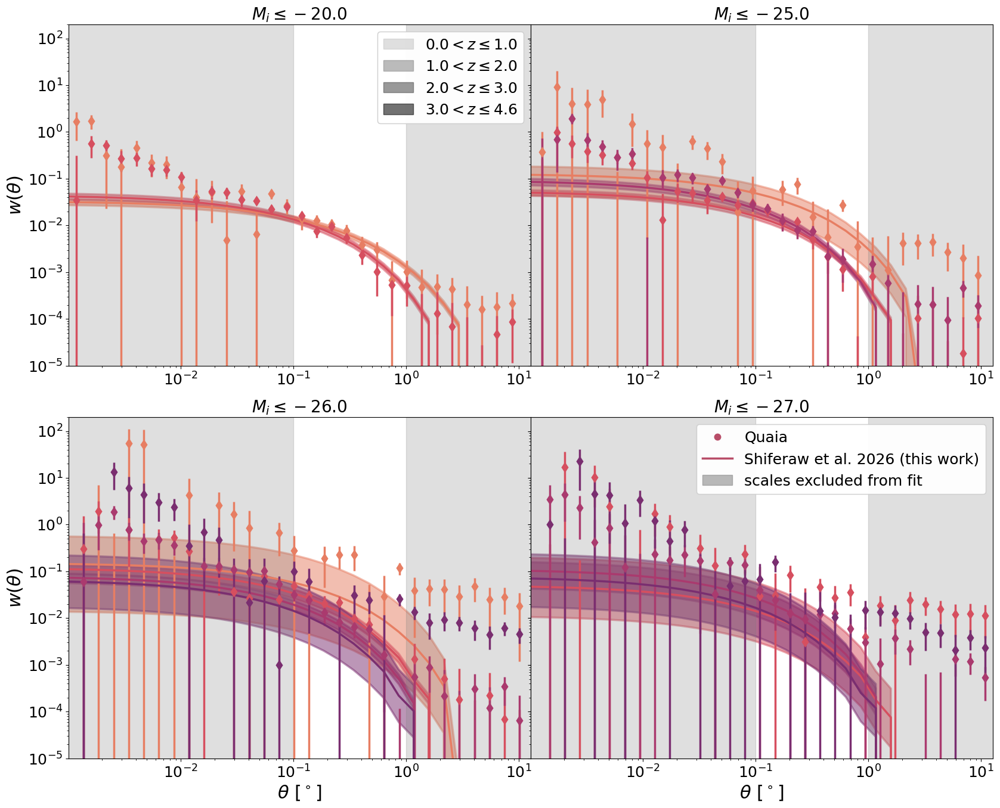

In [204]:
fig = plt.figure(figsize = (20, 16))
gs = gridspec.GridSpec(2, 2, wspace = 0, hspace = 0.15)

for i in range(len(L_bins)):

    ax1 = fig.add_subplot(gs[i])

    for j in z_array:

        if (((i<3) and (N_q[L_bins[i]][j]>N_q[L_bins[i+1]][j])) or (i==3)) and (np.round(N_q[L_bins[i]][j]/1000)>1):

            C = np.load('../results/cov_wtheta_G{}_rmin{}_rmax{}_nbins{}_zmin{}zmax{}_Lmax{}_N{}_{}_MC_b{}.npy'.format(
                G_hi, rmin, rmax, nbins, z_bins[j], z_bins[j+1], L_bins[i], N, cosmo, b))
            
            ax1.errorbar(10**(np.log10(quaia.recenter(thetabins)) + i*delta_xlim/2), wp_chi2[L_bins[i]][j], linewidth = 2.5, marker = 'd', 
                         label = r'Quaia', color = cmap_theta[::-1][j], yerr = np.sqrt(np.diag(C)), markeredgewidth = 2.5, linestyle = 'none')
            
            wp_2h_samples=[]
            for l in range(len(f_duty_samples[L_bins[i]][j])):
                n_m=HOD_scatter(10**f_duty_samples[L_bins[i]][j][l], M_min_samples[L_bins[i]][j][l], bins, Sigma_samples[L_bins[i]][j][l])
                wp_2h_sample = wtheta_2h_optimized(bins, n_m, H0_c_dN_dz_norm[L_bins[i]][j])
                wp_2h_samples.append(wp_2h_sample)
            wp_2h_16, wp_2h_50, wp_2h_84 = np.percentile(wp_2h_samples, [16, 50, 84], axis=0)

            ax1.plot(thetabins, wp_2h_50, linewidth = 2.5,
                     label = r'$w_{{q,2h}}(f_{{duty}}=10^{{{:.2f}}}, M_{{min}}=10^{{{:.2f}}}M_\odot)$'.format(f_duty[L_bins[i]][j], 
                                                                                                                M_min[L_bins[i]][j]), 
                     color = cmap_theta[::-1][j])
            ax1.fill_between(thetabins, wp_2h_16, wp_2h_84, linewidth = 2.5, alpha = 0.5, color = cmap_theta[::-1][j])
            
    if quaia.recenter(thetabins)[-1] > 1:
        ax1.fill_betweenx(y, x1 = xlim[0], x2 = 10**log_thetamin, color = 'grey', 
                      alpha = 0.25, label = 'scales excluded from fit')
        ax1.fill_betweenx(y, x1 = 1, x2 = xlim[-1], color = 'grey', 
                          alpha = 0.25)

    ax1.set_title(r'$M_i\leq{}$'.format(L_bins[i]))
    ax1.set_yscale('log')
    ax1.set_xscale('log')
    ax1.set_xlim(xlim)
    ax1.set_ylim(ylim)
    
    if i%2==0:
        ax1.set_ylabel(r'$w(\theta)$')
    else:
        ax1.set_yticklabels([])

    if i>1:
        ax1.set_xlabel(r'$\theta$ $[^\circ]$') # projected

    if i ==0:
        custom_lines = [mpatches.Patch(color=cmap_grey[l], alpha = 0.5) for l in range(len(L_bins))]
        first_legend = ax1.legend(custom_lines, ['${:.1f}<z \leq{:.1f}$'.format(z_bins[l], z_bins[l+1]) for l in z_array])
        fig.add_artist(first_legend)

custom_lines = [Line2D([0], [0], color = np.mean(cmap_theta, axis = 0), linestyle = 'None', marker = 'o', linewidth = 2.5, markeredgewidth = 2.5), #cmap_rocket
                Line2D([0], [0], color = np.mean(cmap_theta, axis = 0), linestyle = '-', linewidth = 2.5), mpatches.Patch(color='grey', alpha = 0.5)] #cmap_purple
second_legend = ax1.legend(custom_lines, [r'Quaia', r'Shiferaw et al. 2026 (this work)', 'scales excluded from fit'])
fig.add_artist(second_legend)

plt.show()

<>:54: SyntaxWarning: invalid escape sequence '\l'
<>:54: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_13410/775041016.py:54: SyntaxWarning: invalid escape sequence '\l'
  ax1.set_title('$M_i\leq{}$'.format(L_bins[i]))


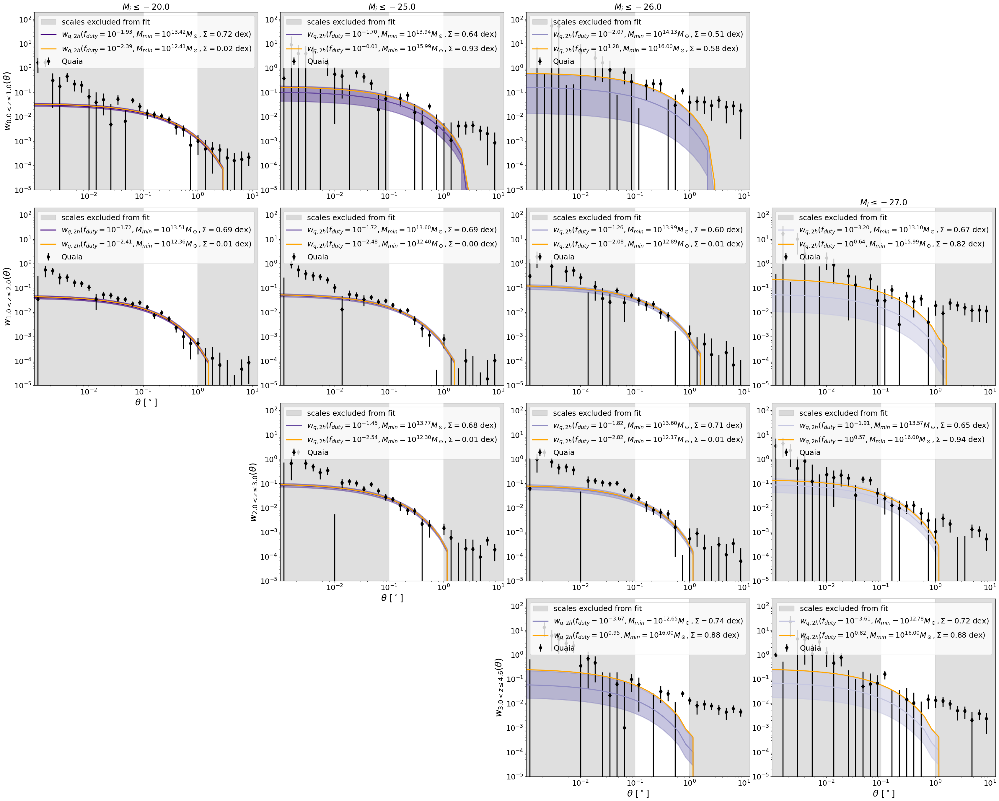

In [205]:
# remove bottom panel and just print bq somewhere
# plot!
fig = plt.figure(figsize = (42, 33.6))
gs = gridspec.GridSpec(4, 4, wspace = 0.1, hspace = 0.1)
xlim = 10**(np.log10(quaia.recenter(thetabins))[0] - delta_xlim), 10**(np.log10(quaia.recenter(thetabins))[-1] + 5/2*delta_xlim) 
ylim = 1e-5, 2e2
y = np.linspace(ylim[0], ylim[-1])

for j in range(len(z_array)):
    
    for i in range(len(L_bins)):

        if (((i<3) and (N_q[L_bins[i]][j]>N_q[L_bins[i+1]][j])) or (i==3)) and (np.round(N_q[L_bins[i]][j]/1000)>1):

            ax1 = fig.add_subplot(gs[j*4+i])

            C = np.load('../results/cov_wtheta_G{}_rmin{}_rmax{}_nbins{}_zmin{}zmax{}_Lmax{}_N{}_{}_MC_b{}.npy'.format(
                G_hi, rmin, rmax, nbins, z_bins[j], z_bins[j+1], L_bins[i], N, cosmo, b))
            
            ax1.errorbar(quaia.recenter(thetabins), wp_chi2[L_bins[i]][j], linewidth = 2.5, marker = 'd', 
                         label = r'Quaia', color = 'black', yerr = np.sqrt(np.diag(C)), markeredgewidth = 2.5, linestyle = 'none')
            
            if quaia.recenter(thetabins)[-1] > 1:
                ax1.fill_betweenx(y, x1 = xlim[0], x2 = 10**log_thetamin, color = 'grey', 
                              alpha = 0.25, label = 'scales excluded from fit')
                ax1.fill_betweenx(y, x1 = 1, x2 = xlim[-1], color = 'grey', 
                                  alpha = 0.25)
        
            # plot new fit
            n_m=HOD_scatter(10**f_duty[L_bins[i]][j], M_min[L_bins[i]][j], bins, Sigma[L_bins[i]][j])
            wp_2h_zbin = wtheta_2h_optimized(bins, n_m, H0_c_dN_dz_norm[L_bins[i]][j])
            ax1.plot(thetabins, wp_2h_zbin, linewidth = 2.5,
                     label = r'$w_{{q,2h}}(f_{{duty}}=10^{{{:.2f}}}, M_{{min}}=10^{{{:.2f}}}M_\odot, \Sigma={:.2f}$ dex)'.format(f_duty[L_bins[i]][j], 
                                                                                                                M_min[L_bins[i]][j], Sigma[L_bins[i]][j]), 
                     color = cmap_purple[::-1][i])
        
            wp_2h_samples = []
            for l in range(len(f_duty_samples[L_bins[i]][j])):
                n_m=HOD_scatter(10**f_duty_samples[L_bins[i]][j][l], M_min_samples[L_bins[i]][j][l], bins, Sigma_samples[L_bins[i]][j][l])
                wp_2h_sample = wtheta_2h_optimized(bins, n_m, H0_c_dN_dz_norm[L_bins[i]][j])
                wp_2h_samples.append(wp_2h_sample)
            wp_2h_16, wp_2h_50, wp_2h_84 = np.percentile(wp_2h_samples, [16, 50, 84], axis=0)
            ax1.fill_between(thetabins, wp_2h_16, wp_2h_84, linewidth = 2.5, alpha = 0.5, color = cmap_purple[::-1][i])
            
            #maxL point
            n_m=HOD_scatter(10**best_fit_params[L_bins[i]][j][0], best_fit_params[L_bins[i]][j][1], bins, best_fit_params[L_bins[i]][j][2])
            wp_2h_zbin = wtheta_2h_optimized(bins, n_m, H0_c_dN_dz_norm[L_bins[i]][j])
            ax1.plot(thetabins, wp_2h_zbin, linewidth = 2.5,
                     label = r'$w_{{q,2h}}(f_{{duty}}=10^{{{:.2f}}}, M_{{min}}=10^{{{:.2f}}}M_\odot, \Sigma={:.2f}$ dex)'.format(
                         best_fit_params[L_bins[i]][j][0], best_fit_params[L_bins[i]][j][1], best_fit_params[L_bins[i]][j][2]), 
                     color = 'orange')
        
            if j==0 or ((j == 1) and (i == 3)):
                ax1.set_title('$M_i\leq{}$'.format(L_bins[i]))
            ax1.set_xlim(xlim)
            ax1.set_ylim(ylim)
            ax1.legend()
            
            if i==0 or ((j>1) and (i<3) and (i!=j)):
                ax1.set_ylabel(r"$w_{{{:.1f}<z \leq{:.1f}}}(\theta)$".format(z_bins[j], z_bins[j+1]))
        
            if j > 2 or ((j>0) and (i<2) and (i!=j)):
                ax1.set_xlabel(r'$\theta$ $[^\circ]$') # projected

            ax1.set_xscale('log')
            ax1.set_yscale('log')

plt.show()

<>:40: SyntaxWarning: invalid escape sequence '\l'
<>:40: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_13410/4065781356.py:40: SyntaxWarning: invalid escape sequence '\l'
  ax1.set_title('$M_i\leq{}$'.format(L_bins[i]))


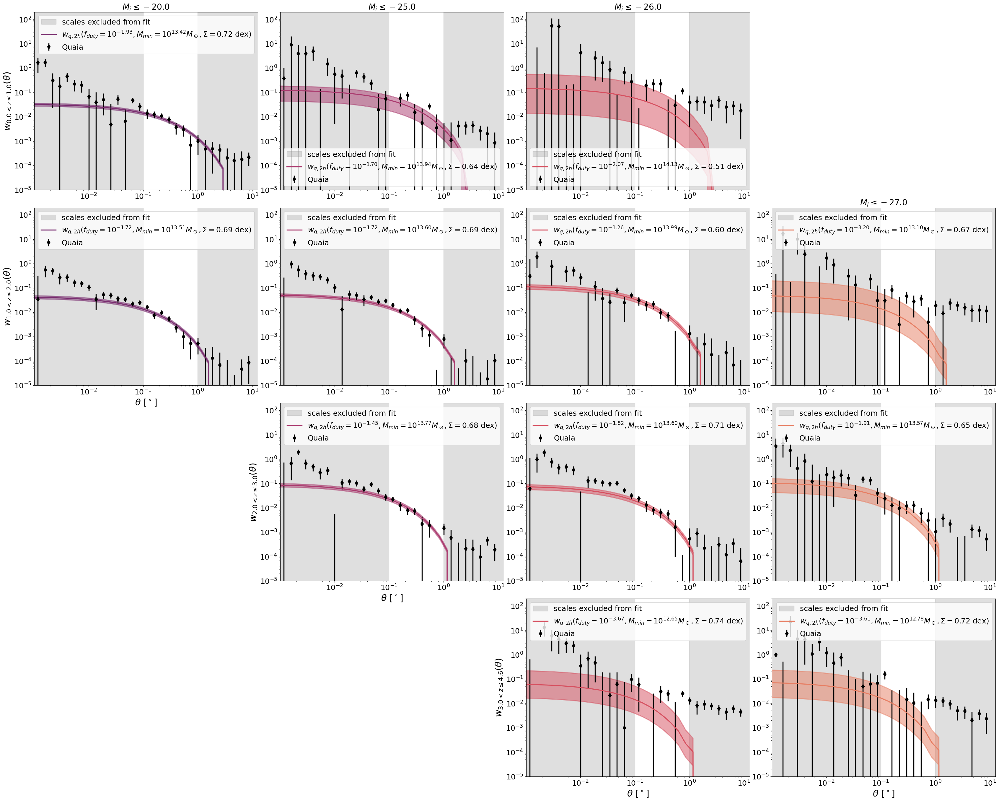

In [206]:
# remove bottom panel and just print bq somewhere
# plot!
fig = plt.figure(figsize = (42, 33.6))
gs = gridspec.GridSpec(4, 4, wspace = 0.1, hspace = 0.1)

for j in range(len(z_array)):
    
    for i in range(len(L_bins)):

        if (((i<3) and (N_q[L_bins[i]][j]>N_q[L_bins[i+1]][j])) or (i==3)) and (np.round(N_q[L_bins[i]][j]/1000)>1):

            ax1 = fig.add_subplot(gs[j*4+i])

            C = np.load('../results/cov_wtheta_G{}_rmin{}_rmax{}_nbins{}_zmin{}zmax{}_Lmax{}_N{}_{}_MC_b{}.npy'.format(
                G_hi, rmin, rmax, nbins, z_bins[j], z_bins[j+1], L_bins[i], N, cosmo, b))
            
            ax1.errorbar(quaia.recenter(thetabins), wp_chi2[L_bins[i]][j], linewidth = 2.5, marker = 'd', 
                         label = r'Quaia', color = 'black', yerr = np.sqrt(np.diag(C)), markeredgewidth = 2.5, linestyle = 'none')
            
            if quaia.recenter(thetabins)[-1] > 1:
                ax1.fill_betweenx(y, x1 = xlim[0], x2 = 10**log_thetamin, color = 'grey', 
                              alpha = 0.25, label = 'scales excluded from fit')
                ax1.fill_betweenx(y, x1 = 1, x2 = xlim[-1], color = 'grey', 
                                  alpha = 0.25)
        
            wp_2h_samples=[]
            for l in range(len(f_duty_samples[L_bins[i]][j])):
                n_m=HOD_scatter(10**f_duty_samples[L_bins[i]][j][l], M_min_samples[L_bins[i]][j][l], bins, Sigma_samples[L_bins[i]][j][l])
                wp_2h_sample = wtheta_2h_optimized(bins, n_m, H0_c_dN_dz_norm[L_bins[i]][j])
                wp_2h_samples.append(wp_2h_sample)
            wp_2h_16, wp_2h_50, wp_2h_84 = np.percentile(wp_2h_samples, [16, 50, 84], axis=0)

            ax1.plot(thetabins, wp_2h_50, linewidth = 2.5,
                     label = r'$w_{{q,2h}}(f_{{duty}}=10^{{{:.2f}}}, M_{{min}}=10^{{{:.2f}}}M_\odot, \Sigma={:.2f}$ dex)'.format(f_duty[L_bins[i]][j], 
                                                                                                                M_min[L_bins[i]][j], Sigma[L_bins[i]][j]), 
                     color = cmap_theta[i])
            ax1.fill_between(thetabins, wp_2h_16, wp_2h_84, linewidth = 2.5, alpha = 0.5, color = cmap_theta[i])

            if j==0 or ((j == 1) and (i == 3)):
                ax1.set_title('$M_i\leq{}$'.format(L_bins[i]))
            ax1.set_xlim(xlim)
            ax1.set_ylim(ylim)
            ax1.legend()
            
            if i==0 or ((j>1) and (i<3) and (i!=j)):
                ax1.set_ylabel(r"$w_{{{:.1f}<z \leq{:.1f}}}(\theta)$".format(z_bins[j], z_bins[j+1]))
        
            if j > 2 or ((j>0) and (i<2) and (i!=j)):
                ax1.set_xlabel(r'$\theta$ $[^\circ]$') # projected

            ax1.set_xscale('log')
            ax1.set_yscale('log')

# plt.savefig('../figures/L_z_fit_wtheta.pdf', bbox_inches = 'tight')
plt.show()

<>:40: SyntaxWarning: invalid escape sequence '\l'
<>:40: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_13410/3769475885.py:40: SyntaxWarning: invalid escape sequence '\l'
  ax1.set_title('$M_i\leq{}$'.format(L_bins[i]))


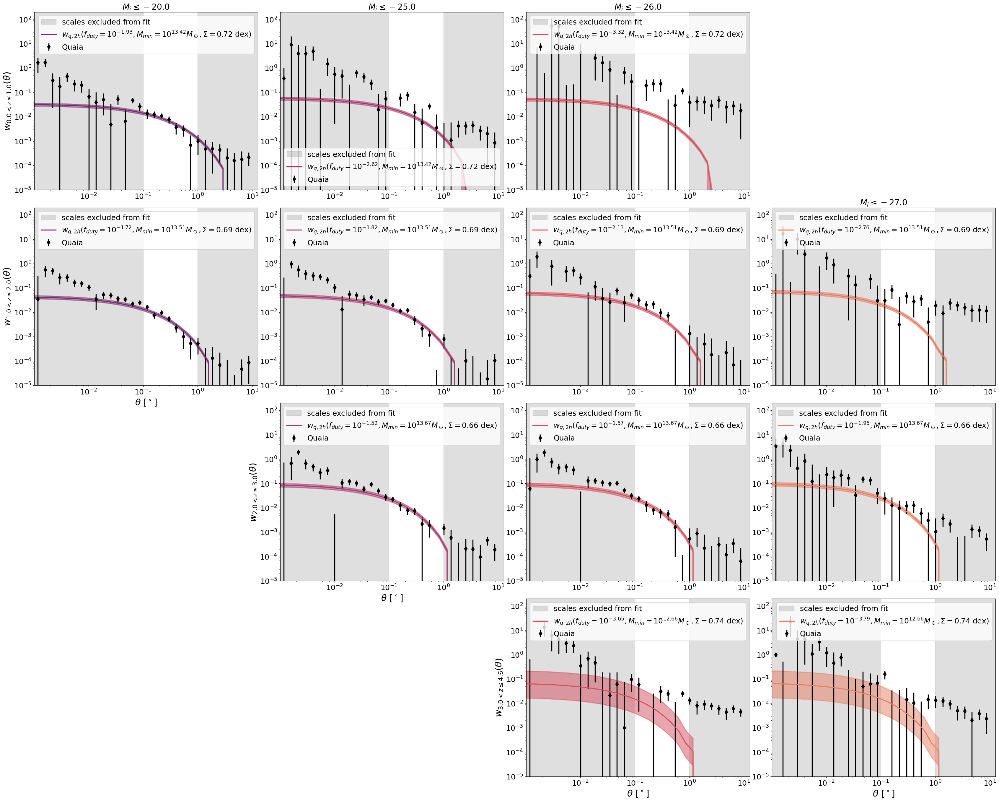

In [207]:
# remove bottom panel and just print bq somewhere
# plot!
fig = plt.figure(figsize = (42, 33.6))
gs = gridspec.GridSpec(4, 4, wspace = 0.1, hspace = 0.1)

for j in range(len(z_array)):
    
    for i in range(len(L_bins)):

        if (((i<3) and (N_q[L_bins[i]][j]>N_q[L_bins[i+1]][j])) or (i==3)) and (np.round(N_q[L_bins[i]][j]/1000)>1):

            ax1 = fig.add_subplot(gs[j*4+i])

            C = np.load('../results/cov_wtheta_G{}_rmin{}_rmax{}_nbins{}_zmin{}zmax{}_Lmax{}_N{}_{}_MC_b{}.npy'.format(
                G_hi, rmin, rmax, nbins, z_bins[j], z_bins[j+1], L_bins[i], N, cosmo, b))
            
            ax1.errorbar(quaia.recenter(thetabins), wp_chi2[L_bins[i]][j], linewidth = 2.5, marker = 'd', 
                         label = r'Quaia', color = 'black', yerr = np.sqrt(np.diag(C)), markeredgewidth = 2.5, linestyle = 'none')
            
            if quaia.recenter(thetabins)[-1] > 1:
                ax1.fill_betweenx(y, x1 = xlim[0], x2 = 10**log_thetamin, color = 'grey', 
                              alpha = 0.25, label = 'scales excluded from fit')
                ax1.fill_betweenx(y, x1 = 1, x2 = xlim[-1], color = 'grey', 
                                  alpha = 0.25)
                
            wp_2h_samples=[]
            for l in range(len(f_duty_samples_null[L_bins[i]][j])):
                n_m=HOD_scatter(10**f_duty_samples_null[L_bins[i]][j][l], M_min_samples[L_bins[0]][j][l], bins, Sigma_samples[L_bins[0]][j][l])
                wp_2h_sample = wtheta_2h_optimized(bins, n_m, H0_c_dN_dz_norm[L_bins[i]][j])
                wp_2h_samples.append(wp_2h_sample)
            wp_2h_16, wp_2h_50, wp_2h_84 = np.percentile(wp_2h_samples, [16, 50, 84], axis=0)

            ax1.plot(thetabins, wp_2h_50, linewidth = 2.5,
                     label = r'$w_{{q,2h}}(f_{{duty}}=10^{{{:.2f}}}, M_{{min}}=10^{{{:.2f}}}M_\odot, \Sigma={:.2f}$ dex)'.format(f_duty_null[L_bins[i]][j], 
                                                                                                                M_min[L_bins[0]][j], Sigma[L_bins[0]][j]), 
                     color = cmap_theta[i])
            ax1.fill_between(thetabins, wp_2h_16, wp_2h_84, linewidth = 2.5, alpha = 0.5, color = cmap_theta[i])
            
            if j==0 or ((j == 1) and (i == 3)):
                ax1.set_title('$M_i\leq{}$'.format(L_bins[i]))
            ax1.set_xlim(xlim)
            ax1.set_ylim(ylim)
            ax1.legend()
            
            if i==0 or ((j>1) and (i<3) and (i!=j)):
                ax1.set_ylabel(r"$w_{{{:.1f}<z \leq{:.1f}}}(\theta)$".format(z_bins[j], z_bins[j+1]))
        
            if j > 2 or ((j>0) and (i<2) and (i!=j)):
                ax1.set_xlabel(r'$\theta$ $[^\circ]$') # projected

            ax1.set_xscale('log')
            ax1.set_yscale('log')

# plt.savefig('../figures/L_z_fit_wtheta.pdf', bbox_inches = 'tight')
plt.show()

In [208]:
cmap_xi = sns.color_palette("crest_r", n_colors = len(L_bins))

<>:57: SyntaxWarning: invalid escape sequence '\l'
<>:57: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_13410/3552827210.py:57: SyntaxWarning: invalid escape sequence '\l'
  ax1.set_title('$M_i\leq{}$'.format(L_bins[i]))


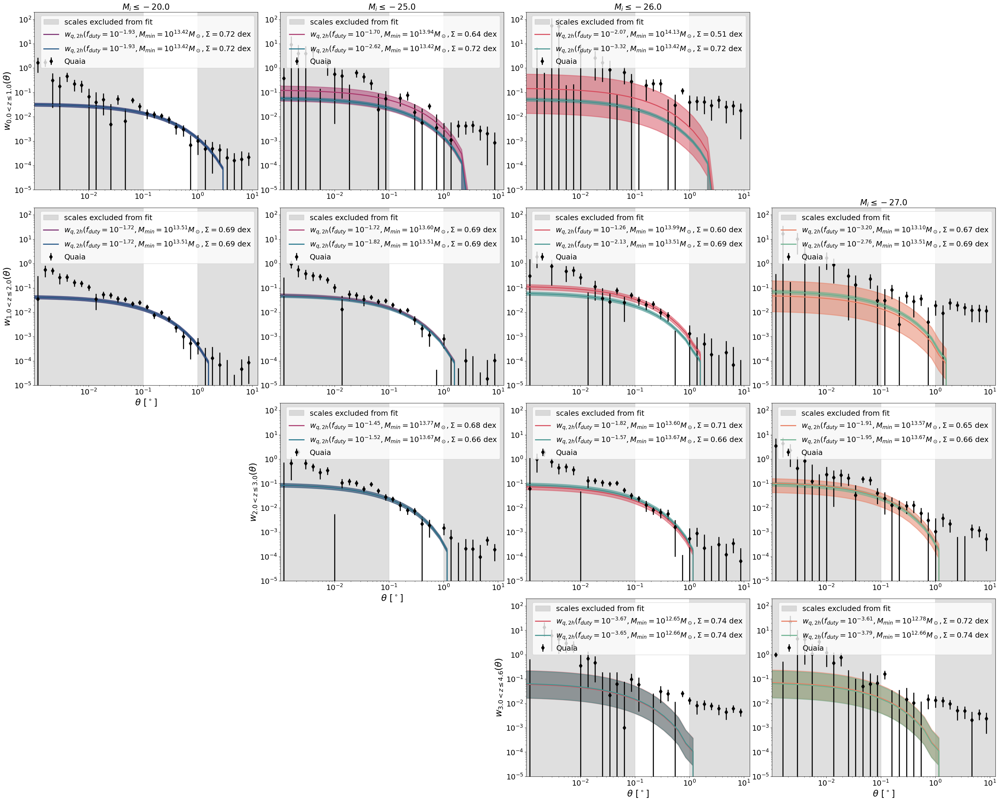

In [209]:
# remove bottom panel and just print bq somewhere
# plot!
fig = plt.figure(figsize = (42, 33.6))
gs = gridspec.GridSpec(4, 4, wspace = 0.1, hspace = 0.1)

for j in range(len(z_array)):
    
    for i in range(len(L_bins)):

        if (((i<3) and (N_q[L_bins[i]][j]>N_q[L_bins[i+1]][j])) or (i==3)) and (np.round(N_q[L_bins[i]][j]/1000)>1):

            ax1 = fig.add_subplot(gs[j*4+i])

            C = np.load('../results/cov_wtheta_G{}_rmin{}_rmax{}_nbins{}_zmin{}zmax{}_Lmax{}_N{}_{}_MC_b{}.npy'.format(
                G_hi, rmin, rmax, nbins, z_bins[j], z_bins[j+1], L_bins[i], N, cosmo, b))
            
            ax1.errorbar(quaia.recenter(thetabins), wp_chi2[L_bins[i]][j], linewidth = 2.5, marker = 'd', 
                         label = r'Quaia', color = 'black', yerr = np.sqrt(np.diag(C)), markeredgewidth = 2.5, linestyle = 'none')
            
            if quaia.recenter(thetabins)[-1] > 1:
                ax1.fill_betweenx(y, x1 = xlim[0], x2 = 10**log_thetamin, color = 'grey', 
                              alpha = 0.25, label = 'scales excluded from fit')
                ax1.fill_betweenx(y, x1 = 1, x2 = xlim[-1], color = 'grey', 
                                  alpha = 0.25)
            
            wp_2h_samples, wp_2h_samples_null=[], []
            for l in range(len(f_duty_samples[L_bins[i]][j])):

                n_m=HOD_scatter(10**f_duty_samples[L_bins[i]][j][l], M_min_samples[L_bins[i]][j][l], bins, Sigma_samples[L_bins[i]][j][l])
                wp_2h_sample = wtheta_2h_optimized(bins, n_m, H0_c_dN_dz_norm[L_bins[i]][j])
                wp_2h_samples.append(wp_2h_sample)

            for l in range(len(f_duty_samples_null[L_bins[i]][j])):

                n_m=HOD_scatter(10**f_duty_samples_null[L_bins[i]][j][l], M_min_samples[L_bins[0]][j][l], bins, Sigma_samples[L_bins[0]][j][l])
                wp_2h_sample = wtheta_2h_optimized(bins, n_m, H0_c_dN_dz_norm[L_bins[i]][j])
                wp_2h_samples_null.append(wp_2h_sample)

            wp_2h_16, wp_2h_50, wp_2h_84 = np.percentile(wp_2h_samples, [16, 50, 84], axis=0)

            ax1.plot(thetabins, wp_2h_50, linewidth = 2.5,
                     label = r'$w_{{q,2h}}(f_{{duty}}=10^{{{:.2f}}}, M_{{min}}=10^{{{:.2f}}}M_\odot, \Sigma={:.2f}$ dex'.format(f_duty[L_bins[i]][j], 
                                                                                                                M_min[L_bins[i]][j], Sigma[L_bins[i]][j]), 
                     color = cmap_theta[i])
            ax1.fill_between(thetabins, wp_2h_16, wp_2h_84, linewidth = 2.5, alpha = 0.5, color = cmap_theta[i])
            
            wp_2h_16, wp_2h_50, wp_2h_84 = np.percentile(wp_2h_samples_null, [16, 50, 84], axis=0)

            ax1.plot(thetabins, wp_2h_50, linewidth = 2.5,
                     label = r'$w_{{q,2h}}(f_{{duty}}=10^{{{:.2f}}}, M_{{min}}=10^{{{:.2f}}}M_\odot, \Sigma={:.2f}$ dex'.format(f_duty_null[L_bins[i]][j], 
                                                                                                                M_min[L_bins[0]][j], Sigma[L_bins[0]][j]), 
                     color = cmap_xi[i])
            ax1.fill_between(thetabins, wp_2h_16, wp_2h_84, linewidth = 2.5, alpha = 0.5, color = cmap_xi[i])

            
            if j==0 or ((j == 1) and (i == 3)):
                ax1.set_title('$M_i\leq{}$'.format(L_bins[i]))
            ax1.set_xlim(xlim)
            ax1.set_ylim(ylim)
            ax1.legend()
            
            if i==0 or ((j>1) and (i<3) and (i!=j)):
                ax1.set_ylabel(r"$w_{{{:.1f}<z \leq{:.1f}}}(\theta)$".format(z_bins[j], z_bins[j+1]))
        
            if j > 2 or ((j>0) and (i<2) and (i!=j)):
                ax1.set_xlabel(r'$\theta$ $[^\circ]$') # projected

            ax1.set_xscale('log')
            ax1.set_yscale('log')

# plt.savefig('../figures/L_z_fit_wtheta.pdf', bbox_inches = 'tight')
plt.show()

<>:42: SyntaxWarning: invalid escape sequence '\l'
<>:42: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_13410/2413555072.py:42: SyntaxWarning: invalid escape sequence '\l'
  ax1.set_title('${:.1f}<z \leq{:.1f}$'.format(z_bins[j], z_bins[j+1]))


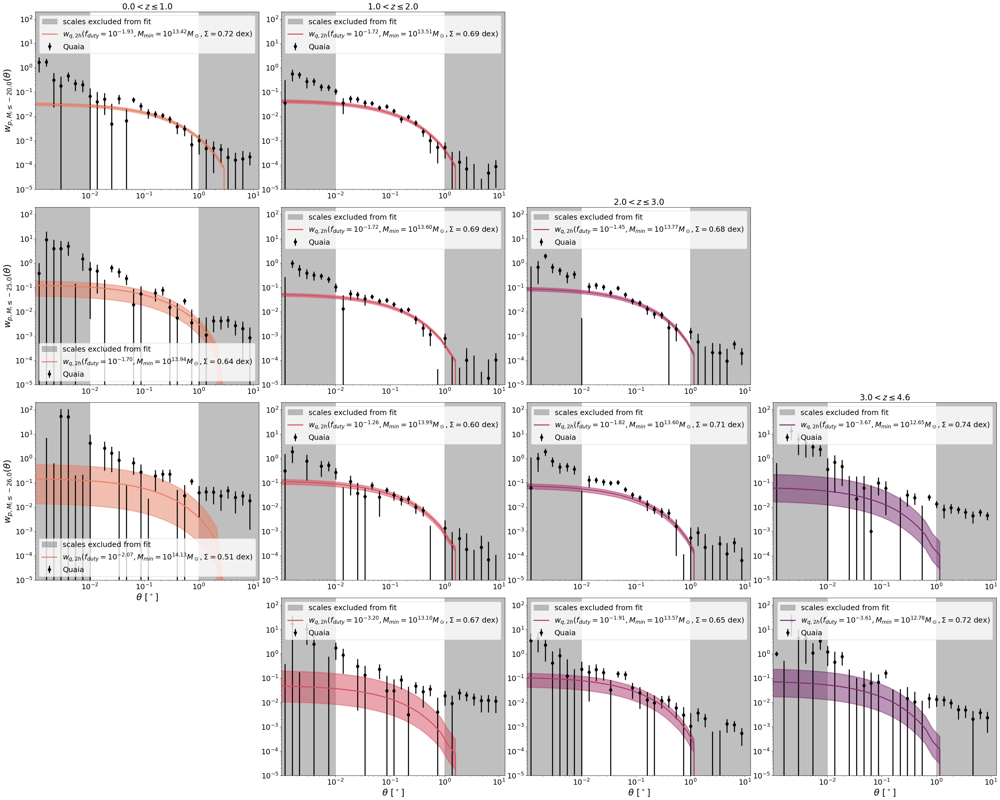

In [210]:
# remove bottom panel and just print bq somewhere
# plot!
fig = plt.figure(figsize = (42, 33.6))
gs = gridspec.GridSpec(4, 4, wspace = 0.1, hspace = 0.1)
# ylim = 2e-4, 4e2

for i in range(len(L_bins)):

    for j in range(len(z_array)):

        if (((i<3) and (N_q[L_bins[i]][j]>N_q[L_bins[i+1]][j])) or (i==3)) and (np.round(N_q[L_bins[i]][j]/1000)>1):

            ax1 = fig.add_subplot(gs[i*4+j])

            C = np.load('../results/cov_wtheta_G{}_rmin{}_rmax{}_nbins{}_zmin{}zmax{}_Lmax{}_N{}_{}_MC_b{}.npy'.format(
                G_hi, rmin, rmax, nbins, z_bins[j], z_bins[j+1], L_bins[i], N, cosmo, b))
                   
            ax1.errorbar(quaia.recenter(thetabins), wp_chi2[L_bins[i]][j], linewidth = 2.5, marker = 'd', 
                         label = r'Quaia', color = 'black', yerr = np.sqrt(np.diag(C)), markeredgewidth = 2.5, linestyle = 'none')
            if quaia.recenter(thetabins)[-1] > 1:
                ax1.fill_betweenx(y, x1 = xlim[0], x2 = 1e-2, color = 'grey', 
                              alpha = 0.5, label = 'scales excluded from fit')
                ax1.fill_betweenx(y, x1 = 1, x2 = xlim[-1], color = 'grey', 
                                  alpha = 0.5)
        
            wp_2h_samples = []
            for l in range(len(f_duty_samples[L_bins[i]][j])):
                n_m=HOD_scatter(10**f_duty_samples[L_bins[i]][j][l], M_min_samples[L_bins[i]][j][l], bins, Sigma_samples[L_bins[i]][j][l])
                wp_2h_sample = wtheta_2h_optimized(bins, n_m, H0_c_dN_dz_norm[L_bins[i]][j])
                wp_2h_samples.append(wp_2h_sample)
            wp_2h_16, wp_2h_50, wp_2h_84 = np.percentile(wp_2h_samples, [16, 50, 84], axis=0)

            ax1.plot(thetabins, wp_2h_50, linewidth = 2.5,
                     label = r'$w_{{q,2h}}(f_{{duty}}=10^{{{:.2f}}}, M_{{min}}=10^{{{:.2f}}}M_\odot, \Sigma={:.2f}$ dex)'.format(f_duty[L_bins[i]][j], 
                                                                                                                M_min[L_bins[i]][j], 
                                                                                                                                 Sigma[L_bins[i]][j]), 
                     color = cmap_theta[::-1][j])
            ax1.fill_between(thetabins, wp_2h_16, wp_2h_84, linewidth = 2.5, alpha = 0.5,
                     color = cmap_theta[::-1][j])    
        
            if i ==0 or ((i<3) and (j>1) and (i!=j)):
                ax1.set_title('${:.1f}<z \leq{:.1f}$'.format(z_bins[j], z_bins[j+1]))
            ax1.set_xlim(xlim)
            ax1.legend()
            
            if j==0:
                ax1.set_ylabel(r"$w_{{p,M_i\leq{}}}(\theta)$".format(L_bins[i]))
        
            if i > 2 or ((i == 2) and (j == 0)):
                ax1.set_xlabel(r'$\theta$ $[^\circ]$') 
            ax1.set_ylim(ylim)

            ax1.set_xscale('log')
            ax1.set_yscale('log')
            
plt.show()

### Test dependence on $M_{min}$

In [211]:
Mmins = [11,12,13,14,15,16]

In [212]:
cmap_green = plt.get_cmap('Greens')(np.linspace(0.333, 0.999, len(Mmins)))

<>:66: SyntaxWarning: invalid escape sequence '\l'
<>:89: SyntaxWarning: invalid escape sequence '\S'
<>:66: SyntaxWarning: invalid escape sequence '\l'
<>:89: SyntaxWarning: invalid escape sequence '\S'
/tmp/ipykernel_13410/2936468656.py:66: SyntaxWarning: invalid escape sequence '\l'
  ax1.set_title('$M_i\leq{}$'.format(L_bins[i]))
/tmp/ipykernel_13410/2936468656.py:89: SyntaxWarning: invalid escape sequence '\S'
  loc='center', title = '$\Sigma={}$ dex'.format(Sigma_fixed), title_fontsize = 20)


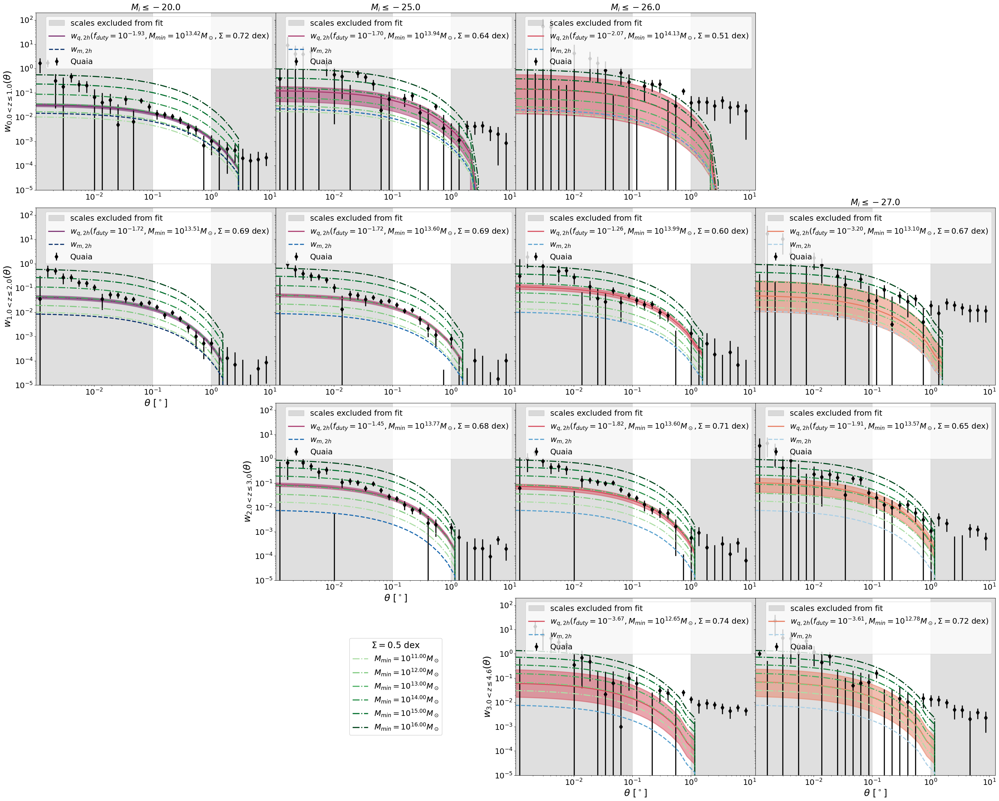

In [213]:
# remove bottom panel and just print bq somewhere
# plot!
fig = plt.figure(figsize = (40, 32))
gs = gridspec.GridSpec(4, 4, wspace = 0, hspace = 0.1)
ylims = [[-0.75, 2.5], [-2.5, 12.5], [-12.5, 50], [-75, 375]], [[-0.5, 2.5], [-0.5, 2.5], [-0.5, 7.5], [-2.5, 25]], [[np.nan, np.nan], [-1, 2.75], [-0.75, 5], [-2.5, 10]], [[np.nan, np.nan], [np.nan, np.nan], [-10, 12.5], [-25, 25]]
m = 0
Sigma_fixed = 0.5
for j in range(len(z_array)):
    
    for i in range(len(L_bins)):

        if (((i<3) and (N_q[L_bins[i]][j]>N_q[L_bins[i+1]][j])) or (i==3)) and (np.round(N_q[L_bins[i]][j]/1000)>1):

            ax1 = fig.add_subplot(gs[j*4+i])

            C = np.load('../results/cov_wtheta_G{}_rmin{}_rmax{}_nbins{}_zmin{}zmax{}_Lmax{}_N{}_{}_MC_b{}.npy'.format(
                G_hi, rmin, rmax, nbins, z_bins[j], z_bins[j+1], L_bins[i], N, cosmo, b))
            if diag == True:
                C*=np.identity(len(C))
    
            log_det_C, solve = log_det(C, ix_grid)
                   
            ax1.errorbar(quaia.recenter(thetabins), wp_chi2[L_bins[i]][j], linewidth = 2.5, marker = 'd', 
                         label = r'Quaia', color = 'black', yerr = np.sqrt(np.diag(C)), markeredgewidth = 2.5, linestyle = 'none')
            if quaia.recenter(thetabins)[-1] > 1:
                ax1.fill_betweenx(y, x1 = xlim[0], x2 = 10**log_thetamin, color = 'grey', 
                              alpha = 0.25, label = 'scales excluded from fit')
                ax1.fill_betweenx(y, x1 = 1, x2 = xlim[-1], color = 'grey', 
                                  alpha = 0.25)
        
            wp_2h_samples=[]
            for l in range(len(f_duty_samples[L_bins[i]][j])):
                n_m=HOD_scatter(10**f_duty_samples[L_bins[i]][j][l], M_min_samples[L_bins[i]][j][l], bins, Sigma_samples[L_bins[i]][j][l])
                wp_2h_sample = wtheta_2h_optimized(bins, n_m, H0_c_dN_dz_norm[L_bins[i]][j])
                wp_2h_samples.append(wp_2h_sample)
            wp_2h_16, wp_2h_50, wp_2h_84 = np.percentile(wp_2h_samples, [16, 50, 84], axis=0)

            ax1.plot(thetabins, wp_2h_50, linewidth = 2.5,
                     label = r'$w_{{q,2h}}(f_{{duty}}=10^{{{:.2f}}}, M_{{min}}=10^{{{:.2f}}}M_\odot, \Sigma={:.2f}$ dex)'.format(f_duty[L_bins[i]][j], 
                                                                                                                M_min[L_bins[i]][j], Sigma[L_bins[i]][j]), 
                     color = cmap_theta[i])
            ax1.fill_between(thetabins, wp_2h_16, wp_2h_84, linewidth = 2.5, alpha = 0.5, color = cmap_theta[i])
            
            # test higher Mmin values
            for k in range(len(Mmins)):
                n_m=HOD_scatter(10**f_duty[L_bins[i]][j], Mmins[k], bins, Sigma_fixed)
                wp_2h_sample = wtheta_2h_optimized(bins, n_m, H0_c_dN_dz_norm[L_bins[i]][j])
                ax1.plot(thetabins, wp_2h_sample, linewidth = 2.5, linestyle = '-.', color = cmap_green[k]) #,
                if (j == 0) and (i == 3):

                    x = [f_duty[L_bins[i]][j], Sigma[L_bins[i]][j]]

                    chi2 = f0_GLS_solve(x, a_zbin[L_bins[i]][j], C, wp_chi2[L_bins[i]][j], H0_c_dN_dz_norm[L_bins[i]][j], rpmask = theta_mask)
                    likelihood = loglike(x, log_det_C, wp_chi2[L_bins[i]][j][theta_mask], nbins_mask, solve, H0_c_dN_dz_norm[L_bins[i]][j], theta_mask=theta_mask, optimize = True)

                    print('10^{} M_sun'.format(Mmins[k]))
                    print('           chi^2: {:.2f}'.format(chi2))
                    print('  log likelihood: {:.2f}\n'.format(likelihood))
                    
            # plot matter
            n_m=HOD_scatter(10**f_duty[L_bins[i]][j], Mmins[k], bins, Sigma[L_bins[i]][j])
            ax1.plot(thetabins, wtheta_2h_optimized(bins, n_m, H0_c_dN_dz_norm[L_bins[i]][j], wtheta_mm=True), linewidth = 2.5, linestyle = '--',
                     label = r'$w_{{m,2h}}$', color = cmap_blue[::-1][i])
        
            if j==0 or ((j == 1) and (i == 3)):
                ax1.set_title('$M_i\leq{}$'.format(L_bins[i]))
            ax1.set_xlim(xlim)
            ax1.set_ylim(ylim)
            ax1.legend()
        
            if j > 2 or ((j>0) and (i<2) and (i!=j)):
                ax1.set_xlabel(r'$\theta$ $[^\circ]$') # projected

            ax1.set_xscale('log')
            ax1.set_yscale('log')

            if i==0 or ((j>1) and (i<3) and (i!=j)):
                ax1.set_ylabel(r"$w_{{{:.1f}<z \leq{:.1f}}}(\theta)$".format(z_bins[j], z_bins[j+1]))
            else:
                ax1.set_yticklabels([])
        
        else:
        
            if m == 3:
                ax1 = fig.add_subplot(gs[j*4+i])
                ax1.set_axis_off()
                custom_lines = [Line2D([0], [0], color = cmap_green[i], linestyle = '-.', linewidth = 2.5) for i in range(len(Mmins))]
                second_legend = ax1.legend(custom_lines, [r'$M_{{min}}=10^{{{:.2f}}}M_\odot$'.format(Mmin) for Mmin in Mmins], bbox_to_anchor = (0.5, 0.5), 
                                           loc='center', title = '$\Sigma={}$ dex'.format(Sigma_fixed), title_fontsize = 20)
                fig.add_artist(second_legend)
            m+=1

plt.show()

### Test dependence on $\Sigma$

In [214]:
Sigmas = np.linspace(0.2,1.2,6)

<>:89: SyntaxWarning: invalid escape sequence '\o'
<>:89: SyntaxWarning: invalid escape sequence '\o'
/tmp/ipykernel_13410/2061592896.py:89: SyntaxWarning: invalid escape sequence '\o'
  loc='center', title = '$M_{{min}}=10^{{{:.2f}}}M_\odot$'.format(Mmin_fixed), title_fontsize = 20)


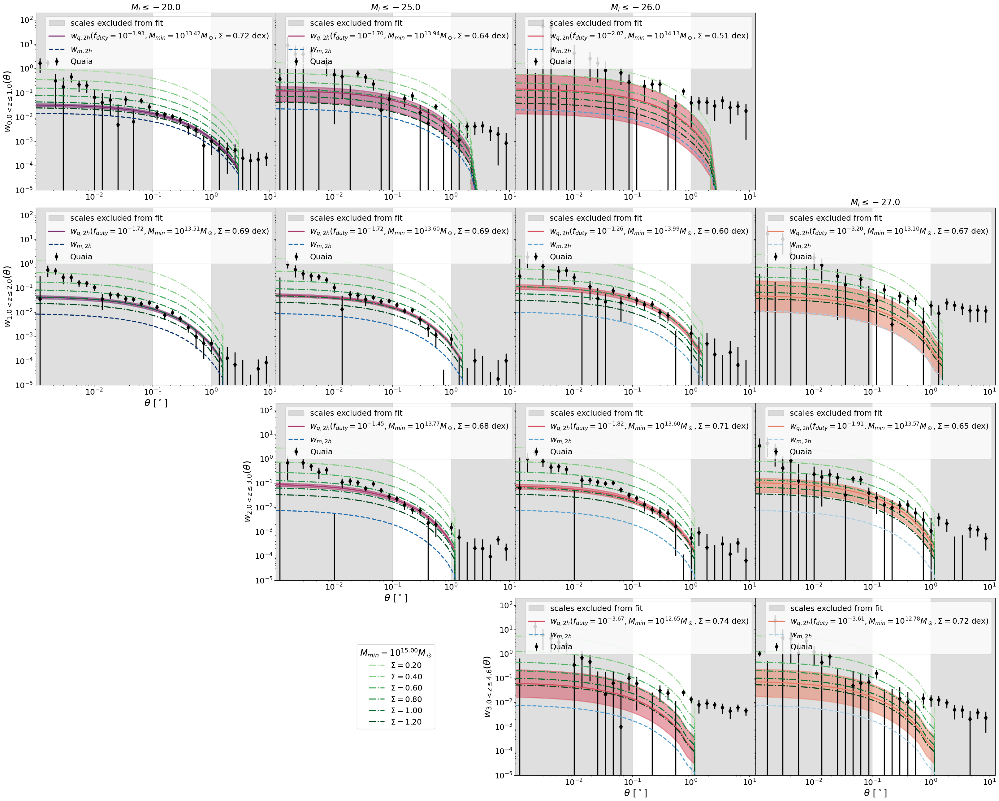

In [215]:
# remove bottom panel and just print bq somewhere
# plot!
fig = plt.figure(figsize = (40, 32))
gs = gridspec.GridSpec(4, 4, wspace = 0, hspace = 0.1)
ylims = [[-0.75, 2.5], [-2.5, 12.5], [-12.5, 50], [-75, 375]], [[-0.5, 2.5], [-0.5, 2.5], [-0.5, 7.5], [-2.5, 25]], [[np.nan, np.nan], [-1, 2.75], [-0.75, 5], [-2.5, 10]], [[np.nan, np.nan], [np.nan, np.nan], [-10, 12.5], [-25, 25]]
m = 0
Mmin_fixed = 15
for j in range(len(z_array)):
    
    for i in range(len(L_bins)):

        if (((i<3) and (N_q[L_bins[i]][j]>N_q[L_bins[i+1]][j])) or (i==3)) and (np.round(N_q[L_bins[i]][j]/1000)>1):

            ax1 = fig.add_subplot(gs[j*4+i])

            C = np.load('../results/cov_wtheta_G{}_rmin{}_rmax{}_nbins{}_zmin{}zmax{}_Lmax{}_N{}_{}_MC_b{}.npy'.format(
                G_hi, rmin, rmax, nbins, z_bins[j], z_bins[j+1], L_bins[i], N, cosmo, b))
            if diag == True:
                C*=np.identity(len(C))
    
            log_det_C, solve = log_det(C, ix_grid)
                   
            ax1.errorbar(quaia.recenter(thetabins), wp_chi2[L_bins[i]][j], linewidth = 2.5, marker = 'd', 
                         label = r'Quaia', color = 'black', yerr = np.sqrt(np.diag(C)), markeredgewidth = 2.5, linestyle = 'none')
            if quaia.recenter(thetabins)[-1] > 1:
                ax1.fill_betweenx(y, x1 = xlim[0], x2 = 10**log_thetamin, color = 'grey', 
                              alpha = 0.25, label = 'scales excluded from fit')
                ax1.fill_betweenx(y, x1 = 1, x2 = xlim[-1], color = 'grey', 
                                  alpha = 0.25)
        
            wp_2h_samples=[]
            for l in range(len(f_duty_samples[L_bins[i]][j])):
                n_m=HOD_scatter(10**f_duty_samples[L_bins[i]][j][l], M_min_samples[L_bins[i]][j][l], bins, Sigma_samples[L_bins[i]][j][l])
                wp_2h_sample = wtheta_2h_optimized(bins, n_m, H0_c_dN_dz_norm[L_bins[i]][j])
                wp_2h_samples.append(wp_2h_sample)
            wp_2h_16, wp_2h_50, wp_2h_84 = np.percentile(wp_2h_samples, [16, 50, 84], axis=0)

            ax1.plot(thetabins, wp_2h_50, linewidth = 2.5,
                     label = r'$w_{{q,2h}}(f_{{duty}}=10^{{{:.2f}}}, M_{{min}}=10^{{{:.2f}}}M_\odot, \Sigma={:.2f}$ dex)'.format(f_duty[L_bins[i]][j], 
                                                                                                                M_min[L_bins[i]][j], Sigma[L_bins[i]][j]), 
                     color = cmap_theta[i])
            ax1.fill_between(thetabins, wp_2h_16, wp_2h_84, linewidth = 2.5, alpha = 0.5, color = cmap_theta[i])
            
            # test higher Mmin values
            for k in range(len(Sigmas)):
                n_m=HOD_scatter(10**f_duty[L_bins[i]][j], Mmin_fixed, bins, Sigmas[k])
                wp_2h_sample = wtheta_2h_optimized(bins, n_m, H0_c_dN_dz_norm[L_bins[i]][j])
                ax1.plot(thetabins, wp_2h_sample, linewidth = 2.5, linestyle = '-.', color = cmap_green[k]) #,
                if (j == 0) and (i == 3):

                    x = [f_duty[L_bins[i]][j], Sigma[L_bins[i]][j]]

                    chi2 = f0_GLS_solve(x, a_zbin[L_bins[i]][j], C, wp_chi2[L_bins[i]][j], H0_c_dN_dz_norm[L_bins[i]][j], rpmask = theta_mask)
                    likelihood = loglike(x, log_det_C, wp_chi2[L_bins[i]][j][theta_mask], nbins_mask, solve, H0_c_dN_dz_norm[L_bins[i]][j], theta_mask=theta_mask, optimize = True)

                    print('Sigma: {}'.format(Sigmas[k]))
                    print('           chi^2: {:.2f}'.format(chi2))
                    print('  log likelihood: {:.2f}\n'.format(likelihood))
                    
            # plot matter
            n_m=HOD_scatter(10**f_duty[L_bins[i]][j], M_min[L_bins[i]][j], bins, Sigmas[k])
            ax1.plot(thetabins, wtheta_2h_optimized(bins, n_m, H0_c_dN_dz_norm[L_bins[i]][j], wtheta_mm=True), linewidth = 2.5, linestyle = '--',
                     label = r'$w_{{m,2h}}$', color = cmap_blue[::-1][i])
        
            if j==0 or ((j == 1) and (i == 3)):
                ax1.set_title(r'$M_i\leq{}$'.format(L_bins[i]))
            ax1.set_xlim(xlim)
            ax1.set_ylim(ylim)
            ax1.legend()
        
            if j > 2 or ((j>0) and (i<2) and (i!=j)):
                ax1.set_xlabel(r'$\theta$ $[^\circ]$') # projected

            ax1.set_xscale('log')
            ax1.set_yscale('log')

            if i==0 or ((j>1) and (i<3) and (i!=j)):
                ax1.set_ylabel(r"$w_{{{:.1f}<z \leq{:.1f}}}(\theta)$".format(z_bins[j], z_bins[j+1]))
            else:
                ax1.set_yticklabels([])
        
        else:
        
            if m == 3:
                ax1 = fig.add_subplot(gs[j*4+i])
                ax1.set_axis_off()
                custom_lines = [Line2D([0], [0], color = cmap_green[i], linestyle = '-.', linewidth = 2.5) for i in range(len(Mmins))]
                second_legend = ax1.legend(custom_lines, [r'$\Sigma={:.2f}$'.format(Sigma) for Sigma in Sigmas], bbox_to_anchor = (0.5, 0.5), 
                                           loc='center', title = '$M_{{min}}=10^{{{:.2f}}}M_\odot$'.format(Mmin_fixed), title_fontsize = 20)
                fig.add_artist(second_legend)
            m+=1

plt.show()

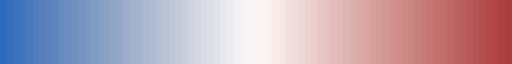

In [216]:
cmap_M_min = sns.color_palette("vlag", n_colors = len(bins))
palette_M_min = matplotlib.colors.ListedColormap(cmap_M_min)
palette_M_min

<>:45: SyntaxWarning: invalid escape sequence '\l'
<>:68: SyntaxWarning: invalid escape sequence '\D'
<>:45: SyntaxWarning: invalid escape sequence '\l'
<>:68: SyntaxWarning: invalid escape sequence '\D'
/tmp/ipykernel_13410/2565151366.py:45: SyntaxWarning: invalid escape sequence '\l'
  ax1.set_title('$M_i\leq{}$'.format(L_bins[i]))
/tmp/ipykernel_13410/2565151366.py:68: SyntaxWarning: invalid escape sequence '\D'
  label = '$\Delta \log_{10}(M_{min}/M_\odot)$')


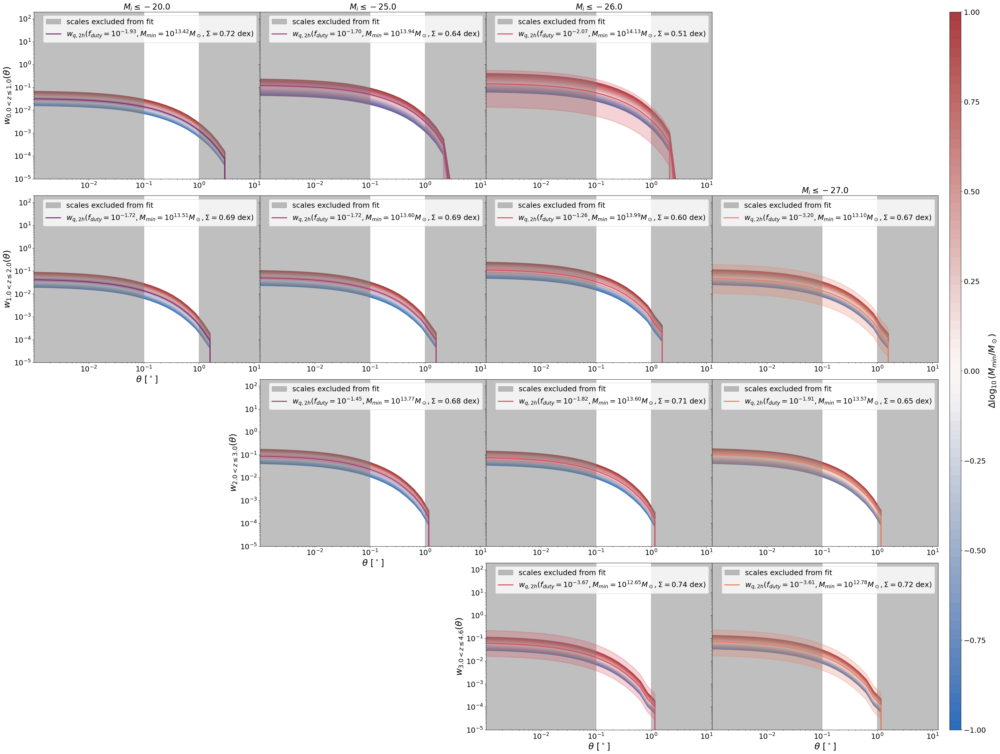

In [217]:
# remove bottom panel and just print bq somewhere
# plot!
fig = plt.figure(figsize = (41, 32))
gs = gridspec.GridSpec(4, 6, wspace = 0, hspace = 0.1, width_ratios = [1,1,1,1,0.05,0.05])

l = 0
for j in range(len(z_array)):
    
    for i in range(len(L_bins)):

        ax1 = fig.add_subplot(gs[j*4+i+l])

        if (((i<3) and (N_q[L_bins[i]][j]>N_q[L_bins[i+1]][j])) or (i==3)) and (np.round(N_q[L_bins[i]][j]/1000)>1):
            
            C = np.load('../results/cov_wtheta_G{}_rmin{}_rmax{}_nbins{}_zmin{}zmax{}_Lmax{}_N{}_{}_MC_b{}.npy'.format(
                G_hi, rmin, rmax, nbins, z_bins[j], z_bins[j+1], L_bins[i], N, cosmo, b))

            if quaia.recenter(thetabins)[-1] > 1:
                ax1.fill_betweenx(y, x1 = xlim[0], x2 = 10**log_thetamin, color = 'grey', 
                              alpha = 0.5, label = 'scales excluded from fit')
                ax1.fill_betweenx(y, x1 = 1, x2 = xlim[-1], color = 'grey', 
                                  alpha = 0.5)
        
            for k in range(len(bins)):
                n_m=HOD_scatter(10**f_duty[L_bins[i]][j], M_min[L_bins[i]][j]-1+k/int(len(bins)/2), bins, Sigma[L_bins[i]][j])
                wp_2h_sample = wtheta_2h_optimized(bins, n_m, H0_c_dN_dz_norm[L_bins[i]][j])
                ax1.plot(thetabins, wp_2h_sample, linewidth = 2.5, color = cmap_M_min[k], zorder = 0) # color = cmaps[i][j], alpha = (l+1)/len(bins))
                
            wp_2h_samples = []
            for k in range(len(f_duty_samples[L_bins[i]][j])):
                n_m=HOD_scatter(10**f_duty_samples[L_bins[i]][j][k], M_min_samples[L_bins[i]][j][k], bins, Sigma_samples[L_bins[i]][j][k])
                wp_2h_sample = wtheta_2h_optimized(bins, n_m, H0_c_dN_dz_norm[L_bins[i]][j])
                wp_2h_samples.append(wp_2h_sample)
            wp_2h_16, wp_2h_50, wp_2h_84 = np.percentile(wp_2h_samples, [16, 50, 84], axis=0)
            
            ax1.plot(thetabins, wp_2h_50, linewidth = 2.5,
                     label = r'$w_{{q,2h}}(f_{{duty}}=10^{{{:.2f}}}, M_{{min}}=10^{{{:.2f}}}M_\odot, \Sigma={:.2f}$ dex)'.format(f_duty[L_bins[i]][j], 
                                                                                                                M_min[L_bins[i]][j], 
                                                                                                                                 Sigma[L_bins[i]][j]), 
                     color = cmap_theta[i])
            ax1.fill_between(thetabins, wp_2h_16, wp_2h_84, linewidth = 2.5, alpha = 0.25,
                     color = cmap_theta[i])    
            
            if j==0 or ((j == 1) and (i == 3)):
                ax1.set_title('$M_i\leq{}$'.format(L_bins[i]))
            ax1.set_yscale('log')
            ax1.set_xlim(xlim)
            ax1.set_ylim(ylim)
            ax1.legend()
            
            if i==0 or ((j>1) and (i<3) and (i!=j)):
                ax1.set_ylabel(r"$w_{{{:.1f}<z \leq{:.1f}}}(\theta)$".format(z_bins[j], z_bins[j+1]))
            else:
                ax1.set_yticklabels([])
        
            if j > 2 or ((j>0) and (i<2) and (i!=j)):
                ax1.set_xlabel(r'$\theta$ $[^\circ]$') 
            ax1.set_xscale('log')

        else:

            ax1.set_axis_off()
            
        if i == 3:
            l+=2

cbar = fig.colorbar(cm.ScalarMappable(cmap=palette_M_min, norm = matplotlib.colors.Normalize(vmin=-1, vmax = 1)), cax = fig.add_subplot(gs[:,-1]), 
                label = '$\Delta \log_{10}(M_{min}/M_\odot)$')
plt.show()

<>:44: SyntaxWarning: invalid escape sequence '\l'
<>:63: SyntaxWarning: invalid escape sequence '\D'
<>:44: SyntaxWarning: invalid escape sequence '\l'
<>:63: SyntaxWarning: invalid escape sequence '\D'
/tmp/ipykernel_13410/3983309311.py:44: SyntaxWarning: invalid escape sequence '\l'
  ax1.set_title('${:.1f}<z \leq{:.1f}$'.format(z_bins[j], z_bins[j+1]))
/tmp/ipykernel_13410/3983309311.py:63: SyntaxWarning: invalid escape sequence '\D'
  label = '$\Delta \log_{10}(M_{min}/M_\odot)$')


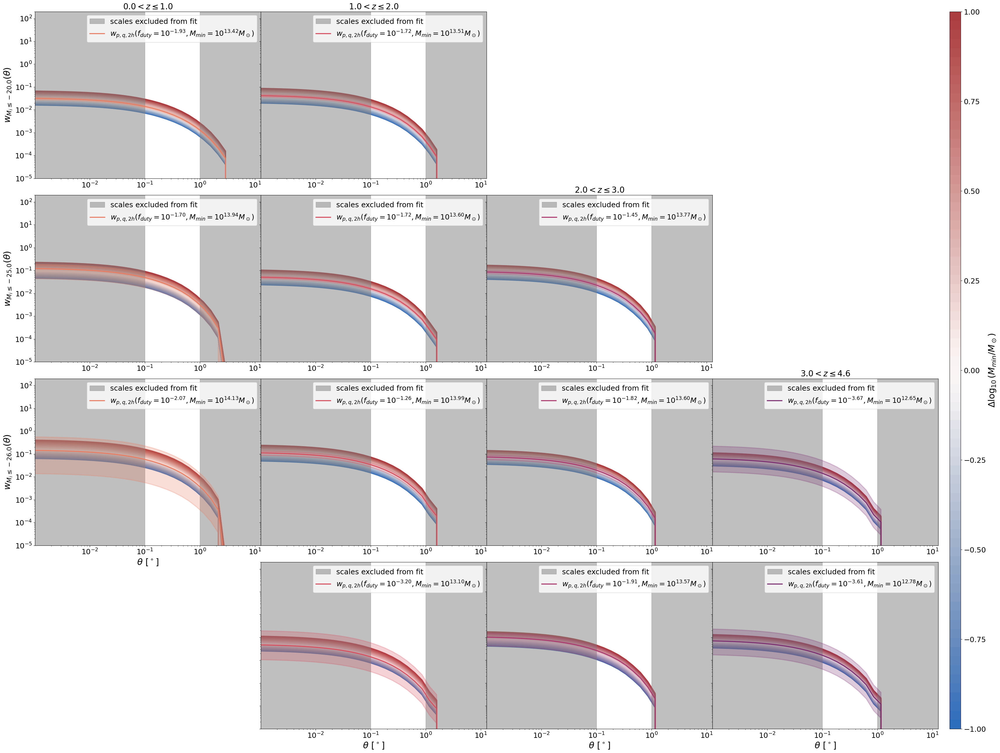

In [218]:
# remove bottom panel and just print bq somewhere
# plot!
fig = plt.figure(figsize = (41, 32))
gs = gridspec.GridSpec(4, 6, wspace = 0, hspace = 0.1, width_ratios = [1,1,1,1,0.05,0.05])

l = 0
for i in range(len(L_bins)):

    for j in range(len(z_array)):

        if (((i<3) and (N_q[L_bins[i]][j]>N_q[L_bins[i+1]][j])) or (i==3)) and (np.round(N_q[L_bins[i]][j]/1000)>1):

            ax1 = fig.add_subplot(gs[i*4+j+l])
            
            C = np.load('../results/cov_wtheta_G{}_rmin{}_rmax{}_nbins{}_zmin{}zmax{}_Lmax{}_N{}_{}_MC_b{}.npy'.format(G_hi, rmin, rmax, nbins, z_bins[j], z_bins[j+1], L_bins[i], N, cosmo, b))


            if quaia.recenter(thetabins)[-1] > 1:
                ax1.fill_betweenx(y, x1 = xlim[0], x2 = 10**log_thetamin, color = 'grey', 
                              alpha = 0.5, label = 'scales excluded from fit')
                ax1.fill_betweenx(y, x1 = 1, x2 = xlim[-1], color = 'grey', 
                                  alpha = 0.5)
        
            for k in range(len(bins)):
                n_m=HOD_scatter(10**f_duty[L_bins[i]][j], M_min[L_bins[i]][j]-1+k/int(len(bins)/2), bins, Sigma[L_bins[i]][j])
                wp_2h_sample = wtheta_2h_optimized(bins, n_m, H0_c_dN_dz_norm[L_bins[i]][j])
                ax1.plot(thetabins, wp_2h_sample, linewidth = 2.5, color = cmap_M_min[k], zorder = 0) # color = cmaps[i][j], alpha = (l+1)/len(bins))
                
            wp_2h_samples = []
            for k in range(len(f_duty_samples[L_bins[i]][j])):
                n_m=HOD_scatter(10**f_duty_samples[L_bins[i]][j][k], M_min_samples[L_bins[i]][j][k], bins, Sigma_samples[L_bins[i]][j][k])
                wp_2h_sample = wtheta_2h_optimized(bins, n_m, H0_c_dN_dz_norm[L_bins[i]][j])
                wp_2h_samples.append(wp_2h_sample)
            wp_2h_16, wp_2h_50, wp_2h_84 = np.percentile(wp_2h_samples, [16, 50, 84], axis=0)

            ax1.plot(thetabins, wp_2h_50, linewidth = 2.5,
                     label = r'$w_{{p,q,2h}}(f_{{duty}}=10^{{{:.2f}}}, M_{{min}}=10^{{{:.2f}}}M_\odot)$'.format(f_duty[L_bins[i]][j], 
                                                                                                                M_min[L_bins[i]][j]), 
                     color = cmap_theta[::-1][j])
            ax1.fill_between(thetabins, wp_2h_16, wp_2h_84, linewidth = 2.5, alpha = 0.25,
                     color = cmap_theta[::-1][j])    
            
            if i ==0 or ((i<3) and (j>1) and (i!=j)):
                ax1.set_title('${:.1f}<z \leq{:.1f}$'.format(z_bins[j], z_bins[j+1]))
            ax1.set_xscale('log')
            ax1.set_yscale('log')
            ax1.set_xlim(xlim)
            ax1.set_ylim(ylim)
            ax1.legend()
            
            if j==0:
                ax1.set_ylabel(r"$w_{{M_i\leq{}}}(\theta)$".format(L_bins[i]))
            else:
                ax1.set_yticklabels([])
        
            if i > 2 or ((i == 2) and (j == 0)):
                ax1.set_xlabel(r'$\theta$ $[^\circ]$') 

        if j == 3:
            l+=2

cbar = fig.colorbar(cm.ScalarMappable(cmap=palette_M_min, norm = matplotlib.colors.Normalize(vmin=-1, vmax = 1)), cax = fig.add_subplot(gs[:,-1]), 
                label = '$\Delta \log_{10}(M_{min}/M_\odot)$')
plt.show()

<>:17: SyntaxWarning: invalid escape sequence '\l'
<>:17: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_13410/783934778.py:17: SyntaxWarning: invalid escape sequence '\l'
  ax1.plot(zbin, b_q_mid, linewidth = 2.5, color = cmap_purple[::-1][i], label = '$M_i\leq{}$'.format(L_bins[i])) # color = cmaps[i][j], alpha = (l+1)/len(bins))
/tmp/ipykernel_13410/2326651642.py:31: RuntimeWarning: divide by zero encountered in scalar divide
  return 1/n_g*integral(integrand*b, bins)
/tmp/ipykernel_13410/2326651642.py:31: RuntimeWarning: invalid value encountered in scalar multiply
  return 1/n_g*integral(integrand*b, bins)


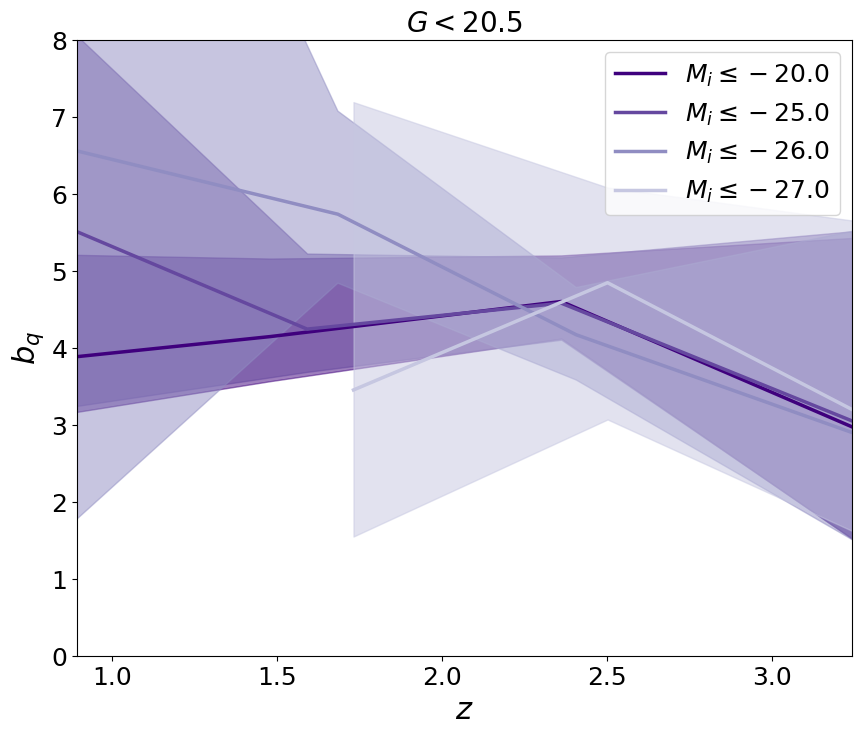

In [219]:
fig = plt.figure(figsize = (10, 8))
labels_cf = ['qq', r'$\xi_{2h}$']
gs = gridspec.GridSpec(1, 1, wspace = 0)
ax1 = fig.add_subplot(gs[0])

for i in range(len(L_bins)):
    zbin = 1/np.array(a_zbin[L_bins[i]])-1
    b_q_percentile = []
    for j in z_array:
        b_q_samples=[]
        for k in range(len(f_duty_samples[L_bins[i]][j])): #ind
            n_m=HOD_scatter(10**f_duty_samples[L_bins[i]][j][k], M_min_samples[L_bins[i]][j][k], bins, Sigma_samples[L_bins[i]][j][k])
            b_q_samples.append(wtheta_2h_optimized(bins, n_m, H0_c_dN_dz_norm[L_bins[i]][j], calc_bias = True)[1])
        b_q_percentile.append(np.percentile(b_q_samples, [16, 50, 84]))
    b_q_lo, b_q_mid, b_q_hi = np.array(b_q_percentile).T

    ax1.plot(zbin, b_q_mid, linewidth = 2.5, color = cmap_purple[::-1][i], label = '$M_i\leq{}$'.format(L_bins[i])) # color = cmaps[i][j], alpha = (l+1)/len(bins))
    ax1.fill_between(zbin, b_q_lo, b_q_hi, alpha = 0.5, color = cmap_purple[::-1][i]) # color = cmaps[i][j], alpha = (l+1)/len(bins))

ax1.set_title('$G<{}$'.format(G_hi))

ax1.set_xlabel('$z$')
ax1.set_ylim(0, 8)
ax1.set_xlim(zmin, zmax)
ax1.set_ylabel(r'$b_q$')

ax1.legend()

plt.show()

<>:18: SyntaxWarning: invalid escape sequence '\l'
<>:18: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_13410/3763727302.py:18: SyntaxWarning: invalid escape sequence '\l'
  ax1.errorbar(zbin, b_q_mid, linewidth = 2.5, color = cmap_theta[i], label = '$M_i\leq{}$'.format(L_bins[i]),
/tmp/ipykernel_13410/2326651642.py:31: RuntimeWarning: divide by zero encountered in scalar divide
  return 1/n_g*integral(integrand*b, bins)
/tmp/ipykernel_13410/2326651642.py:31: RuntimeWarning: invalid value encountered in scalar multiply
  return 1/n_g*integral(integrand*b, bins)


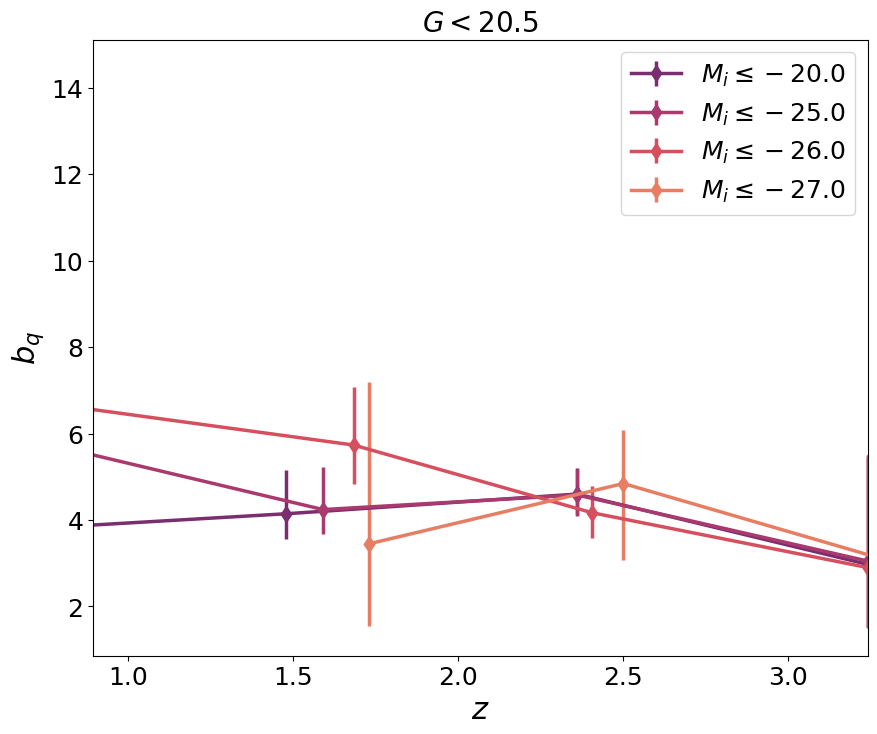

In [220]:
fig = plt.figure(figsize = (10, 8))
labels_cf = ['qq', r'$\xi_{2h}$']
gs = gridspec.GridSpec(1, 1, wspace = 0)
ax1 = fig.add_subplot(gs[0])

for i in range(len(L_bins)):
    zbin = 1/np.array(a_zbin[L_bins[i]])-1
    b_q_percentile = []
    for j in z_array:
        b_q_samples=[]
        for k in range(len(f_duty_samples[L_bins[i]][j])):
            # n_m=np.ones(np.shape(bins))*10**f_duty_samples[L_bins[i]][j][k]
            n_m=HOD_scatter(10**f_duty_samples[L_bins[i]][j][k], M_min_samples[L_bins[i]][j][k], bins, Sigma_samples[L_bins[i]][j][k])
            b_q_samples.append(wtheta_2h_optimized(bins, n_m, H0_c_dN_dz_norm[L_bins[i]][j], calc_bias = True)[1])
        b_q_percentile.append(np.percentile(b_q_samples, [16, 50, 84]))
    b_q_lo, b_q_mid, b_q_hi = np.array(b_q_percentile).T

    ax1.errorbar(zbin, b_q_mid, linewidth = 2.5, color = cmap_theta[i], label = '$M_i\leq{}$'.format(L_bins[i]),
                 yerr = [b_q_mid-b_q_lo, b_q_hi-b_q_mid], markeredgewidth = 2.5, marker = 'd') 

ax1.set_title('$G<{}$'.format(G_hi))

ax1.set_xlabel('$z$')
# ax1.set_ylim(0, 8)
ax1.set_xlim(zmin, zmax)
ax1.set_ylabel(r'$b_q$')

ax1.legend()

plt.show()

<>:15: SyntaxWarning: invalid escape sequence '\l'
<>:15: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_13410/517621506.py:15: SyntaxWarning: invalid escape sequence '\l'
  ax1.plot(L_bins, b_q_mid, linewidth = 2.5, color = cmap_purple[i], label = '${:.1f}<z \leq{:.1f}$'.format(z_bins[i], z_bins[i+1])) # color = cmaps[i][j], alpha = (l+1)/len(bins))
/tmp/ipykernel_13410/2326651642.py:31: RuntimeWarning: divide by zero encountered in scalar divide
  return 1/n_g*integral(integrand*b, bins)
/tmp/ipykernel_13410/2326651642.py:31: RuntimeWarning: invalid value encountered in scalar multiply
  return 1/n_g*integral(integrand*b, bins)


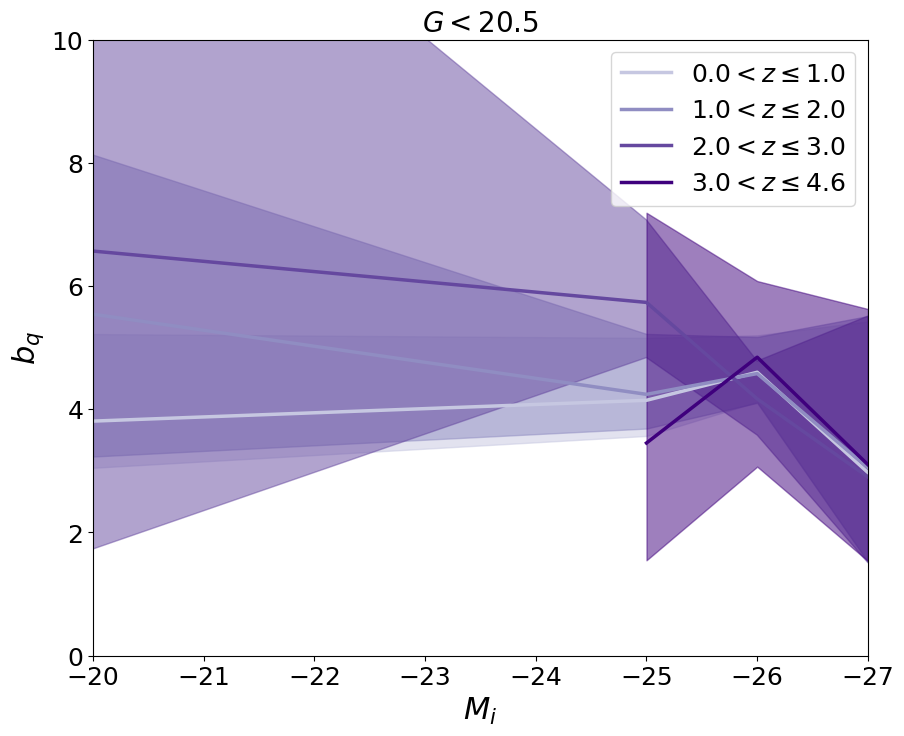

In [221]:
fig = plt.figure(figsize = (10, 8))
labels_cf = ['qq', r'$\xi_{2h}$']
gs = gridspec.GridSpec(1, 1, wspace = 0)
ax1 = fig.add_subplot(gs[0])

for i in z_array:
    b_q_percentile = []
    for j in range(len(L_bins)):
        b_q_samples=[]
        for k in range(len(f_duty_samples[L_bins[i]][j])):
            n_m=HOD_scatter(10**f_duty_samples[L_bins[i]][j][k], M_min_samples[L_bins[i]][j][k], bins, Sigma_samples[L_bins[i]][j][k])
            b_q_samples.append(wtheta_2h_optimized(bins, n_m, H0_c_dN_dz_norm[L_bins[i]][j], calc_bias = True)[1])
        b_q_percentile.append(np.percentile(b_q_samples, [16, 50, 84]))
    b_q_lo, b_q_mid, b_q_hi = np.array(b_q_percentile).T
    ax1.plot(L_bins, b_q_mid, linewidth = 2.5, color = cmap_purple[i], label = '${:.1f}<z \leq{:.1f}$'.format(z_bins[i], z_bins[i+1])) # color = cmaps[i][j], alpha = (l+1)/len(bins))
    ax1.fill_between(L_bins, b_q_lo, b_q_hi, alpha = 0.5, color = cmap_purple[i]) # color = cmaps[i][j], alpha = (l+1)/len(bins))

ax1.set_title('$G<{}$'.format(G_hi))

ax1.set_xlabel('$M_i$')
ax1.set_ylim(0, 10)
ax1.set_xlim(L_bins[0], L_bins[-1])
ax1.set_ylabel(r'$b_q$')

ax1.legend()

plt.show()

<>:17: SyntaxWarning: invalid escape sequence '\l'
<>:17: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_13410/1008119166.py:17: SyntaxWarning: invalid escape sequence '\l'
  ax1.errorbar(L_bins, b_q_mid, linewidth = 2.5, color = cmap_theta[i], label = '${:.1f}<z \leq{:.1f}$'.format(z_bins[i], z_bins[i+1]),
/tmp/ipykernel_13410/2326651642.py:31: RuntimeWarning: divide by zero encountered in scalar divide
  return 1/n_g*integral(integrand*b, bins)
/tmp/ipykernel_13410/2326651642.py:31: RuntimeWarning: invalid value encountered in scalar multiply
  return 1/n_g*integral(integrand*b, bins)


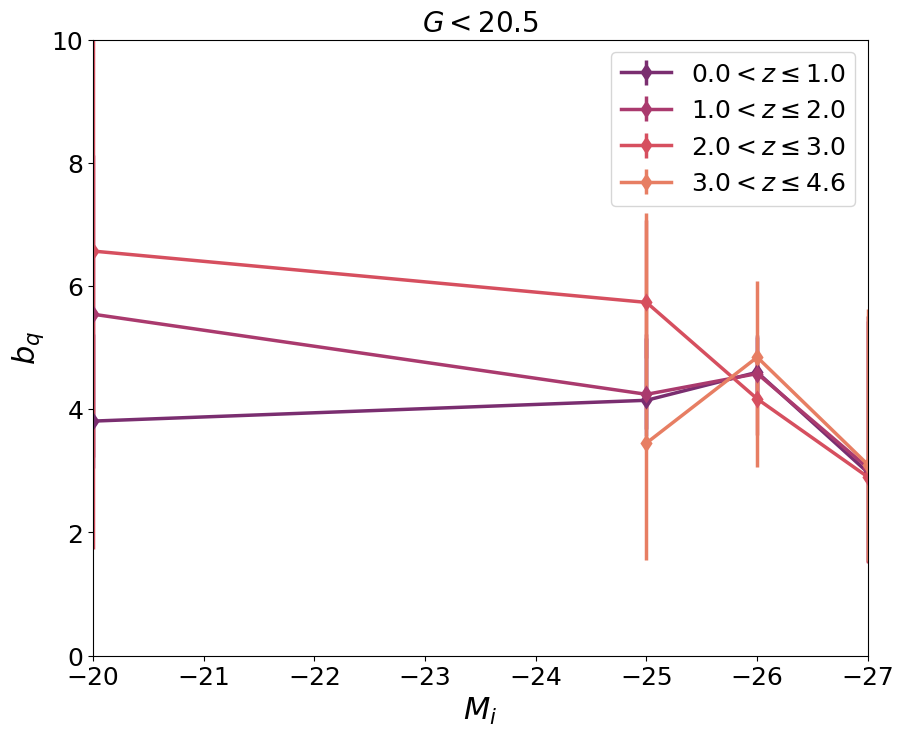

In [222]:
fig = plt.figure(figsize = (10, 8))
labels_cf = ['qq', r'$\xi_{2h}$']
gs = gridspec.GridSpec(1, 1, wspace = 0)
ax1 = fig.add_subplot(gs[0])

for i in z_array:
    b_q_percentile = []
    for j in range(len(L_bins)):
        b_q_samples=[]
        for k in range(len(f_duty_samples[L_bins[i]][j])):
            n_m=HOD_scatter(10**f_duty_samples[L_bins[i]][j][k], M_min_samples[L_bins[i]][j][k], bins, Sigma_samples[L_bins[i]][j][k])
            b_q_samples.append(wtheta_2h_optimized(bins, n_m, H0_c_dN_dz_norm[L_bins[i]][j], calc_bias = True)[1])
        b_q_percentile.append(np.percentile(b_q_samples, [16, 50, 84]))
    b_q_lo, b_q_mid, b_q_hi = np.array(b_q_percentile).T
    # ax1.plot(L_bins, b_q_mid, linewidth = 2.5, color = cmap_purple[i], label = '${:.1f}<z \leq{:.1f}$'.format(z_bins[i], z_bins[i+1])) # color = cmaps[i][j], alpha = (l+1)/len(bins))
    # ax1.fill_between(L_bins, b_q_lo, b_q_hi, alpha = 0.5, color = cmap_purple[i]) # color = cmaps[i][j], alpha = (l+1)/len(bins))
    ax1.errorbar(L_bins, b_q_mid, linewidth = 2.5, color = cmap_theta[i], label = '${:.1f}<z \leq{:.1f}$'.format(z_bins[i], z_bins[i+1]),
                 yerr = [b_q_mid-b_q_lo, b_q_hi-b_q_mid], markeredgewidth = 2.5, marker = 'd') 

ax1.set_title('$G<{}$'.format(G_hi))

ax1.set_xlabel('$M_i$')
ax1.set_ylim(0, 10)
ax1.set_xlim(L_bins[0], L_bins[-1])
ax1.set_ylabel(r'$b_q$')

ax1.legend()

plt.show()

<>:39: SyntaxWarning: invalid escape sequence '\l'
<>:67: SyntaxWarning: invalid escape sequence '\D'
<>:39: SyntaxWarning: invalid escape sequence '\l'
<>:67: SyntaxWarning: invalid escape sequence '\D'
/tmp/ipykernel_13410/1409710967.py:39: SyntaxWarning: invalid escape sequence '\l'
  ax1.set_title('$M_i\leq{}$'.format(L_bins[i]))
/tmp/ipykernel_13410/1409710967.py:67: SyntaxWarning: invalid escape sequence '\D'
  label = '$\Delta \log_{10}(M_{min}/M_\odot)$')
/tmp/ipykernel_13410/2326651642.py:31: RuntimeWarning: divide by zero encountered in scalar divide
  return 1/n_g*integral(integrand*b, bins)
/tmp/ipykernel_13410/2326651642.py:31: RuntimeWarning: invalid value encountered in scalar multiply
  return 1/n_g*integral(integrand*b, bins)
/tmp/ipykernel_13410/2326651642.py:31: RuntimeWarning: divide by zero encountered in scalar divide
  return 1/n_g*integral(integrand*b, bins)
/tmp/ipykernel_13410/2326651642.py:31: RuntimeWarning: invalid value encountered in scalar multiply
  ret

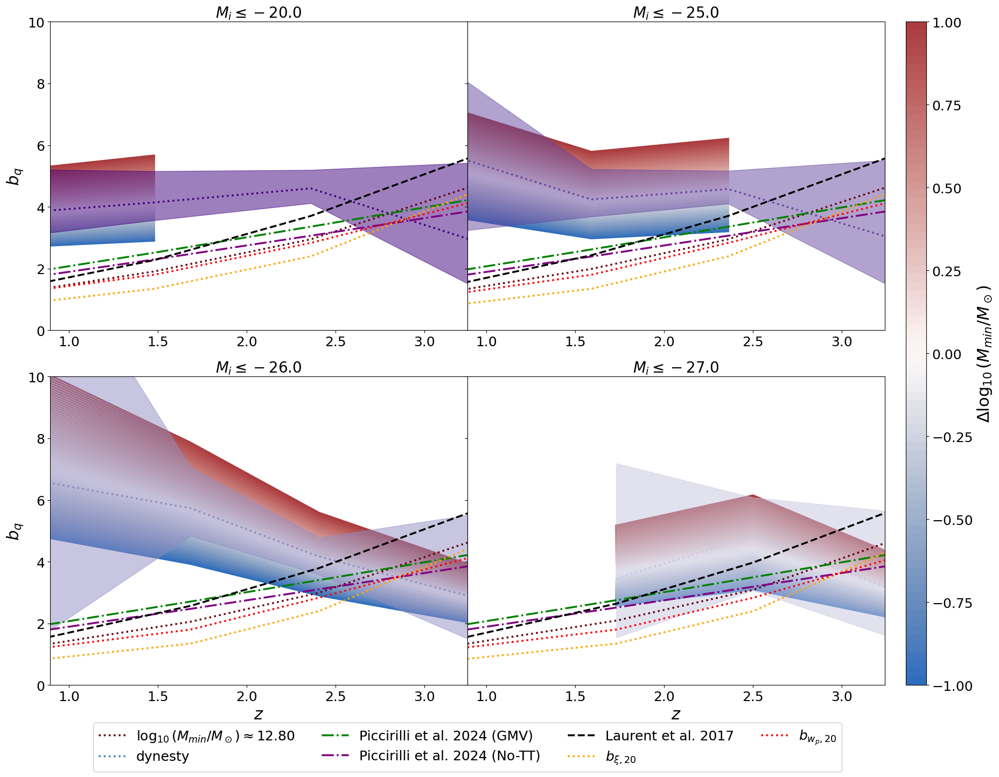

In [223]:
fig = plt.figure(figsize = (21, 16))
gs = gridspec.GridSpec(2, 4, wspace = 0, hspace = 0.15, width_ratios = [1, 1, 0.05, 0.05])

l = 0
for i in range(len(L_bins)):

    ax1 = fig.add_subplot(gs[i+l])

    zbin = 1/np.array(a_zbin[L_bins[i]])-1

    b_q = [wtheta_2h(bins_M_min[j], n_m_array[j], dN_dz_norm[L_bins[i]][j])[1] for j in z_array]
    ax1.plot(zbin, b_q, linewidth = 2.5, color = cmap_red[-1], linestyle = ':') # color = cmaps[i][j], alpha = (l+1)/len(bins))

    b_q_percentile = []
    for j in z_array:
        b_q_samples=[]
        for k in range(len(f_duty_samples[L_bins[i]][j])):
            n_m=HOD_scatter(10**f_duty_samples[L_bins[i]][j][k], M_min_samples[L_bins[i]][j][k], bins, Sigma_samples[L_bins[i]][j][k])            
            b_q_samples.append(wtheta_2h_optimized(bins, n_m, H0_c_dN_dz_norm[L_bins[i]][j], calc_bias = True)[1])
        b_q_percentile.append(np.percentile(b_q_samples, [16, 50, 84]))
    b_q_lo, b_q_mid, b_q_hi = np.array(b_q_percentile).T
    ax1.plot(zbin, b_q_mid, linewidth = 2.5, color = cmap_purple[::-1][i], linestyle = ':') # color = cmaps[i][j], alpha = (l+1)/len(bins))
    ax1.fill_between(zbin, b_q_lo, b_q_hi, alpha = 0.5, color = cmap_purple[::-1][i]) # color = cmaps[i][j], alpha = (l+1)/len(bins))
    
    for k in range(len(bins)):
        b_q = [wtheta_2h_optimized(bins, HOD_scatter(10**f_duty[L_bins[i]][j], M_min[L_bins[i]][j]-1+k/int(len(bins)/2), bins, Sigma[L_bins[i]][j]), H0_c_dN_dz_norm[L_bins[i]][j], calc_bias = True)[1] for j in z_array]
        ax1.plot(zbin, b_q, linewidth = 2.5, color = cmap_M_min[k], zorder = 0) # color = cmaps[i][j], alpha = (l+1)/len(bins))
    
    ax1.plot(zbin, b_quaia(1.26, a_zbin[L_bins[i]]), linestyle = '-.', linewidth = 2.5, 
             label = 'Piccirilli et al. 2024 (GMV)', color = 'green') # eq 3.6 in https://arxiv.org/abs/2402.05761
    ax1.plot(zbin, b_quaia(1.15, a_zbin[L_bins[i]]), linestyle = '-.', linewidth = 2.5, 
             label = 'Piccirilli et al. 2024 (No-TT)', color = 'purple') # eq 3.6 in https://arxiv.org/abs/2402.05761
    ax1.plot(zbin, b_eboss(zbin), linestyle = '--', linewidth = 2.5, label = 'Laurent et al. 2017', 
             color = 'black') # eq 3.6 in https://arxiv.org/abs/2402.05761
    
    ax1.plot(zbin, b_cf20, linestyle = ':', linewidth = 2.5, label = r'$b_{\xi, 20}$', color = 'orange') 
    ax1.plot(zbin, b_wp20, linestyle = ':', linewidth = 2.5, label = '$b_{w_p, 20}$', color = 'red') 

    ax1.set_title('$M_i\leq{}$'.format(L_bins[i]))

    if i > 1:
        ax1.set_xlabel('$z$')
    ax1.set_ylim(0, 10)
    ax1.set_xlim(zmin, zmax)
    if i %2==0:
        ax1.set_ylabel(r'$b_q$')
    else:
        ax1.set_yticklabels([])

    if i == 1:
        l+=2

custom_lines = [Line2D([0], [0], color = cmap_red[-1], linestyle = ':', linewidth = 2.5),
                Line2D([0], [0], color = blue, linestyle = ':', linewidth = 2.5),
                Line2D([0], [0], color = 'green', linestyle = '-.', linewidth = 2.5), 
                Line2D([0], [0], color = 'purple', linestyle = '-.', linewidth = 2.5),
                Line2D([0], [0], color = 'black', linestyle = '--', linewidth = 2.5), 
                Line2D([0], [0], color = 'orange', linestyle = ':', linewidth = 2.5), 
                Line2D([0], [0], color = 'red', linestyle = ':', linewidth = 2.5)]
second_legend = ax1.legend(custom_lines, [r'$\log_{{10}}(M_{{min}}/M_\odot)\approx{:.2f}$'.format(12.8), 
                                          'dynesty', 'Piccirilli et al. 2024 (GMV)', 'Piccirilli et al. 2024 (No-TT)', 
                                          'Laurent et al. 2017', r'$b_{\xi, 20}$', '$b_{w_p, 20}$'], ncol = 4, bbox_to_anchor = (0, -0.1), 
                           loc='upper center')
fig.add_artist(second_legend)

cbar = fig.colorbar(cm.ScalarMappable(cmap=palette_M_min, norm = matplotlib.colors.Normalize(vmin=-1, vmax = 1)), cax = fig.add_subplot(gs[:,-1]), 
                    label = '$\Delta \log_{10}(M_{min}/M_\odot)$')
plt.show()

<>:41: SyntaxWarning: invalid escape sequence '\l'
<>:69: SyntaxWarning: invalid escape sequence '\D'
<>:41: SyntaxWarning: invalid escape sequence '\l'
<>:69: SyntaxWarning: invalid escape sequence '\D'
/tmp/ipykernel_13410/1399973362.py:41: SyntaxWarning: invalid escape sequence '\l'
  ax1.set_title('${:.1f}<z \leq{:.1f}$'.format(z_bins[i], z_bins[i+1]))
/tmp/ipykernel_13410/1399973362.py:69: SyntaxWarning: invalid escape sequence '\D'
  label = '$\Delta \log_{10}(M_{min}/M_\odot)$')
/tmp/ipykernel_13410/2326651642.py:31: RuntimeWarning: divide by zero encountered in scalar divide
  return 1/n_g*integral(integrand*b, bins)
/tmp/ipykernel_13410/2326651642.py:31: RuntimeWarning: invalid value encountered in scalar multiply
  return 1/n_g*integral(integrand*b, bins)
/tmp/ipykernel_13410/2326651642.py:31: RuntimeWarning: divide by zero encountered in scalar divide
  return 1/n_g*integral(integrand*b, bins)
/tmp/ipykernel_13410/2326651642.py:31: RuntimeWarning: invalid value encountered i

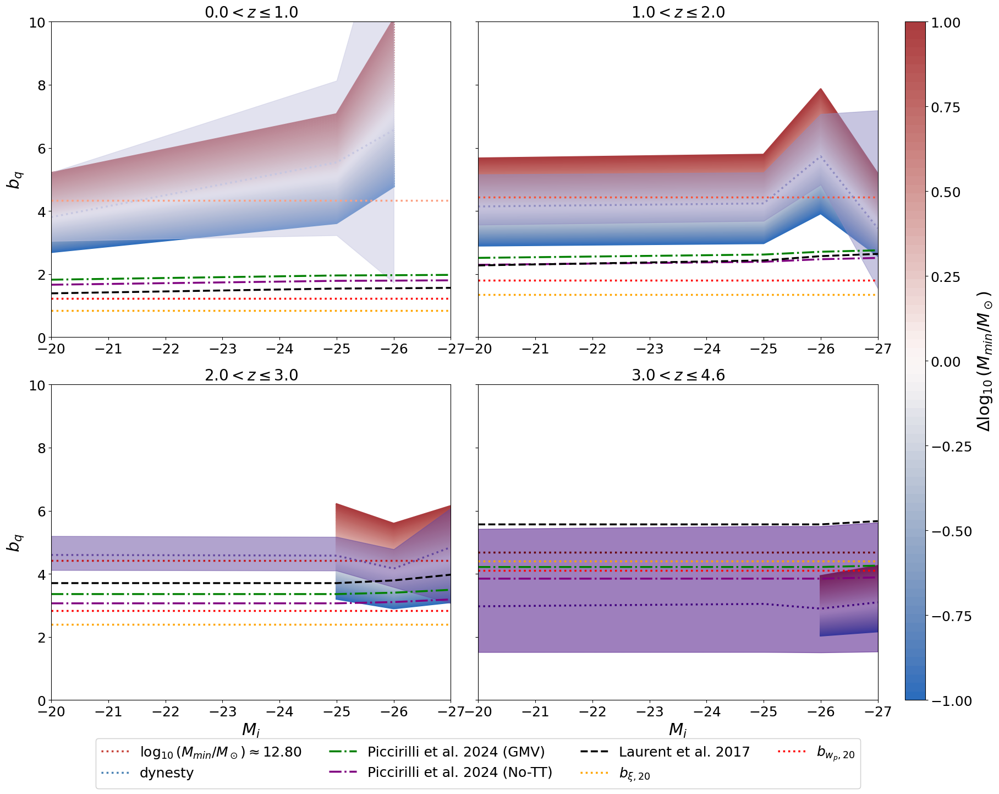

In [224]:
fig = plt.figure(figsize = (20.5, 16))
gs = gridspec.GridSpec(2, 3, wspace = 0.1, hspace = 0.15, width_ratios = [1, 1, 0.05])

l = 0
for i in z_array:

    ax1 = fig.add_subplot(gs[i+l])

    zbin = [1/np.array(a_zbin[L][i])-1 for L in L_bins]

    b_q = [wtheta_2h_optimized(bins_M_min[i], n_m_array[i], H0_c_dN_dz_norm[L][i], calc_bias = True)[1]for L in L_bins]
    ax1.plot(L_bins, b_q, linewidth = 2.5, color = cmap_red[i], linestyle = ':') # color = cmaps[i][j], alpha = (l+1)/len(bins))
    
    b_q_percentile = []
    for j in range(len(L_bins)):
        b_q_samples=[]
        for k in range(len(f_duty_samples[L_bins[j]][i])):
            # n_m=np.ones(np.shape(bins))*10**f_duty_samples[L_bins[j]][i][k]
            n_m=HOD_scatter(10**f_duty_samples[L_bins[j]][i][k], M_min_samples[L_bins[j]][i][k], bins, Sigma_samples[L_bins[j]][i][k])  
            b_q_samples.append(wtheta_2h_optimized(bins, n_m, H0_c_dN_dz_norm[L_bins[j]][i], calc_bias = True)[1])
        b_q_percentile.append(np.percentile(b_q_samples, [16, 50, 84]))
    b_q_lo, b_q_mid, b_q_hi = np.array(b_q_percentile).T
    ax1.plot(L_bins, b_q_mid, linewidth = 2.5, color = cmap_purple[i], linestyle = ':') # color = cmaps[i][j], alpha = (l+1)/len(bins))
    ax1.fill_between(L_bins, b_q_lo, b_q_hi, alpha = 0.5, color = cmap_purple[i]) # color = cmaps[i][j], alpha = (l+1)/len(bins))
    
    for k in range(len(bins)):
        b_q = [wtheta_2h_optimized(bins, HOD_scatter(10**f_duty[L][i], M_min[L][i]-1+k/int(len(bins)/2), bins, Sigma[L][i]), 
                                   H0_c_dN_dz_norm[L][i], calc_bias = True)[1] for L in L_bins]
        ax1.plot(L_bins, b_q, linewidth = 2.5, color = cmap_M_min[k], zorder = 0) # color = cmaps[i][j], alpha = (l+1)/len(bins))
    
    ax1.plot(L_bins, b_quaia(1.26, [a_zbin[L][i] for L in L_bins]), linestyle = '-.', linewidth = 2.5, 
             label = 'Piccirilli et al. 2024 (GMV)', color = 'green') # eq 3.6 in https://arxiv.org/abs/2402.05761
    ax1.plot(L_bins, b_quaia(1.15, [a_zbin[L][i] for L in L_bins]), linestyle = '-.', linewidth = 2.5, 
             label = 'Piccirilli et al. 2024 (No-TT)', color = 'purple') # eq 3.6 in https://arxiv.org/abs/2402.05761
    ax1.plot(L_bins, b_eboss(np.array(zbin)), linestyle = '--', linewidth = 2.5, label = 'Laurent et al. 2017', 
             color = 'black') # eq 3.6 in https://arxiv.org/abs/2402.05761
    
    ax1.axhline(b_cf20[i], linestyle = ':', linewidth = 2.5, label = r'$b_{\xi, 20}$', color = 'orange') 
    ax1.axhline(b_wp20[i], linestyle = ':', linewidth = 2.5, label = '$b_{w_p, 20}$', color = 'red') 

    ax1.set_title('${:.1f}<z \leq{:.1f}$'.format(z_bins[i], z_bins[i+1]))

    if i > 1:
        ax1.set_xlabel('$M_i$')
    ax1.set_ylim(0, 10)
    ax1.set_xlim(L_bins[0], L_bins[-1])
    if i %2==0:
        ax1.set_ylabel(r'$b_q$')
    else:
        ax1.set_yticklabels([])

    if i == 1:
        l+=1

custom_lines = [Line2D([0], [0], color = red, linestyle = ':', linewidth = 2.5),
                Line2D([0], [0], color = blue, linestyle = ':', linewidth = 2.5),
                Line2D([0], [0], color = 'green', linestyle = '-.', linewidth = 2.5), 
                Line2D([0], [0], color = 'purple', linestyle = '-.', linewidth = 2.5),
                Line2D([0], [0], color = 'black', linestyle = '--', linewidth = 2.5), 
                Line2D([0], [0], color = 'orange', linestyle = ':', linewidth = 2.5), 
                Line2D([0], [0], color = 'red', linestyle = ':', linewidth = 2.5)]
second_legend = ax1.legend(custom_lines, [r'$\log_{{10}}(M_{{min}}/M_\odot)\approx{:.2f}$'.format(12.8), 
                                          'dynesty', 'Piccirilli et al. 2024 (GMV)', 'Piccirilli et al. 2024 (No-TT)', 
                                          'Laurent et al. 2017', r'$b_{\xi, 20}$', '$b_{w_p, 20}$'], ncol = 4, bbox_to_anchor = (0, -0.1), 
                           loc='upper center')
fig.add_artist(second_legend)

cbar = fig.colorbar(cm.ScalarMappable(cmap=palette_M_min, norm = matplotlib.colors.Normalize(vmin=-1, vmax = 1)), cax = fig.add_subplot(gs[:,-1]), 
                    label = '$\Delta \log_{10}(M_{min}/M_\odot)$')
plt.show()

/tmp/ipykernel_13410/2326651642.py:31: RuntimeWarning: divide by zero encountered in scalar divide
  return 1/n_g*integral(integrand*b, bins)
/tmp/ipykernel_13410/2326651642.py:31: RuntimeWarning: invalid value encountered in scalar multiply
  return 1/n_g*integral(integrand*b, bins)


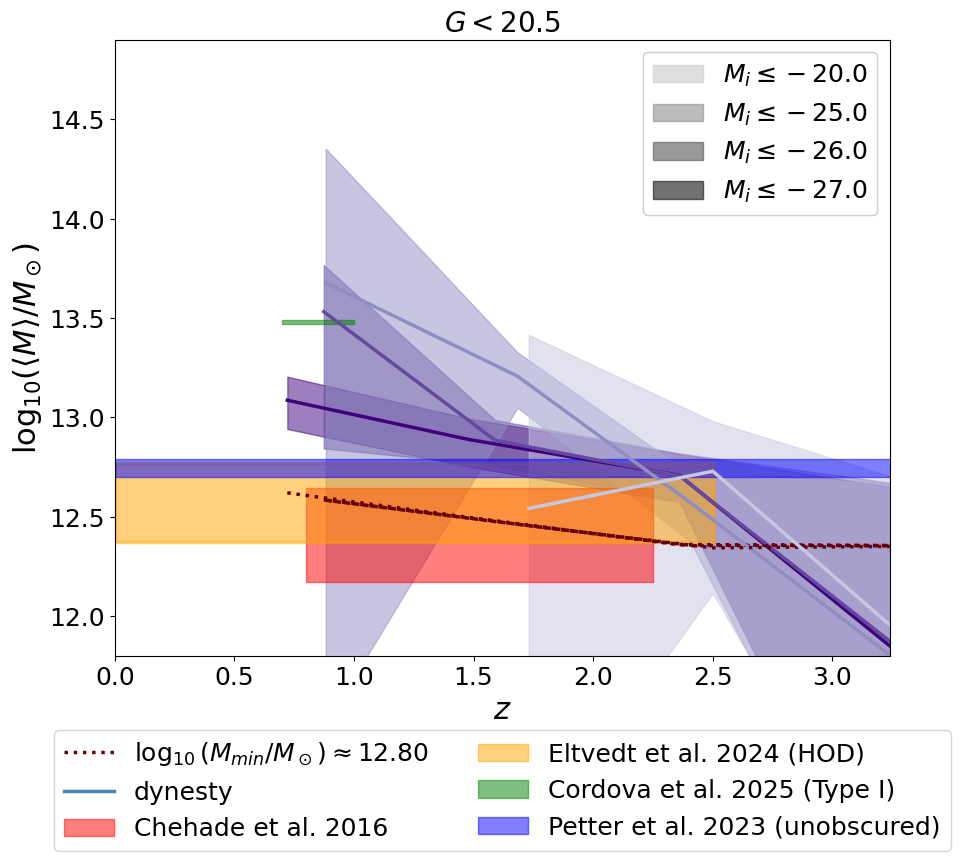

In [225]:
fig = plt.figure(figsize = (10, 8))
labels_cf = ['qq', r'$\xi_{2h}$']
gs = gridspec.GridSpec(1, 1, wspace = 0)
ax1 = fig.add_subplot(gs[0])

for i in range(len(L_bins)):

    zbin = 1/np.array(a_zbin[L_bins[i]])-1

    M_h = [M(bins_M_min[j], n_m_array[j], a = a_zbin[L_bins[i]][j], cosmo = cosmo_planck18, recenter = False)[0] for j in z_array]
    ax1.plot(zbin, np.log10(M_h), linewidth = 2.5, color = cmap_red[-1], linestyle = ':') # color = cmaps[i][j], alpha = (l+1)/len(bins))
    
    M_h_percentile = []
    for j in z_array:
        M_h_samples=[]
        for k in range(len(f_duty_samples[L_bins[i]][j])):
            # n_m=np.ones(np.shape(bins))*10**f_duty_samples[L_bins[i]][j][k]
            n_m=HOD_scatter(10**f_duty_samples[L_bins[i]][j][k], M_min_samples[L_bins[i]][j][k], bins, Sigma_samples[L_bins[i]][j][k]) 
            M_h_samples.append(M(bins, n_m, a = a_zbin[L_bins[i]][j], cosmo = cosmo_planck18, 
             recenter = False)[0])
        M_h_percentile.append(np.percentile(M_h_samples, [16, 50, 84]))
    M_h_lo, M_h_mid, M_h_hi = np.array(M_h_percentile).T
    ax1.plot(zbin, np.log10(M_h_mid), linewidth = 2.5, color = cmap_purple[::-1][i]) # color = cmaps[i][j], alpha = (l+1)/len(bins))
    ax1.fill_between(zbin, np.log10(M_h_lo), np.log10(M_h_hi), alpha = 0.5, color = cmap_purple[::-1][i]) # color = cmaps[i][j], alpha = (l+1)/len(bins))

z = np.linspace(0.8, 2.25)
ax1.fill_between(z, [np.log10(1e12/Planck18.h)]*len(z), [np.log10(3e12/Planck18.h)]*len(z), alpha = 0.5, 
                 label = 'Chehade et al. 2016', color = 'red')
ax1.set_title('$G<{}$'.format(G_hi))
ax1.fill_between(np.linspace(0, 2.5), [np.log10(1.6e12/Planck18.h)]*len(z), [np.log10(4e12/Planck18.h)]*len(z), linewidth = 2.5, 
                 label = 'Eltvedt et al. 2024 (HOD)', alpha = 0.5, color = 'orange')
ax1.fill_between(np.linspace(0.7, 1), [13.47]*len(z), [13.49]*len(z), alpha = 0.5, label = 'Cordova et al. 2025 (Type I)', color = 'green')

# check redshift range and check cordova type i was right to include because conflicts with this
ax1.fill_between(np.linspace(0, 3.5), [np.log10(10**12.53/Planck18.h)]*len(z), [np.log10(10**12.62/Planck18.h)]*len(z), alpha = 0.5, 
                 label = 'Petter et al. 2023 (unobscured)', color = 'blue')

custom_lines = [Line2D([0], [0], color = cmap_red[-1], linestyle = ':', linewidth = 2.5), 
                Line2D([0], [0], color = blue, linestyle = '-', linewidth = 2.5), mpatches.Patch(color='red', alpha = 0.5), 
                mpatches.Patch(color='orange', alpha = 0.5), mpatches.Patch(color='green', alpha = 0.5), mpatches.Patch(color='blue', alpha = 0.5)]
second_legend = ax1.legend(custom_lines, [r'$\log_{{10}}(M_{{min}}/M_\odot)\approx{:.2f}$'.format(12.8), 
                                          'dynesty', 'Chehade et al. 2016', 'Eltvedt et al. 2024 (HOD)', 'Cordova et al. 2025 (Type I)', 'Petter et al. 2023 (unobscured)'], 
                           ncol = 2, bbox_to_anchor = (0.5, -0.1), loc='upper center')
fig.add_artist(second_legend)

ax1.set_xlabel('$z$')
ax1.set_ylabel(r'log$_{10}(\langle M \rangle/M_\odot)$')
ax1.set_xlim(0, zmax)
ax1.set_ylim(11.8, 14.9)

custom_lines = [mpatches.Patch(color=cmap_grey[l], alpha = 0.5) for l in range(len(L_bins))]
first_legend = ax1.legend(custom_lines, [r'$M_i\leq{}$'.format(L_bins[i]) for i in range(len(L_bins))])
fig.add_artist(first_legend)

plt.show()

<>:49: SyntaxWarning: invalid escape sequence '\l'
<>:49: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_13410/2013994177.py:49: SyntaxWarning: invalid escape sequence '\l'
  first_legend = ax1.legend(custom_lines, ['${:.1f}<z \leq{:.1f}$'.format(z_bins[i], z_bins[i+1]) for i in z_array])
/tmp/ipykernel_13410/2326651642.py:31: RuntimeWarning: divide by zero encountered in scalar divide
  return 1/n_g*integral(integrand*b, bins)
/tmp/ipykernel_13410/2326651642.py:31: RuntimeWarning: invalid value encountered in scalar multiply
  return 1/n_g*integral(integrand*b, bins)


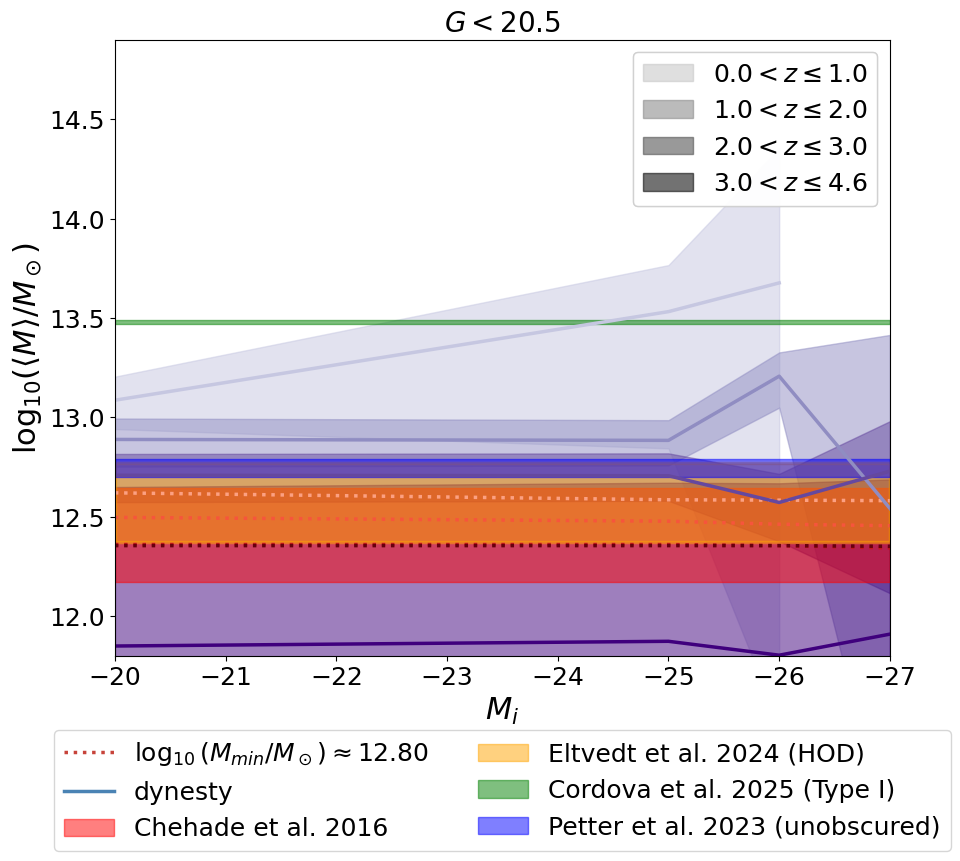

In [226]:
fig = plt.figure(figsize = (10, 8))
labels_cf = ['qq', r'$\xi_{2h}$']
gs = gridspec.GridSpec(1, 1, wspace = 0)
ax1 = fig.add_subplot(gs[0])

for i in z_array:

    M_h = [M(bins_M_min[i], n_m_array[i], a = a_zbin[L][i], cosmo = cosmo_planck18, recenter = False)[0] for L in L_bins]
    ax1.plot(L_bins, np.log10(M_h), linewidth = 2.5, color = cmap_red[i], linestyle = ':') # color = cmaps[i][j], alpha = (l+1)/len(bins))

    M_h_percentile = []
    for j in range(len(L_bins)):
        M_h_samples=[]
        for k in range(len(f_duty_samples[L_bins[j]][i])):
            # n_m=np.ones(np.shape(bins))*10**f_duty_samples[L_bins[j]][i][k]
            n_m=HOD_scatter(10**f_duty_samples[L_bins[j]][i][k], M_min_samples[L_bins[j]][i][k], bins, Sigma_samples[L_bins[j]][i][k]) 
            M_h_samples.append(M(bins, n_m, a = a_zbin[L_bins[j]][i], cosmo = cosmo_planck18, 
             recenter = False)[0])
        M_h_percentile.append(np.percentile(M_h_samples, [16, 50, 84]))
    M_h_lo, M_h_mid, M_h_hi = np.array(M_h_percentile).T
    ax1.plot(L_bins, np.log10(M_h_mid), linewidth = 2.5, color = cmap_purple[i]) # color = cmaps[i][j], alpha = (l+1)/len(bins))
    ax1.fill_between(L_bins, np.log10(M_h_lo), np.log10(M_h_hi), alpha = 0.5, color = cmap_purple[i]) # color = cmaps[i][j], alpha = (l+1)/len(bins))

ax1.fill_between(L_bins, [np.log10(1e12/Planck18.h)]*len(L_bins), [np.log10(3e12/Planck18.h)]*len(L_bins), alpha = 0.5, 
                 label = 'Chehade et al. 2016', color = 'red')
ax1.set_title('$G<{}$'.format(G_hi))
ax1.fill_between(L_bins, [np.log10(1.6e12/Planck18.h)]*len(L_bins), [np.log10(4e12/Planck18.h)]*len(L_bins), linewidth = 2.5, 
                 label = 'Eltvedt et al. 2024 (HOD)', alpha = 0.5, color = 'orange')
ax1.fill_between(L_bins, [13.47]*len(L_bins), [13.49]*len(L_bins), alpha = 0.5, label = 'Cordova et al. 2025 (Type I)', color = 'green')

# check redshift range and check cordova type i was right to include because conflicts with this
ax1.fill_between(L_bins, [np.log10(10**12.53/Planck18.h)]*len(L_bins), [np.log10(10**12.62/Planck18.h)]*len(L_bins), 
                 alpha = 0.5, label = 'Petter et al. 2023 (unobscured)', color = 'blue')

custom_lines = [Line2D([0], [0], color = red, linestyle = ':', linewidth = 2.5), 
                Line2D([0], [0], color = blue, linestyle = '-', linewidth = 2.5), mpatches.Patch(color='red', alpha = 0.5), 
                mpatches.Patch(color='orange', alpha = 0.5), mpatches.Patch(color='green', alpha = 0.5), mpatches.Patch(color='blue', alpha = 0.5)]
second_legend = ax1.legend(custom_lines, [r'$\log_{{10}}(M_{{min}}/M_\odot)\approx{:.2f}$'.format(12.8), 
                                          'dynesty', 'Chehade et al. 2016', 'Eltvedt et al. 2024 (HOD)', 'Cordova et al. 2025 (Type I)', 'Petter et al. 2023 (unobscured)'], 
                           ncol = 2, bbox_to_anchor = (0.5, -0.1), loc='upper center')
fig.add_artist(second_legend)

ax1.set_xlabel('$M_i$')
ax1.set_ylabel(r'log$_{10}(\langle M \rangle/M_\odot)$')
ax1.set_xlim(L_bins[0], L_bins[-1])
ax1.set_ylim(11.8, 14.9)

custom_lines = [mpatches.Patch(color=cmap_grey[l], alpha = 0.5) for l in range(len(L_bins))]
first_legend = ax1.legend(custom_lines, ['${:.1f}<z \leq{:.1f}$'.format(z_bins[i], z_bins[i+1]) for i in z_array])
fig.add_artist(first_legend)

plt.show()

<>:38: SyntaxWarning: invalid escape sequence '\l'
<>:67: SyntaxWarning: invalid escape sequence '\D'
<>:38: SyntaxWarning: invalid escape sequence '\l'
<>:67: SyntaxWarning: invalid escape sequence '\D'
/tmp/ipykernel_13410/1773458514.py:38: SyntaxWarning: invalid escape sequence '\l'
  ax1.set_title('$M_i\leq{}$'.format(L_bins[i]))
/tmp/ipykernel_13410/1773458514.py:67: SyntaxWarning: invalid escape sequence '\D'
  label = '$\Delta \log_{10}(M_{min}/M_\odot)$')
/tmp/ipykernel_13410/2326651642.py:31: RuntimeWarning: divide by zero encountered in scalar divide
  return 1/n_g*integral(integrand*b, bins)
/tmp/ipykernel_13410/2326651642.py:31: RuntimeWarning: invalid value encountered in scalar multiply
  return 1/n_g*integral(integrand*b, bins)
/tmp/ipykernel_13410/2326651642.py:31: RuntimeWarning: divide by zero encountered in scalar divide
  return 1/n_g*integral(integrand*b, bins)
/tmp/ipykernel_13410/2326651642.py:31: RuntimeWarning: invalid value encountered in scalar multiply
  ret

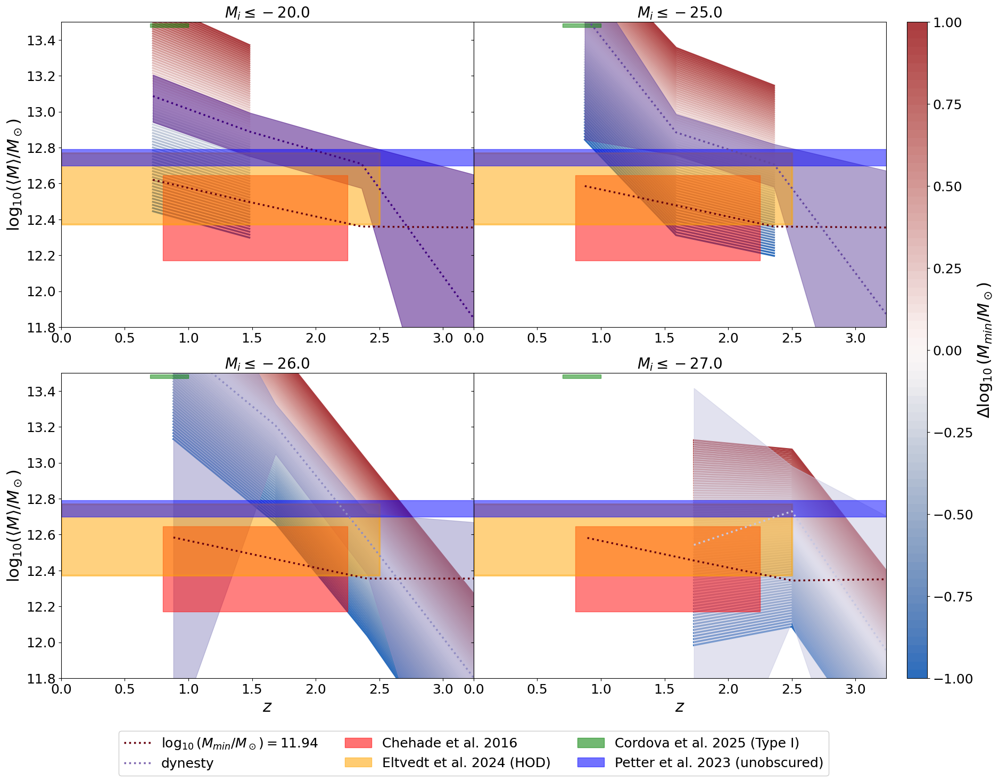

In [227]:
fig = plt.figure(figsize = (21, 16))
gs = gridspec.GridSpec(2, 4, wspace = 0, hspace = 0.15, width_ratios = [1, 1, 0.05, 0.05])

l = 0
for i in range(len(L_bins)):

    ax1 = fig.add_subplot(gs[i+l])

    zbin = 1/np.array(a_zbin[L_bins[i]])-1

    for k in range(len(bins)):

        M_h = [M(bins, HOD_scatter(10**f_duty[L_bins[i]][j], M_min[L_bins[i]][j]-1+k/int(len(bins)/2), bins, Sigma[L_bins[i]][j]) , 
                 a = a_zbin[L_bins[i]][j], cosmo = cosmo_planck18, recenter = False)[0] for j in z_array]
        ax1.plot(zbin, np.log10(M_h), linewidth = 2.5, 
                 label = r'$f_{{duty}}: {:.2f}\%-{:.2f}\%, M_{{min}}:{:.2f} M_\odot$'.format(fduty[0]*100, fduty[-1]*100, np.log10(bins[k])),
                 color = cmap_M_min[k], zorder = 0) #, alpha = (1+k)/len(bins))

    M_h = [M(bins_M_min[j], n_m_array[j], a = a_zbin[L_bins[i]][j], cosmo = cosmo_planck18, recenter = False)[0] for j in z_array]
    ax1.plot(zbin, np.log10(M_h), linewidth = 2.5, color = cmap_red[-1], linestyle = ':') # color = cmaps[i][j], alpha = (l+1)/len(bins))

    M_h_percentile = []
    for j in z_array:
        M_h_samples=[]
        for k in range(len(f_duty_samples[L_bins[i]][j])):
            # n_m=np.ones(np.shape(bins))*10**f_duty_samples[L_bins[i]][j][k]
            n_m=HOD_scatter(10**f_duty_samples[L_bins[i]][j][k], M_min_samples[L_bins[i]][j][k], bins, Sigma_samples[L_bins[i]][j][k]) 
            M_h_samples.append(M(bins, n_m, a = a_zbin[L_bins[i]][j], cosmo = cosmo_planck18, 
             recenter = False)[0])
        M_h_percentile.append(np.percentile(M_h_samples, [16, 50, 84]))
    M_h_lo, M_h_mid, M_h_hi = np.array(M_h_percentile).T
    ax1.plot(zbin, np.log10(M_h_mid), linewidth = 2.5, color = cmap_purple[::-1][i], linestyle = ':') # color = cmaps[i][j], alpha = (l+1)/len(bins))
    ax1.fill_between(zbin, np.log10(M_h_lo), np.log10(M_h_hi), alpha = 0.5, color = cmap_purple[::-1][i]) # color = cmaps[i][j], alpha = (l+1)/len(bins))

    z = np.linspace(0.8, 2.25)
    ax1.fill_between(z, [np.log10(1e12/Planck18.h)]*len(z), [np.log10(3e12/Planck18.h)]*len(z), alpha = 0.5, 
                     label = 'Chehade et al. 2016', color = 'red')
    ax1.set_title('$M_i\leq{}$'.format(L_bins[i]))
    ax1.fill_between(np.linspace(0, 2.5), [np.log10(1.6e12/Planck18.h)]*len(z), [np.log10(4e12/Planck18.h)]*len(z), linewidth = 2.5, 
                     label = 'Eltvedt et al. 2024 (HOD)', alpha = 0.5, color = 'orange')
    ax1.fill_between(np.linspace(0.7, 1), [13.47]*len(z), [13.49]*len(z), alpha = 0.5, label = 'Cordova et al. 2025 (Type I)', color = 'green')

    # check redshift range and check cordova type i was right to include because conflicts with this
    ax1.fill_between(np.linspace(0, 3.5), [np.log10(10**12.53/Planck18.h)]*len(z), [np.log10(10**12.62/Planck18.h)]*len(z), alpha = 0.5, 
                     label = 'Petter et al. 2023 (unobscured)', color = 'blue')

    if i > 1:
        ax1.set_xlabel('$z$')
    if i%2==0:
        ax1.set_ylabel(r'log$_{10}(\langle M \rangle/M_\odot)$')
    else:
        ax1.set_yticklabels([])
    ax1.set_xlim(0, zmax)
    ax1.set_ylim(11.8, 13.5)
    
    if i == 1:
        l+=2
        
custom_lines = [Line2D([0], [0], color = cmap_red[-1], linestyle = ':', linewidth = 2.5), Line2D([0], [0], color = purple, linestyle = ':', linewidth = 2.5), mpatches.Patch(color='red', alpha = 0.5), 
                mpatches.Patch(color='orange', alpha = 0.5), mpatches.Patch(color='green', alpha = 0.5), mpatches.Patch(color='blue', alpha = 0.5)]
second_legend = ax1.legend(custom_lines, [r'$\log_{{10}}(M_{{min}}/M_\odot)={:.2f}$'.format(M_min_array[0]), 'dynesty',
                            'Chehade et al. 2016', 'Eltvedt et al. 2024 (HOD)', 'Cordova et al. 2025 (Type I)', 'Petter et al. 2023 (unobscured)'], 
                           ncol = 3, bbox_to_anchor = (0, -0.15), loc='upper center')
fig.add_artist(second_legend)

cbar = fig.colorbar(cm.ScalarMappable(cmap=palette_M_min, norm = matplotlib.colors.Normalize(vmin=-1, vmax = 1)), cax = fig.add_subplot(gs[:,-1]), 
                        label = '$\Delta \log_{10}(M_{min}/M_\odot)$')
plt.show()

<>:35: SyntaxWarning: invalid escape sequence '\l'
<>:64: SyntaxWarning: invalid escape sequence '\D'
<>:35: SyntaxWarning: invalid escape sequence '\l'
<>:64: SyntaxWarning: invalid escape sequence '\D'
/tmp/ipykernel_13410/712995903.py:35: SyntaxWarning: invalid escape sequence '\l'
  ax1.set_title('${:.1f}<z \leq{:.1f}$'.format(z_bins[i], z_bins[i+1]))
/tmp/ipykernel_13410/712995903.py:64: SyntaxWarning: invalid escape sequence '\D'
  label = '$\Delta \log_{10}(M_{min}/M_\odot)$')
/tmp/ipykernel_13410/2326651642.py:31: RuntimeWarning: divide by zero encountered in scalar divide
  return 1/n_g*integral(integrand*b, bins)
/tmp/ipykernel_13410/2326651642.py:31: RuntimeWarning: invalid value encountered in scalar multiply
  return 1/n_g*integral(integrand*b, bins)
/tmp/ipykernel_13410/2326651642.py:31: RuntimeWarning: divide by zero encountered in scalar divide
  return 1/n_g*integral(integrand*b, bins)
/tmp/ipykernel_13410/2326651642.py:31: RuntimeWarning: invalid value encountered in 

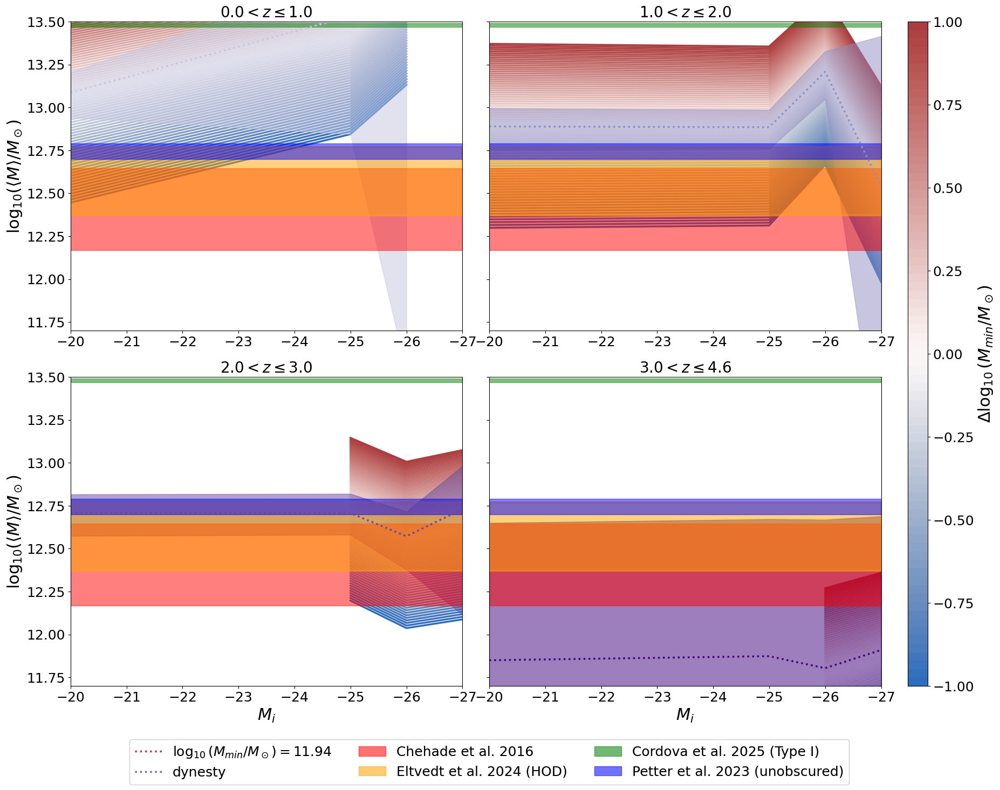

In [228]:
fig = plt.figure(figsize = (20.5, 16))
gs = gridspec.GridSpec(2, 3, wspace = 0.1, hspace = 0.15, width_ratios = [1, 1, 0.05])

l = 0
for i in z_array:

    ax1 = fig.add_subplot(gs[i+l])

    for k in range(len(bins)):

        M_h = [M(bins, HOD_scatter(10**f_duty[L][i], M_min[L][i]-1+k/int(len(bins)/2), bins, Sigma[L][i]), 
                 a = a_zbin[L][i], cosmo = cosmo_planck18, recenter = False)[0] for L in L_bins]
        ax1.plot(L_bins, np.log10(M_h), linewidth = 2.5, 
                 label = r'$f_{{duty}}: {:.2f}\%-{:.2f}\%, M_{{min}}:{:.2f} M_\odot$'.format(fduty[0]*100, fduty[-1]*100, np.log10(bins[k])),
                 color = cmap_M_min[k], zorder = 0) #, alpha = (1+k)/len(bins))

    M_h = [M(bins_M_min[i], n_m_array[i], a = a_zbin[L][i], cosmo = cosmo_planck18, recenter = False)[0] for L in L_bins]
    ax1.plot(zbin, np.log10(M_h), linewidth = 2.5, color = cmap_red[i], linestyle = ':') # color = cmaps[i][j], alpha = (l+1)/len(bins))

    M_h_percentile = []
    for j in range(len(L_bins)):
        M_h_samples=[]
        for k in range(len(f_duty_samples[L_bins[j]][i])):
            # n_m=np.ones(np.shape(bins))*10**f_duty_samples[L_bins[j]][i][k]
            n_m=HOD_scatter(10**f_duty_samples[L_bins[j]][i][k], M_min_samples[L_bins[j]][i][k], bins, Sigma_samples[L_bins[j]][i][k]) 
            M_h_samples.append(M(bins, n_m, a = a_zbin[L_bins[j]][i], cosmo = cosmo_planck18, 
             recenter = False)[0])
        M_h_percentile.append(np.percentile(M_h_samples, [16, 50, 84]))
    M_h_lo, M_h_mid, M_h_hi = np.array(M_h_percentile).T
    ax1.plot(L_bins, np.log10(M_h_mid), linewidth = 2.5, color = cmap_purple[i], linestyle = ':') # color = cmaps[i][j], alpha = (l+1)/len(bins))
    ax1.fill_between(L_bins, np.log10(M_h_lo), np.log10(M_h_hi), alpha = 0.5, color = cmap_purple[i]) # color = cmaps[i][j], alpha = (l+1)/len(bins))

    ax1.fill_between(L_bins, [np.log10(1e12/Planck18.h)]*len(L_bins), [np.log10(3e12/Planck18.h)]*len(L_bins), alpha = 0.5, 
                     label = 'Chehade et al. 2016', color = 'red')
    ax1.set_title('${:.1f}<z \leq{:.1f}$'.format(z_bins[i], z_bins[i+1]))
    ax1.fill_between(L_bins, [np.log10(1.6e12/Planck18.h)]*len(L_bins), [np.log10(4e12/Planck18.h)]*len(L_bins), linewidth = 2.5, 
                     label = 'Eltvedt et al. 2024 (HOD)', alpha = 0.5, color = 'orange')
    ax1.fill_between(L_bins, [13.47]*len(L_bins), [13.49]*len(L_bins), alpha = 0.5, label = 'Cordova et al. 2025 (Type I)', color = 'green')

    # check redshift range and check cordova type i was right to include because conflicts with this
    ax1.fill_between(L_bins, [np.log10(10**12.53/Planck18.h)]*len(L_bins), [np.log10(10**12.62/Planck18.h)]*len(L_bins), alpha = 0.5, 
                     label = 'Petter et al. 2023 (unobscured)', color = 'blue')

    if i > 1:
        ax1.set_xlabel('$M_i$')
    if i%2==0:
        ax1.set_ylabel(r'log$_{10}(\langle M \rangle/M_\odot)$')
    else:
        ax1.set_yticklabels([])
    ax1.set_xlim(L_bins[0], L_bins[-1])
    ax1.set_ylim(11.7, 13.5)
    
    if i == 1:
        l+=1
        
custom_lines = [Line2D([0], [0], color = red, linestyle = ':', linewidth = 2.5), Line2D([0], [0], color = purple, linestyle = ':', linewidth = 2.5), mpatches.Patch(color='red', alpha = 0.5), 
                mpatches.Patch(color='orange', alpha = 0.5), mpatches.Patch(color='green', alpha = 0.5), mpatches.Patch(color='blue', alpha = 0.5)]
second_legend = ax1.legend(custom_lines, [r'$\log_{{10}}(M_{{min}}/M_\odot)={:.2f}$'.format(M_min_array[0]), 'dynesty',
                            'Chehade et al. 2016', 'Eltvedt et al. 2024 (HOD)', 'Cordova et al. 2025 (Type I)', 'Petter et al. 2023 (unobscured)'], 
                           ncol = 3, bbox_to_anchor = (0, -0.15), loc='upper center')
fig.add_artist(second_legend)

cbar = fig.colorbar(cm.ScalarMappable(cmap=palette_M_min, norm = matplotlib.colors.Normalize(vmin=-1, vmax = 1)), cax = fig.add_subplot(gs[:,-1]), 
                        label = '$\Delta \log_{10}(M_{min}/M_\odot)$')
plt.show()

In [229]:
fduty_array = np.logspace(-5,0, 51) #-4

In [230]:
cmap_fduty_k = sns.color_palette("vlag", n_colors = len(fduty_array))

<>:39: SyntaxWarning: invalid escape sequence '\l'
<>:57: SyntaxWarning: invalid escape sequence '\D'
<>:39: SyntaxWarning: invalid escape sequence '\l'
<>:57: SyntaxWarning: invalid escape sequence '\D'
/tmp/ipykernel_13410/3193519221.py:39: SyntaxWarning: invalid escape sequence '\l'
  ax1.set_title('$M_i\leq{}$'.format(L_bins[i]))
/tmp/ipykernel_13410/3193519221.py:57: SyntaxWarning: invalid escape sequence '\D'
  label = '$\Delta \log_{10}(M_{min}/M_\odot)$')
/tmp/ipykernel_13410/2326651642.py:31: RuntimeWarning: divide by zero encountered in scalar divide
  return 1/n_g*integral(integrand*b, bins)
/tmp/ipykernel_13410/2326651642.py:31: RuntimeWarning: invalid value encountered in scalar multiply
  return 1/n_g*integral(integrand*b, bins)
/tmp/ipykernel_13410/3193519221.py:16: RuntimeWarning: divide by zero encountered in log10
  ax1.plot(zbin, np.log10(n_q_theory), linewidth = 2.5, color = cmap_M_min[k])
/tmp/ipykernel_13410/2326651642.py:31: RuntimeWarning: divide by zero encount

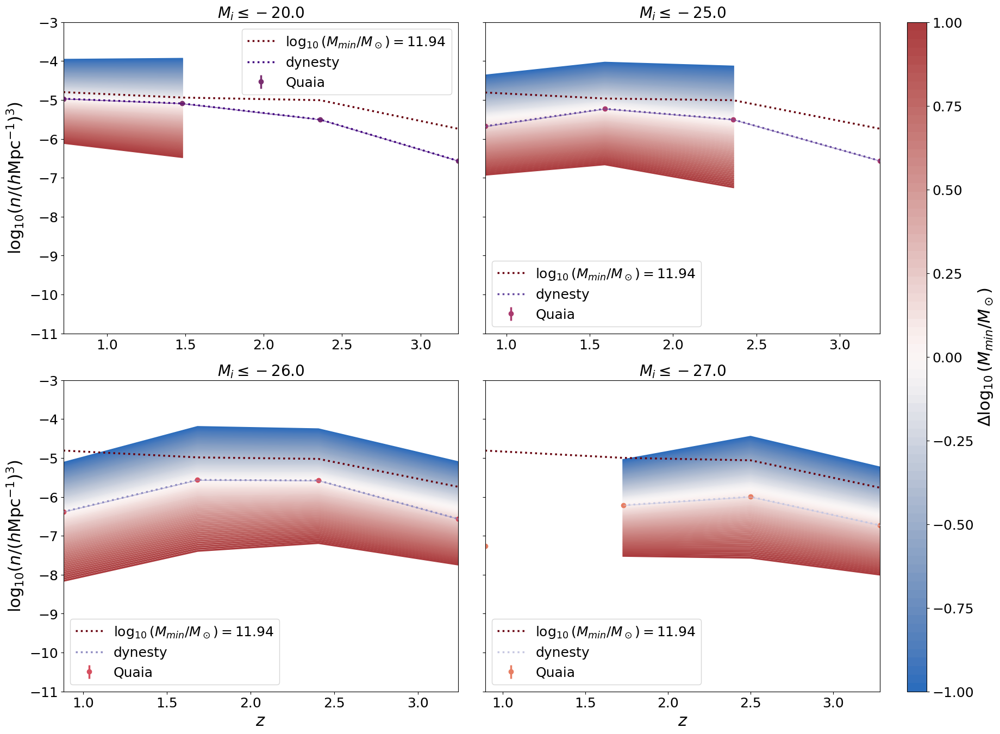

In [231]:
fig = plt.figure(figsize = (20.5, 16))
labels_cf = ['qq', r'$\xi_{2h}$']
gs = gridspec.GridSpec(2, 3, width_ratios = [1, 1, 0.05], wspace = 0.1, hspace = 0.15)
ylim = -11, -3#-7.1, -4.75

l = 0
for i in range(len(L_bins)):

    zbin = 1/np.array(a_zbin[L_bins[i]])-1

    ax1 = fig.add_subplot(gs[i+l])
    
    for k in range(len(bins)):

        n_q_theory = [M(bins, HOD_scatter(10**f_duty[L_bins[i]][j], M_min[L_bins[i]][j]-1+k/int(len(bins)/2), bins, Sigma[L_bins[i]][j]), a = a_zbin[L_bins[i]][j], cosmo = cosmo_planck18, recenter = False)[1] for j in z_array]
        ax1.plot(zbin, np.log10(n_q_theory), linewidth = 2.5, color = cmap_M_min[k])
        
    n_q_theory, n_q_theory_fit = [], [] #, n_q_theory_fit_lo, n_q_theory_fit_hi = [], [], [], []
    n_q_percentile = []
    for j in z_array:
        
        n_q_theory.append(M(bins_M_min[j], n_m_array[j], a = a_zbin[L_bins[i]][j], cosmo = cosmo_planck18, recenter = False)[1])
        
        n_q_samples=[]
        for k in range(len(f_duty_samples[L_bins[i]][j])):
            # n_m=np.ones(np.shape(bins))*10**f_duty_samples[L_bins[i]][j][k]
            n_m = HOD_scatter(10**f_duty_samples[L_bins[i]][j][k], M_min_samples[L_bins[i]][j][k], bins, Sigma_samples[L_bins[i]][j][k])
            n_q_samples.append(M(bins, n_m, a = a_zbin[L_bins[i]][j], cosmo = cosmo_planck18, 
             recenter = False)[1])
        n_q_percentile.append(np.percentile(n_q_samples, [16, 50, 84]))
    n_q_theory_fit_lo, n_q_theory_fit_mid, n_q_theory_fit_hi = np.array(n_q_percentile).T
    ax1.plot(zbin, np.log10(n_q_theory), linewidth = 2.5, color = cmap_red[-1], linestyle = ':', 
             label = r'$\log_{{10}}(M_{{min}}/M_\odot)={:.2f}$'.format(M_min_array[0])) # color = cmaps[i][j], alpha = (l+1)/len(bins))
    ax1.plot(zbin, np.log10(n_q_theory_fit_mid), linewidth = 2.5, color = cmap_purple[::-1][i], linestyle = ':', label = r'dynesty') # color = cmaps[i][j], alpha = (l+1)/len(bins))
    ax1.fill_between(zbin, np.log10(n_q_theory_fit_lo), np.log10(n_q_theory_fit_hi), color = cmap_purple[::-1][i], alpha = 0.5, zorder = 3) # color = cmaps[i][j], alpha = (l+1)/len(bins))
    ax1.errorbar(zbin, np.log10(n_q[L_bins[i]]), linewidth = 2.5, marker = 'o', label = 'Quaia', color = cmap_rocket[i],
                 yerr = [np.log10(n_q[L_bins[i]])-np.log10(np.subtract(n_q[L_bins[i]], n_q_err[L_bins[i]])), np.log10(np.add(n_q[L_bins[i]], n_q_err[L_bins[i]]))-np.log10(n_q[L_bins[i]])], linestyle = 'None')
    
    ax1.set_title('$M_i\leq{}$'.format(L_bins[i]))
    ax1.set_xlim(zbin[0], zbin[-1]) #zmin, zmax
    
    if i%2==0:
        ax1.set_ylabel(r'log$_{10}(n/(h\mathrm{Mpc}^{-1})^3)$')
    else:
        ax1.set_yticklabels([])
    ax1.set_ylim(ylim)

    if i > 1:
        ax1.set_xlabel('$z$')

    if i==1:
        l+=1

    ax1.legend()

cbar = fig.colorbar(cm.ScalarMappable(cmap=palette_M_min, norm = matplotlib.colors.Normalize(vmin=-1, vmax = 1)), cax = fig.add_subplot(gs[:,-1]), 
                        label = '$\Delta \log_{10}(M_{min}/M_\odot)$')
plt.show()

<>:36: SyntaxWarning: invalid escape sequence '\l'
<>:53: SyntaxWarning: invalid escape sequence '\D'
<>:36: SyntaxWarning: invalid escape sequence '\l'
<>:53: SyntaxWarning: invalid escape sequence '\D'
/tmp/ipykernel_13410/2758472384.py:36: SyntaxWarning: invalid escape sequence '\l'
  ax1.set_title('${:.1f}<z \leq{:.1f}$'.format(z_bins[i], z_bins[i+1]))
/tmp/ipykernel_13410/2758472384.py:53: SyntaxWarning: invalid escape sequence '\D'
  label = '$\Delta \log_{10}(M_{min}/M_\odot)$')
/tmp/ipykernel_13410/2326651642.py:31: RuntimeWarning: divide by zero encountered in scalar divide
  return 1/n_g*integral(integrand*b, bins)
/tmp/ipykernel_13410/2326651642.py:31: RuntimeWarning: invalid value encountered in scalar multiply
  return 1/n_g*integral(integrand*b, bins)
/tmp/ipykernel_13410/2758472384.py:14: RuntimeWarning: divide by zero encountered in log10
  ax1.plot(L_bins, np.log10(n_q_theory), linewidth = 2.5, color = cmap_M_min[k])
/tmp/ipykernel_13410/2758472384.py:31: RuntimeWarnin

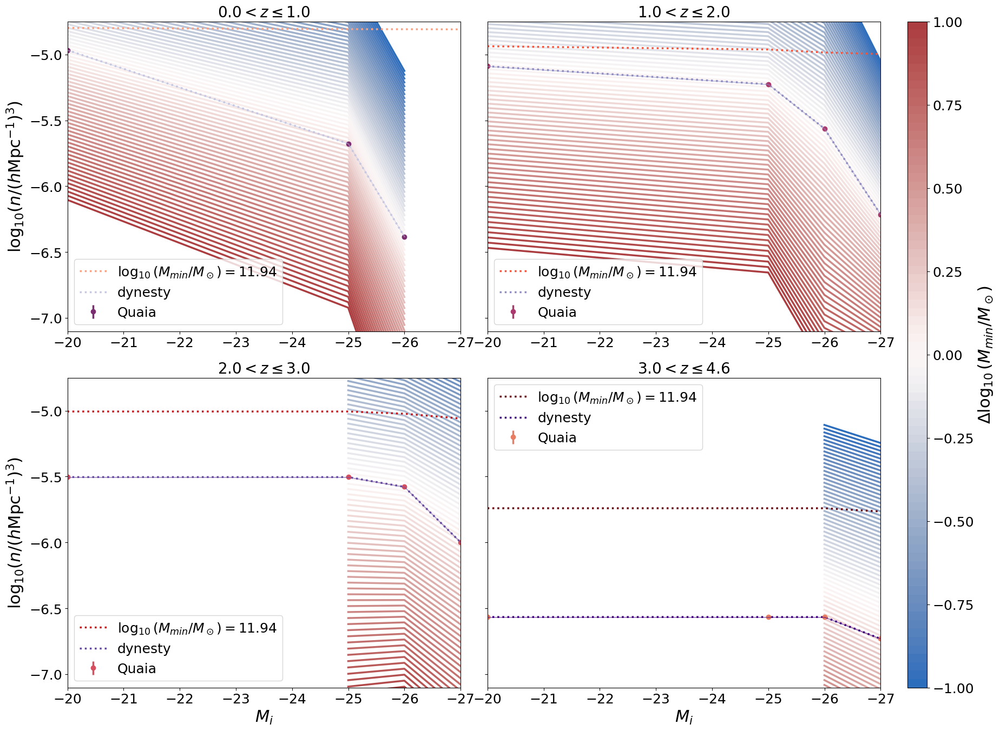

In [232]:
fig = plt.figure(figsize = (20.5, 16))
labels_cf = ['qq', r'$\xi_{2h}$']
gs = gridspec.GridSpec(2, 3, width_ratios = [1, 1, 0.05], wspace = 0.1, hspace = 0.15)
ylim = -7.1, -4.75

l = 0
for i in z_array:
    
    ax1 = fig.add_subplot(gs[i+l])
    
    for k in range(len(bins)):

        n_q_theory = [M(bins, HOD_scatter(10**f_duty[L][i], M_min[L][i]-1+k/int(len(bins)/2), bins, Sigma[L][i]), a = a_zbin[L][i], cosmo = cosmo_planck18, recenter = False)[1] for L in L_bins]
        ax1.plot(L_bins, np.log10(n_q_theory), linewidth = 2.5, color = cmap_M_min[k])
        
    n_q_theory, n_q_theory_fit = [], [] #, n_q_theory_fit_lo, n_q_theory_fit_hi = [], [], [], []
    n_q_percentile = []
    for j in range(len(L_bins)):
        
        n_q_theory.append(M(bins_M_min[i], n_m_array[i], a = a_zbin[L_bins[j]][i], cosmo = cosmo_planck18, recenter = False)[1])
        
        n_q_samples=[]
        for k in range(len(f_duty_samples[L_bins[j]][i])):
            # n_m=np.ones(np.shape(bins))*10**f_duty_samples[L_bins[j]][i][k]
            n_m = HOD_scatter(10**f_duty_samples[L_bins[j]][i][k], M_min_samples[L_bins[j]][i][k], bins, Sigma_samples[L_bins[j]][i][k])
            n_q_samples.append(M(bins, n_m, a = a_zbin[L_bins[j]][i], cosmo = cosmo_planck18, 
             recenter = False)[1])
        n_q_percentile.append(np.percentile(n_q_samples, [16, 50, 84]))
    n_q_theory_fit_lo, n_q_theory_fit_mid, n_q_theory_fit_hi = np.array(n_q_percentile).T
    ax1.plot(L_bins, np.log10(n_q_theory), linewidth = 2.5, color = cmap_red[i], linestyle = ':', label = r'$\log_{{10}}(M_{{min}}/M_\odot)={:.2f}$'.format(M_min_array[0])) # color = cmaps[i][j], alpha = (l+1)/len(bins))
    ax1.plot(L_bins, np.log10(n_q_theory_fit_mid), linewidth = 2.5, color = cmap_purple[i], linestyle = ':', label = r'dynesty') # color = cmaps[i][j], alpha = (l+1)/len(bins))
    ax1.fill_between(L_bins, np.log10(n_q_theory_fit_lo), np.log10(n_q_theory_fit_hi), color = cmap_purple[i], alpha = 0.5, zorder = 3) # color = cmaps[i][j], alpha = (l+1)/len(bins))
    ax1.errorbar(L_bins, [np.log10(n_q[L][i]) for L in L_bins], linewidth = 2.5, marker = 'o', label = 'Quaia', color = cmap_rocket[i],
                 yerr = [[np.log10(n_q[L][i])-np.log10(np.subtract(n_q[L][i], n_q_err[L][i])) for L in L_bins], [np.log10(np.add(n_q[L][i], n_q_err[L][i]))-np.log10(n_q[L][i]) for L in L_bins]], linestyle = 'None')
    
    ax1.set_title('${:.1f}<z \leq{:.1f}$'.format(z_bins[i], z_bins[i+1]))
    ax1.set_xlim(L_bins[0], L_bins[-1])
    
    if i%2==0:
        ax1.set_ylabel(r'log$_{10}(n/(h\mathrm{Mpc}^{-1})^3)$')
    else:
        ax1.set_yticklabels([])
    ax1.set_ylim(ylim)
    if i > 1:
        ax1.set_xlabel('$M_i$')

    if i==1:
        l+=1
        
    ax1.legend()

cbar = fig.colorbar(cm.ScalarMappable(cmap=palette_M_min, norm = matplotlib.colors.Normalize(vmin=-1, vmax = 1)), cax = fig.add_subplot(gs[:,-1]), 
                        label = '$\Delta \log_{10}(M_{min}/M_\odot)$')
plt.show()